INSTALLING REQUIRED LIBRARIES
✅ Libraries installed

DEVICE CONFIGURATION
Device: cpu
CPU cores: 2
Image size: 256
Batch size: 2
Epochs: 10

UPLOAD ARCADE DATASET ZIP


Saving archive (1).zip to archive (1).zip
✅ Uploaded: archive (1).zip

Extracting dataset...
✅ Dataset extracted

SEARCHING FOR ARCADE SYNTAX DATASET
JSON files found: 6
/content/arcade_dataset/data/syntax/val/annotations/val.json
/content/arcade_dataset/data/syntax/train/annotations/train.json
/content/arcade_dataset/data/syntax/test/annotations/test.json
/content/arcade_dataset/data/stenosis/val/annotations/val.json
/content/arcade_dataset/data/stenosis/train/annotations/train.json
/content/arcade_dataset/data/stenosis/test/annotations/test.json

✅ Training annotation:
/content/arcade_dataset/data/syntax/train/annotations/train.json

Validation annotation:
/content/arcade_dataset/data/syntax/val/annotations/val.json

Test annotation:
/content/arcade_dataset/data/syntax/test/annotations/test.json

Total image files found: 3000

CREATING DATASETS
Dataset loaded: 1000 images | 4976 annotations
Dataset loaded: 200 images | 1168 annotations

Train samples: 1000
Validation samples: 200
✅ D

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

Total parameters: 24,436,369
Trainable parameters: 24,436,369
✅ Pretrained model loaded

STARTING CPU FINE-TUNING
IMPORTANT: CPU training can take significant time.

Epoch [1/10] | Time: 18.98 min
Train Loss: 0.4507 | Dice: 0.4933 | IoU: 0.3696
Val Loss: 0.2633 | Dice: 0.7021 | IoU: 0.5507
Learning Rate: 0.0001000
⭐ BEST MODEL SAVED

Epoch [2/10] | Time: 19.00 min
Train Loss: 0.2773 | Dice: 0.6221 | IoU: 0.5051
Val Loss: 0.1952 | Dice: 0.7338 | IoU: 0.5880
Learning Rate: 0.0001000
⭐ BEST MODEL SAVED

Epoch [3/10] | Time: 18.93 min
Train Loss: 0.2395 | Dice: 0.6503 | IoU: 0.5417
Val Loss: 0.1780 | Dice: 0.7502 | IoU: 0.6140
Learning Rate: 0.0001000
⭐ BEST MODEL SAVED

Epoch [4/10] | Time: 18.84 min
Train Loss: 0.2266 | Dice: 0.6668 | IoU: 0.5637
Val Loss: 0.1609 | Dice: 0.7658 | IoU: 0.6322
Learning Rate: 0.0001000
⭐ BEST MODEL SAVED

Epoch [5/10] | Time: 18.99 min
Train Loss: 0.2170 | Dice: 0.6806 | IoU: 0.5826
Val Loss: 0.1809 | Dice: 0.7316 | IoU: 0.5920
Learning Rate: 0.0001000

Epo

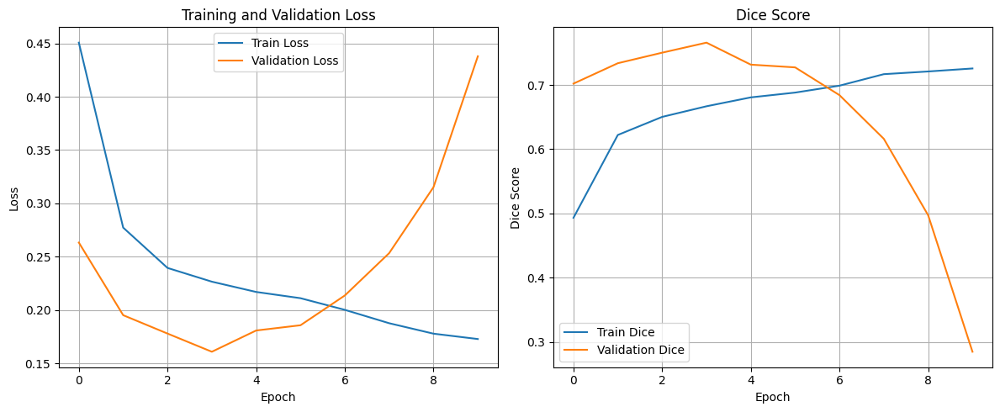


Generating sample predictions...


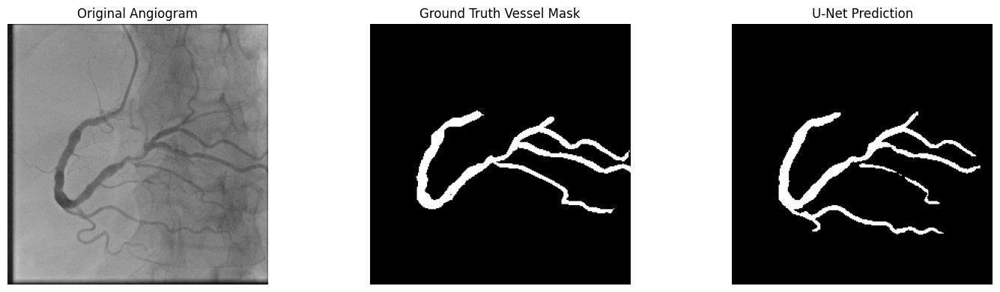

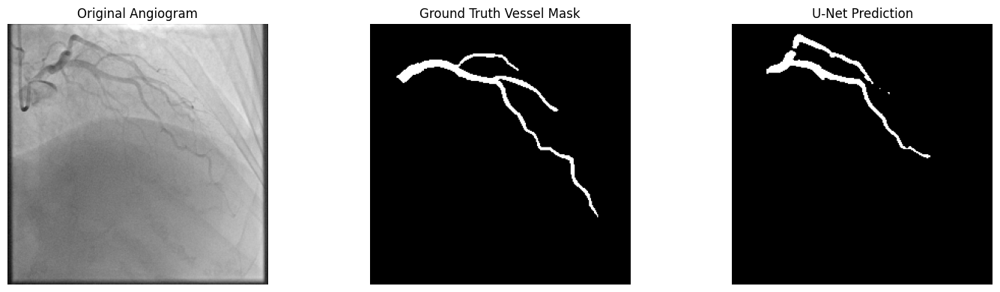

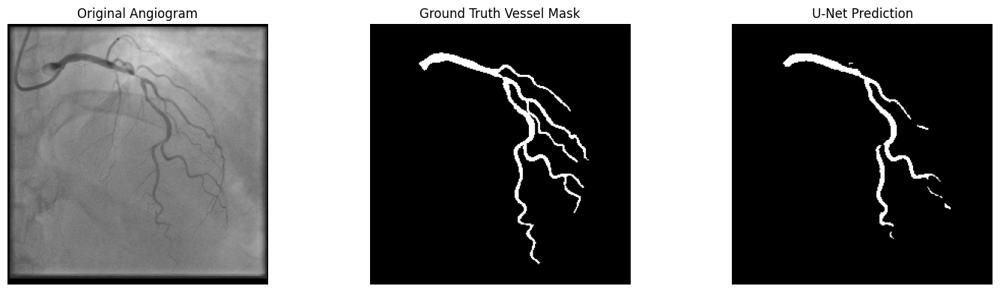


FINAL MODEL SUMMARY
Model       : U-Net
Encoder     : ResNet34
Encoder     : ImageNet pretrained
Dataset     : ARCADE
Task        : Coronary vessel segmentation
Input size  : 256
Device      : cpu
Best Dice   : 0.7658
Model file  : /content/best_unet_resnet34_arcade.pth



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✅ MODEL DOWNLOADED
Keep this .pth file safely.


In [ ]:
# ============================================================
# AI-BASED CORONARY ARTERY DISEASE DIAGNOSIS
# PRETRAINED U-NET + RESNET34 FINE-TUNING
# ARCADE DATASET | CPU VERSION
# ============================================================

# -----------------------------
# 1. INSTALL LIBRARIES
# -----------------------------
import subprocess
import sys
import os
import json
import zipfile
import shutil
import glob
import random
import time

print("=" * 70)
print("INSTALLING REQUIRED LIBRARIES")
print("=" * 70)

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q",
    "segmentation-models-pytorch",
    "albumentations",
    "pycocotools"
])

print("✅ Libraries installed")


# -----------------------------
# 2. IMPORTS
# -----------------------------
import numpy as np
import cv2
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import segmentation_models_pytorch as smp

from pycocotools import mask as maskUtils


# -----------------------------
# 3. CPU CONFIGURATION
# -----------------------------
DEVICE = torch.device("cpu")

# Keep CPU training practical
torch.set_num_threads(max(1, os.cpu_count() // 2))

IMG_SIZE = 256
BATCH_SIZE = 2
EPOCHS = 10
LEARNING_RATE = 1e-4

print("\n" + "=" * 70)
print("DEVICE CONFIGURATION")
print("=" * 70)

print("Device:", DEVICE)
print("CPU cores:", os.cpu_count())
print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)


# -----------------------------
# 4. UPLOAD ARCADE ZIP
# -----------------------------
from google.colab import files

print("\n" + "=" * 70)
print("UPLOAD ARCADE DATASET ZIP")
print("=" * 70)

uploaded = files.upload()

if len(uploaded) == 0:
    raise RuntimeError("❌ No file uploaded.")

uploaded_filename = list(uploaded.keys())[0]

print("✅ Uploaded:", uploaded_filename)


# -----------------------------
# 5. EXTRACT DATASET
# -----------------------------
DATASET_ROOT = "/content/arcade_dataset"

if os.path.exists(DATASET_ROOT):
    shutil.rmtree(DATASET_ROOT)

os.makedirs(DATASET_ROOT, exist_ok=True)

zip_path = "/content/" + uploaded_filename

print("\nExtracting dataset...")

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(DATASET_ROOT)

print("✅ Dataset extracted")


# -----------------------------
# 6. FIND SYNTAX DATASET
# -----------------------------
print("\n" + "=" * 70)
print("SEARCHING FOR ARCADE SYNTAX DATASET")
print("=" * 70)

json_files = glob.glob(
    DATASET_ROOT + "/**/*.json",
    recursive=True
)

print("JSON files found:", len(json_files))

for f in json_files[:20]:
    print(f)


def find_json(keyword):
    matches = [
        f for f in json_files
        if keyword.lower() in os.path.basename(f).lower()
    ]
    return matches


# Try to identify train / val / test annotation files
train_candidates = []
val_candidates = []
test_candidates = []

for f in json_files:
    name = os.path.basename(f).lower()

    if "train" in name and "syntax" in name:
        train_candidates.append(f)

    if ("val" in name or "valid" in name) and "syntax" in name:
        val_candidates.append(f)

    if "test" in name and "syntax" in name:
        test_candidates.append(f)


# More general fallback
if not train_candidates:
    train_candidates = [
        f for f in json_files
        if "train" in os.path.basename(f).lower()
    ]

if not val_candidates:
    val_candidates = [
        f for f in json_files
        if ("val" in os.path.basename(f).lower()
        or "valid" in os.path.basename(f).lower())
    ]

if not test_candidates:
    test_candidates = [
        f for f in json_files
        if "test" in os.path.basename(f).lower()
    ]


def choose_coco_json(candidates):

    for f in candidates:

        try:
            with open(f, "r") as file:
                data = json.load(file)

            if (
                isinstance(data, dict)
                and "images" in data
                and "annotations" in data
                and "categories" in data
            ):
                return f

        except:
            pass

    return None


TRAIN_JSON = choose_coco_json(train_candidates)
VAL_JSON = choose_coco_json(val_candidates)
TEST_JSON = choose_coco_json(test_candidates)


if TRAIN_JSON is None:

    # Search all JSON files for COCO train annotation
    for f in json_files:

        try:
            with open(f, "r") as file:
                data = json.load(file)

            if (
                isinstance(data, dict)
                and "images" in data
                and "annotations" in data
                and "categories" in data
                and len(data["images"]) >= 500
            ):
                TRAIN_JSON = f
                break

        except:
            continue


if TRAIN_JSON is None:
    raise RuntimeError(
        "❌ Could not automatically find ARCADE COCO training JSON."
    )


print("\n✅ Training annotation:")
print(TRAIN_JSON)

print("\nValidation annotation:")
print(VAL_JSON)

print("\nTest annotation:")
print(TEST_JSON)


# -----------------------------
# 7. FIND IMAGE DIRECTORY
# -----------------------------
all_images = []

for ext in ["*.png", "*.jpg", "*.jpeg", "*.bmp", "*.tif", "*.tiff"]:

    all_images.extend(
        glob.glob(
            DATASET_ROOT + "/**/" + ext,
            recursive=True
        )
    )

print("\nTotal image files found:", len(all_images))


# -----------------------------
# 8. COCO DATASET CLASS
# -----------------------------
class ARCADEDataset(Dataset):

    def __init__(
        self,
        annotation_file,
        image_root,
        img_size=256
    ):

        with open(annotation_file, "r") as f:
            self.coco = json.load(f)

        self.image_root = image_root
        self.img_size = img_size

        self.images = self.coco["images"]

        self.annotations = self.coco["annotations"]

        # Map image_id -> annotations
        self.ann_map = {}

        for ann in self.annotations:

            image_id = ann["image_id"]

            if image_id not in self.ann_map:
                self.ann_map[image_id] = []

            self.ann_map[image_id].append(ann)

        # Find image paths
        self.image_paths = {}

        for img in self.images:

            file_name = img["file_name"]

            basename = os.path.basename(file_name)

            possible = glob.glob(
                image_root + "/**/" + basename,
                recursive=True
            )

            if possible:

                self.image_paths[img["id"]] = possible[0]

        # Keep only images that actually exist
        self.images = [
            img for img in self.images
            if img["id"] in self.image_paths
        ]

        print(
            f"Dataset loaded: {len(self.images)} images | "
            f"{len(self.annotations)} annotations"
        )


    def __len__(self):
        return len(self.images)


    def __getitem__(self, index):

        img_info = self.images[index]

        image_id = img_info["id"]

        image_path = self.image_paths[image_id]

        # Read image
        image = cv2.imread(image_path)

        if image is None:
            raise RuntimeError(
                f"Could not read image: {image_path}"
            )

        image = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )

        original_h, original_w = image.shape[:2]

        # Create binary vessel mask
        mask = np.zeros(
            (original_h, original_w),
            dtype=np.uint8
        )

        anns = self.ann_map.get(
            image_id,
            []
        )

        for ann in anns:

            segmentation = ann.get(
                "segmentation",
                None
            )

            if segmentation is None:
                continue

            try:

                # Polygon segmentation
                if isinstance(
                    segmentation,
                    list
                ):

                    for polygon in segmentation:

                        if len(polygon) < 6:
                            continue

                        pts = np.array(
                            polygon,
                            dtype=np.float32
                        ).reshape(-1, 2)

                        pts[:, 0] = np.clip(
                            pts[:, 0],
                            0,
                            original_w - 1
                        )

                        pts[:, 1] = np.clip(
                            pts[:, 1],
                            0,
                            original_h - 1
                        )

                        pts = pts.astype(
                            np.int32
                        )

                        cv2.fillPoly(
                            mask,
                            [pts],
                            1
                        )

                # RLE segmentation
                elif isinstance(
                    segmentation,
                    dict
                ):

                    rle = segmentation

                    if isinstance(
                        rle.get("counts"),
                        list
                    ):
                        rle = maskUtils.frPyObjects(
                            rle,
                            original_h,
                            original_w
                        )

                    decoded = maskUtils.decode(rle)

                    if decoded.ndim == 3:
                        decoded = np.any(
                            decoded,
                            axis=2
                        )

                    mask[
                        decoded > 0
                    ] = 1

            except Exception:
                continue


        # Resize
        image = cv2.resize(
            image,
            (self.img_size, self.img_size),
            interpolation=cv2.INTER_AREA
        )

        mask = cv2.resize(
            mask,
            (self.img_size, self.img_size),
            interpolation=cv2.INTER_NEAREST
        )

        # Normalize image
        image = image.astype(
            np.float32
        ) / 255.0

        # ImageNet normalization
        mean = np.array(
            [0.485, 0.456, 0.406],
            dtype=np.float32
        )

        std = np.array(
            [0.229, 0.224, 0.225],
            dtype=np.float32
        )

        image = (
            image - mean
        ) / std

        # HWC -> CHW
        image = np.transpose(
            image,
            (2, 0, 1)
        )

        image = torch.tensor(
            image,
            dtype=torch.float32
        )

        mask = torch.tensor(
            mask,
            dtype=torch.float32
        ).unsqueeze(0)

        return image, mask


# -----------------------------
# 9. CREATE DATASETS
# -----------------------------
print("\n" + "=" * 70)
print("CREATING DATASETS")
print("=" * 70)

train_dataset = ARCADEDataset(
    TRAIN_JSON,
    DATASET_ROOT,
    IMG_SIZE
)

if VAL_JSON is not None:

    val_dataset = ARCADEDataset(
        VAL_JSON,
        DATASET_ROOT,
        IMG_SIZE
    )

else:

    # Use 10% of training data for validation
    from torch.utils.data import random_split

    val_size = max(
        1,
        int(0.1 * len(train_dataset))
    )

    train_size = (
        len(train_dataset)
        - val_size
    )

    train_dataset, val_dataset = random_split(
        train_dataset,
        [train_size, val_size]
    )


print("\nTrain samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))


# -----------------------------
# 10. DATALOADERS
# -----------------------------
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("✅ DataLoaders created")


# -----------------------------
# 11. VERIFY DATA
# -----------------------------
images, masks = next(iter(train_loader))

print("\n" + "=" * 70)
print("DATA VERIFICATION")
print("=" * 70)

print("Images:", images.shape)
print("Masks :", masks.shape)
print("Image dtype:", images.dtype)
print("Mask dtype :", masks.dtype)

print(
    "Mask positive percentage:",
    masks.mean().item() * 100,
    "%"
)


# -----------------------------
# 12. LOAD PRETRAINED U-NET
# -----------------------------
print("\n" + "=" * 70)
print("LOADING PRETRAINED U-NET + RESNET34")
print("=" * 70)

model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1,
    activation=None
)

model = model.to(DEVICE)

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Total parameters:",
      f"{total_params:,}")

print("Trainable parameters:",
      f"{trainable_params:,}")

print("✅ Pretrained model loaded")


# -----------------------------
# 13. LOSS FUNCTIONS
# -----------------------------
bce_loss = nn.BCEWithLogitsLoss()


def dice_loss(
    logits,
    targets,
    smooth=1.0
):

    probs = torch.sigmoid(
        logits
    )

    probs = probs.contiguous().view(
        -1
    )

    targets = targets.contiguous().view(
        -1
    )

    intersection = (
        probs * targets
    ).sum()

    dice = (
        2.0 * intersection
        + smooth
    ) / (
        probs.sum()
        + targets.sum()
        + smooth
    )

    return 1 - dice


def combined_loss(
    logits,
    targets
):

    return (
        0.5 * bce_loss(
            logits,
            targets
        )
        +
        0.5 * dice_loss(
            logits,
            targets
        )
    )


# -----------------------------
# 14. METRICS
# -----------------------------
def calculate_metrics(
    logits,
    targets,
    threshold=0.5,
    smooth=1e-6
):

    probs = torch.sigmoid(
        logits
    )

    preds = (
        probs > threshold
    ).float()

    preds = preds.view(
        preds.size(0),
        -1
    )

    targets = targets.view(
        targets.size(0),
        -1
    )

    intersection = (
        preds * targets
    ).sum(dim=1)

    pred_sum = preds.sum(
        dim=1
    )

    target_sum = targets.sum(
        dim=1
    )

    dice = (
        2 * intersection
        + smooth
    ) / (
        pred_sum
        + target_sum
        + smooth
    )

    union = (
        pred_sum
        + target_sum
        - intersection
    )

    iou = (
        intersection
        + smooth
    ) / (
        union
        + smooth
    )

    return (
        dice.mean().item(),
        iou.mean().item()
    )


# -----------------------------
# 15. OPTIMIZER
# -----------------------------
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-5
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)


# -----------------------------
# 16. CHECKPOINT SETUP
# -----------------------------
CHECKPOINT_DIR = "/content/checkpoints"

os.makedirs(
    CHECKPOINT_DIR,
    exist_ok=True
)

BEST_MODEL = (
    "/content/best_unet_resnet34_arcade.pth"
)


# -----------------------------
# 17. TRAINING FUNCTIONS
# -----------------------------
def train_one_epoch():

    model.train()

    running_loss = 0.0
    running_dice = 0.0
    running_iou = 0.0

    count = 0

    for batch_images, batch_masks in train_loader:

        batch_images = batch_images.to(
            DEVICE
        )

        batch_masks = batch_masks.to(
            DEVICE
        )

        optimizer.zero_grad()

        outputs = model(
            batch_images
        )

        loss = combined_loss(
            outputs,
            batch_masks
        )

        loss.backward()

        optimizer.step()

        dice, iou = calculate_metrics(
            outputs.detach(),
            batch_masks
        )

        batch_size = (
            batch_images.size(0)
        )

        running_loss += (
            loss.item()
            * batch_size
        )

        running_dice += (
            dice
            * batch_size
        )

        running_iou += (
            iou
            * batch_size
        )

        count += batch_size

    return (
        running_loss / count,
        running_dice / count,
        running_iou / count
    )


@torch.no_grad()
def validate():

    model.eval()

    running_loss = 0.0
    running_dice = 0.0
    running_iou = 0.0

    count = 0

    for batch_images, batch_masks in val_loader:

        batch_images = batch_images.to(
            DEVICE
        )

        batch_masks = batch_masks.to(
            DEVICE
        )

        outputs = model(
            batch_images
        )

        loss = combined_loss(
            outputs,
            batch_masks
        )

        dice, iou = calculate_metrics(
            outputs,
            batch_masks
        )

        batch_size = (
            batch_images.size(0)
        )

        running_loss += (
            loss.item()
            * batch_size
        )

        running_dice += (
            dice
            * batch_size
        )

        running_iou += (
            iou
            * batch_size
        )

        count += batch_size

    return (
        running_loss / count,
        running_dice / count,
        running_iou / count
    )


# -----------------------------
# 18. TRAINING
# -----------------------------
print("\n" + "=" * 70)
print("STARTING CPU FINE-TUNING")
print("=" * 70)

print(
    "IMPORTANT: CPU training can take significant time."
)

best_val_dice = -1

history = {
    "train_loss": [],
    "train_dice": [],
    "train_iou": [],
    "val_loss": [],
    "val_dice": [],
    "val_iou": []
}


for epoch in range(
    1,
    EPOCHS + 1
):

    start_time = time.time()

    train_loss, train_dice, train_iou = (
        train_one_epoch()
    )

    val_loss, val_dice, val_iou = (
        validate()
    )

    scheduler.step(
        val_dice
    )

    current_lr = optimizer.param_groups[0]["lr"]

    history["train_loss"].append(
        train_loss
    )

    history["train_dice"].append(
        train_dice
    )

    history["train_iou"].append(
        train_iou
    )

    history["val_loss"].append(
        val_loss
    )

    history["val_dice"].append(
        val_dice
    )

    history["val_iou"].append(
        val_iou
    )

    epoch_time = (
        time.time()
        - start_time
    )

    print(
        f"\nEpoch [{epoch}/{EPOCHS}] "
        f"| Time: {epoch_time/60:.2f} min"
    )

    print(
        f"Train Loss: {train_loss:.4f} "
        f"| Dice: {train_dice:.4f} "
        f"| IoU: {train_iou:.4f}"
    )

    print(
        f"Val Loss: {val_loss:.4f} "
        f"| Dice: {val_dice:.4f} "
        f"| IoU: {val_iou:.4f}"
    )

    print(
        f"Learning Rate: {current_lr:.7f}"
    )

    # Save checkpoint EVERY epoch
    checkpoint_path = (
        CHECKPOINT_DIR
        + f"/epoch_{epoch}.pth"
    )

    torch.save(
        {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_dice": val_dice,
            "val_iou": val_iou,
            "history": history
        },
        checkpoint_path
    )

    # Save best model
    if val_dice > best_val_dice:

        best_val_dice = val_dice

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "val_dice": val_dice,
                "val_iou": val_iou,
                "history": history
            },
            BEST_MODEL
        )

        print(
            "⭐ BEST MODEL SAVED"
        )


# -----------------------------
# 19. TRAINING COMPLETE
# -----------------------------
print("\n" + "=" * 70)
print("TRAINING COMPLETE")
print("=" * 70)

print(
    f"Best Validation Dice: "
    f"{best_val_dice:.4f}"
)

print(
    "Best model:",
    BEST_MODEL
)


# -----------------------------
# 20. LOAD BEST MODEL
# -----------------------------
checkpoint = torch.load(
    BEST_MODEL,
    map_location=DEVICE
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print(
    "\n✅ Best model loaded"
)


# -----------------------------
# 21. TRAINING CURVES
# -----------------------------
plt.figure(
    figsize=(12, 5)
)

plt.subplot(1, 2, 1)

plt.plot(
    history["train_loss"],
    label="Train Loss"
)

plt.plot(
    history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)


plt.subplot(1, 2, 2)

plt.plot(
    history["train_dice"],
    label="Train Dice"
)

plt.plot(
    history["val_dice"],
    label="Validation Dice"
)

plt.xlabel("Epoch")
plt.ylabel("Dice Score")
plt.title("Dice Score")
plt.legend()
plt.grid(True)

plt.tight_layout()

plt.show()


# -----------------------------
# 22. VISUALIZE PREDICTIONS
# -----------------------------
@torch.no_grad()
def visualize_predictions(
    dataset,
    number=3
):

    model.eval()

    number = min(
        number,
        len(dataset)
    )

    indices = random.sample(
        range(len(dataset)),
        number
    )

    for idx in indices:

        image_tensor, mask_tensor = (
            dataset[idx]
        )

        input_tensor = (
            image_tensor
            .unsqueeze(0)
            .to(DEVICE)
        )

        output = model(
            input_tensor
        )

        prediction = (
            torch.sigmoid(
                output
            )[0, 0]
            .cpu()
            .numpy()
        )

        prediction = (
            prediction > 0.5
        ).astype(np.uint8)

        # Recover display image
        display_image = (
            image_tensor
            .numpy()
            .transpose(1, 2, 0)
        )

        mean = np.array(
            [0.485, 0.456, 0.406]
        )

        std = np.array(
            [0.229, 0.224, 0.225]
        )

        display_image = (
            display_image * std
            + mean
        )

        display_image = np.clip(
            display_image,
            0,
            1
        )

        ground_truth = (
            mask_tensor[0]
            .numpy()
        )

        plt.figure(
            figsize=(15, 4)
        )

        plt.subplot(1, 3, 1)

        plt.imshow(
            display_image
        )

        plt.title(
            "Original Angiogram"
        )

        plt.axis("off")


        plt.subplot(1, 3, 2)

        plt.imshow(
            ground_truth,
            cmap="gray"
        )

        plt.title(
            "Ground Truth Vessel Mask"
        )

        plt.axis("off")


        plt.subplot(1, 3, 3)

        plt.imshow(
            prediction,
            cmap="gray"
        )

        plt.title(
            "U-Net Prediction"
        )

        plt.axis("off")

        plt.tight_layout()

        plt.show()


print("\nGenerating sample predictions...")

visualize_predictions(
    val_dataset,
    number=3
)


# -----------------------------
# 23. FINAL SUMMARY
# -----------------------------
print("\n" + "=" * 70)
print("FINAL MODEL SUMMARY")
print("=" * 70)

print("Model       : U-Net")
print("Encoder     : ResNet34")
print("Encoder     : ImageNet pretrained")
print("Dataset     : ARCADE")
print("Task        : Coronary vessel segmentation")
print("Input size  :", IMG_SIZE)
print("Device      :", DEVICE)
print("Best Dice   :", round(best_val_dice, 4))
print("Model file  :", BEST_MODEL)
print("=" * 70)


# -----------------------------
# 24. DOWNLOAD BEST MODEL
# -----------------------------
print("\nDownloading best trained model...")

files.download(
    BEST_MODEL
)

print("\n✅ MODEL DOWNLOADED")
print("Keep this .pth file safely.")

In [ ]:
import pickle
import torch
from google.colab import files
import segmentation_models_pytorch as smp

# ------------------------------------------------
# MODEL 1: U-NET + RESNET34
# ------------------------------------------------

PTH_PATH = "/content/best_unet_resnet34_arcade.pth"
PKL_PATH = "/content/unet_resnet34_arcade_model.pkl"

# Load trained checkpoint
checkpoint = torch.load(
    PTH_PATH,
    map_location="cpu"
)

# Create the same model architecture
model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=3,
    classes=1,
    activation=None
)

# Load trained weights
model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

# Package model information
model_package = {
    "model_name": "U-Net + ResNet34",
    "dataset": "ARCADE",
    "task": "Coronary Vessel Segmentation",
    "image_size": 256,
    "input_channels": 3,
    "output_channels": 1,
    "best_epoch": checkpoint["epoch"],
    "best_val_dice": checkpoint["val_dice"],
    "best_val_iou": checkpoint["val_iou"],
    "model_state_dict": model.state_dict()
}

# Save as pickle
with open(
    PKL_PATH,
    "wb"
) as f:

    pickle.dump(
        model_package,
        f,
        protocol=pickle.HIGHEST_PROTOCOL
    )

print("✅ MODEL 1 CONVERTED TO PICKLE")
print()
print("Model       : U-Net + ResNet34")
print("Best Epoch  :", checkpoint["epoch"])
print("Best Dice   :", checkpoint["val_dice"])
print("Best IoU    :", checkpoint["val_iou"])
print()
print("Pickle file:")
print(PKL_PATH)

# Download
files.download(PKL_PATH)

print("\n✅ Download complete")

✅ MODEL 1 CONVERTED TO PICKLE

Model       : U-Net + ResNet34
Best Epoch  : 4
Best Dice   : 0.7657862341403961
Best IoU    : 0.6322024682164192

Pickle file:
/content/unet_resnet34_arcade_model.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✅ Download complete


INSTALLING REQUIRED PACKAGES
✅ Required packages installed

MODEL 2 — ATTENTION U-NET + RESNET34
Device        : cpu
CPU threads   : 2
Image size    : 256
Batch size    : 2
Epochs        : 10
Learning rate : 0.0001

SEARCHING FOR ARCADE DATASET

✅ ARCADE DATASET FOUND

Training JSON:
/content/data/syntax/train/annotations/train.json

Validation JSON:
/content/data/syntax/val/annotations/val.json

CREATING DATASETS
Dataset loaded: 1000 images | 4976 annotations
Dataset loaded: 200 images | 1168 annotations

Train samples: 1000
Validation samples: 200

✅ DataLoaders ready

CREATING ATTENTION U-NET + RESNET34

Loading pretrained ResNet34...

Total parameters: 26,384,781
Trainable parameters: 26,384,781

TESTING FORWARD PASS

Input shape: (2, 3, 256, 256)
Target shape: (2, 1, 256, 256)
Output shape: (2, 1, 256, 256)

✅ FORWARD PASS SUCCESSFUL
✅ CHANNEL DIMENSIONS ARE CORRECT

STARTING MODEL 2 TRAINING

----------------------------------------------------------------------
Epoch [1/10]
Time

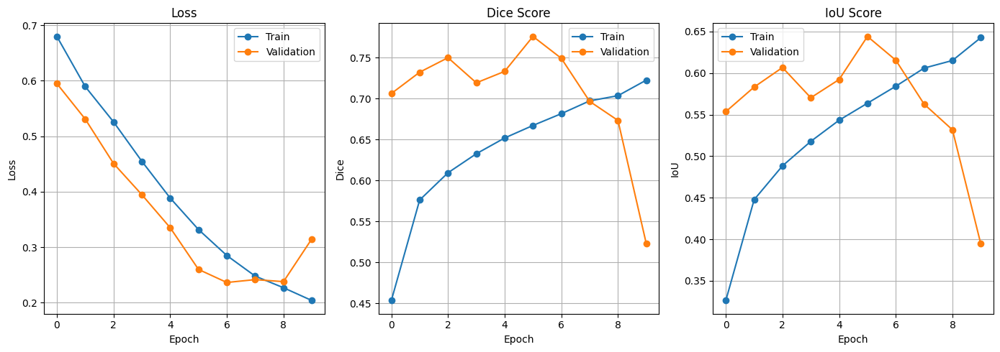


GENERATING SAMPLE PREDICTIONS


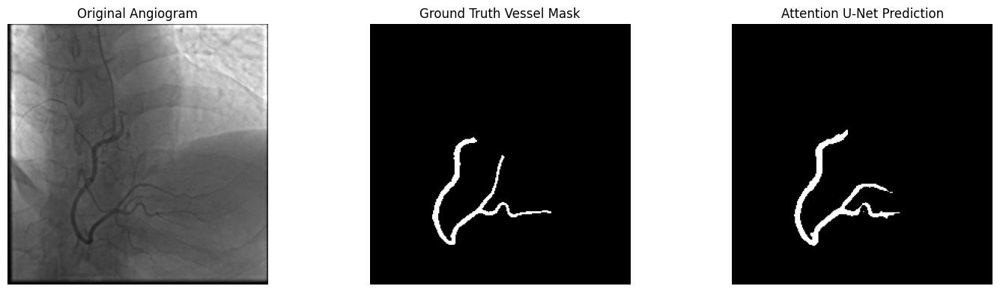

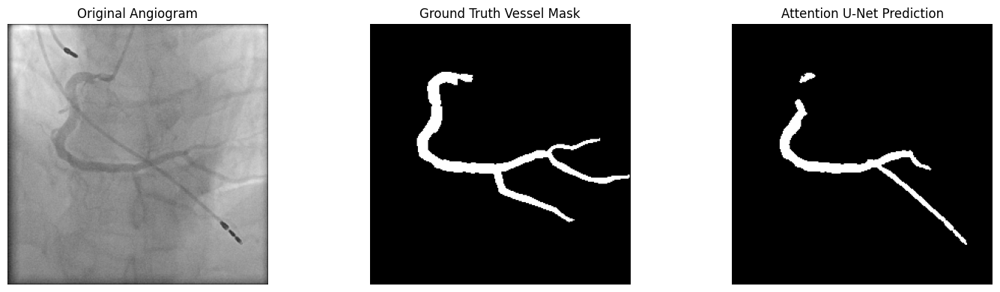

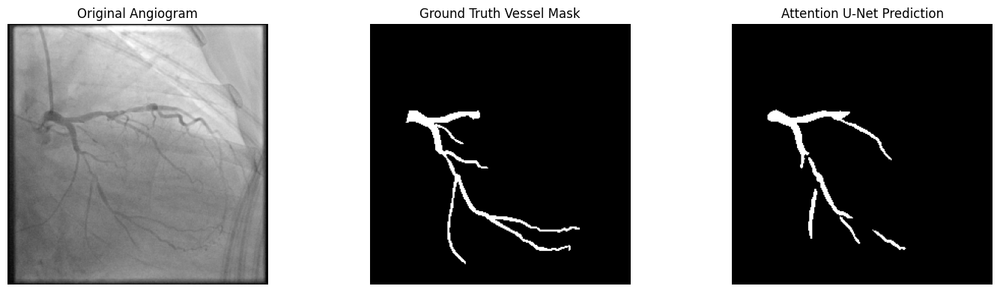


Running final validation...

Final Best Model Validation:
Loss : 0.2599
Dice : 0.7760
IoU  : 0.6441

CREATING MODEL 2 PICKLE

🎉 MODEL 2 COMPLETED SUCCESSFULLY

MODEL:
Attention U-Net + Pretrained ResNet34

DATASET:
ARCADE

TASK:
Binary Coronary Vessel Segmentation

BEST EPOCH:
6

BEST VALIDATION DICE:
0.7760

BEST VALIDATION IoU:
0.6441

.pth size:
100.86 MB

.pkl size:
100.85 MB

Files:
/content/best_attention_unet_resnet34_arcade.pth
/content/attention_unet_resnet34_arcade_model.pkl

DOWNLOADING .PTH MODEL


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


DOWNLOADING .PKL MODEL


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✅ MODEL 2 — ATTENTION U-NET COMPLETED
✅ DATASET FOUND
✅ FORWARD PASS VERIFIED
✅ TRAINING COMPLETED
✅ BEST CHECKPOINT SAVED
✅ .PTH DOWNLOADED
✅ .PKL DOWNLOADED


In [ ]:
# ============================================================
# MODEL 2
# ATTENTION U-NET + PRETRAINED RESNET34
# ARCADE CORONARY VESSEL SEGMENTATION
#
# COMPLETE ONE-CELL GOOGLE COLAB CODE
#
# SAME STRUCTURE AS MODEL 1:
# 1. Dataset detection
# 2. Preprocessing
# 3. Dataset / DataLoader
# 4. Attention U-Net + ResNet34
# 5. Forward-pass verification
# 6. Training
# 7. Validation
# 8. Dice / IoU
# 9. Best model checkpoint
# 10. Training curves
# 11. Prediction visualization
# 12. .pth download
# 13. .pkl download
#
# CPU ONLY
# NO GOOGLE DRIVE
# ============================================================


# ============================================================
# 0. INSTALL REQUIRED LIBRARIES
# ============================================================

print("=" * 70)
print("INSTALLING REQUIRED PACKAGES")
print("=" * 70)

!pip install -q segmentation-models-pytorch pycocotools

print("✅ Required packages installed")


# ============================================================
# 1. IMPORTS
# ============================================================

import os
import json
import glob
import time
import random
import pickle
import zipfile

import numpy as np
import cv2
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

import segmentation_models_pytorch as smp

from pycocotools import mask as maskUtils

from google.colab import files


# ============================================================
# 2. CONFIGURATION
# ============================================================

DEVICE = torch.device("cpu")

IMG_SIZE = 256

BATCH_SIZE = 2

EPOCHS = 10

LEARNING_RATE = 1e-4

WEIGHT_DECAY = 1e-5

SEARCH_ROOT = "/content"

BEST_MODEL = (
    "/content/"
    "best_attention_unet_resnet34_arcade.pth"
)

CHECKPOINT_DIR = (
    "/content/"
    "attention_unet_resnet34_checkpoints"
)

PKL_MODEL = (
    "/content/"
    "attention_unet_resnet34_arcade_model.pkl"
)

os.makedirs(
    CHECKPOINT_DIR,
    exist_ok=True
)

# ------------------------------------------------------------
# CPU configuration
# ------------------------------------------------------------

CPU_THREADS = max(
    1,
    min(
        2,
        os.cpu_count() or 1
    )
)

torch.set_num_threads(
    CPU_THREADS
)

print("\n" + "=" * 70)
print("MODEL 2 — ATTENTION U-NET + RESNET34")
print("=" * 70)

print("Device        :", DEVICE)
print("CPU threads   :", CPU_THREADS)
print("Image size    :", IMG_SIZE)
print("Batch size    :", BATCH_SIZE)
print("Epochs        :", EPOCHS)
print("Learning rate :", LEARNING_RATE)


# ============================================================
# 3. RANDOM SEED
# ============================================================

SEED = 42

random.seed(SEED)

np.random.seed(SEED)

torch.manual_seed(SEED)


# ============================================================
# 4. FIND ARCADE DATASET
# ============================================================

print("\n" + "=" * 70)
print("SEARCHING FOR ARCADE DATASET")
print("=" * 70)


def find_arcade_annotations():

    train_files = []
    val_files = []

    for root, dirs, filenames in os.walk(
        SEARCH_ROOT
    ):

        for filename in filenames:

            if filename.lower() == "train.json":

                path = os.path.join(
                    root,
                    filename
                )

                normalized = (
                    path
                    .replace("\\", "/")
                    .lower()
                )

                if (
                    "/syntax/" in normalized
                    and
                    "/annotations/" in normalized
                ):

                    train_files.append(
                        path
                    )

            elif filename.lower() == "val.json":

                path = os.path.join(
                    root,
                    filename
                )

                normalized = (
                    path
                    .replace("\\", "/")
                    .lower()
                )

                if (
                    "/syntax/" in normalized
                    and
                    "/annotations/" in normalized
                ):

                    val_files.append(
                        path
                    )

    return train_files, val_files


train_candidates, val_candidates = (
    find_arcade_annotations()
)


# ============================================================
# 5. SEARCH FOR ZIP IF DATASET IS NOT FOUND
# ============================================================

if (
    len(train_candidates) == 0
    or
    len(val_candidates) == 0
):

    print(
        "\n⚠️ ARCADE dataset not found."
    )

    print(
        "Searching for ARCADE ZIP..."
    )

    zip_candidates = []

    for root, dirs, filenames in os.walk(
        SEARCH_ROOT
    ):

        for filename in filenames:

            if filename.lower().endswith(
                ".zip"
            ):

                name = filename.lower()

                if (
                    "arcade" in name
                    or
                    "angiography" in name
                    or
                    "annotated" in name
                ):

                    zip_candidates.append(
                        os.path.join(
                            root,
                            filename
                        )
                    )

    if len(zip_candidates) > 0:

        DATASET_ZIP = (
            zip_candidates[0]
        )

        print(
            "\nZIP found:"
        )

        print(
            DATASET_ZIP
        )

        print(
            "\nExtracting..."
        )

        with zipfile.ZipFile(
            DATASET_ZIP,
            "r"
        ) as zip_ref:

            zip_ref.extractall(
                SEARCH_ROOT
            )

        print(
            "✅ Dataset extracted."
        )

        train_candidates, val_candidates = (
            find_arcade_annotations()
        )


# ============================================================
# 6. UPLOAD IF STILL NOT FOUND
# ============================================================

if (
    len(train_candidates) == 0
    or
    len(val_candidates) == 0
):

    print(
        "\n" + "=" * 70
    )

    print(
        "ARCADE DATASET UPLOAD REQUIRED"
    )

    print(
        "=" * 70
    )

    print(
        "\nUpload your ARCADE ZIP file."
    )

    uploaded = files.upload()

    uploaded_zip = None

    for filename in uploaded.keys():

        if filename.lower().endswith(
            ".zip"
        ):

            uploaded_zip = (
                "/content/"
                + filename
            )

            break

    if uploaded_zip is None:

        raise RuntimeError(
            "❌ Please upload the ARCADE ZIP file."
        )

    print(
        "\nUploaded:"
    )

    print(
        uploaded_zip
    )

    print(
        "\nExtracting dataset..."
    )

    with zipfile.ZipFile(
        uploaded_zip,
        "r"
    ) as zip_ref:

        zip_ref.extractall(
            SEARCH_ROOT
        )

    print(
        "✅ Dataset extracted."
    )

    train_candidates, val_candidates = (
        find_arcade_annotations()
    )


# ============================================================
# 7. VERIFY DATASET
# ============================================================

if len(train_candidates) == 0:

    raise RuntimeError(
        "❌ ARCADE train.json not found."
    )

if len(val_candidates) == 0:

    raise RuntimeError(
        "❌ ARCADE val.json not found."
    )


TRAIN_JSON = train_candidates[0]

VAL_JSON = val_candidates[0]


print(
    "\n" + "=" * 70
)

print(
    "✅ ARCADE DATASET FOUND"
)

print(
    "=" * 70
)

print(
    "\nTraining JSON:"
)

print(
    TRAIN_JSON
)

print(
    "\nValidation JSON:"
)

print(
    VAL_JSON
)


# ============================================================
# 8. ARCADE DATASET
# ============================================================

class ARCADEDataset(
    Dataset
):

    def __init__(
        self,
        annotation_file,
        image_root,
        img_size=256
    ):

        with open(
            annotation_file,
            "r"
        ) as f:

            self.coco = json.load(f)

        self.image_root = image_root

        self.img_size = img_size

        self.images = (
            self.coco["images"]
        )

        self.annotations = (
            self.coco["annotations"]
        )

        # ----------------------------------------------------
        # Map annotations to image IDs
        # ----------------------------------------------------

        self.ann_map = {}

        for ann in self.annotations:

            image_id = (
                ann["image_id"]
            )

            if image_id not in self.ann_map:

                self.ann_map[
                    image_id
                ] = []

            self.ann_map[
                image_id
            ].append(
                ann
            )

        # ----------------------------------------------------
        # Find image files
        # ----------------------------------------------------

        self.image_paths = {}

        for img in self.images:

            file_name = (
                img["file_name"]
            )

            basename = (
                os.path.basename(
                    file_name
                )
            )

            matches = glob.glob(
                image_root
                + "/**/"
                + basename,
                recursive=True
            )

            if len(matches) > 0:

                self.image_paths[
                    img["id"]
                ] = matches[0]

        # ----------------------------------------------------
        # Keep only existing images
        # ----------------------------------------------------

        self.images = [

            img

            for img in self.images

            if img["id"]
            in self.image_paths

        ]

        print(
            f"Dataset loaded: "
            f"{len(self.images)} images | "
            f"{len(self.annotations)} annotations"
        )

    def __len__(
        self
    ):

        return len(
            self.images
        )

    def __getitem__(
        self,
        index
    ):

        img_info = (
            self.images[index]
        )

        image_id = (
            img_info["id"]
        )

        image_path = (
            self.image_paths[
                image_id
            ]
        )

        # ----------------------------------------------------
        # Read image
        # ----------------------------------------------------

        image = cv2.imread(
            image_path
        )

        if image is None:

            raise RuntimeError(
                "Could not read image: "
                + image_path
            )

        image = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )

        original_h, original_w = (
            image.shape[:2]
        )

        # ----------------------------------------------------
        # Create binary vessel mask
        #
        # All ARCADE syntax vessel categories
        # are merged into one vessel class.
        # ----------------------------------------------------

        mask = np.zeros(
            (
                original_h,
                original_w
            ),
            dtype=np.uint8
        )

        anns = (
            self.ann_map.get(
                image_id,
                []
            )
        )

        for ann in anns:

            segmentation = (
                ann.get(
                    "segmentation"
                )
            )

            if segmentation is None:

                continue

            try:

                # ------------------------------------------------
                # Polygon segmentation
                # ------------------------------------------------

                if isinstance(
                    segmentation,
                    list
                ):

                    for polygon in segmentation:

                        if len(polygon) < 6:

                            continue

                        points = np.array(
                            polygon,
                            dtype=np.float32
                        ).reshape(
                            -1,
                            2
                        )

                        points[:, 0] = np.clip(
                            points[:, 0],
                            0,
                            original_w - 1
                        )

                        points[:, 1] = np.clip(
                            points[:, 1],
                            0,
                            original_h - 1
                        )

                        points = points.astype(
                            np.int32
                        )

                        cv2.fillPoly(
                            mask,
                            [points],
                            1
                        )

                # ------------------------------------------------
                # RLE segmentation
                # ------------------------------------------------

                elif isinstance(
                    segmentation,
                    dict
                ):

                    rle = segmentation

                    if isinstance(
                        rle.get(
                            "counts"
                        ),
                        list
                    ):

                        rle = (
                            maskUtils.frPyObjects(
                                rle,
                                original_h,
                                original_w
                            )
                        )

                    decoded = (
                        maskUtils.decode(
                            rle
                        )
                    )

                    if decoded.ndim == 3:

                        decoded = np.any(
                            decoded,
                            axis=2
                        )

                    mask[
                        decoded > 0
                    ] = 1

            except Exception:

                continue

        # ----------------------------------------------------
        # Resize image
        # ----------------------------------------------------

        image = cv2.resize(
            image,
            (
                self.img_size,
                self.img_size
            ),
            interpolation=cv2.INTER_AREA
        )

        # ----------------------------------------------------
        # Resize mask
        # ----------------------------------------------------

        mask = cv2.resize(
            mask,
            (
                self.img_size,
                self.img_size
            ),
            interpolation=cv2.INTER_NEAREST
        )

        # ----------------------------------------------------
        # Normalize image
        # ----------------------------------------------------

        image = (
            image.astype(
                np.float32
            )
            / 255.0
        )

        mean = np.array(
            [
                0.485,
                0.456,
                0.406
            ],
            dtype=np.float32
        )

        std = np.array(
            [
                0.229,
                0.224,
                0.225
            ],
            dtype=np.float32
        )

        image = (
            image - mean
        ) / std

        # ----------------------------------------------------
        # HWC -> CHW
        # ----------------------------------------------------

        image = np.transpose(
            image,
            (
                2,
                0,
                1
            )
        )

        image = torch.tensor(
            image,
            dtype=torch.float32
        )

        # ----------------------------------------------------
        # Mask tensor
        # ----------------------------------------------------

        mask = torch.tensor(
            mask,
            dtype=torch.float32
        ).unsqueeze(
            0
        )

        return image, mask


# ============================================================
# 9. CREATE DATASETS
# ============================================================

print(
    "\n" + "=" * 70
)

print(
    "CREATING DATASETS"
)

print(
    "=" * 70
)

train_dataset = ARCADEDataset(
    TRAIN_JSON,
    SEARCH_ROOT,
    IMG_SIZE
)

val_dataset = ARCADEDataset(
    VAL_JSON,
    SEARCH_ROOT,
    IMG_SIZE
)

print(
    "\nTrain samples:",
    len(train_dataset)
)

print(
    "Validation samples:",
    len(val_dataset)
)


# ============================================================
# 10. DATALOADERS
# ============================================================

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print(
    "\n✅ DataLoaders ready"
)


# ============================================================
# 11. ATTENTION GATE
# ============================================================

class AttentionGate(
    nn.Module
):

    def __init__(
        self,
        gate_channels,
        skip_channels,
        intermediate_channels
    ):

        super().__init__()

        # ----------------------------------------------------
        # Gate projection
        # ----------------------------------------------------

        self.W_g = nn.Sequential(

            nn.Conv2d(
                gate_channels,
                intermediate_channels,
                kernel_size=1,
                stride=1,
                padding=0,
                bias=False
            ),

            nn.BatchNorm2d(
                intermediate_channels
            )
        )

        # ----------------------------------------------------
        # Skip projection
        # ----------------------------------------------------

        self.W_x = nn.Sequential(

            nn.Conv2d(
                skip_channels,
                intermediate_channels,
                kernel_size=1,
                stride=1,
                padding=0,
                bias=False
            ),

            nn.BatchNorm2d(
                intermediate_channels
            )
        )

        # ----------------------------------------------------
        # Attention coefficient
        # ----------------------------------------------------

        self.psi = nn.Sequential(

            nn.Conv2d(
                intermediate_channels,
                1,
                kernel_size=1,
                stride=1,
                padding=0,
                bias=True
            ),

            nn.BatchNorm2d(
                1
            ),

            nn.Sigmoid()
        )

        self.relu = nn.ReLU(
            inplace=True
        )

    def forward(
        self,
        gate,
        skip
    ):

        gate_projection = (
            self.W_g(
                gate
            )
        )

        skip_projection = (
            self.W_x(
                skip
            )
        )

        # ----------------------------------------------------
        # Match spatial dimensions
        # ----------------------------------------------------

        if (
            gate_projection.shape[2:]
            !=
            skip_projection.shape[2:]
        ):

            gate_projection = F.interpolate(
                gate_projection,
                size=skip_projection.shape[2:],
                mode="bilinear",
                align_corners=False
            )

        # ----------------------------------------------------
        # Attention
        # ----------------------------------------------------

        attention = self.relu(
            gate_projection
            +
            skip_projection
        )

        attention = self.psi(
            attention
        )

        return (
            skip
            *
            attention
        )


# ============================================================
# 12. DECODER BLOCK
# ============================================================

class DecoderBlock(
    nn.Module
):

    def __init__(
        self,
        in_channels,
        out_channels
    ):

        super().__init__()

        self.block = nn.Sequential(

            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(
                out_channels
            ),

            nn.ReLU(
                inplace=True
            ),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(
                out_channels
            ),

            nn.ReLU(
                inplace=True
            )
        )

    def forward(
        self,
        x
    ):

        return self.block(
            x
        )


# ============================================================
# 13. ATTENTION U-NET + RESNET34
# ============================================================

class AttentionUNetResNet34(
    nn.Module
):

    def __init__(
        self,
        pretrained=True
    ):

        super().__init__()

        print(
            "\nLoading pretrained ResNet34..."
        )

        # ====================================================
        # RESNET34 ENCODER
        #
        # For 256x256 input:
        #
        # x0 = 3    @ 256x256
        # x1 = 64   @ 128x128
        # x2 = 64   @ 64x64
        # x3 = 128  @ 32x32
        # x4 = 256  @ 16x16
        # x5 = 512  @ 8x8
        # ====================================================

        self.encoder = (
            smp.encoders.get_encoder(
                "resnet34",
                in_channels=3,
                depth=5,
                weights=(
                    "imagenet"
                    if pretrained
                    else None
                )
            )
        )

        # ====================================================
        # ATTENTION GATES
        # ====================================================

        # Deepest:
        #
        # gate = 256
        # skip = 256
        #

        self.att4 = AttentionGate(
            gate_channels=256,
            skip_channels=256,
            intermediate_channels=128
        )

        # ----------------------------------------------------

        self.att3 = AttentionGate(
            gate_channels=128,
            skip_channels=128,
            intermediate_channels=64
        )

        # ----------------------------------------------------

        self.att2 = AttentionGate(
            gate_channels=64,
            skip_channels=64,
            intermediate_channels=32
        )

        # ----------------------------------------------------

        self.att1 = AttentionGate(
            gate_channels=64,
            skip_channels=64,
            intermediate_channels=32
        )

        # ====================================================
        # BOTTLENECK
        # ====================================================

        self.bottleneck = nn.Sequential(

            nn.Conv2d(
                512,
                512,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(
                512
            ),

            nn.ReLU(
                inplace=True
            )
        )

        # ====================================================
        # DECODER 4
        # ====================================================

        # x5:
        # 512 channels
        #
        # Convert:
        # 512 -> 256
        #

        self.up4 = nn.Conv2d(
            512,
            256,
            kernel_size=1,
            bias=False
        )

        # concat:
        #
        # 256 decoder
        # 256 skip
        # = 512
        #

        self.dec4 = DecoderBlock(
            512,
            256
        )

        # ====================================================
        # DECODER 3
        # ====================================================

        self.up3 = nn.Conv2d(
            256,
            128,
            kernel_size=1,
            bias=False
        )

        # 128 + 128 = 256

        self.dec3 = DecoderBlock(
            256,
            128
        )

        # ====================================================
        # DECODER 2
        # ====================================================

        self.up2 = nn.Conv2d(
            128,
            64,
            kernel_size=1,
            bias=False
        )

        # 64 + 64 = 128

        self.dec2 = DecoderBlock(
            128,
            64
        )

        # ====================================================
        # DECODER 1
        # ====================================================

        self.up1 = nn.Conv2d(
            64,
            64,
            kernel_size=1,
            bias=False
        )

        # 64 + 64 = 128

        self.dec1 = DecoderBlock(
            128,
            64
        )

        # ====================================================
        # DECODER 0
        # ====================================================

        # x0 contains RGB input = 3 channels.
        #
        # Project:
        # 3 -> 32
        #

        self.x0_projection = nn.Sequential(

            nn.Conv2d(
                3,
                32,
                kernel_size=1,
                bias=False
            ),

            nn.BatchNorm2d(
                32
            ),

            nn.ReLU(
                inplace=True
            )
        )

        # 64 + 32 = 96

        self.dec0 = DecoderBlock(
            96,
            32
        )

        # ====================================================
        # FINAL SEGMENTATION LAYER
        # ====================================================

        self.final_conv = nn.Conv2d(
            32,
            1,
            kernel_size=1
        )

    # ========================================================
    # FORWARD PASS
    # ========================================================

    def forward(
        self,
        x
    ):

        # ====================================================
        # ENCODER
        # ====================================================

        features = self.encoder(
            x
        )

        x0 = features[0]

        x1 = features[1]

        x2 = features[2]

        x3 = features[3]

        x4 = features[4]

        x5 = features[5]

        # ====================================================
        # BOTTLENECK
        # ====================================================

        x5 = self.bottleneck(
            x5
        )

        # ====================================================
        # DECODER 4
        # ====================================================

        d4 = self.up4(
            x5
        )

        d4 = F.interpolate(
            d4,
            size=x4.shape[2:],
            mode="bilinear",
            align_corners=False
        )

        # Attention uses:
        #
        # gate = decoder feature = 256
        # skip = x4 = 256
        #

        x4_att = self.att4(
            d4,
            x4
        )

        d4 = torch.cat(
            [
                d4,
                x4_att
            ],
            dim=1
        )

        d4 = self.dec4(
            d4
        )

        # ====================================================
        # DECODER 3
        # ====================================================

        d3 = self.up3(
            d4
        )

        d3 = F.interpolate(
            d3,
            size=x3.shape[2:],
            mode="bilinear",
            align_corners=False
        )

        x3_att = self.att3(
            d3,
            x3
        )

        d3 = torch.cat(
            [
                d3,
                x3_att
            ],
            dim=1
        )

        d3 = self.dec3(
            d3
        )

        # ====================================================
        # DECODER 2
        # ====================================================

        d2 = self.up2(
            d3
        )

        d2 = F.interpolate(
            d2,
            size=x2.shape[2:],
            mode="bilinear",
            align_corners=False
        )

        x2_att = self.att2(
            d2,
            x2
        )

        d2 = torch.cat(
            [
                d2,
                x2_att
            ],
            dim=1
        )

        d2 = self.dec2(
            d2
        )

        # ====================================================
        # DECODER 1
        # ====================================================

        d1 = self.up1(
            d2
        )

        d1 = F.interpolate(
            d1,
            size=x1.shape[2:],
            mode="bilinear",
            align_corners=False
        )

        x1_att = self.att1(
            d1,
            x1
        )

        d1 = torch.cat(
            [
                d1,
                x1_att
            ],
            dim=1
        )

        d1 = self.dec1(
            d1
        )

        # ====================================================
        # DECODER 0
        # ====================================================

        d0 = F.interpolate(
            d1,
            size=x0.shape[2:],
            mode="bilinear",
            align_corners=False
        )

        x0_projected = (
            self.x0_projection(
                x0
            )
        )

        d0 = torch.cat(
            [
                d0,
                x0_projected
            ],
            dim=1
        )

        d0 = self.dec0(
            d0
        )

        # ====================================================
        # FINAL OUTPUT
        # ====================================================

        output = self.final_conv(
            d0
        )

        # Ensure exact 256x256 output

        output = F.interpolate(
            output,
            size=(
                IMG_SIZE,
                IMG_SIZE
            ),
            mode="bilinear",
            align_corners=False
        )

        return output


# ============================================================
# 14. CREATE MODEL
# ============================================================

print(
    "\n" + "=" * 70
)

print(
    "CREATING ATTENTION U-NET + RESNET34"
)

print(
    "=" * 70
)

model = AttentionUNetResNet34(
    pretrained=True
)

model = model.to(
    DEVICE
)

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(
    "\nTotal parameters:",
    f"{total_params:,}"
)

print(
    "Trainable parameters:",
    f"{trainable_params:,}"
)


# ============================================================
# 15. FORWARD PASS TEST
# ============================================================

print(
    "\n" + "=" * 70
)

print(
    "TESTING FORWARD PASS"
)

print(
    "=" * 70
)

test_images, test_masks = next(
    iter(train_loader)
)

print(
    "\nInput shape:",
    tuple(
        test_images.shape
    )
)

print(
    "Target shape:",
    tuple(
        test_masks.shape
    )
)

with torch.no_grad():

    test_output = model(
        test_images
    )

print(
    "Output shape:",
    tuple(
        test_output.shape
    )
)

if (
    test_output.shape
    !=
    test_masks.shape
):

    raise RuntimeError(
        "❌ Output and target shapes do not match."
    )

print(
    "\n✅ FORWARD PASS SUCCESSFUL"
)

print(
    "✅ CHANNEL DIMENSIONS ARE CORRECT"
)


# ============================================================
# 16. LOSS FUNCTIONS
# ============================================================

bce_loss = nn.BCEWithLogitsLoss()


def dice_loss(
    logits,
    targets,
    smooth=1.0
):

    probabilities = torch.sigmoid(
        logits
    )

    probabilities = (
        probabilities
        .contiguous()
        .view(-1)
    )

    targets = (
        targets
        .contiguous()
        .view(-1)
    )

    intersection = (
        probabilities
        * targets
    ).sum()

    dice = (
        2.0 * intersection
        + smooth
    ) / (
        probabilities.sum()
        + targets.sum()
        + smooth
    )

    return 1.0 - dice


def combined_loss(
    logits,
    targets
):

    return (
        0.5
        *
        bce_loss(
            logits,
            targets
        )
        +
        0.5
        *
        dice_loss(
            logits,
            targets
        )
    )


# ============================================================
# 17. DICE / IOU METRICS
# ============================================================

def calculate_metrics(
    logits,
    targets,
    threshold=0.5,
    smooth=1e-6
):

    probabilities = torch.sigmoid(
        logits
    )

    predictions = (
        probabilities
        >
        threshold
    ).float()

    predictions = predictions.view(
        predictions.size(0),
        -1
    )

    targets = targets.view(
        targets.size(0),
        -1
    )

    intersection = (
        predictions
        *
        targets
    ).sum(
        dim=1
    )

    prediction_sum = (
        predictions.sum(
            dim=1
        )
    )

    target_sum = (
        targets.sum(
            dim=1
        )
    )

    dice = (
        2.0 * intersection
        + smooth
    ) / (
        prediction_sum
        + target_sum
        + smooth
    )

    union = (
        prediction_sum
        +
        target_sum
        -
        intersection
    )

    iou = (
        intersection
        + smooth
    ) / (
        union
        + smooth
    )

    return (
        dice.mean().item(),
        iou.mean().item()
    )


# ============================================================
# 18. OPTIMIZER
# ============================================================

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = (
    torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=2
    )
)


# ============================================================
# 19. TRAINING FUNCTION
# ============================================================

def train_one_epoch():

    model.train()

    running_loss = 0.0

    running_dice = 0.0

    running_iou = 0.0

    total_samples = 0

    for images, masks in train_loader:

        images = images.to(
            DEVICE
        )

        masks = masks.to(
            DEVICE
        )

        optimizer.zero_grad()

        outputs = model(
            images
        )

        loss = combined_loss(
            outputs,
            masks
        )

        loss.backward()

        optimizer.step()

        dice, iou = calculate_metrics(
            outputs.detach(),
            masks
        )

        batch_size = (
            images.size(0)
        )

        running_loss += (
            loss.item()
            *
            batch_size
        )

        running_dice += (
            dice
            *
            batch_size
        )

        running_iou += (
            iou
            *
            batch_size
        )

        total_samples += (
            batch_size
        )

    return (
        running_loss
        /
        total_samples,

        running_dice
        /
        total_samples,

        running_iou
        /
        total_samples
    )


# ============================================================
# 20. VALIDATION FUNCTION
# ============================================================

@torch.no_grad()
def validate():

    model.eval()

    running_loss = 0.0

    running_dice = 0.0

    running_iou = 0.0

    total_samples = 0

    for images, masks in val_loader:

        images = images.to(
            DEVICE
        )

        masks = masks.to(
            DEVICE
        )

        outputs = model(
            images
        )

        loss = combined_loss(
            outputs,
            masks
        )

        dice, iou = calculate_metrics(
            outputs,
            masks
        )

        batch_size = (
            images.size(0)
        )

        running_loss += (
            loss.item()
            *
            batch_size
        )

        running_dice += (
            dice
            *
            batch_size
        )

        running_iou += (
            iou
            *
            batch_size
        )

        total_samples += (
            batch_size
        )

    return (
        running_loss
        /
        total_samples,

        running_dice
        /
        total_samples,

        running_iou
        /
        total_samples
    )


# ============================================================
# 21. TRAIN MODEL
# ============================================================

print(
    "\n" + "=" * 70
)

print(
    "STARTING MODEL 2 TRAINING"
)

print(
    "=" * 70
)

history = {

    "train_loss": [],

    "train_dice": [],

    "train_iou": [],

    "val_loss": [],

    "val_dice": [],

    "val_iou": []
}

best_val_dice = -1.0

training_start = time.time()


for epoch in range(
    1,
    EPOCHS + 1
):

    epoch_start = time.time()

    # --------------------------------------------------------
    # Training
    # --------------------------------------------------------

    (
        train_loss,
        train_dice,
        train_iou
    ) = train_one_epoch()

    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------

    (
        val_loss,
        val_dice,
        val_iou
    ) = validate()

    # --------------------------------------------------------
    # Scheduler
    # --------------------------------------------------------

    scheduler.step(
        val_dice
    )

    current_lr = (
        optimizer
        .param_groups[0]["lr"]
    )

    # --------------------------------------------------------
    # Save history
    # --------------------------------------------------------

    history[
        "train_loss"
    ].append(
        train_loss
    )

    history[
        "train_dice"
    ].append(
        train_dice
    )

    history[
        "train_iou"
    ].append(
        train_iou
    )

    history[
        "val_loss"
    ].append(
        val_loss
    )

    history[
        "val_dice"
    ].append(
        val_dice
    )

    history[
        "val_iou"
    ].append(
        val_iou
    )

    epoch_time = (
        time.time()
        - epoch_start
    )

    # --------------------------------------------------------
    # Print epoch
    # --------------------------------------------------------

    print(
        "\n" + "-" * 70
    )

    print(
        f"Epoch [{epoch}/{EPOCHS}]"
    )

    print(
        f"Time       : "
        f"{epoch_time / 60:.2f} min"
    )

    print(
        f"Train Loss : {train_loss:.4f}"
    )

    print(
        f"Train Dice : {train_dice:.4f}"
    )

    print(
        f"Train IoU  : {train_iou:.4f}"
    )

    print(
        f"Val Loss   : {val_loss:.4f}"
    )

    print(
        f"Val Dice   : {val_dice:.4f}"
    )

    print(
        f"Val IoU    : {val_iou:.4f}"
    )

    print(
        f"LR         : {current_lr:.7f}"
    )

    # --------------------------------------------------------
    # Save epoch checkpoint
    # --------------------------------------------------------

    epoch_checkpoint = os.path.join(
        CHECKPOINT_DIR,
        f"epoch_{epoch}.pth"
    )

    torch.save(
        {
            "epoch":
                epoch,

            "model_state_dict":
                model.state_dict(),

            "optimizer_state_dict":
                optimizer.state_dict(),

            "val_dice":
                val_dice,

            "val_iou":
                val_iou,

            "history":
                history
        },
        epoch_checkpoint
    )

    # --------------------------------------------------------
    # Best model
    # --------------------------------------------------------

    if (
        val_dice
        >
        best_val_dice
    ):

        best_val_dice = (
            val_dice
        )

        torch.save(
            {
                "epoch":
                    epoch,

                "model_state_dict":
                    model.state_dict(),

                "val_dice":
                    val_dice,

                "val_iou":
                    val_iou,

                "history":
                    history
            },
            BEST_MODEL
        )

        print(
            "⭐ NEW BEST MODEL SAVED"
        )


# ============================================================
# 22. TRAINING FINISHED
# ============================================================

total_training_time = (
    time.time()
    -
    training_start
)

print(
    "\n" + "=" * 70
)

print(
    "TRAINING COMPLETE"
)

print(
    "=" * 70
)

print(
    f"\nTotal training time:"
    f" {total_training_time / 60:.2f} minutes"
)


# ============================================================
# 23. LOAD BEST MODEL
# ============================================================

print(
    "\nLoading best model..."
)

best_checkpoint = torch.load(
    BEST_MODEL,
    map_location=DEVICE
)

model.load_state_dict(
    best_checkpoint[
        "model_state_dict"
    ]
)

model.eval()


# ============================================================
# 24. BEST MODEL RESULTS
# ============================================================

print(
    "\n" + "=" * 70
)

print(
    "BEST MODEL RESULTS"
)

print(
    "=" * 70
)

print(
    "\nBest Epoch:"
)

print(
    best_checkpoint[
        "epoch"
    ]
)

print(
    "\nBest Validation Dice:"
)

print(
    f"{best_checkpoint['val_dice']:.4f}"
)

print(
    "\nBest Validation IoU:"
)

print(
    f"{best_checkpoint['val_iou']:.4f}"
)


# ============================================================
# 25. TRAINING CURVES
# ============================================================

plt.figure(
    figsize=(14, 5)
)

# ------------------------------------------------------------
# Loss
# ------------------------------------------------------------

plt.subplot(
    1,
    3,
    1
)

plt.plot(
    history[
        "train_loss"
    ],
    marker="o",
    label="Train"
)

plt.plot(
    history[
        "val_loss"
    ],
    marker="o",
    label="Validation"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Loss"
)

plt.title(
    "Loss"
)

plt.legend()

plt.grid(
    True
)

# ------------------------------------------------------------
# Dice
# ------------------------------------------------------------

plt.subplot(
    1,
    3,
    2
)

plt.plot(
    history[
        "train_dice"
    ],
    marker="o",
    label="Train"
)

plt.plot(
    history[
        "val_dice"
    ],
    marker="o",
    label="Validation"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Dice"
)

plt.title(
    "Dice Score"
)

plt.legend()

plt.grid(
    True
)

# ------------------------------------------------------------
# IoU
# ------------------------------------------------------------

plt.subplot(
    1,
    3,
    3
)

plt.plot(
    history[
        "train_iou"
    ],
    marker="o",
    label="Train"
)

plt.plot(
    history[
        "val_iou"
    ],
    marker="o",
    label="Validation"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "IoU"
)

plt.title(
    "IoU Score"
)

plt.legend()

plt.grid(
    True
)

plt.tight_layout()

plt.show()


# ============================================================
# 26. PREDICTION VISUALIZATION
# ============================================================

@torch.no_grad()
def show_predictions(
    dataset,
    num_images=3
):

    model.eval()

    num_images = min(
        num_images,
        len(dataset)
    )

    indices = random.sample(
        range(
            len(dataset)
        ),
        num_images
    )

    for index in indices:

        image_tensor, mask_tensor = (
            dataset[index]
        )

        output = model(
            image_tensor
            .unsqueeze(0)
            .to(DEVICE)
        )

        prediction = torch.sigmoid(
            output
        )[0, 0].cpu().numpy()

        prediction = (
            prediction > 0.5
        ).astype(
            np.uint8
        )

        # ----------------------------------------------------
        # Recover original image appearance
        # ----------------------------------------------------

        image = (
            image_tensor
            .cpu()
            .numpy()
            .transpose(
                1,
                2,
                0
            )
        )

        mean = np.array(
            [
                0.485,
                0.456,
                0.406
            ]
        )

        std = np.array(
            [
                0.229,
                0.224,
                0.225
            ]
        )

        image = (
            image
            * std
            + mean
        )

        image = np.clip(
            image,
            0,
            1
        )

        ground_truth = (
            mask_tensor[0]
            .numpy()
        )

        # ----------------------------------------------------
        # Display
        # ----------------------------------------------------

        plt.figure(
            figsize=(15, 4)
        )

        plt.subplot(
            1,
            3,
            1
        )

        plt.imshow(
            image
        )

        plt.title(
            "Original Angiogram"
        )

        plt.axis(
            "off"
        )

        plt.subplot(
            1,
            3,
            2
        )

        plt.imshow(
            ground_truth,
            cmap="gray"
        )

        plt.title(
            "Ground Truth Vessel Mask"
        )

        plt.axis(
            "off"
        )

        plt.subplot(
            1,
            3,
            3
        )

        plt.imshow(
            prediction,
            cmap="gray"
        )

        plt.title(
            "Attention U-Net Prediction"
        )

        plt.axis(
            "off"
        )

        plt.tight_layout()

        plt.show()


print(
    "\n" + "=" * 70
)

print(
    "GENERATING SAMPLE PREDICTIONS"
)

print(
    "=" * 70
)

show_predictions(
    val_dataset,
    num_images=3
)


# ============================================================
# 27. FINAL VALIDATION
# ============================================================

print(
    "\nRunning final validation..."
)

final_val_loss, final_val_dice, final_val_iou = (
    validate()
)

print(
    "\nFinal Best Model Validation:"
)

print(
    f"Loss : {final_val_loss:.4f}"
)

print(
    f"Dice : {final_val_dice:.4f}"
)

print(
    f"IoU  : {final_val_iou:.4f}"
)


# ============================================================
# 28. CREATE PICKLE PACKAGE
# ============================================================

print(
    "\n" + "=" * 70
)

print(
    "CREATING MODEL 2 PICKLE"
)

print(
    "=" * 70
)

# ------------------------------------------------------------
# Put model on CPU before saving
# ------------------------------------------------------------

model = model.to(
    "cpu"
)

model.eval()

# ------------------------------------------------------------
# Create package
# ------------------------------------------------------------

model_package = {

    "model_name":
        "Attention U-Net + ResNet34",

    "model_type":
        "AttentionUNetResNet34",

    "architecture":
        "Attention U-Net with pretrained ResNet34 encoder",

    "dataset":
        "ARCADE",

    "task":
        "Binary Coronary Vessel Segmentation",

    "image_size":
        IMG_SIZE,

    "input_channels":
        3,

    "output_channels":
        1,

    "batch_size":
        BATCH_SIZE,

    "epochs":
        EPOCHS,

    "learning_rate":
        LEARNING_RATE,

    "best_epoch":
        best_checkpoint[
            "epoch"
        ],

    "best_val_dice":
        best_checkpoint[
            "val_dice"
        ],

    "best_val_iou":
        best_checkpoint[
            "val_iou"
        ],

    "preprocessing":
        {
            "resize":
                IMG_SIZE,

            "normalization_mean":
                [
                    0.485,
                    0.456,
                    0.406
                ],

            "normalization_std":
                [
                    0.229,
                    0.224,
                    0.225
                ]
        },

    "model_state_dict":
        model.state_dict()
}


# ============================================================
# 29. SAVE PICKLE
# ============================================================

with open(
    PKL_MODEL,
    "wb"
) as f:

    pickle.dump(
        model_package,
        f,
        protocol=pickle.HIGHEST_PROTOCOL
    )


# ============================================================
# 30. VERIFY FILES
# ============================================================

if not os.path.exists(
    BEST_MODEL
):

    raise RuntimeError(
        "❌ .pth file was not created."
    )

if not os.path.exists(
    PKL_MODEL
):

    raise RuntimeError(
        "❌ .pkl file was not created."
    )


pth_size = (
    os.path.getsize(
        BEST_MODEL
    )
    /
    (1024 * 1024)
)

pkl_size = (
    os.path.getsize(
        PKL_MODEL
    )
    /
    (1024 * 1024)
)


# ============================================================
# 31. FINAL SUMMARY
# ============================================================

print(
    "\n" + "=" * 70
)

print(
    "🎉 MODEL 2 COMPLETED SUCCESSFULLY"
)

print(
    "=" * 70
)

print(
    "\nMODEL:"
)

print(
    "Attention U-Net + Pretrained ResNet34"
)

print(
    "\nDATASET:"
)

print(
    "ARCADE"
)

print(
    "\nTASK:"
)

print(
    "Binary Coronary Vessel Segmentation"
)

print(
    "\nBEST EPOCH:"
)

print(
    best_checkpoint[
        "epoch"
    ]
)

print(
    "\nBEST VALIDATION DICE:"
)

print(
    f"{best_checkpoint['val_dice']:.4f}"
)

print(
    "\nBEST VALIDATION IoU:"
)

print(
    f"{best_checkpoint['val_iou']:.4f}"
)

print(
    "\n.pth size:"
)

print(
    f"{pth_size:.2f} MB"
)

print(
    "\n.pkl size:"
)

print(
    f"{pkl_size:.2f} MB"
)

print(
    "\nFiles:"
)

print(
    BEST_MODEL
)

print(
    PKL_MODEL
)


# ============================================================
# 32. DOWNLOAD BEST .PTH
# ============================================================

print(
    "\n" + "=" * 70
)

print(
    "DOWNLOADING .PTH MODEL"
)

print(
    "=" * 70
)

files.download(
    BEST_MODEL
)


# ============================================================
# 33. DOWNLOAD FINAL .PKL
# ============================================================

print(
    "\n" + "=" * 70
)

print(
    "DOWNLOADING .PKL MODEL"
)

print(
    "=" * 70
)

files.download(
    PKL_MODEL
)


# ============================================================
# FINAL
# ============================================================

print(
    "\n" + "=" * 70
)

print(
    "✅ MODEL 2 — ATTENTION U-NET COMPLETED"
)

print(
    "✅ DATASET FOUND"
)

print(
    "✅ FORWARD PASS VERIFIED"
)

print(
    "✅ TRAINING COMPLETED"
)

print(
    "✅ BEST CHECKPOINT SAVED"
)

print(
    "✅ .PTH DOWNLOADED"
)

print(
    "✅ .PKL DOWNLOADED"
)

print(
    "=" * 70
)

In [ ]:
from google.colab import files
import os

PKL_MODEL = "/content/attention_unet_resnet34_arcade_model.pkl"

if os.path.exists(PKL_MODEL):
    size_mb = os.path.getsize(PKL_MODEL) / (1024 * 1024)

    print("✅ Model 2 PKL file found")
    print("File:", PKL_MODEL)
    print(f"Size: {size_mb:.2f} MB")
    print("\n⬇️ Downloading Model 2 PKL now...")

    files.download(PKL_MODEL)

    print("\n✅ Download command completed")
else:
    print("❌ Model 2 PKL file not found")



❌ Model 2 PKL file not found


In [ ]:
# ============================================================
# RECOVER MODEL 2 — ATTENTION U-NET + RESNET34
# CREATE AND DOWNLOAD PKL FROM EXISTING PTH
# ============================================================

import os
import pickle
import torch

from google.colab import files


# ============================================================
# 1. SEARCH FOR MODEL 2 PTH
# ============================================================

print("=" * 70)
print("SEARCHING FOR MODEL 2 CHECKPOINT")
print("=" * 70)

pth_candidates = []

for root, dirs, filenames in os.walk("/content"):

    for filename in filenames:

        if filename == "best_attention_unet_resnet34_arcade.pth":

            pth_candidates.append(
                os.path.join(
                    root,
                    filename
                )
            )


# ============================================================
# 2. CHECK WHETHER PTH EXISTS
# ============================================================

if len(pth_candidates) == 0:

    print(
        "\n❌ Model 2 .pth checkpoint was not found."
    )

    print(
        "\nExpected file:"
    )

    print(
        "best_attention_unet_resnet34_arcade.pth"
    )

    print(
        "\nIf you already downloaded the .pth file to your"
        " computer, upload that .pth file now."
    )

    uploaded = files.upload()

    uploaded_pth = None

    for filename in uploaded.keys():

        if filename.lower().endswith(".pth"):

            uploaded_pth = (
                "/content/"
                + filename
            )

            break

    if uploaded_pth is None:

        raise RuntimeError(
            "\n❌ No .pth file was uploaded."
        )

    PTH_MODEL = uploaded_pth

else:

    PTH_MODEL = pth_candidates[0]


# ============================================================
# 3. SHOW CHECKPOINT
# ============================================================

print(
    "\n✅ Model 2 checkpoint found:"
)

print(
    PTH_MODEL
)

pth_size = (
    os.path.getsize(
        PTH_MODEL
    )
    /
    (1024 * 1024)
)

print(
    f"\nPTH size: {pth_size:.2f} MB"
)


# ============================================================
# 4. LOAD CHECKPOINT
# ============================================================

print(
    "\nLoading checkpoint..."
)

checkpoint = torch.load(
    PTH_MODEL,
    map_location="cpu"
)

print(
    "✅ Checkpoint loaded"
)


# ============================================================
# 5. EXTRACT MODEL INFORMATION
# ============================================================

best_epoch = checkpoint.get(
    "epoch",
    None
)

best_val_dice = checkpoint.get(
    "val_dice",
    None
)

best_val_iou = checkpoint.get(
    "val_iou",
    None
)

print(
    "\nModel 2 information:"
)

print(
    "Best Epoch:",
    best_epoch
)

print(
    "Best Validation Dice:",
    best_val_dice
)

print(
    "Best Validation IoU:",
    best_val_iou
)


# ============================================================
# 6. CREATE MODEL 2 PKL PACKAGE
# ============================================================

PKL_MODEL = (
    "/content/"
    "attention_unet_resnet34_arcade_model.pkl"
)

model_package = {

    "model_name":
        "Attention U-Net + ResNet34",

    "model_type":
        "AttentionUNetResNet34",

    "architecture":
        "Attention U-Net with pretrained ResNet34 encoder",

    "dataset":
        "ARCADE",

    "task":
        "Binary Coronary Vessel Segmentation",

    "image_size":
        256,

    "input_channels":
        3,

    "output_channels":
        1,

    "best_epoch":
        best_epoch,

    "best_val_dice":
        best_val_dice,

    "best_val_iou":
        best_val_iou,

    "preprocessing":
        {
            "resize":
                256,

            "normalization_mean":
                [
                    0.485,
                    0.456,
                    0.406
                ],

            "normalization_std":
                [
                    0.229,
                    0.224,
                    0.225
                ]
        },

    "model_state_dict":
        checkpoint[
            "model_state_dict"
        ]
}


# ============================================================
# 7. SAVE PKL
# ============================================================

print(
    "\nCreating Model 2 PKL..."
)

with open(
    PKL_MODEL,
    "wb"
) as f:

    pickle.dump(
        model_package,
        f,
        protocol=pickle.HIGHEST_PROTOCOL
    )


# ============================================================
# 8. VERIFY PKL
# ============================================================

if not os.path.exists(
    PKL_MODEL
):

    raise RuntimeError(
        "❌ PKL creation failed."
    )


pkl_size = (
    os.path.getsize(
        PKL_MODEL
    )
    /
    (1024 * 1024)
)


print(
    "\n" + "=" * 70
)

print(
    "✅ MODEL 2 PKL CREATED"
)

print(
    "=" * 70
)

print(
    "\nFile:"
)

print(
    PKL_MODEL
)

print(
    f"\nPKL size: {pkl_size:.2f} MB"
)

print(
    "\nBest Epoch:",
    best_epoch
)

print(
    "Best Validation Dice:",
    best_val_dice
)

print(
    "Best Validation IoU:",
    best_val_iou
)


# ============================================================
# 9. DOWNLOAD PKL
# ============================================================

print(
    "\n" + "=" * 70
)

print(
    "DOWNLOADING MODEL 2 PKL"
)

print(
    "=" * 70
)

files.download(
    PKL_MODEL
)

print(
    "\n✅ Model 2 PKL download initiated."
)

print(
    "\nFilename:"
)

print(
    "attention_unet_resnet34_arcade_model.pkl"
)

SEARCHING FOR MODEL 2 CHECKPOINT

❌ Model 2 .pth checkpoint was not found.

Expected file:
best_attention_unet_resnet34_arcade.pth

If you already downloaded the .pth file to your computer, upload that .pth file now.


Saving best_attention_unet_resnet34_arcade.pth to best_attention_unet_resnet34_arcade.pth

✅ Model 2 checkpoint found:
/content/best_attention_unet_resnet34_arcade.pth

PTH size: 100.86 MB

Loading checkpoint...
✅ Checkpoint loaded

Model 2 information:
Best Epoch: 6
Best Validation Dice: 0.7759659403562545
Best Validation IoU: 0.6441021141409874

Creating Model 2 PKL...

✅ MODEL 2 PKL CREATED

File:
/content/attention_unet_resnet34_arcade_model.pkl

PKL size: 100.85 MB

Best Epoch: 6
Best Validation Dice: 0.7759659403562545
Best Validation IoU: 0.6441021141409874

DOWNLOADING MODEL 2 PKL


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✅ Model 2 PKL download initiated.

Filename:
attention_unet_resnet34_arcade_model.pkl


In [ ]:
# ============================================================
# DOWNLOAD MODEL 2 PKL ONLY
# ============================================================

from google.colab import files
import os

PKL_FILE = "/content/attention_unet_resnet34_arcade_model.pkl"

print("=" * 70)
print("CHECKING MODEL 2 PKL")
print("=" * 70)

if os.path.exists(PKL_FILE):

    size_mb = os.path.getsize(PKL_FILE) / (1024 * 1024)

    print("\n✅ PKL FILE FOUND")
    print("File:")
    print(PKL_FILE)

    print(f"\nSize: {size_mb:.2f} MB")

    print("\nStarting download...")

    files.download(PKL_FILE)

    print("\n" + "=" * 70)
    print("✅ DOWNLOAD REQUEST SENT")
    print("=" * 70)

    print("\nFilename:")
    print("attention_unet_resnet34_arcade_model.pkl")

else:

    print("\n❌ PKL FILE NOT FOUND IN THIS COLAB RUNTIME")
    print("\nExpected:")
    print(PKL_FILE)

    print(
        "\nIf you see this message, your Colab runtime was reset."
    )

    print(
        "In that case, upload your Model 2 .pth file "
        "and I will give you the exact recovery cell."
    )

CHECKING MODEL 2 PKL

✅ PKL FILE FOUND
File:
/content/attention_unet_resnet34_arcade_model.pkl

Size: 100.85 MB

Starting download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✅ DOWNLOAD REQUEST SENT

Filename:
attention_unet_resnet34_arcade_model.pkl


INSTALLING REQUIRED PACKAGES
✅ Required packages installed

MODEL 3 — U-NET++ + RESNET34
Device        : cpu
CPU threads   : 2
Image size    : 256
Batch size    : 2
Epochs        : 10
Learning rate : 0.0001

SEARCHING FOR ARCADE DATASET

⚠️ Extracted ARCADE dataset not found.
Searching for existing ZIP file...

ARCADE DATASET UPLOAD REQUIRED

Upload your ARCADE dataset ZIP.
You can select archive (1).zip.


Saving archive (1).zip to archive (1).zip

✅ Uploaded:
/content/archive (1).zip

Extracting dataset...
✅ Dataset extracted

✅ ARCADE DATASET FOUND

Training JSON:
/content/data/syntax/train/annotations/train.json

Validation JSON:
/content/data/syntax/val/annotations/val.json

CREATING DATASETS
Dataset loaded: 1000 images | 4976 annotations
Dataset loaded: 200 images | 1168 annotations

Train samples: 1000
Validation samples: 200

✅ DataLoaders ready

CREATING MODEL 3 — U-NET++ + RESNET34

Loading ImageNet pretrained ResNet34 encoder...


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            


Total parameters: 26,078,609
Trainable parameters: 26,078,609

✅ U-Net++ + ResNet34 created

TESTING FORWARD PASS

Input shape : (2, 3, 256, 256)
Target shape: (2, 1, 256, 256)
Output shape: (2, 1, 256, 256)

✅ FORWARD PASS SUCCESSFUL
✅ MODEL 3 ARCHITECTURE VERIFIED

STARTING MODEL 3 TRAINING

----------------------------------------------------------------------
Epoch [1/10]
Time       : 41.51 min
Train Loss : 0.4257
Train Dice : 0.5467
Train IoU  : 0.4216
Val Loss   : 0.2441
Val Dice   : 0.7341
Val IoU    : 0.5908
LR         : 0.0001000
⭐ NEW BEST MODEL SAVED

----------------------------------------------------------------------
Epoch [2/10]
Time       : 43.60 min
Train Loss : 0.2617
Train Dice : 0.6447
Train IoU  : 0.5346
Val Loss   : 0.1594
Val Dice   : 0.7868
Val IoU    : 0.6552
LR         : 0.0001000
⭐ NEW BEST MODEL SAVED

----------------------------------------------------------------------
Epoch [3/10]
Time       : 41.32 min
Train Loss : 0.2286
Train Dice : 0.6709
Train IoU

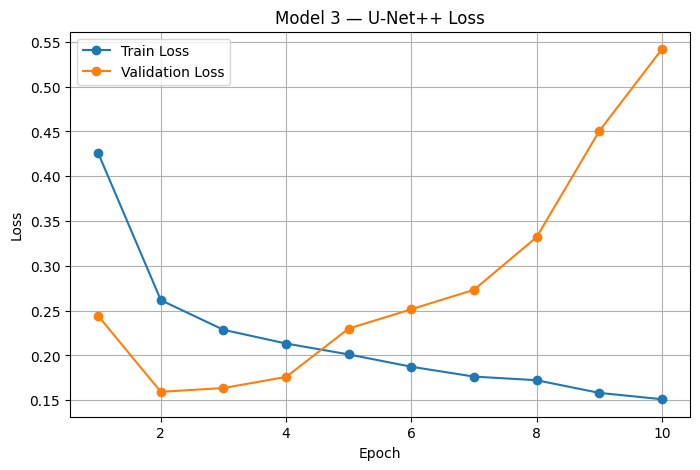

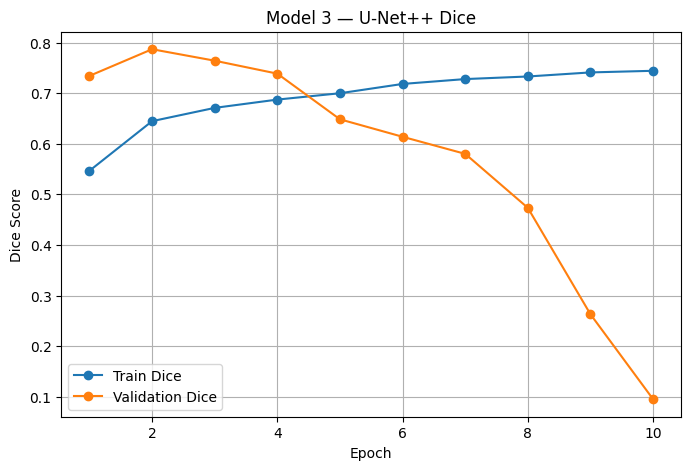

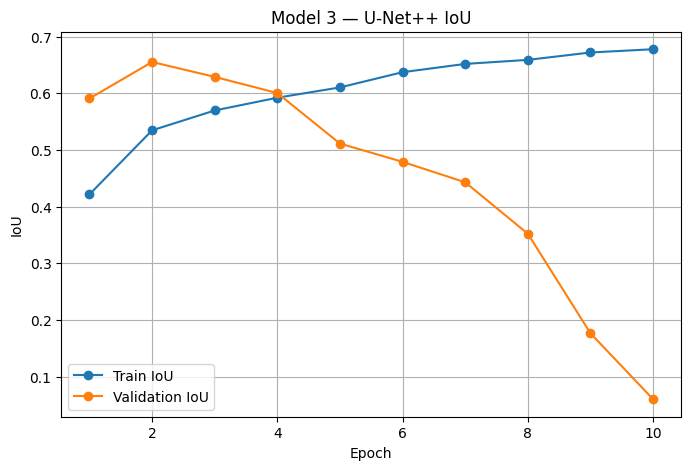


GENERATING MODEL 3 PREDICTIONS


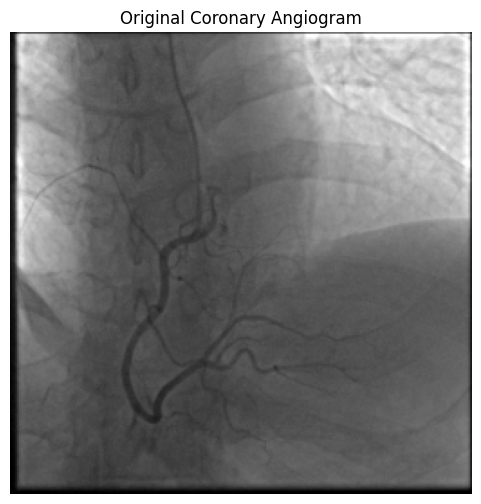

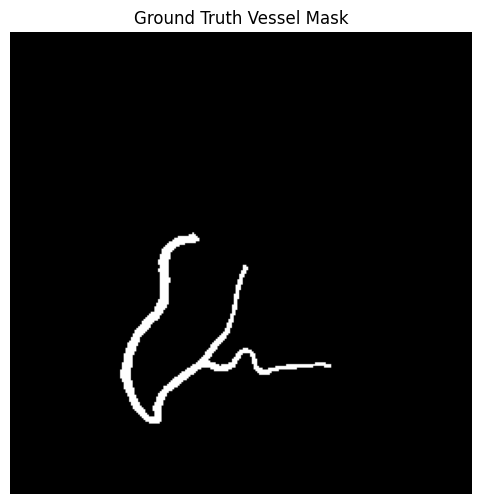

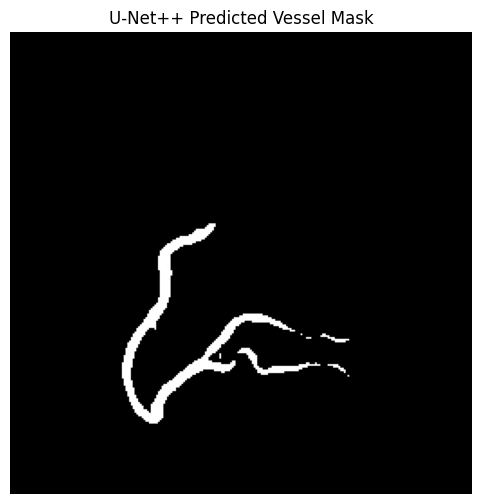

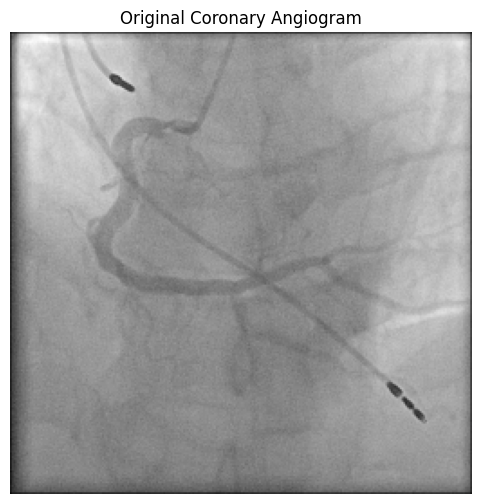

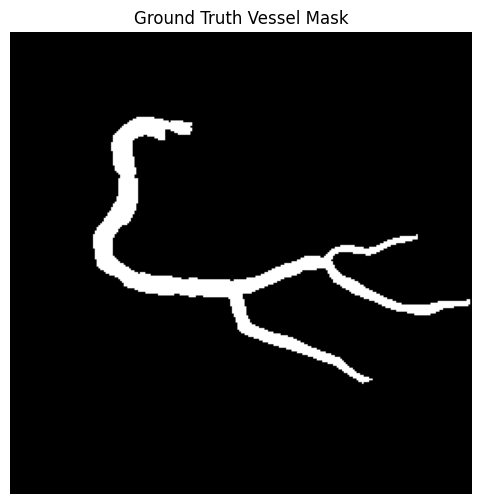

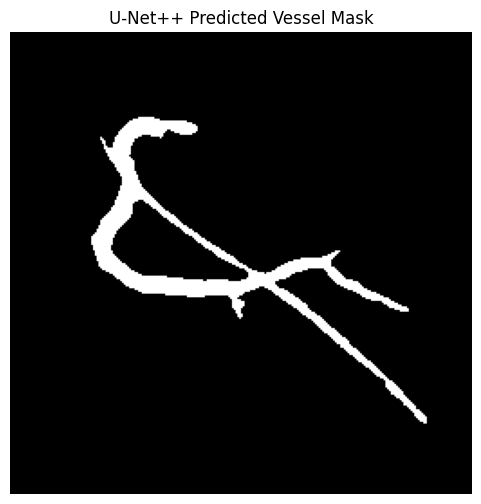

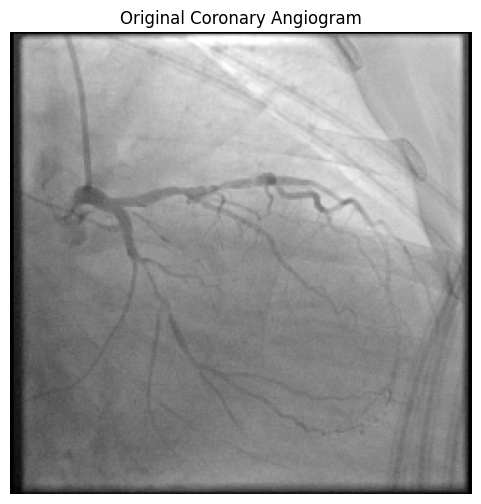

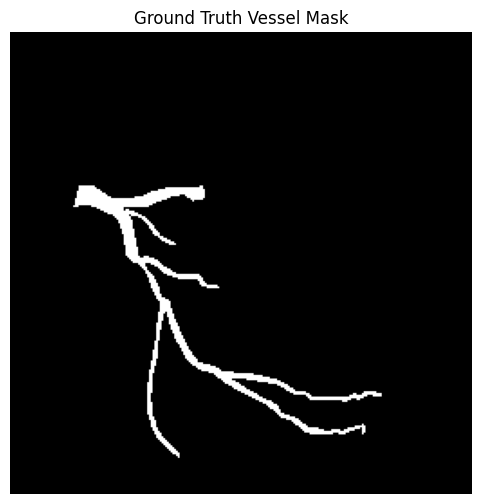

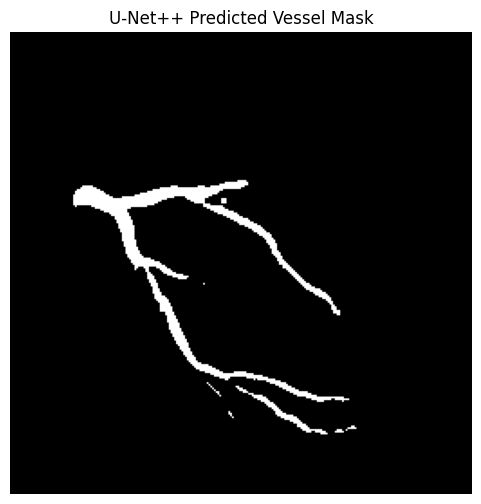


FINAL VALIDATION OF BEST MODEL

Final Validation Loss : 0.1594
Final Validation Dice : 0.7868
Final Validation IoU  : 0.6552

CREATING MODEL 3 PICKLE FILE

Loading PKL back for verification...
✅ PKL successfully reloaded

Reconstructing U-Net++ from PKL...
✅ Model successfully reconstructed from PKL weights

Reconstructed model output shape: (1, 1, 256, 256)
✅ PKL MODEL VERIFICATION PASSED

MODEL 3 — FINAL RESULTS

MODEL:
U-Net++ + ResNet34

DATASET:
ARCADE Syntax

TRAINING IMAGES:
1000

VALIDATION IMAGES:
200

BEST EPOCH:
2

BEST VALIDATION DICE:
0.7868

BEST VALIDATION IoU:
0.6552

BEST VALIDATION LOSS:
0.1594

PTH SIZE:
298.80 MB

PKL SIZE:
99.68 MB

PTH FILE:
/content/best_unetplusplus_resnet34_arcade.pth

PKL FILE:
/content/unetplusplus_resnet34_arcade_model.pkl

DOWNLOADING MODEL 3 .PTH


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


DOWNLOADING MODEL 3 .PKL

PKL file exists: True
PKL file size: 99.68 MB

Starting PKL download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


🎉 MODEL 3 — U-NET++ COMPLETED SUCCESSFULLY

✅ ARCADE DATASET LOADED
✅ U-NET++ + RESNET34 CREATED
✅ FORWARD PASS VERIFIED
✅ 10-EPOCH TRAINING COMPLETED
✅ BEST VALIDATION CHECKPOINT SAVED
✅ DICE CALCULATED
✅ IoU CALCULATED
✅ PREDICTIONS VISUALIZED
✅ PKL CREATED
✅ PKL RELOADED AND VERIFIED
✅ PTH DOWNLOAD REQUEST SENT
✅ PKL DOWNLOAD REQUEST SENT

DOWNLOAD THESE TWO FILES:
1. best_unetplusplus_resnet34_arcade.pth
2. unetplusplus_resnet34_arcade_model.pkl

MODEL 3 FINISHED


In [ ]:
# ============================================================
# MODEL 3 — U-NET++ + PRETRAINED RESNET34
# ARCADE CORONARY VESSEL SEGMENTATION
# COMPLETE SINGLE-CELL GOOGLE COLAB CODE
#
# SAME EXPERIMENTAL SETUP AS MODEL 1 & MODEL 2
# Device     : CPU
# Image size : 256 x 256
# Batch size : 2
# Epochs     : 10
# Encoder    : ResNet34 (ImageNet pretrained)
# Loss       : BCE + Dice
# Metrics    : Dice + IoU
#
# OUTPUTS:
# 1. best_unetplusplus_resnet34_arcade.pth
# 2. unetplusplus_resnet34_arcade_model.pkl
#
# BOTH ARE DOWNLOADED AT THE END
# NO GOOGLE DRIVE
# ============================================================


# ============================================================
# 0. INSTALL REQUIRED PACKAGES
# ============================================================

print("=" * 70)
print("INSTALLING REQUIRED PACKAGES")
print("=" * 70)

!pip install -q segmentation-models-pytorch pycocotools

print("✅ Required packages installed")


# ============================================================
# 1. IMPORTS
# ============================================================

import os
import json
import glob
import time
import random
import pickle
import zipfile
import gc

import numpy as np
import cv2
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader

import segmentation_models_pytorch as smp

from pycocotools import mask as maskUtils

from google.colab import files


# ============================================================
# 2. CONFIGURATION
# ============================================================

DEVICE = torch.device("cpu")

IMG_SIZE = 256

BATCH_SIZE = 2

EPOCHS = 10

LEARNING_RATE = 1e-4

WEIGHT_DECAY = 1e-5

SEED = 42

SEARCH_ROOT = "/content"

BEST_MODEL = (
    "/content/"
    "best_unetplusplus_resnet34_arcade.pth"
)

PKL_MODEL = (
    "/content/"
    "unetplusplus_resnet34_arcade_model.pkl"
)

CHECKPOINT_DIR = (
    "/content/"
    "unetplusplus_resnet34_checkpoints"
)

os.makedirs(
    CHECKPOINT_DIR,
    exist_ok=True
)


# ============================================================
# 3. CPU SETTINGS
# ============================================================

CPU_THREADS = max(
    1,
    min(
        2,
        os.cpu_count() or 1
    )
)

torch.set_num_threads(
    CPU_THREADS
)


# ============================================================
# 4. RANDOM SEED
# ============================================================

random.seed(SEED)

np.random.seed(SEED)

torch.manual_seed(SEED)


print("\n" + "=" * 70)

print(
    "MODEL 3 — U-NET++ + RESNET34"
)

print("=" * 70)

print(
    "Device        :",
    DEVICE
)

print(
    "CPU threads   :",
    CPU_THREADS
)

print(
    "Image size    :",
    IMG_SIZE
)

print(
    "Batch size    :",
    BATCH_SIZE
)

print(
    "Epochs        :",
    EPOCHS
)

print(
    "Learning rate :",
    LEARNING_RATE
)


# ============================================================
# 5. FIND ARCADE DATASET
# ============================================================

print("\n" + "=" * 70)

print(
    "SEARCHING FOR ARCADE DATASET"
)

print("=" * 70)


def find_arcade_annotations():

    train_files = []

    val_files = []

    for root, dirs, filenames in os.walk(
        SEARCH_ROOT
    ):

        for filename in filenames:

            # ------------------------------------------------
            # TRAIN JSON
            # ------------------------------------------------

            if filename.lower() == "train.json":

                path = os.path.join(
                    root,
                    filename
                )

                normalized = (
                    path
                    .replace(
                        "\\",
                        "/"
                    )
                    .lower()
                )

                if (
                    "/syntax/" in normalized
                    and
                    "/annotations/" in normalized
                ):

                    train_files.append(
                        path
                    )

            # ------------------------------------------------
            # VALIDATION JSON
            # ------------------------------------------------

            elif filename.lower() == "val.json":

                path = os.path.join(
                    root,
                    filename
                )

                normalized = (
                    path
                    .replace(
                        "\\",
                        "/"
                    )
                    .lower()
                )

                if (
                    "/syntax/" in normalized
                    and
                    "/annotations/" in normalized
                ):

                    val_files.append(
                        path
                    )

    return (
        train_files,
        val_files
    )


train_candidates, val_candidates = (
    find_arcade_annotations()
)


# ============================================================
# 6. SEARCH EXISTING ZIP IF DATASET NOT EXTRACTED
# ============================================================

if (
    len(train_candidates) == 0
    or
    len(val_candidates) == 0
):

    print(
        "\n⚠️ Extracted ARCADE dataset not found."
    )

    print(
        "Searching for existing ZIP file..."
    )

    zip_candidates = []

    for root, dirs, filenames in os.walk(
        SEARCH_ROOT
    ):

        for filename in filenames:

            if filename.lower().endswith(
                ".zip"
            ):

                zip_candidates.append(
                    os.path.join(
                        root,
                        filename
                    )
                )

    # --------------------------------------------------------
    # Prefer likely ARCADE ZIP
    # --------------------------------------------------------

    preferred_zips = [

        path

        for path in zip_candidates

        if (
            "arcade"
            in os.path.basename(path).lower()

            or

            "angiography"
            in os.path.basename(path).lower()

            or

            "archive"
            in os.path.basename(path).lower()
        )
    ]

    if len(preferred_zips) > 0:

        DATASET_ZIP = (
            preferred_zips[0]
        )

        print(
            "\n✅ Dataset ZIP found:"
        )

        print(
            DATASET_ZIP
        )

        print(
            "\nExtracting..."
        )

        with zipfile.ZipFile(
            DATASET_ZIP,
            "r"
        ) as zip_ref:

            zip_ref.extractall(
                SEARCH_ROOT
            )

        print(
            "✅ ZIP extracted"
        )

        train_candidates, val_candidates = (
            find_arcade_annotations()
        )


# ============================================================
# 7. UPLOAD DATASET IF NECESSARY
# ============================================================

if (
    len(train_candidates) == 0
    or
    len(val_candidates) == 0
):

    print("\n" + "=" * 70)

    print(
        "ARCADE DATASET UPLOAD REQUIRED"
    )

    print("=" * 70)

    print(
        "\nUpload your ARCADE dataset ZIP."
    )

    print(
        "You can select archive (1).zip."
    )

    uploaded = files.upload()

    uploaded_zip = None

    for filename in uploaded.keys():

        if filename.lower().endswith(
            ".zip"
        ):

            uploaded_zip = (
                "/content/"
                + filename
            )

            break

    if uploaded_zip is None:

        raise RuntimeError(
            "❌ No ZIP file was uploaded."
        )

    print(
        "\n✅ Uploaded:"
    )

    print(
        uploaded_zip
    )

    print(
        "\nExtracting dataset..."
    )

    with zipfile.ZipFile(
        uploaded_zip,
        "r"
    ) as zip_ref:

        zip_ref.extractall(
            SEARCH_ROOT
        )

    print(
        "✅ Dataset extracted"
    )

    train_candidates, val_candidates = (
        find_arcade_annotations()
    )


# ============================================================
# 8. VERIFY DATASET
# ============================================================

if len(train_candidates) == 0:

    raise RuntimeError(
        "❌ ARCADE syntax train.json not found."
    )

if len(val_candidates) == 0:

    raise RuntimeError(
        "❌ ARCADE syntax val.json not found."
    )


TRAIN_JSON = (
    train_candidates[0]
)

VAL_JSON = (
    val_candidates[0]
)


print("\n" + "=" * 70)

print(
    "✅ ARCADE DATASET FOUND"
)

print("=" * 70)

print(
    "\nTraining JSON:"
)

print(
    TRAIN_JSON
)

print(
    "\nValidation JSON:"
)

print(
    VAL_JSON
)


# ============================================================
# 9. ARCADE DATASET CLASS
# ============================================================

class ARCADEDataset(
    Dataset
):

    def __init__(
        self,
        annotation_file,
        image_root,
        img_size=256
    ):

        # ----------------------------------------------------
        # Read COCO JSON
        # ----------------------------------------------------

        with open(
            annotation_file,
            "r"
        ) as f:

            self.coco = json.load(
                f
            )

        self.image_root = (
            image_root
        )

        self.img_size = (
            img_size
        )

        self.images = (
            self.coco["images"]
        )

        self.annotations = (
            self.coco["annotations"]
        )

        # ----------------------------------------------------
        # Annotation mapping
        # ----------------------------------------------------

        self.ann_map = {}

        for ann in self.annotations:

            image_id = (
                ann["image_id"]
            )

            if image_id not in self.ann_map:

                self.ann_map[
                    image_id
                ] = []

            self.ann_map[
                image_id
            ].append(
                ann
            )

        # ----------------------------------------------------
        # Create image basename index once
        #
        # Faster than recursive glob for every image.
        # ----------------------------------------------------

        basename_index = {}

        for root, dirs, filenames in os.walk(
            image_root
        ):

            for filename in filenames:

                lower_name = filename.lower()

                if lower_name.endswith(
                    (
                        ".png",
                        ".jpg",
                        ".jpeg",
                        ".bmp",
                        ".tif",
                        ".tiff"
                    )
                ):

                    if filename not in basename_index:

                        basename_index[
                            filename
                        ] = os.path.join(
                            root,
                            filename
                        )

        # ----------------------------------------------------
        # Match COCO images
        # ----------------------------------------------------

        self.image_paths = {}

        for img in self.images:

            file_name = (
                img["file_name"]
            )

            basename = os.path.basename(
                file_name
            )

            if basename in basename_index:

                self.image_paths[
                    img["id"]
                ] = basename_index[
                    basename
                ]

        # ----------------------------------------------------
        # Keep only available images
        # ----------------------------------------------------

        self.images = [

            img

            for img in self.images

            if img["id"]
            in self.image_paths

        ]

        print(
            f"Dataset loaded: "
            f"{len(self.images)} images | "
            f"{len(self.annotations)} annotations"
        )

    def __len__(
        self
    ):

        return len(
            self.images
        )

    def __getitem__(
        self,
        index
    ):

        img_info = (
            self.images[index]
        )

        image_id = (
            img_info["id"]
        )

        image_path = (
            self.image_paths[
                image_id
            ]
        )

        # ====================================================
        # READ IMAGE
        # ====================================================

        image = cv2.imread(
            image_path
        )

        if image is None:

            raise RuntimeError(
                "Could not read image: "
                + image_path
            )

        image = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )

        original_h, original_w = (
            image.shape[:2]
        )

        # ====================================================
        # CREATE BINARY VESSEL MASK
        #
        # All syntax categories are merged:
        #
        # 0 = background
        # 1 = coronary vessel
        # ====================================================

        mask = np.zeros(
            (
                original_h,
                original_w
            ),
            dtype=np.uint8
        )

        anns = (
            self.ann_map.get(
                image_id,
                []
            )
        )

        for ann in anns:

            segmentation = (
                ann.get(
                    "segmentation"
                )
            )

            if segmentation is None:

                continue

            try:

                # ============================================
                # POLYGON FORMAT
                # ============================================

                if isinstance(
                    segmentation,
                    list
                ):

                    for polygon in segmentation:

                        if len(
                            polygon
                        ) < 6:

                            continue

                        points = np.array(
                            polygon,
                            dtype=np.float32
                        ).reshape(
                            -1,
                            2
                        )

                        points[:, 0] = np.clip(
                            points[:, 0],
                            0,
                            original_w - 1
                        )

                        points[:, 1] = np.clip(
                            points[:, 1],
                            0,
                            original_h - 1
                        )

                        points = points.astype(
                            np.int32
                        )

                        cv2.fillPoly(
                            mask,
                            [points],
                            1
                        )

                # ============================================
                # RLE FORMAT
                # ============================================

                elif isinstance(
                    segmentation,
                    dict
                ):

                    rle = segmentation

                    if isinstance(
                        rle.get(
                            "counts"
                        ),
                        list
                    ):

                        rle = (
                            maskUtils.frPyObjects(
                                rle,
                                original_h,
                                original_w
                            )
                        )

                    decoded = (
                        maskUtils.decode(
                            rle
                        )
                    )

                    if decoded.ndim == 3:

                        decoded = np.any(
                            decoded,
                            axis=2
                        )

                    mask[
                        decoded > 0
                    ] = 1

            except Exception:

                continue

        # ====================================================
        # RESIZE
        # ====================================================

        image = cv2.resize(
            image,
            (
                self.img_size,
                self.img_size
            ),
            interpolation=cv2.INTER_AREA
        )

        mask = cv2.resize(
            mask,
            (
                self.img_size,
                self.img_size
            ),
            interpolation=cv2.INTER_NEAREST
        )

        # ====================================================
        # NORMALIZATION
        # ====================================================

        image = (
            image.astype(
                np.float32
            )
            /
            255.0
        )

        mean = np.array(
            [
                0.485,
                0.456,
                0.406
            ],
            dtype=np.float32
        )

        std = np.array(
            [
                0.229,
                0.224,
                0.225
            ],
            dtype=np.float32
        )

        image = (
            image
            -
            mean
        ) / std

        # ====================================================
        # HWC -> CHW
        # ====================================================

        image = np.transpose(
            image,
            (
                2,
                0,
                1
            )
        )

        image = torch.from_numpy(
            image
        ).float()

        # ====================================================
        # MASK
        # ====================================================

        mask = torch.from_numpy(
            mask
        ).float().unsqueeze(
            0
        )

        return (
            image,
            mask
        )


# ============================================================
# 10. CREATE DATASETS
# ============================================================

print("\n" + "=" * 70)

print(
    "CREATING DATASETS"
)

print("=" * 70)


train_dataset = ARCADEDataset(
    TRAIN_JSON,
    SEARCH_ROOT,
    IMG_SIZE
)

val_dataset = ARCADEDataset(
    VAL_JSON,
    SEARCH_ROOT,
    IMG_SIZE
)


print(
    "\nTrain samples:",
    len(train_dataset)
)

print(
    "Validation samples:",
    len(val_dataset)
)


if len(train_dataset) == 0:

    raise RuntimeError(
        "❌ No training images found."
    )

if len(val_dataset) == 0:

    raise RuntimeError(
        "❌ No validation images found."
    )


# ============================================================
# 11. DATA LOADERS
# ============================================================

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)


print(
    "\n✅ DataLoaders ready"
)


# ============================================================
# 12. CREATE MODEL 3
# U-NET++ + PRETRAINED RESNET34
# ============================================================

print("\n" + "=" * 70)

print(
    "CREATING MODEL 3 — U-NET++ + RESNET34"
)

print("=" * 70)

print(
    "\nLoading ImageNet pretrained ResNet34 encoder..."
)


model = smp.UnetPlusPlus(

    encoder_name="resnet34",

    encoder_weights="imagenet",

    in_channels=3,

    classes=1,

    activation=None
)


model = model.to(
    DEVICE
)


# ============================================================
# 13. MODEL INFORMATION
# ============================================================

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)


print(
    "\nTotal parameters:",
    f"{total_params:,}"
)

print(
    "Trainable parameters:",
    f"{trainable_params:,}"
)

print(
    "\n✅ U-Net++ + ResNet34 created"
)


# ============================================================
# 14. FORWARD PASS TEST
#
# IMPORTANT:
# Verify architecture BEFORE spending time training.
# ============================================================

print("\n" + "=" * 70)

print(
    "TESTING FORWARD PASS"
)

print("=" * 70)


test_images, test_masks = next(
    iter(
        train_loader
    )
)


print(
    "\nInput shape :",
    tuple(
        test_images.shape
    )
)

print(
    "Target shape:",
    tuple(
        test_masks.shape
    )
)


model.eval()


with torch.no_grad():

    test_output = model(
        test_images.to(
            DEVICE
        )
    )


print(
    "Output shape:",
    tuple(
        test_output.shape
    )
)


if (
    test_output.shape
    !=
    test_masks.shape
):

    raise RuntimeError(
        "\n❌ Forward pass failed because "
        "output shape does not match target shape."
    )


print(
    "\n✅ FORWARD PASS SUCCESSFUL"
)

print(
    "✅ MODEL 3 ARCHITECTURE VERIFIED"
)


del test_images
del test_masks
del test_output

gc.collect()


# ============================================================
# 15. LOSS
# BCE + DICE
# ============================================================

bce_loss_function = (
    nn.BCEWithLogitsLoss()
)


def dice_loss(
    logits,
    targets,
    smooth=1.0
):

    probabilities = torch.sigmoid(
        logits
    )

    probabilities = (
        probabilities
        .contiguous()
        .view(-1)
    )

    targets_flat = (
        targets
        .contiguous()
        .view(-1)
    )

    intersection = (
        probabilities
        *
        targets_flat
    ).sum()

    dice = (
        (
            2.0
            *
            intersection
        )
        +
        smooth
    ) / (
        probabilities.sum()
        +
        targets_flat.sum()
        +
        smooth
    )

    return (
        1.0
        -
        dice
    )


def combined_loss(
    logits,
    targets
):

    bce = (
        bce_loss_function(
            logits,
            targets
        )
    )

    dice = (
        dice_loss(
            logits,
            targets
        )
    )

    return (
        0.5 * bce
        +
        0.5 * dice
    )


# ============================================================
# 16. DICE AND IOU METRICS
# ============================================================

def calculate_metrics(
    logits,
    targets,
    threshold=0.5,
    smooth=1e-6
):

    probabilities = torch.sigmoid(
        logits
    )

    predictions = (
        probabilities
        >
        threshold
    ).float()

    predictions = predictions.reshape(
        predictions.size(0),
        -1
    )

    targets_flat = targets.reshape(
        targets.size(0),
        -1
    )

    intersection = (
        predictions
        *
        targets_flat
    ).sum(
        dim=1
    )

    prediction_sum = (
        predictions.sum(
            dim=1
        )
    )

    target_sum = (
        targets_flat.sum(
            dim=1
        )
    )

    # --------------------------------------------------------
    # DICE
    # --------------------------------------------------------

    dice = (
        (
            2.0
            *
            intersection
        )
        +
        smooth
    ) / (
        prediction_sum
        +
        target_sum
        +
        smooth
    )

    # --------------------------------------------------------
    # IOU
    # --------------------------------------------------------

    union = (
        prediction_sum
        +
        target_sum
        -
        intersection
    )

    iou = (
        intersection
        +
        smooth
    ) / (
        union
        +
        smooth
    )

    return (
        dice.mean().item(),
        iou.mean().item()
    )


# ============================================================
# 17. OPTIMIZER
# ============================================================

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)


# ============================================================
# 18. LEARNING RATE SCHEDULER
# ============================================================

scheduler = (
    torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=2
    )
)


# ============================================================
# 19. TRAIN ONE EPOCH
# ============================================================

def train_one_epoch():

    model.train()

    running_loss = 0.0

    running_dice = 0.0

    running_iou = 0.0

    total_samples = 0


    for batch_index, (
        images,
        masks
    ) in enumerate(
        train_loader
    ):

        images = images.to(
            DEVICE
        )

        masks = masks.to(
            DEVICE
        )

        # ----------------------------------------------------
        # Reset gradients
        # ----------------------------------------------------

        optimizer.zero_grad(
            set_to_none=True
        )

        # ----------------------------------------------------
        # Forward
        # ----------------------------------------------------

        outputs = model(
            images
        )

        # ----------------------------------------------------
        # Loss
        # ----------------------------------------------------

        loss = combined_loss(
            outputs,
            masks
        )

        # ----------------------------------------------------
        # Backward
        # ----------------------------------------------------

        loss.backward()

        # ----------------------------------------------------
        # Update weights
        # ----------------------------------------------------

        optimizer.step()

        # ----------------------------------------------------
        # Metrics
        # ----------------------------------------------------

        dice, iou = calculate_metrics(
            outputs.detach(),
            masks
        )

        current_batch_size = (
            images.size(0)
        )

        running_loss += (
            loss.item()
            *
            current_batch_size
        )

        running_dice += (
            dice
            *
            current_batch_size
        )

        running_iou += (
            iou
            *
            current_batch_size
        )

        total_samples += (
            current_batch_size
        )


    return (

        running_loss
        /
        total_samples,

        running_dice
        /
        total_samples,

        running_iou
        /
        total_samples
    )


# ============================================================
# 20. VALIDATION
# ============================================================

@torch.no_grad()
def validate():

    model.eval()

    running_loss = 0.0

    running_dice = 0.0

    running_iou = 0.0

    total_samples = 0


    for images, masks in val_loader:

        images = images.to(
            DEVICE
        )

        masks = masks.to(
            DEVICE
        )

        # ----------------------------------------------------
        # Forward
        # ----------------------------------------------------

        outputs = model(
            images
        )

        # ----------------------------------------------------
        # Loss
        # ----------------------------------------------------

        loss = combined_loss(
            outputs,
            masks
        )

        # ----------------------------------------------------
        # Metrics
        # ----------------------------------------------------

        dice, iou = calculate_metrics(
            outputs,
            masks
        )

        current_batch_size = (
            images.size(0)
        )

        running_loss += (
            loss.item()
            *
            current_batch_size
        )

        running_dice += (
            dice
            *
            current_batch_size
        )

        running_iou += (
            iou
            *
            current_batch_size
        )

        total_samples += (
            current_batch_size
        )


    return (

        running_loss
        /
        total_samples,

        running_dice
        /
        total_samples,

        running_iou
        /
        total_samples
    )


# ============================================================
# 21. TRAIN MODEL 3
# ============================================================

print("\n" + "=" * 70)

print(
    "STARTING MODEL 3 TRAINING"
)

print("=" * 70)


history = {

    "train_loss": [],

    "train_dice": [],

    "train_iou": [],

    "val_loss": [],

    "val_dice": [],

    "val_iou": []
}


best_val_dice = -1.0

training_start_time = (
    time.time()
)


for epoch in range(
    1,
    EPOCHS + 1
):

    epoch_start_time = (
        time.time()
    )

    # ========================================================
    # TRAIN
    # ========================================================

    (
        train_loss,
        train_dice,
        train_iou
    ) = train_one_epoch()

    # ========================================================
    # VALIDATE
    # ========================================================

    (
        val_loss,
        val_dice,
        val_iou
    ) = validate()

    # ========================================================
    # SCHEDULER
    # ========================================================

    scheduler.step(
        val_dice
    )

    current_lr = (
        optimizer
        .param_groups[0]["lr"]
    )

    # ========================================================
    # HISTORY
    # ========================================================

    history[
        "train_loss"
    ].append(
        train_loss
    )

    history[
        "train_dice"
    ].append(
        train_dice
    )

    history[
        "train_iou"
    ].append(
        train_iou
    )

    history[
        "val_loss"
    ].append(
        val_loss
    )

    history[
        "val_dice"
    ].append(
        val_dice
    )

    history[
        "val_iou"
    ].append(
        val_iou
    )


    epoch_time = (
        time.time()
        -
        epoch_start_time
    )


    # ========================================================
    # DISPLAY EPOCH RESULTS
    # ========================================================

    print(
        "\n" + "-" * 70
    )

    print(
        f"Epoch [{epoch}/{EPOCHS}]"
    )

    print(
        f"Time       : "
        f"{epoch_time / 60:.2f} min"
    )

    print(
        f"Train Loss : "
        f"{train_loss:.4f}"
    )

    print(
        f"Train Dice : "
        f"{train_dice:.4f}"
    )

    print(
        f"Train IoU  : "
        f"{train_iou:.4f}"
    )

    print(
        f"Val Loss   : "
        f"{val_loss:.4f}"
    )

    print(
        f"Val Dice   : "
        f"{val_dice:.4f}"
    )

    print(
        f"Val IoU    : "
        f"{val_iou:.4f}"
    )

    print(
        f"LR         : "
        f"{current_lr:.7f}"
    )


    # ========================================================
    # SAVE CURRENT EPOCH CHECKPOINT
    # ========================================================

    epoch_checkpoint = os.path.join(
        CHECKPOINT_DIR,
        f"epoch_{epoch}.pth"
    )


    torch.save(

        {
            "model_number":
                3,

            "model_name":
                "U-Net++ + ResNet34",

            "epoch":
                epoch,

            "model_state_dict":
                model.state_dict(),

            "optimizer_state_dict":
                optimizer.state_dict(),

            "train_loss":
                train_loss,

            "train_dice":
                train_dice,

            "train_iou":
                train_iou,

            "val_loss":
                val_loss,

            "val_dice":
                val_dice,

            "val_iou":
                val_iou,

            "history":
                history
        },

        epoch_checkpoint
    )


    # ========================================================
    # SAVE BEST MODEL
    # ========================================================

    if (
        val_dice
        >
        best_val_dice
    ):

        best_val_dice = (
            val_dice
        )


        torch.save(

            {
                "model_number":
                    3,

                "model_name":
                    "U-Net++ + ResNet34",

                "epoch":
                    epoch,

                "model_state_dict":
                    model.state_dict(),

                "optimizer_state_dict":
                    optimizer.state_dict(),

                "train_loss":
                    train_loss,

                "train_dice":
                    train_dice,

                "train_iou":
                    train_iou,

                "val_loss":
                    val_loss,

                "val_dice":
                    val_dice,

                "val_iou":
                    val_iou,

                "history":
                    history
            },

            BEST_MODEL
        )


        print(
            "⭐ NEW BEST MODEL SAVED"
        )


# ============================================================
# 22. TRAINING FINISHED
# ============================================================

total_training_time = (
    time.time()
    -
    training_start_time
)


print("\n" + "=" * 70)

print(
    "MODEL 3 TRAINING COMPLETE"
)

print("=" * 70)

print(
    f"\nTotal training time: "
    f"{total_training_time / 60:.2f} minutes"
)


# ============================================================
# 23. LOAD BEST MODEL
# ============================================================

print(
    "\nLoading best U-Net++ checkpoint..."
)


best_checkpoint = torch.load(
    BEST_MODEL,
    map_location=DEVICE,
    weights_only=False
)


model.load_state_dict(
    best_checkpoint[
        "model_state_dict"
    ]
)


model.eval()


print(
    "✅ Best model loaded"
)


# ============================================================
# 24. BEST MODEL INFORMATION
# ============================================================

print("\n" + "=" * 70)

print(
    "BEST MODEL 3 RESULTS"
)

print("=" * 70)


print(
    "\nBest Epoch:"
)

print(
    best_checkpoint[
        "epoch"
    ]
)


print(
    "\nBest Validation Dice:"
)

print(
    f"{best_checkpoint['val_dice']:.4f}"
)


print(
    "\nBest Validation IoU:"
)

print(
    f"{best_checkpoint['val_iou']:.4f}"
)


# ============================================================
# 25. TRAINING CURVES
# ============================================================

epochs_axis = range(
    1,
    len(
        history["train_loss"]
    )
    + 1
)


# ------------------------------------------------------------
# LOSS
# ------------------------------------------------------------

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    epochs_axis,
    history[
        "train_loss"
    ],
    marker="o",
    label="Train Loss"
)

plt.plot(
    epochs_axis,
    history[
        "val_loss"
    ],
    marker="o",
    label="Validation Loss"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Loss"
)

plt.title(
    "Model 3 — U-Net++ Loss"
)

plt.legend()

plt.grid(
    True
)

plt.show()


# ------------------------------------------------------------
# DICE
# ------------------------------------------------------------

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    epochs_axis,
    history[
        "train_dice"
    ],
    marker="o",
    label="Train Dice"
)

plt.plot(
    epochs_axis,
    history[
        "val_dice"
    ],
    marker="o",
    label="Validation Dice"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Dice Score"
)

plt.title(
    "Model 3 — U-Net++ Dice"
)

plt.legend()

plt.grid(
    True
)

plt.show()


# ------------------------------------------------------------
# IOU
# ------------------------------------------------------------

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    epochs_axis,
    history[
        "train_iou"
    ],
    marker="o",
    label="Train IoU"
)

plt.plot(
    epochs_axis,
    history[
        "val_iou"
    ],
    marker="o",
    label="Validation IoU"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "IoU"
)

plt.title(
    "Model 3 — U-Net++ IoU"
)

plt.legend()

plt.grid(
    True
)

plt.show()


# ============================================================
# 26. SAMPLE PREDICTIONS
# ============================================================

@torch.no_grad()
def show_predictions(
    dataset,
    num_images=3
):

    model.eval()

    num_images = min(
        num_images,
        len(dataset)
    )

    indices = random.sample(
        range(
            len(dataset)
        ),
        num_images
    )


    for index in indices:

        image_tensor, mask_tensor = (
            dataset[index]
        )


        output = model(

            image_tensor
            .unsqueeze(0)
            .to(DEVICE)

        )


        probability = torch.sigmoid(
            output
        )[0, 0].cpu().numpy()


        prediction = (
            probability
            >
            0.5
        ).astype(
            np.uint8
        )


        # ====================================================
        # RESTORE IMAGE FOR DISPLAY
        # ====================================================

        display_image = (

            image_tensor
            .cpu()
            .numpy()
            .transpose(
                1,
                2,
                0
            )
        )


        mean = np.array(
            [
                0.485,
                0.456,
                0.406
            ]
        )


        std = np.array(
            [
                0.229,
                0.224,
                0.225
            ]
        )


        display_image = (
            display_image
            *
            std
            +
            mean
        )


        display_image = np.clip(
            display_image,
            0,
            1
        )


        ground_truth = (
            mask_tensor[
                0
            ].numpy()
        )


        # ====================================================
        # ORIGINAL
        # ====================================================

        plt.figure(
            figsize=(6, 6)
        )

        plt.imshow(
            display_image
        )

        plt.title(
            "Original Coronary Angiogram"
        )

        plt.axis(
            "off"
        )

        plt.show()


        # ====================================================
        # GROUND TRUTH
        # ====================================================

        plt.figure(
            figsize=(6, 6)
        )

        plt.imshow(
            ground_truth,
            cmap="gray"
        )

        plt.title(
            "Ground Truth Vessel Mask"
        )

        plt.axis(
            "off"
        )

        plt.show()


        # ====================================================
        # PREDICTION
        # ====================================================

        plt.figure(
            figsize=(6, 6)
        )

        plt.imshow(
            prediction,
            cmap="gray"
        )

        plt.title(
            "U-Net++ Predicted Vessel Mask"
        )

        plt.axis(
            "off"
        )

        plt.show()


print("\n" + "=" * 70)

print(
    "GENERATING MODEL 3 PREDICTIONS"
)

print("=" * 70)


show_predictions(
    val_dataset,
    num_images=3
)


# ============================================================
# 27. FINAL VALIDATION OF BEST CHECKPOINT
# ============================================================

print("\n" + "=" * 70)

print(
    "FINAL VALIDATION OF BEST MODEL"
)

print("=" * 70)


(
    final_val_loss,
    final_val_dice,
    final_val_iou
) = validate()


print(
    f"\nFinal Validation Loss : "
    f"{final_val_loss:.4f}"
)

print(
    f"Final Validation Dice : "
    f"{final_val_dice:.4f}"
)

print(
    f"Final Validation IoU  : "
    f"{final_val_iou:.4f}"
)


# ============================================================
# 28. MOVE BEST MODEL TO CPU
# ============================================================

model = model.to(
    "cpu"
)

model.eval()


# ============================================================
# 29. CREATE MODEL 3 PICKLE PACKAGE
#
# IMPORTANT:
# We save state_dict + architecture information.
# This is safer than pickling the live Python model object.
# ============================================================

print("\n" + "=" * 70)

print(
    "CREATING MODEL 3 PICKLE FILE"
)

print("=" * 70)


model_package = {

    # --------------------------------------------------------
    # Identity
    # --------------------------------------------------------

    "model_number":
        3,

    "model_name":
        "U-Net++ + ResNet34",

    "model_type":
        "UnetPlusPlus",

    "library":
        "segmentation_models_pytorch",

    # --------------------------------------------------------
    # Architecture
    # --------------------------------------------------------

    "architecture":
        "U-Net++ with ImageNet pretrained ResNet34 encoder",

    "encoder_name":
        "resnet34",

    "encoder_pretrained":
        True,

    "input_channels":
        3,

    "output_channels":
        1,

    # --------------------------------------------------------
    # Dataset
    # --------------------------------------------------------

    "dataset":
        "ARCADE",

    "dataset_subset":
        "syntax",

    "task":
        "Binary Coronary Vessel Segmentation",

    # --------------------------------------------------------
    # Input
    # --------------------------------------------------------

    "image_size":
        IMG_SIZE,

    # --------------------------------------------------------
    # Training configuration
    # --------------------------------------------------------

    "batch_size":
        BATCH_SIZE,

    "epochs":
        EPOCHS,

    "learning_rate":
        LEARNING_RATE,

    "weight_decay":
        WEIGHT_DECAY,

    "loss":
        "0.5 BCEWithLogitsLoss + 0.5 Dice Loss",

    # --------------------------------------------------------
    # Preprocessing
    # --------------------------------------------------------

    "preprocessing":

        {
            "resize":
                [
                    IMG_SIZE,
                    IMG_SIZE
                ],

            "normalization_mean":
                [
                    0.485,
                    0.456,
                    0.406
                ],

            "normalization_std":
                [
                    0.229,
                    0.224,
                    0.225
                ],

            "mask_threshold":
                0.5
        },

    # --------------------------------------------------------
    # Best results
    # --------------------------------------------------------

    "best_epoch":
        best_checkpoint[
            "epoch"
        ],

    "best_val_dice":
        best_checkpoint[
            "val_dice"
        ],

    "best_val_iou":
        best_checkpoint[
            "val_iou"
        ],

    "best_val_loss":
        best_checkpoint[
            "val_loss"
        ],

    # --------------------------------------------------------
    # Training history
    # --------------------------------------------------------

    "history":
        best_checkpoint[
            "history"
        ],

    # --------------------------------------------------------
    # TRAINED WEIGHTS
    # --------------------------------------------------------

    "model_state_dict":
        model.state_dict()
}


# ============================================================
# 30. SAVE PKL
# ============================================================

with open(
    PKL_MODEL,
    "wb"
) as file:

    pickle.dump(
        model_package,
        file,
        protocol=pickle.HIGHEST_PROTOCOL
    )


# ============================================================
# 31. VERIFY PKL BY LOADING IT BACK
# ============================================================

if not os.path.exists(
    PKL_MODEL
):

    raise RuntimeError(
        "❌ Model 3 PKL file was not created."
    )


print(
    "\nLoading PKL back for verification..."
)


with open(
    PKL_MODEL,
    "rb"
) as file:

    verification_package = pickle.load(
        file
    )


if (
    "model_state_dict"
    not in verification_package
):

    raise RuntimeError(
        "❌ PKL verification failed."
    )


print(
    "✅ PKL successfully reloaded"
)


# ============================================================
# 32. VERIFY MODEL CAN BE RECONSTRUCTED FROM PKL
# ============================================================

print(
    "\nReconstructing U-Net++ from PKL..."
)


verification_model = smp.UnetPlusPlus(

    encoder_name="resnet34",

    # No need to redownload ImageNet weights.
    # Trained weights are loaded below.

    encoder_weights=None,

    in_channels=3,

    classes=1,

    activation=None
)


verification_model.load_state_dict(
    verification_package[
        "model_state_dict"
    ]
)


verification_model.eval()


print(
    "✅ Model successfully reconstructed from PKL weights"
)


# ============================================================
# 33. TEST RECONSTRUCTED MODEL
# ============================================================

verification_image, _ = (
    val_dataset[0]
)


with torch.no_grad():

    verification_output = (
        verification_model(
            verification_image
            .unsqueeze(0)
        )
    )


print(
    "\nReconstructed model output shape:",
    tuple(
        verification_output.shape
    )
)


if (
    tuple(
        verification_output.shape
    )
    !=
    (
        1,
        1,
        IMG_SIZE,
        IMG_SIZE
    )
):

    raise RuntimeError(
        "❌ Reconstructed PKL model output is incorrect."
    )


print(
    "✅ PKL MODEL VERIFICATION PASSED"
)


# Free temporary model

del verification_model

del verification_package

gc.collect()


# ============================================================
# 34. FILE SIZE INFORMATION
# ============================================================

if not os.path.exists(
    BEST_MODEL
):

    raise RuntimeError(
        "❌ Best PTH checkpoint missing."
    )


pth_size_mb = (
    os.path.getsize(
        BEST_MODEL
    )
    /
    (
        1024
        *
        1024
    )
)


pkl_size_mb = (
    os.path.getsize(
        PKL_MODEL
    )
    /
    (
        1024
        *
        1024
    )
)


# ============================================================
# 35. FINAL MODEL 3 SUMMARY
# ============================================================

print("\n" + "=" * 70)

print(
    "MODEL 3 — FINAL RESULTS"
)

print("=" * 70)


print(
    "\nMODEL:"
)

print(
    "U-Net++ + ResNet34"
)


print(
    "\nDATASET:"
)

print(
    "ARCADE Syntax"
)


print(
    "\nTRAINING IMAGES:"
)

print(
    len(
        train_dataset
    )
)


print(
    "\nVALIDATION IMAGES:"
)

print(
    len(
        val_dataset
    )
)


print(
    "\nBEST EPOCH:"
)

print(
    best_checkpoint[
        "epoch"
    ]
)


print(
    "\nBEST VALIDATION DICE:"
)

print(
    f"{best_checkpoint['val_dice']:.4f}"
)


print(
    "\nBEST VALIDATION IoU:"
)

print(
    f"{best_checkpoint['val_iou']:.4f}"
)


print(
    "\nBEST VALIDATION LOSS:"
)

print(
    f"{best_checkpoint['val_loss']:.4f}"
)


print(
    "\nPTH SIZE:"
)

print(
    f"{pth_size_mb:.2f} MB"
)


print(
    "\nPKL SIZE:"
)

print(
    f"{pkl_size_mb:.2f} MB"
)


print(
    "\nPTH FILE:"
)

print(
    BEST_MODEL
)


print(
    "\nPKL FILE:"
)

print(
    PKL_MODEL
)


# ============================================================
# 36. DOWNLOAD PTH
# ============================================================

print("\n" + "=" * 70)

print(
    "DOWNLOADING MODEL 3 .PTH"
)

print("=" * 70)


files.download(
    BEST_MODEL
)


# ============================================================
# 37. DOWNLOAD PKL
#
# THIS IS PART OF THE SAME CODE.
# NO SEPARATE PKL CELL IS REQUIRED.
# ============================================================

print("\n" + "=" * 70)

print(
    "DOWNLOADING MODEL 3 .PKL"
)

print("=" * 70)


print(
    "\nPKL file exists:",
    os.path.exists(
        PKL_MODEL
    )
)

print(
    f"PKL file size: "
    f"{pkl_size_mb:.2f} MB"
)

print(
    "\nStarting PKL download..."
)


files.download(
    PKL_MODEL
)


# ============================================================
# 38. FINAL MESSAGE
# ============================================================

print("\n" + "=" * 70)

print(
    "🎉 MODEL 3 — U-NET++ COMPLETED SUCCESSFULLY"
)

print("=" * 70)


print(
    "\n✅ ARCADE DATASET LOADED"
)

print(
    "✅ U-NET++ + RESNET34 CREATED"
)

print(
    "✅ FORWARD PASS VERIFIED"
)

print(
    "✅ 10-EPOCH TRAINING COMPLETED"
)

print(
    "✅ BEST VALIDATION CHECKPOINT SAVED"
)

print(
    "✅ DICE CALCULATED"
)

print(
    "✅ IoU CALCULATED"
)

print(
    "✅ PREDICTIONS VISUALIZED"
)

print(
    "✅ PKL CREATED"
)

print(
    "✅ PKL RELOADED AND VERIFIED"
)

print(
    "✅ PTH DOWNLOAD REQUEST SENT"
)

print(
    "✅ PKL DOWNLOAD REQUEST SENT"
)


print(
    "\nDOWNLOAD THESE TWO FILES:"
)

print(
    "1. best_unetplusplus_resnet34_arcade.pth"
)

print(
    "2. unetplusplus_resnet34_arcade_model.pkl"
)


print("\n" + "=" * 70)

print(
    "MODEL 3 FINISHED"
)

print("=" * 70)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 12.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 5.6 MB/s eta 0:00:00
YOLOv8-Seg STENOSIS DETECTION

CPU threads: 2
Device: cpu

Searching for ARCADE stenosis dataset...

JSON files found:

⚠️ Stenosis dataset not found automatically.
Please upload your ARCADE dataset ZIP file.
The ZIP should contain the stenosis train/val folders.


Saving archive (1).zip to archive (1).zip

Uploaded: archive (1).zip
Dataset extracted to: /content/arcade_uploaded

Selected annotation files:
TRAIN: /content/arcade_uploaded/data/stenosis/train/annotations/train.json
VAL  : /content/arcade_uploaded/data/stenosis/val/annotations/val.json

TRAIN DATASET
--------------------------------------------------
Images: 1000
Annotations: 1625
Categories: 26

VAL DATASET
--------------------------------------------------
Images: 200
Annotations: 406
Categories: 26

STENOSIS CATEGORIES
--------------------------------------------------
ID: 1 | Name: 1
ID: 2 | Name: 2
ID: 3 | Name: 3
ID: 4 | Name: 4
ID: 5 | Name: 5
ID: 6 | Name: 6
ID: 7 | Name: 7
ID: 8 | Name: 8
ID: 9 | Name: 9
ID: 10 | Name: 9a
ID: 11 | Name: 10
ID: 12 | Name: 10a
ID: 13 | Name: 11
ID: 14 | Name: 12
ID: 15 | Name: 12a
ID: 16 | Name: 13
ID: 17 | Name: 14
ID: 18 | Name: 14a
ID: 19 | Name: 15
ID: 20 | Name: 16
ID: 21 | Name: 16a
ID: 22 | Name: 16b
ID: 23 | Name: 16c
ID: 24 | Name: 1

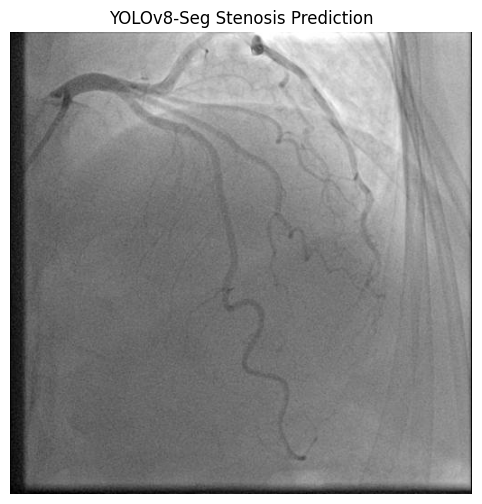

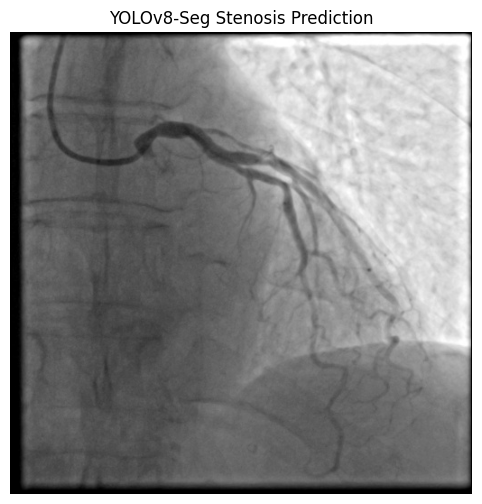

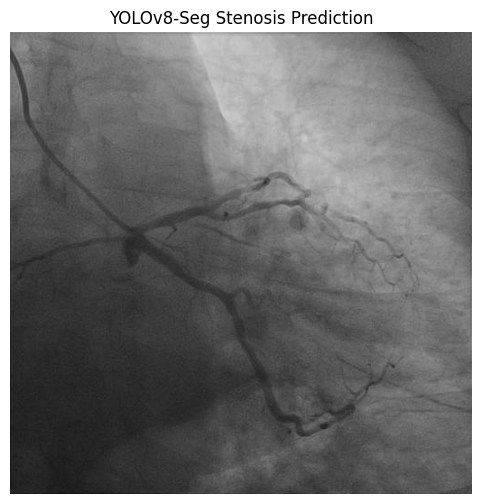

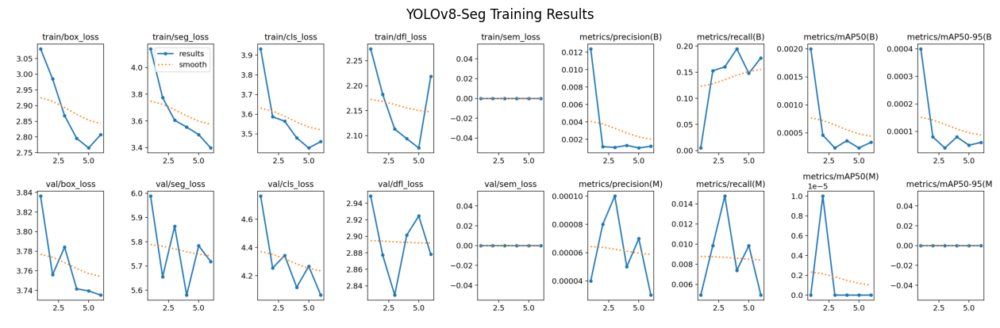


MODEL 4 / YOLOv8-Seg COMPLETED

BEST .PT MODEL:
/content/best_yolov8n_seg_arcade_stenosis.pt
Size: 6.699024200439453 MB

PKL MODEL:
/content/yolov8n_seg_arcade_stenosis_model.pkl
Size: 6.699841499328613 MB

RESULT JSON:
/content/yolov8n_seg_arcade_stenosis_results.json

Next step:
Integrate the selected U-Net++ vessel mask with YOLOv8-Seg stenosis detection.

Starting downloads...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✅ ALL DONE
YOLOv8-Seg .pt and .pkl files are ready.


In [ ]:
# ============================================================
# MODEL 4 / STENOSIS DETECTION
# YOLOv8n-Seg + ARCADE STENOSIS DATASET
# CPU TRAINING - COMPLETE SINGLE CELL
# ============================================================

# ------------------------------------------------------------
# 1. INSTALL REQUIRED LIBRARIES
# ------------------------------------------------------------
!pip -q install ultralytics pycocotools

import os
import json
import shutil
import pickle
import random
import glob
import time
import numpy as np
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

from google.colab import files

print("=" * 70)
print("YOLOv8-Seg STENOSIS DETECTION")
print("=" * 70)

# ------------------------------------------------------------
# 2. CPU SETTINGS
# ------------------------------------------------------------
import torch

torch.set_num_threads(2)

DEVICE = "cpu"

print("\nCPU threads:", torch.get_num_threads())
print("Device:", DEVICE)

# ------------------------------------------------------------
# 3. FIND ARCADE DATASET
# ------------------------------------------------------------

print("\nSearching for ARCADE stenosis dataset...")

possible_jsons = glob.glob(
    "/content/**/stenosis/**/annotations/*.json",
    recursive=True
)

# Remove unrelated JSON files
possible_jsons = [
    p for p in possible_jsons
    if "stenosis" in p.lower()
]

print("\nJSON files found:")

for p in possible_jsons:
    print(" ", p)

# ------------------------------------------------------------
# 4. IF DATASET IS NOT FOUND -> UPLOAD ZIP
# ------------------------------------------------------------

if len(possible_jsons) == 0:

    print("\n⚠️ Stenosis dataset not found automatically.")
    print("Please upload your ARCADE dataset ZIP file.")
    print("The ZIP should contain the stenosis train/val folders.")

    uploaded = files.upload()

    uploaded_name = list(uploaded.keys())[0]

    print("\nUploaded:", uploaded_name)

    # Extract ZIP
    if uploaded_name.lower().endswith(".zip"):

        import zipfile

        extract_dir = "/content/arcade_uploaded"

        os.makedirs(extract_dir, exist_ok=True)

        with zipfile.ZipFile(
            uploaded_name,
            "r"
        ) as zip_ref:

            zip_ref.extractall(extract_dir)

        print("Dataset extracted to:", extract_dir)

    else:
        raise RuntimeError(
            "Please upload the ARCADE dataset as a ZIP file."
        )

    # Search again
    possible_jsons = glob.glob(
        "/content/**/stenosis/**/annotations/*.json",
        recursive=True
    )

    possible_jsons = [
        p for p in possible_jsons
        if "stenosis" in p.lower()
    ]

# ------------------------------------------------------------
# 5. IDENTIFY TRAIN / VALIDATION JSON
# ------------------------------------------------------------

train_json = None
val_json = None

for p in possible_jsons:

    name = os.path.basename(p).lower()

    if "train" in name and train_json is None:
        train_json = p

    elif (
        ("val" in name or "valid" in name)
        and val_json is None
    ):
        val_json = p

print("\nSelected annotation files:")

print("TRAIN:", train_json)
print("VAL  :", val_json)

if train_json is None:
    raise FileNotFoundError(
        "Training stenosis JSON could not be found."
    )

if val_json is None:
    raise FileNotFoundError(
        "Validation stenosis JSON could not be found."
    )

# ------------------------------------------------------------
# 6. LOAD COCO JSON
# ------------------------------------------------------------

with open(train_json, "r") as f:
    train_coco = json.load(f)

with open(val_json, "r") as f:
    val_coco = json.load(f)

print("\nTRAIN DATASET")
print("-" * 50)

print(
    "Images:",
    len(train_coco.get("images", []))
)

print(
    "Annotations:",
    len(train_coco.get("annotations", []))
)

print(
    "Categories:",
    len(train_coco.get("categories", []))
)

print("\nVAL DATASET")
print("-" * 50)

print(
    "Images:",
    len(val_coco.get("images", []))
)

print(
    "Annotations:",
    len(val_coco.get("annotations", []))
)

print(
    "Categories:",
    len(val_coco.get("categories", []))
)

# ------------------------------------------------------------
# 7. DISPLAY ACTUAL STENOSIS CATEGORIES
# ------------------------------------------------------------

categories = train_coco.get("categories", [])

print("\nSTENOSIS CATEGORIES")
print("-" * 50)

for cat in categories:
    print(
        "ID:",
        cat["id"],
        "| Name:",
        cat["name"]
    )

# ------------------------------------------------------------
# 8. CREATE CATEGORY MAPPING
# ------------------------------------------------------------

# YOLO class IDs must start from 0

categories_sorted = sorted(
    categories,
    key=lambda x: x["id"]
)

category_id_to_yolo = {
    cat["id"]: idx
    for idx, cat in enumerate(categories_sorted)
}

class_names = [
    cat["name"]
    for cat in categories_sorted
]

print("\nYOLO CLASS MAPPING")
print("-" * 50)

for cat in categories_sorted:

    print(
        cat["id"],
        "->",
        category_id_to_yolo[cat["id"]],
        "->",
        cat["name"]
    )

# ------------------------------------------------------------
# 9. CREATE YOLO DATASET STRUCTURE
# ------------------------------------------------------------

YOLO_ROOT = "/content/arcade_stenosis_yolo"

if os.path.exists(YOLO_ROOT):
    shutil.rmtree(YOLO_ROOT)

os.makedirs(
    f"{YOLO_ROOT}/images/train",
    exist_ok=True
)

os.makedirs(
    f"{YOLO_ROOT}/images/val",
    exist_ok=True
)

os.makedirs(
    f"{YOLO_ROOT}/labels/train",
    exist_ok=True
)

os.makedirs(
    f"{YOLO_ROOT}/labels/val",
    exist_ok=True
)

print("\nYOLO dataset directory created:")
print(YOLO_ROOT)

# ------------------------------------------------------------
# 10. FIND IMAGE FOR COCO IMAGE RECORD
# ------------------------------------------------------------

def find_image_for_record(
    json_file,
    file_name
):

    json_dir = Path(json_file).parent

    # Candidate locations
    candidates = [

        json_dir / file_name,

        json_dir.parent / file_name,

        json_dir.parent.parent / file_name,

        Path(file_name),

    ]

    for candidate in candidates:

        if candidate.exists():
            return candidate

    # Search from stenosis directory
    parts = Path(json_file).parts

    stenosis_index = None

    for i, part in enumerate(parts):

        if part.lower() == "stenosis":
            stenosis_index = i

    if stenosis_index is not None:

        stenosis_root = Path(
            *parts[:stenosis_index + 1]
        )

        matches = list(
            stenosis_root.rglob(
                Path(file_name).name
            )
        )

        if len(matches) > 0:
            return matches[0]

    return None


# ------------------------------------------------------------
# 11. CONVERT COCO → YOLO SEGMENTATION
# ------------------------------------------------------------

def convert_coco_to_yolo(
    coco_data,
    json_path,
    split
):

    print("\nConverting", split, "dataset...")

    images = coco_data["images"]
    annotations = coco_data["annotations"]

    # Group annotations by image ID
    annotations_by_image = {}

    for ann in annotations:

        image_id = ann["image_id"]

        if image_id not in annotations_by_image:
            annotations_by_image[image_id] = []

        annotations_by_image[image_id].append(ann)

    converted = 0
    skipped = 0
    annotation_count = 0

    for img_info in images:

        image_id = img_info["id"]

        original_file_name = img_info["file_name"]

        source_image = find_image_for_record(
            json_path,
            original_file_name
        )

        if source_image is None:

            print(
                "⚠️ Image not found:",
                original_file_name
            )

            skipped += 1
            continue

        # Make safe unique image name
        image_name = Path(
            original_file_name
        ).name

        stem = Path(image_name).stem
        suffix = Path(image_name).suffix

        destination_image = (
            Path(YOLO_ROOT)
            / "images"
            / split
            / image_name
        )

        destination_label = (
            Path(YOLO_ROOT)
            / "labels"
            / split
            / f"{stem}.txt"
        )

        # Copy image
        shutil.copy2(
            source_image,
            destination_image
        )

        # Image dimensions
        width = float(
            img_info["width"]
        )

        height = float(
            img_info["height"]
        )

        lines = []

        anns = annotations_by_image.get(
            image_id,
            []
        )

        for ann in anns:

            category_id = ann.get(
                "category_id"
            )

            if category_id not in category_id_to_yolo:
                continue

            yolo_class = category_id_to_yolo[
                category_id
            ]

            segmentation = ann.get(
                "segmentation"
            )

            if segmentation is None:
                continue

            # ------------------------------------------------
            # POLYGON SEGMENTATION
            # ------------------------------------------------

            polygons = []

            if isinstance(
                segmentation,
                list
            ):

                polygons = segmentation

            # ------------------------------------------------
            # Handle polygon lists
            # ------------------------------------------------

            for polygon in polygons:

                if not isinstance(
                    polygon,
                    list
                ):
                    continue

                if len(polygon) < 6:
                    continue

                # Ensure even number of coordinates
                if len(polygon) % 2 != 0:
                    polygon = polygon[:-1]

                normalized = []

                for i in range(
                    0,
                    len(polygon),
                    2
                ):

                    x = float(
                        polygon[i]
                    )

                    y = float(
                        polygon[i + 1]
                    )

                    # Normalize
                    x = max(
                        0.0,
                        min(
                            1.0,
                            x / width
                        )
                    )

                    y = max(
                        0.0,
                        min(
                            1.0,
                            y / height
                        )
                    )

                    normalized.extend([
                        x,
                        y
                    ])

                if len(normalized) >= 6:

                    line = (
                        str(yolo_class)
                        + " "
                        + " ".join(
                            f"{v:.6f}"
                            for v in normalized
                        )
                    )

                    lines.append(line)

                    annotation_count += 1

        # Create label file
        with open(
            destination_label,
            "w"
        ) as f:

            f.write(
                "\n".join(lines)
            )

        converted += 1

    print(
        f"{split.upper()} conversion complete"
    )

    print(
        "Images copied:",
        converted
    )

    print(
        "Images skipped:",
        skipped
    )

    print(
        "Segmentation annotations:",
        annotation_count
    )


# ------------------------------------------------------------
# 12. CONVERT TRAIN + VALIDATION
# ------------------------------------------------------------

convert_coco_to_yolo(
    train_coco,
    train_json,
    "train"
)

convert_coco_to_yolo(
    val_coco,
    val_json,
    "val"
)

# ------------------------------------------------------------
# 13. VERIFY DATASET
# ------------------------------------------------------------

train_images = glob.glob(
    f"{YOLO_ROOT}/images/train/*"
)

val_images = glob.glob(
    f"{YOLO_ROOT}/images/val/*"
)

train_labels = glob.glob(
    f"{YOLO_ROOT}/labels/train/*.txt"
)

val_labels = glob.glob(
    f"{YOLO_ROOT}/labels/val/*.txt"
)

print("\nDATASET VERIFICATION")
print("=" * 60)

print(
    "Train images:",
    len(train_images)
)

print(
    "Train labels:",
    len(train_labels)
)

print(
    "Validation images:",
    len(val_images)
)

print(
    "Validation labels:",
    len(val_labels)
)

# ------------------------------------------------------------
# 14. CREATE DATA.YAML
# ------------------------------------------------------------

yaml_path = (
    f"{YOLO_ROOT}/data.yaml"
)

with open(
    yaml_path,
    "w"
) as f:

    f.write(
        f"path: {YOLO_ROOT}\n"
    )

    f.write(
        "train: images/train\n"
    )

    f.write(
        "val: images/val\n"
    )

    f.write(
        f"nc: {len(class_names)}\n"
    )

    f.write(
        "names:\n"
    )

    for i, name in enumerate(
        class_names
    ):

        f.write(
            f"  {i}: '{name}'\n"
        )

print("\nCreated:")
print(yaml_path)

# ------------------------------------------------------------
# 15. SHOW SAMPLE YOLO LABEL
# ------------------------------------------------------------

sample_labels = glob.glob(
    f"{YOLO_ROOT}/labels/train/*.txt"
)

if len(sample_labels) > 0:

    print("\nSAMPLE YOLO LABEL")
    print("-" * 60)

    with open(
        sample_labels[0],
        "r"
    ) as f:

        content = f.read()

    print(content[:2000])

# ------------------------------------------------------------
# 16. IMPORT YOLO
# ------------------------------------------------------------

from ultralytics import YOLO

print("\nUltralytics imported successfully.")

# ------------------------------------------------------------
# 17. LOAD PRETRAINED YOLOv8n-SEG
# ------------------------------------------------------------

print("\nLoading YOLOv8n-Seg pretrained model...")

model = YOLO(
    "yolov8n-seg.pt"
)

print("YOLOv8n-Seg loaded successfully.")

# ------------------------------------------------------------
# 18. TRAINING CONFIGURATION
# ------------------------------------------------------------

EPOCHS = 15
IMAGE_SIZE = 512
BATCH_SIZE = 2

print("\nTRAINING CONFIGURATION")
print("=" * 60)

print("Model       : YOLOv8n-Seg")
print("Task        : Instance Segmentation")
print("Dataset     : ARCADE Stenosis")
print("Device      : CPU")
print("Epochs      :", EPOCHS)
print("Image size  :", IMAGE_SIZE)
print("Batch size  :", BATCH_SIZE)
print("Workers     : 0")

# ------------------------------------------------------------
# 19. TRAIN MODEL
# ------------------------------------------------------------

start_time = time.time()

results = model.train(

    data=yaml_path,

    epochs=EPOCHS,

    imgsz=IMAGE_SIZE,

    batch=BATCH_SIZE,

    device=DEVICE,

    workers=0,

    patience=5,

    optimizer="AdamW",

    lr0=0.001,

    weight_decay=0.0005,

    pretrained=True,

    project="/content/yolov8_stenosis_training",

    name="yolov8n_seg_arcade_stenosis",

    exist_ok=True,

    save=True,

    save_period=-1,

    plots=True,

    verbose=True

)

training_time = (
    time.time()
    - start_time
)

print("\nTRAINING FINISHED")

print(
    f"Training time: "
    f"{training_time / 60:.2f} minutes"
)

# ------------------------------------------------------------
# 20. FIND BEST MODEL
# ------------------------------------------------------------

RUN_DIR = (
    "/content/yolov8_stenosis_training/"
    "yolov8n_seg_arcade_stenosis"
)

BEST_SOURCE = (
    f"{RUN_DIR}/weights/best.pt"
)

LAST_SOURCE = (
    f"{RUN_DIR}/weights/last.pt"
)

BEST_MODEL = (
    "/content/"
    "best_yolov8n_seg_arcade_stenosis.pt"
)

if os.path.exists(
    BEST_SOURCE
):

    shutil.copy2(
        BEST_SOURCE,
        BEST_MODEL
    )

else:

    raise FileNotFoundError(
        "Best YOLO model not found."
    )

print("\nBEST MODEL SAVED:")
print(BEST_MODEL)

# ------------------------------------------------------------
# 21. VALIDATION / EVALUATION
# ------------------------------------------------------------

print("\nRunning validation...")

best_model = YOLO(
    BEST_MODEL
)

metrics = best_model.val(
    data=yaml_path,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    workers=0,
    plots=True
)

print("\n" + "=" * 70)
print("YOLOv8-Seg VALIDATION RESULTS")
print("=" * 70)

# Box metrics
try:

    print(
        "Box Precision:",
        float(
            metrics.box.mp
        )
    )

    print(
        "Box Recall:",
        float(
            metrics.box.mr
        )
    )

    print(
        "Box mAP@50:",
        float(
            metrics.box.map50
        )
    )

    print(
        "Box mAP@50-95:",
        float(
            metrics.box.map
        )
    )

except Exception as e:

    print(
        "Box metric extraction warning:",
        e
    )

# Mask metrics
try:

    print(
        "Mask Precision:",
        float(
            metrics.seg.mp
        )
    )

    print(
        "Mask Recall:",
        float(
            metrics.seg.mr
        )
    )

    print(
        "Mask mAP@50:",
        float(
            metrics.seg.map50
        )
    )

    print(
        "Mask mAP@50-95:",
        float(
            metrics.seg.map
        )
    )

except Exception as e:

    print(
        "Mask metric extraction warning:",
        e
    )

# ------------------------------------------------------------
# 22. CREATE MODEL RESULTS DICTIONARY
# ------------------------------------------------------------

results_summary = {

    "model_name":
        "YOLOv8n-Seg",

    "task":
        "Coronary Stenosis Detection",

    "dataset":
        "ARCADE Stenosis",

    "device":
        "CPU",

    "epochs":
        EPOCHS,

    "image_size":
        IMAGE_SIZE,

    "batch_size":
        BATCH_SIZE,

    "training_time_minutes":
        training_time / 60,

    "number_of_classes":
        len(class_names),

    "class_names":
        class_names,

}

# Extract metrics safely

try:

    results_summary[
        "box_precision"
    ] = float(metrics.box.mp)

    results_summary[
        "box_recall"
    ] = float(metrics.box.mr)

    results_summary[
        "box_map50"
    ] = float(metrics.box.map50)

    results_summary[
        "box_map50_95"
    ] = float(metrics.box.map)

except:
    pass

try:

    results_summary[
        "mask_precision"
    ] = float(metrics.seg.mp)

    results_summary[
        "mask_recall"
    ] = float(metrics.seg.mr)

    results_summary[
        "mask_map50"
    ] = float(metrics.seg.map50)

    results_summary[
        "mask_map50_95"
    ] = float(metrics.seg.map)

except:
    pass

print("\nRESULT SUMMARY")
print("-" * 60)

for key, value in results_summary.items():

    print(
        f"{key}: {value}"
    )

# ------------------------------------------------------------
# 23. SAVE RESULTS JSON
# ------------------------------------------------------------

RESULT_JSON = (
    "/content/"
    "yolov8n_seg_arcade_stenosis_results.json"
)

with open(
    RESULT_JSON,
    "w"
) as f:

    json.dump(
        results_summary,
        f,
        indent=4
    )

print(
    "\nResults saved:",
    RESULT_JSON
)

# ------------------------------------------------------------
# 24. CREATE PICKLE PACKAGE
# ------------------------------------------------------------
#
# We store:
#   - model information
#   - class names
#   - training configuration
#   - evaluation metrics
#   - complete best.pt bytes
#
# This makes the PKL self-contained.
# ------------------------------------------------------------

PKL_FILE = (
    "/content/"
    "yolov8n_seg_arcade_stenosis_model.pkl"
)

with open(
    BEST_MODEL,
    "rb"
) as f:

    pt_bytes = f.read()

model_package = {

    "model_name":
        "YOLOv8n-Seg",

    "architecture":
        "YOLOv8 Nano Segmentation",

    "dataset":
        "ARCADE Stenosis",

    "task":
        "Coronary Stenosis Detection",

    "image_size":
        IMAGE_SIZE,

    "input_type":
        "Coronary X-ray Angiography",

    "number_of_classes":
        len(class_names),

    "class_names":
        class_names,

    "training_epochs":
        EPOCHS,

    "batch_size":
        BATCH_SIZE,

    "device":
        DEVICE,

    "results":
        results_summary,

    "best_pt_filename":
        "best_yolov8n_seg_arcade_stenosis.pt",

    "pt_checkpoint_bytes":
        pt_bytes

}

with open(
    PKL_FILE,
    "wb"
) as f:

    pickle.dump(
        model_package,
        f,
        protocol=pickle.HIGHEST_PROTOCOL
    )

print("\nPKL CREATED:")
print(PKL_FILE)

# ------------------------------------------------------------
# 25. VERIFY PKL
# ------------------------------------------------------------

print("\nVerifying PKL...")

with open(
    PKL_FILE,
    "rb"
) as f:

    test_package = pickle.load(f)

print(
    "PKL model:",
    test_package["model_name"]
)

print(
    "PKL classes:",
    test_package["class_names"]
)

print(
    "Embedded PT size:",
    len(
        test_package[
            "pt_checkpoint_bytes"
        ]
    ) / (1024 * 1024),
    "MB"
)

print(
    "✅ PKL verification successful"
)

# ------------------------------------------------------------
# 26. RUN SAMPLE PREDICTIONS
# ------------------------------------------------------------

print("\nGenerating sample predictions...")

sample_images = train_images[:3]

prediction_dir = (
    "/content/"
    "yolov8_stenosis_predictions"
)

os.makedirs(
    prediction_dir,
    exist_ok=True
)

prediction_results = best_model.predict(

    source=sample_images,

    imgsz=IMAGE_SIZE,

    conf=0.25,

    device=DEVICE,

    save=True,

    project=prediction_dir,

    name="samples",

    exist_ok=True,

    verbose=False

)

print(
    "Sample predictions generated."
)

# ------------------------------------------------------------
# 27. DISPLAY PREDICTIONS
# ------------------------------------------------------------

predicted_files = glob.glob(
    f"{prediction_dir}/samples/*"
)

image_files = [
    p for p in predicted_files
    if p.lower().endswith(
        (".jpg", ".jpeg", ".png")
    )
]

print(
    "Prediction images:",
    len(image_files)
)

if len(image_files) > 0:

    display_count = min(
        3,
        len(image_files)
    )

    for img_path in image_files[
        :display_count
    ]:

        img = Image.open(
            img_path
        )

        plt.figure(
            figsize=(8, 6)
        )

        plt.imshow(img)

        plt.axis("off")

        plt.title(
            "YOLOv8-Seg Stenosis Prediction"
        )

        plt.show()

# ------------------------------------------------------------
# 28. DISPLAY TRAINING RESULTS
# ------------------------------------------------------------

results_plot = (
    f"{RUN_DIR}/results.png"
)

if os.path.exists(
    results_plot
):

    img = Image.open(
        results_plot
    )

    plt.figure(
        figsize=(16, 10)
    )

    plt.imshow(img)

    plt.axis("off")

    plt.title(
        "YOLOv8-Seg Training Results"
    )

    plt.show()

# ------------------------------------------------------------
# 29. FINAL FILE INFORMATION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MODEL 4 / YOLOv8-Seg COMPLETED")
print("=" * 70)

print("\nBEST .PT MODEL:")
print(BEST_MODEL)

print(
    "Size:",
    os.path.getsize(
        BEST_MODEL
    ) / (1024 * 1024),
    "MB"
)

print("\nPKL MODEL:")
print(PKL_FILE)

print(
    "Size:",
    os.path.getsize(
        PKL_FILE
    ) / (1024 * 1024),
    "MB"
)

print("\nRESULT JSON:")
print(RESULT_JSON)

print("\nNext step:")
print(
    "Integrate the selected U-Net++ vessel mask "
    "with YOLOv8-Seg stenosis detection."
)

# ------------------------------------------------------------
# 30. DOWNLOAD MODEL FILES
# ------------------------------------------------------------

print("\nStarting downloads...")

files.download(
    BEST_MODEL
)

time.sleep(3)

files.download(
    PKL_FILE
)

print("\n✅ ALL DONE")
print("YOLOv8-Seg .pt and .pkl files are ready.")

CORRECTED YOLOv8-Seg — BINARY STENOSIS DETECTION
Device: cpu
CPU threads: 2

Stenosis JSON files found:
  /content/arcade_uploaded/data/stenosis/val/annotations/val.json
  /content/arcade_uploaded/data/stenosis/train/annotations/train.json
  /content/arcade_uploaded/data/stenosis/test/annotations/test.json

Selected files:
TRAIN: /content/arcade_uploaded/data/stenosis/train/annotations/train.json
VAL  : /content/arcade_uploaded/data/stenosis/val/annotations/val.json

Original dataset:
Train images: 1000
Train annotations: 1625
Validation images: 200
Validation annotations: 406

Categories in dataset:
ID: 1 | Name: 1
ID: 2 | Name: 2
ID: 3 | Name: 3
ID: 4 | Name: 4
ID: 5 | Name: 5
ID: 6 | Name: 6
ID: 7 | Name: 7
ID: 8 | Name: 8
ID: 9 | Name: 9
ID: 10 | Name: 9a
ID: 11 | Name: 10
ID: 12 | Name: 10a
ID: 13 | Name: 11
ID: 14 | Name: 12
ID: 15 | Name: 12a
ID: 16 | Name: 13
ID: 17 | Name: 14
ID: 18 | Name: 14a
ID: 19 | Name: 15
ID: 20 | Name: 16
ID: 21 | Name: 16a
ID: 22 | Name: 16b
ID: 23 | 

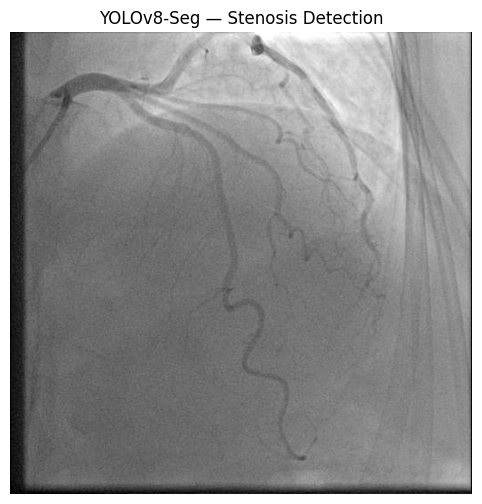

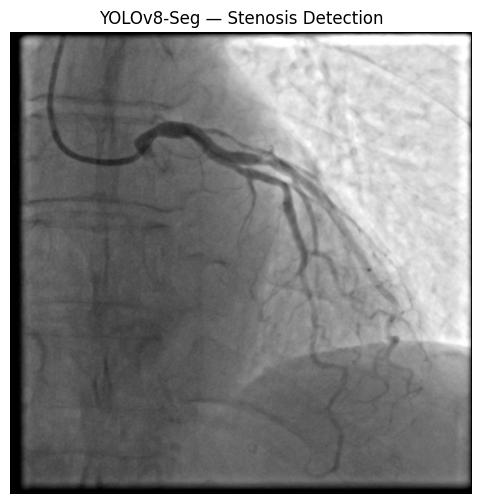

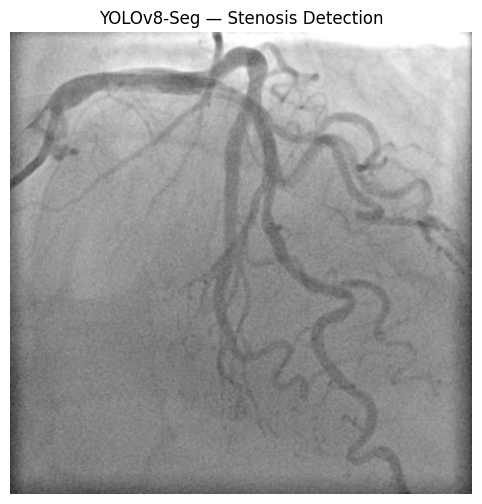


CORRECTED YOLOv8-Seg COMPLETED

BEST PT: /content/best_yolov8n_seg_binary_stenosis.pt
PT size: 6.69 MB

PKL: /content/yolov8n_seg_binary_stenosis_model.pkl
PKL size: 6.69 MB

RESULTS: /content/yolov8_binary_stenosis_results.json

Dataset:
Train images: 997
Validation images: 200
Class 0 = stenosis

Starting downloads...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✅ ALL FILES READY

IMPORTANT:
Send me the final Box/Mask Precision, Recall, mAP@50 and mAP@50-95 values.


In [ ]:
# ============================================================
# CORRECTED YOLOv8-Seg — BINARY STENOSIS DETECTION
# ARCADE DATASET
#
# Class:
#   0 = stenosis
#
# COMPLETE SINGLE COLAB CELL
# ============================================================

!pip -q install ultralytics pycocotools

import os
import json
import glob
import shutil
import pickle
import time
import random
from pathlib import Path

import torch
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

from google.colab import files

# ============================================================
# 1. CPU CONFIGURATION
# ============================================================

torch.set_num_threads(2)

DEVICE = "cpu"

print("=" * 70)
print("CORRECTED YOLOv8-Seg — BINARY STENOSIS DETECTION")
print("=" * 70)

print("Device:", DEVICE)
print("CPU threads:", torch.get_num_threads())

# ============================================================
# 2. FIND ARCADE STENOSIS JSON FILES
# ============================================================

json_files = glob.glob(
    "/content/**/stenosis/**/annotations/*.json",
    recursive=True
)

json_files = [
    p for p in json_files
    if "stenosis" in p.lower()
]

print("\nStenosis JSON files found:")

for p in json_files:
    print(" ", p)

# ============================================================
# 3. IF NOT FOUND, UPLOAD DATASET ZIP
# ============================================================

if len(json_files) == 0:

    print("\nDataset not found.")
    print("Upload your ARCADE ZIP file.")

    uploaded = files.upload()

    zip_name = list(uploaded.keys())[0]

    print("Uploaded:", zip_name)

    if not zip_name.lower().endswith(".zip"):
        raise RuntimeError(
            "Please upload the ARCADE dataset ZIP."
        )

    import zipfile

    extract_dir = "/content/arcade_uploaded"

    os.makedirs(
        extract_dir,
        exist_ok=True
    )

    with zipfile.ZipFile(
        zip_name,
        "r"
    ) as z:

        z.extractall(
            extract_dir
        )

    json_files = glob.glob(
        "/content/**/stenosis/**/annotations/*.json",
        recursive=True
    )

    json_files = [
        p for p in json_files
        if "stenosis" in p.lower()
    ]

# ============================================================
# 4. SELECT TRAIN / VAL JSON
# ============================================================

train_json = None
val_json = None

for p in json_files:

    name = os.path.basename(
        p
    ).lower()

    if (
        "train" in name
        and train_json is None
    ):
        train_json = p

    if (
        ("val" in name or "valid" in name)
        and val_json is None
    ):
        val_json = p

print("\nSelected files:")

print("TRAIN:", train_json)
print("VAL  :", val_json)

if train_json is None:
    raise FileNotFoundError(
        "Training stenosis JSON not found."
    )

if val_json is None:
    raise FileNotFoundError(
        "Validation stenosis JSON not found."
    )

# ============================================================
# 5. LOAD COCO JSON
# ============================================================

with open(
    train_json,
    "r"
) as f:

    train_coco = json.load(f)

with open(
    val_json,
    "r"
) as f:

    val_coco = json.load(f)

print("\nOriginal dataset:")

print(
    "Train images:",
    len(train_coco["images"])
)

print(
    "Train annotations:",
    len(train_coco["annotations"])
)

print(
    "Validation images:",
    len(val_coco["images"])
)

print(
    "Validation annotations:",
    len(val_coco["annotations"])
)

# ============================================================
# 6. FIND ACTUAL STENOSIS CATEGORY
# ============================================================

print("\nCategories in dataset:")

stenosis_category_id = None

for cat in train_coco["categories"]:

    print(
        "ID:",
        cat["id"],
        "| Name:",
        cat["name"]
    )

    if (
        str(cat["name"]).strip().lower()
        == "stenosis"
    ):

        stenosis_category_id = cat["id"]

if stenosis_category_id is None:

    raise RuntimeError(
        "Could not find category named 'stenosis'."
    )

print(
    "\n✅ Actual stenosis category ID:",
    stenosis_category_id
)

# ============================================================
# 7. COUNT TRUE STENOSIS ANNOTATIONS
# ============================================================

train_stenosis_annotations = [

    ann
    for ann in train_coco["annotations"]

    if ann.get("category_id")
    == stenosis_category_id
]

val_stenosis_annotations = [

    ann
    for ann in val_coco["annotations"]

    if ann.get("category_id")
    == stenosis_category_id
]

print("\nTRUE STENOSIS ANNOTATIONS")

print(
    "Train:",
    len(train_stenosis_annotations)
)

print(
    "Validation:",
    len(val_stenosis_annotations)
)

if len(train_stenosis_annotations) == 0:

    raise RuntimeError(
        "No true stenosis annotations found."
    )

# ============================================================
# 8. CREATE CLEAN YOLO DATASET
# ============================================================

YOLO_ROOT = (
    "/content/"
    "arcade_stenosis_binary_yolo"
)

if os.path.exists(
    YOLO_ROOT
):

    shutil.rmtree(
        YOLO_ROOT
    )

os.makedirs(
    f"{YOLO_ROOT}/images/train",
    exist_ok=True
)

os.makedirs(
    f"{YOLO_ROOT}/images/val",
    exist_ok=True
)

os.makedirs(
    f"{YOLO_ROOT}/labels/train",
    exist_ok=True
)

os.makedirs(
    f"{YOLO_ROOT}/labels/val",
    exist_ok=True
)

print(
    "\nCreated:",
    YOLO_ROOT
)

# ============================================================
# 9. FIND IMAGE
# ============================================================

def find_image(
    json_path,
    file_name
):

    json_dir = Path(
        json_path
    ).parent

    candidates = [

        json_dir / file_name,

        json_dir.parent / file_name,

        json_dir.parent.parent / file_name,

        Path(file_name)

    ]

    for candidate in candidates:

        if candidate.exists():

            return candidate

    # Search within stenosis directory

    parts = Path(
        json_path
    ).parts

    stenosis_index = None

    for i, part in enumerate(parts):

        if part.lower() == "stenosis":

            stenosis_index = i

            break

    if stenosis_index is not None:

        root = Path(
            *parts[
                :stenosis_index + 1
            ]
        )

        matches = list(
            root.rglob(
                Path(file_name).name
            )
        )

        if len(matches) > 0:

            return matches[0]

    return None

# ============================================================
# 10. COCO → BINARY YOLO SEGMENTATION
# ============================================================

def convert_dataset(
    coco,
    json_path,
    split
):

    print(
        "\nConverting",
        split,
        "dataset..."
    )

    images = coco["images"]

    annotations = coco["annotations"]

    # Only stenosis annotations
    annotations = [

        ann

        for ann in annotations

        if ann.get("category_id")
        == stenosis_category_id

    ]

    annotations_by_image = {}

    for ann in annotations:

        image_id = ann["image_id"]

        if image_id not in annotations_by_image:

            annotations_by_image[
                image_id
            ] = []

        annotations_by_image[
            image_id
        ].append(
            ann
        )

    copied_images = 0
    images_with_stenosis = 0
    total_polygons = 0
    skipped_images = 0

    for img_info in images:

        image_id = img_info["id"]

        anns = annotations_by_image.get(
            image_id,
            []
        )

        # ----------------------------------------------------
        # IMPORTANT:
        # Keep only images containing actual stenosis.
        # ----------------------------------------------------

        if len(anns) == 0:

            continue

        source_image = find_image(
            json_path,
            img_info["file_name"]
        )

        if source_image is None:

            print(
                "⚠️ Image not found:",
                img_info["file_name"]
            )

            skipped_images += 1

            continue

        image_name = Path(
            img_info["file_name"]
        ).name

        stem = Path(
            image_name
        ).stem

        destination_image = (
            Path(YOLO_ROOT)
            / "images"
            / split
            / image_name
        )

        destination_label = (
            Path(YOLO_ROOT)
            / "labels"
            / split
            / f"{stem}.txt"
        )

        # Copy image

        shutil.copy2(
            source_image,
            destination_image
        )

        width = float(
            img_info["width"]
        )

        height = float(
            img_info["height"]
        )

        label_lines = []

        for ann in anns:

            segmentation = ann.get(
                "segmentation"
            )

            if segmentation is None:
                continue

            # ------------------------------------------------
            # Polygon segmentation
            # ------------------------------------------------

            if not isinstance(
                segmentation,
                list
            ):

                continue

            for polygon in segmentation:

                if not isinstance(
                    polygon,
                    list
                ):

                    continue

                if len(polygon) < 6:
                    continue

                if len(polygon) % 2 != 0:

                    polygon = polygon[:-1]

                normalized = []

                for i in range(
                    0,
                    len(polygon),
                    2
                ):

                    x = float(
                        polygon[i]
                    )

                    y = float(
                        polygon[i + 1]
                    )

                    x = max(
                        0.0,
                        min(
                            1.0,
                            x / width
                        )
                    )

                    y = max(
                        0.0,
                        min(
                            1.0,
                            y / height
                        )
                    )

                    normalized.extend([
                        x,
                        y
                    ])

                if len(normalized) >= 6:

                    # ONLY ONE CLASS:
                    # 0 = stenosis

                    line = (
                        "0 "
                        + " ".join(
                            f"{v:.6f}"
                            for v in normalized
                        )
                    )

                    label_lines.append(
                        line
                    )

                    total_polygons += 1

        if len(label_lines) > 0:

            with open(
                destination_label,
                "w"
            ) as f:

                f.write(
                    "\n".join(
                        label_lines
                    )
                )

            copied_images += 1
            images_with_stenosis += 1

        else:

            # Remove image if no usable polygon
            if destination_image.exists():

                os.remove(
                    destination_image
                )

    print(
        split.upper(),
        "conversion finished"
    )

    print(
        "Images containing stenosis:",
        images_with_stenosis
    )

    print(
        "Stenosis polygons:",
        total_polygons
    )

    print(
        "Skipped images:",
        skipped_images
    )

    return (
        images_with_stenosis,
        total_polygons
    )

# ============================================================
# 11. CONVERT TRAIN / VALIDATION
# ============================================================

train_count, train_poly = convert_dataset(
    train_coco,
    train_json,
    "train"
)

val_count, val_poly = convert_dataset(
    val_coco,
    val_json,
    "val"
)

# ============================================================
# 12. VERIFY DATASET
# ============================================================

train_images = glob.glob(
    f"{YOLO_ROOT}/images/train/*"
)

val_images = glob.glob(
    f"{YOLO_ROOT}/images/val/*"
)

train_labels = glob.glob(
    f"{YOLO_ROOT}/labels/train/*.txt"
)

val_labels = glob.glob(
    f"{YOLO_ROOT}/labels/val/*.txt"
)

print("\n" + "=" * 70)
print("BINARY YOLO DATASET VERIFICATION")
print("=" * 70)

print(
    "Train images:",
    len(train_images)
)

print(
    "Train labels:",
    len(train_labels)
)

print(
    "Validation images:",
    len(val_images)
)

print(
    "Validation labels:",
    len(val_labels)
)

print(
    "Train stenosis polygons:",
    train_poly
)

print(
    "Validation stenosis polygons:",
    val_poly
)

# ============================================================
# 13. CHECK LABEL CONTENT
# ============================================================

if len(train_labels) > 0:

    print("\nSample label:")

    with open(
        train_labels[0],
        "r"
    ) as f:

        print(
            f.read()[:1500]
        )

    # Verify every label begins with class 0

    wrong_class = False

    for label_file in train_labels:

        with open(
            label_file,
            "r"
        ) as f:

            for line in f:

                parts = line.strip().split()

                if len(parts) > 0:

                    if parts[0] != "0":

                        wrong_class = True

                        print(
                            "❌ Wrong class:",
                            label_file
                        )

                        break

    if not wrong_class:

        print(
            "✅ All training labels use class 0 = stenosis"
        )

# ============================================================
# 14. CREATE DATA YAML
# ============================================================

yaml_path = (
    f"{YOLO_ROOT}/data.yaml"
)

with open(
    yaml_path,
    "w"
) as f:

    f.write(
        f"path: {YOLO_ROOT}\n"
    )

    f.write(
        "train: images/train\n"
    )

    f.write(
        "val: images/val\n"
    )

    f.write(
        "nc: 1\n"
    )

    f.write(
        "names:\n"
    )

    f.write(
        "  0: stenosis\n"
    )

print(
    "\nYAML created:",
    yaml_path
)

# ============================================================
# 15. INSTALL / IMPORT ULTRALYTICS
# ============================================================

from ultralytics import YOLO

print(
    "\nUltralytics imported."
)

# ============================================================
# 16. LOAD YOLOv8n-SEG
# ============================================================

print(
    "\nLoading pretrained YOLOv8n-Seg..."
)

model = YOLO(
    "yolov8n-seg.pt"
)

print(
    "YOLOv8n-Seg loaded."
)

# ============================================================
# 17. TRAINING CONFIGURATION
# ============================================================

EPOCHS = 20
IMAGE_SIZE = 512
BATCH_SIZE = 2

print("\n" + "=" * 70)
print("TRAINING CONFIGURATION")
print("=" * 70)

print(
    "Model      : YOLOv8n-Seg"
)

print(
    "Classes    : 1"
)

print(
    "Class 0    : stenosis"
)

print(
    "Image size :",
    IMAGE_SIZE
)

print(
    "Batch size :",
    BATCH_SIZE
)

print(
    "Epochs     :",
    EPOCHS
)

print(
    "Device     :",
    DEVICE
)

# ============================================================
# 18. TRAIN
# ============================================================

start_time = time.time()

results = model.train(

    data=yaml_path,

    epochs=EPOCHS,

    imgsz=IMAGE_SIZE,

    batch=BATCH_SIZE,

    device=DEVICE,

    workers=0,

    patience=7,

    optimizer="AdamW",

    lr0=0.001,

    weight_decay=0.0005,

    pretrained=True,

    project=(
        "/content/"
        "yolov8_binary_stenosis_training"
    ),

    name="yolov8n_seg_binary_stenosis",

    exist_ok=True,

    save=True,

    plots=True,

    verbose=True
)

training_time = (
    time.time() - start_time
)

print(
    "\nTraining time:",
    f"{training_time / 60:.2f} minutes"
)

# ============================================================
# 19. BEST MODEL
# ============================================================

RUN_DIR = (
    "/content/"
    "yolov8_binary_stenosis_training/"
    "yolov8n_seg_binary_stenosis"
)

BEST_SOURCE = (
    f"{RUN_DIR}/weights/best.pt"
)

BEST_MODEL = (
    "/content/"
    "best_yolov8n_seg_binary_stenosis.pt"
)

if not os.path.exists(
    BEST_SOURCE
):

    raise FileNotFoundError(
        "best.pt was not created."
    )

shutil.copy2(
    BEST_SOURCE,
    BEST_MODEL
)

print(
    "\n✅ Best model:",
    BEST_MODEL
)

# ============================================================
# 20. VALIDATION
# ============================================================

print(
    "\nRunning final validation..."
)

best_model = YOLO(
    BEST_MODEL
)

metrics = best_model.val(

    data=yaml_path,

    imgsz=IMAGE_SIZE,

    batch=BATCH_SIZE,

    device=DEVICE,

    workers=0,

    plots=True
)

# ============================================================
# 21. EXTRACT METRICS
# ============================================================

print("\n" + "=" * 70)
print("FINAL YOLOv8-Seg RESULTS")
print("=" * 70)

results_summary = {

    "model":
        "YOLOv8n-Seg",

    "task":
        "Binary Coronary Stenosis Detection",

    "dataset":
        "ARCADE",

    "classes":
        ["stenosis"],

    "epochs":
        EPOCHS,

    "image_size":
        IMAGE_SIZE,

    "batch_size":
        BATCH_SIZE,

    "training_time_minutes":
        training_time / 60

}

try:

    box_precision = float(
        metrics.box.mp
    )

    box_recall = float(
        metrics.box.mr
    )

    box_map50 = float(
        metrics.box.map50
    )

    box_map = float(
        metrics.box.map
    )

    print(
        f"Box Precision : {box_precision:.6f}"
    )

    print(
        f"Box Recall    : {box_recall:.6f}"
    )

    print(
        f"Box mAP@50    : {box_map50:.6f}"
    )

    print(
        f"Box mAP@50-95 : {box_map:.6f}"
    )

    results_summary[
        "box_precision"
    ] = box_precision

    results_summary[
        "box_recall"
    ] = box_recall

    results_summary[
        "box_map50"
    ] = box_map50

    results_summary[
        "box_map50_95"
    ] = box_map

except Exception as e:

    print(
        "Box metric error:",
        e
    )

try:

    mask_precision = float(
        metrics.seg.mp
    )

    mask_recall = float(
        metrics.seg.mr
    )

    mask_map50 = float(
        metrics.seg.map50
    )

    mask_map = float(
        metrics.seg.map
    )

    print(
        f"Mask Precision: {mask_precision:.6f}"
    )

    print(
        f"Mask Recall   : {mask_recall:.6f}"
    )

    print(
        f"Mask mAP@50   : {mask_map50:.6f}"
    )

    print(
        f"Mask mAP@50-95: {mask_map:.6f}"
    )

    results_summary[
        "mask_precision"
    ] = mask_precision

    results_summary[
        "mask_recall"
    ] = mask_recall

    results_summary[
        "mask_map50"
    ] = mask_map50

    results_summary[
        "mask_map50_95"
    ] = mask_map

except Exception as e:

    print(
        "Mask metric error:",
        e
    )

# ============================================================
# 22. SAVE RESULTS JSON
# ============================================================

RESULT_JSON = (
    "/content/"
    "yolov8_binary_stenosis_results.json"
)

with open(
    RESULT_JSON,
    "w"
) as f:

    json.dump(
        results_summary,
        f,
        indent=4
    )

print(
    "\nResults saved:",
    RESULT_JSON
)

# ============================================================
# 23. CREATE SELF-CONTAINED PKL
# ============================================================

PKL_FILE = (
    "/content/"
    "yolov8n_seg_binary_stenosis_model.pkl"
)

with open(
    BEST_MODEL,
    "rb"
) as f:

    pt_bytes = f.read()

model_package = {

    "model_name":
        "YOLOv8n-Seg",

    "architecture":
        "YOLOv8 Nano Segmentation",

    "task":
        "Binary Coronary Stenosis Detection",

    "dataset":
        "ARCADE",

    "class_names":
        ["stenosis"],

    "num_classes":
        1,

    "image_size":
        IMAGE_SIZE,

    "training_epochs":
        EPOCHS,

    "batch_size":
        BATCH_SIZE,

    "device":
        DEVICE,

    "results":
        results_summary,

    "checkpoint_filename":
        "best_yolov8n_seg_binary_stenosis.pt",

    "checkpoint_bytes":
        pt_bytes
}

with open(
    PKL_FILE,
    "wb"
) as f:

    pickle.dump(
        model_package,
        f,
        protocol=pickle.HIGHEST_PROTOCOL
    )

print(
    "\n✅ PKL created:",
    PKL_FILE
)

# ============================================================
# 24. VERIFY PKL
# ============================================================

with open(
    PKL_FILE,
    "rb"
) as f:

    test_package = pickle.load(
        f
    )

print(
    "PKL model:",
    test_package["model_name"]
)

print(
    "PKL classes:",
    test_package["class_names"]
)

print(
    "Embedded checkpoint:",
    f"{len(test_package['checkpoint_bytes']) / (1024*1024):.2f} MB"
)

print(
    "✅ PKL verification successful"
)

# ============================================================
# 25. SAMPLE PREDICTIONS
# ============================================================

print(
    "\nGenerating sample stenosis predictions..."
)

sample_images = train_images[:5]

PRED_DIR = (
    "/content/"
    "yolov8_binary_stenosis_predictions"
)

os.makedirs(
    PRED_DIR,
    exist_ok=True
)

prediction_results = best_model.predict(

    source=sample_images,

    imgsz=IMAGE_SIZE,

    conf=0.25,

    device=DEVICE,

    save=True,

    project=PRED_DIR,

    name="samples",

    exist_ok=True,

    verbose=False
)

print(
    "Sample predictions generated."
)

# ============================================================
# 26. DISPLAY PREDICTIONS
# ============================================================

prediction_files = glob.glob(
    f"{PRED_DIR}/samples/*"
)

prediction_images = [

    p for p in prediction_files

    if p.lower().endswith(
        (".jpg", ".jpeg", ".png")
    )
]

print(
    "Prediction images:",
    len(prediction_images)
)

for img_path in prediction_images[:3]:

    img = Image.open(
        img_path
    )

    plt.figure(
        figsize=(8, 6)
    )

    plt.imshow(img)

    plt.axis("off")

    plt.title(
        "YOLOv8-Seg — Stenosis Detection"
    )

    plt.show()

# ============================================================
# 27. FINAL FILE INFORMATION
# ============================================================

print("\n" + "=" * 70)
print("CORRECTED YOLOv8-Seg COMPLETED")
print("=" * 70)

print(
    "\nBEST PT:",
    BEST_MODEL
)

print(
    "PT size:",
    f"{os.path.getsize(BEST_MODEL)/(1024*1024):.2f} MB"
)

print(
    "\nPKL:",
    PKL_FILE
)

print(
    "PKL size:",
    f"{os.path.getsize(PKL_FILE)/(1024*1024):.2f} MB"
)

print(
    "\nRESULTS:",
    RESULT_JSON
)

print(
    "\nDataset:"
)

print(
    "Train images:",
    len(train_images)
)

print(
    "Validation images:",
    len(val_images)
)

print(
    "Class 0 = stenosis"
)

# ============================================================
# 28. DOWNLOAD
# ============================================================

print(
    "\nStarting downloads..."
)

files.download(
    BEST_MODEL
)

time.sleep(3)

files.download(
    PKL_FILE
)

print(
    "\n✅ ALL FILES READY"
)

print(
    "\nIMPORTANT:"
)

print(
    "Send me the final Box/Mask Precision, Recall, "
    "mAP@50 and mAP@50-95 values."
)

In [ ]:
import os

print("Files currently in /content:\n")

for item in os.listdir("/content"):
    path = os.path.join("/content", item)

    if os.path.isfile(path):
        size = os.path.getsize(path) / (1024 * 1024)
        print(f"{item}  →  {size:.2f} MB")

Files currently in /content:

archive (1).zip  →  21.00 MB


In [ ]:
# ============================================================
# ARCADE DATASET EXTRACTION + STRUCTURE CHECK
# ============================================================

import os
import zipfile
import json

ZIP_PATH = "/content/archive (1).zip"
EXTRACT_PATH = "/content/arcade_dataset"

print("=" * 70)
print("ARCADE DATASET EXTRACTION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Check ZIP
# ------------------------------------------------------------

if not os.path.exists(ZIP_PATH):
    raise FileNotFoundError(
        f"ZIP not found: {ZIP_PATH}"
    )

size_mb = os.path.getsize(ZIP_PATH) / (1024 * 1024)

print(
    f"ZIP found: {ZIP_PATH}"
)

print(
    f"ZIP size: {size_mb:.2f} MB"
)


# ------------------------------------------------------------
# 2. Inspect ZIP contents
# ------------------------------------------------------------

print("\nInspecting ZIP contents...")

with zipfile.ZipFile(
    ZIP_PATH,
    "r"
) as z:

    members = z.namelist()

print(
    "Total files/folders in ZIP:",
    len(members)
)

print("\nFirst 50 entries:")

for item in members[:50]:
    print(item)


# ------------------------------------------------------------
# 3. Extract
# ------------------------------------------------------------

if os.path.exists(EXTRACT_PATH):

    print(
        "\nExisting extraction found."
    )

else:

    os.makedirs(
        EXTRACT_PATH,
        exist_ok=True
    )


print(
    "\nExtracting dataset..."
)

with zipfile.ZipFile(
    ZIP_PATH,
    "r"
) as z:

    z.extractall(
        EXTRACT_PATH
    )

print(
    "Extraction completed."
)


# ------------------------------------------------------------
# 4. Locate JSON files
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SEARCHING FOR JSON ANNOTATIONS")
print("=" * 70)

json_files = []

for root, dirs, files in os.walk(
    EXTRACT_PATH
):

    for f in files:

        if f.lower().endswith(
            ".json"
        ):

            json_files.append(
                os.path.join(
                    root,
                    f
                )
            )

print(
    "JSON files found:",
    len(json_files)
)


# ------------------------------------------------------------
# 5. Inspect JSON files
# ------------------------------------------------------------

for path in json_files:

    print("\n----------------------------------------")

    print(
        "JSON:",
        path
    )

    try:

        with open(
            path,
            "r",
            encoding="utf-8"
        ) as f:

            data = json.load(f)

        print(
            "Top-level type:",
            type(data).__name__
        )

        if isinstance(
            data,
            dict
        ):

            print(
                "Keys:",
                list(data.keys())[:20]
            )

            if "images" in data:
                print(
                    "Images:",
                    len(data["images"])
                )

            if "annotations" in data:
                print(
                    "Annotations:",
                    len(data["annotations"])
                )

            if "categories" in data:

                categories = data[
                    "categories"
                ]

                print(
                    "Categories:",
                    len(categories)
                )

                print(
                    "Category names:",
                    [
                        c.get("name")
                        for c in categories
                    ][:30]
                )

    except Exception as e:

        print(
            "Could not read JSON:",
            e
        )


# ------------------------------------------------------------
# 6. Print directory structure
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("EXTRACTED DIRECTORY STRUCTURE")
print("=" * 70)

for root, dirs, files in os.walk(
    EXTRACT_PATH
):

    level = (
        root.replace(
            EXTRACT_PATH,
            ""
        ).count(
            os.sep
        )
    )

    indent = "  " * level

    print(
        indent
        + os.path.basename(root)
        + "/"
    )

    # Only show first few files per folder
    for f in files[:10]:

        print(
            indent
            + "  "
            + f
        )

print("\n" + "=" * 70)
print("DATASET INSPECTION COMPLETE")
print("=" * 70)

ARCADE DATASET EXTRACTION
ZIP found: /content/archive (1).zip
ZIP size: 431.20 MB

Inspecting ZIP contents...
Total files/folders in ZIP: 3007

First 50 entries:
data/stenosis/test/annotations/test.json
data/stenosis/test/images/1.png
data/stenosis/test/images/10.png
data/stenosis/test/images/100.png
data/stenosis/test/images/101.png
data/stenosis/test/images/102.png
data/stenosis/test/images/103.png
data/stenosis/test/images/104.png
data/stenosis/test/images/105.png
data/stenosis/test/images/106.png
data/stenosis/test/images/107.png
data/stenosis/test/images/108.png
data/stenosis/test/images/109.png
data/stenosis/test/images/11.png
data/stenosis/test/images/110.png
data/stenosis/test/images/111.png
data/stenosis/test/images/112.png
data/stenosis/test/images/113.png
data/stenosis/test/images/114.png
data/stenosis/test/images/115.png
data/stenosis/test/images/116.png
data/stenosis/test/images/117.png
data/stenosis/test/images/118.png
data/stenosis/test/images/119.png
data/stenosis/test/

In [ ]:
# ============================================================
# MODEL 4 — EfficientNet-B0 STENOSIS CLASSIFICATION
# ARCADE DATASET
# CPU ONLY | NO GOOGLE DRIVE | SINGLE COLAB CELL
# ============================================================

import os
import json
import random
import shutil
import pickle
import time
import warnings

warnings.filterwarnings("ignore")

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
from torchvision.models import EfficientNet_B0_Weights

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# ============================================================
# 1. CONFIGURATION
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cpu")
torch.set_num_threads(2)

IMG_SIZE = 224
BATCH_SIZE = 16

EPOCHS = 12
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4

PATIENCE = 4

DATA_ROOT = "/content/arcade_dataset/data"

STENOSIS_TRAIN_JSON = (
    DATA_ROOT +
    "/stenosis/train/annotations/train.json"
)

STENOSIS_VAL_JSON = (
    DATA_ROOT +
    "/stenosis/val/annotations/val.json"
)

STENOSIS_TRAIN_IMAGES = (
    DATA_ROOT +
    "/stenosis/train/images"
)

STENOSIS_VAL_IMAGES = (
    DATA_ROOT +
    "/stenosis/val/images"
)

SYNTAX_TRAIN_JSON = (
    DATA_ROOT +
    "/syntax/train/annotations/train.json"
)

SYNTAX_VAL_JSON = (
    DATA_ROOT +
    "/syntax/val/annotations/val.json"
)

SYNTAX_TRAIN_IMAGES = (
    DATA_ROOT +
    "/syntax/train/images"
)

SYNTAX_VAL_IMAGES = (
    DATA_ROOT +
    "/syntax/val/images"
)

ROI_ROOT = (
    "/content/arcade_stenosis_roi"
)

BEST_PTH = (
    "/content/best_efficientnet_b0_arcade_stenosis.pth"
)

PKL_PATH = (
    "/content/efficientnet_b0_arcade_stenosis_model.pkl"
)

print("=" * 70)
print("MODEL 4 — EfficientNet-B0 STENOSIS CLASSIFICATION")
print("=" * 70)

print("Device:", DEVICE)
print("CPU threads:", torch.get_num_threads())
print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)

print("=" * 70)


# ============================================================
# 2. VERIFY DATASET
# ============================================================

required_paths = [
    STENOSIS_TRAIN_JSON,
    STENOSIS_VAL_JSON,
    STENOSIS_TRAIN_IMAGES,
    STENOSIS_VAL_IMAGES,
    SYNTAX_TRAIN_JSON,
    SYNTAX_VAL_JSON,
    SYNTAX_TRAIN_IMAGES,
    SYNTAX_VAL_IMAGES
]

print("\nChecking dataset paths...")

for path in required_paths:

    if not os.path.exists(path):

        raise FileNotFoundError(
            f"Required path not found:\n{path}"
        )

    print("✓", path)

print("\nDataset structure verified.")


# ============================================================
# 3. LOAD COCO ANNOTATIONS
# ============================================================

with open(
    STENOSIS_TRAIN_JSON,
    "r",
    encoding="utf-8"
) as f:

    stenosis_train = json.load(f)


with open(
    STENOSIS_VAL_JSON,
    "r",
    encoding="utf-8"
) as f:

    stenosis_val = json.load(f)


with open(
    SYNTAX_TRAIN_JSON,
    "r",
    encoding="utf-8"
) as f:

    syntax_train = json.load(f)


with open(
    SYNTAX_VAL_JSON,
    "r",
    encoding="utf-8"
) as f:

    syntax_val = json.load(f)


print("\n" + "=" * 70)
print("DATASET INFORMATION")
print("=" * 70)

print(
    "Stenosis train images:",
    len(stenosis_train["images"])
)

print(
    "Stenosis train annotations:",
    len(stenosis_train["annotations"])
)

print(
    "Stenosis validation images:",
    len(stenosis_val["images"])
)

print(
    "Stenosis validation annotations:",
    len(stenosis_val["annotations"])
)

print(
    "Syntax train annotations:",
    len(syntax_train["annotations"])
)

print(
    "Syntax validation annotations:",
    len(syntax_val["annotations"])
)


# ============================================================
# 4. FIND STENOSIS CATEGORY
# ============================================================

STENOSIS_ID = None

for category in stenosis_train["categories"]:

    name = str(
        category.get("name", "")
    ).lower()

    if name == "stenosis":

        STENOSIS_ID = category["id"]

        break


if STENOSIS_ID is None:

    raise RuntimeError(
        "Stenosis category not found."
    )


print(
    "\nStenosis category ID:",
    STENOSIS_ID
)


# ============================================================
# 5. CREATE COCO MAPS
# ============================================================

def create_maps(coco):

    image_map = {
        image["id"]: image
        for image in coco["images"]
    }

    annotation_map = {}

    for annotation in coco["annotations"]:

        image_id = annotation["image_id"]

        if image_id not in annotation_map:

            annotation_map[image_id] = []

        annotation_map[
            image_id
        ].append(annotation)

    return (
        image_map,
        annotation_map
    )


(
    stenosis_train_image_map,
    stenosis_train_annotations
) = create_maps(
    stenosis_train
)

(
    stenosis_val_image_map,
    stenosis_val_annotations
) = create_maps(
    stenosis_val
)

(
    syntax_train_image_map,
    syntax_train_annotations
) = create_maps(
    syntax_train
)

(
    syntax_val_image_map,
    syntax_val_annotations
) = create_maps(
    syntax_val
)


# ============================================================
# 6. BBOX FUNCTION
# ============================================================

def get_bbox(annotation):

    bbox = annotation.get(
        "bbox",
        None
    )

    if (
        bbox is not None
        and len(bbox) >= 4
    ):

        x, y, w, h = bbox[:4]

        return (
            float(x),
            float(y),
            float(w),
            float(h)
        )

    # Fallback: derive bbox from polygon
    segmentation = annotation.get(
        "segmentation",
        []
    )

    xs = []
    ys = []

    if isinstance(
        segmentation,
        list
    ):

        for polygon in segmentation:

            if (
                isinstance(polygon, list)
                and len(polygon) >= 6
            ):

                for i in range(
                    0,
                    len(polygon) - 1,
                    2
                ):

                    xs.append(
                        polygon[i]
                    )

                    ys.append(
                        polygon[i + 1]
                    )

    if len(xs) == 0:

        return None

    x1 = min(xs)
    y1 = min(ys)

    x2 = max(xs)
    y2 = max(ys)

    return (
        float(x1),
        float(y1),
        float(x2 - x1),
        float(y2 - y1)
    )


# ============================================================
# 7. BBOX IOU
# ============================================================

def bbox_iou(
    box_a,
    box_b
):

    ax, ay, aw, ah = box_a
    bx, by, bw, bh = box_b

    x1 = max(
        ax,
        bx
    )

    y1 = max(
        ay,
        by
    )

    x2 = min(
        ax + aw,
        bx + bw
    )

    y2 = min(
        ay + ah,
        by + bh
    )

    intersection_w = max(
        0,
        x2 - x1
    )

    intersection_h = max(
        0,
        y2 - y1
    )

    intersection = (
        intersection_w
        * intersection_h
    )

    area_a = aw * ah
    area_b = bw * bh

    union = (
        area_a
        + area_b
        - intersection
    )

    if union <= 0:

        return 0.0

    return (
        intersection
        / union
    )


# ============================================================
# 8. CLAHE PREPROCESSING
# ============================================================

def apply_clahe(
    image
):

    lab = cv2.cvtColor(
        image,
        cv2.COLOR_RGB2LAB
    )

    l_channel, a_channel, b_channel = \
        cv2.split(lab)

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    l_channel = clahe.apply(
        l_channel
    )

    enhanced = cv2.merge(
        [
            l_channel,
            a_channel,
            b_channel
        ]
    )

    enhanced = cv2.cvtColor(
        enhanced,
        cv2.COLOR_LAB2RGB
    )

    return enhanced


# ============================================================
# 9. FIND IMAGE
# ============================================================

def get_image_path(
    image_info,
    image_directory
):

    filename = os.path.basename(
        image_info["file_name"]
    )

    path = os.path.join(
        image_directory,
        filename
    )

    if os.path.exists(path):

        return path

    # Fallback by numeric stem
    stem = os.path.splitext(
        filename
    )[0]

    for file in os.listdir(
        image_directory
    ):

        current_stem = os.path.splitext(
            file
        )[0]

        if current_stem == stem:

            return os.path.join(
                image_directory,
                file
            )

    return None


# ============================================================
# 10. BUILD VESSEL MASK
# ============================================================

def create_vessel_mask(
    stenosis_image_info,
    syntax_image_map,
    syntax_annotations
):

    H = int(
        stenosis_image_info["height"]
    )

    W = int(
        stenosis_image_info["width"]
    )

    mask = np.zeros(
        (H, W),
        dtype=np.uint8
    )

    filename = os.path.basename(
        stenosis_image_info["file_name"]
    )

    stem = os.path.splitext(
        filename
    )[0]

    syntax_id = None

    # Find corresponding syntax image
    for image_id, image_info in syntax_image_map.items():

        syntax_filename = os.path.basename(
            image_info["file_name"]
        )

        syntax_stem = os.path.splitext(
            syntax_filename
        )[0]

        if (
            syntax_filename == filename
            or syntax_stem == stem
        ):

            syntax_id = image_id

            break

    if syntax_id is None:

        return mask

    annotations = syntax_annotations.get(
        syntax_id,
        []
    )

    for annotation in annotations:

        segmentation = annotation.get(
            "segmentation",
            []
        )

        if not isinstance(
            segmentation,
            list
        ):

            continue

        for polygon in segmentation:

            if (
                not isinstance(polygon, list)
                or len(polygon) < 6
            ):

                continue

            points = np.array(
                polygon,
                dtype=np.float32
            ).reshape(
                -1,
                2
            )

            points[:, 0] = np.clip(
                points[:, 0],
                0,
                W - 1
            )

            points[:, 1] = np.clip(
                points[:, 1],
                0,
                H - 1
            )

            points = points.astype(
                np.int32
            )

            cv2.fillPoly(
                mask,
                [points],
                255
            )

    return mask


# ============================================================
# 11. SAVE ROI
# ============================================================

def save_roi(
    image,
    bbox,
    output_path,
    margin=0.5
):

    H, W = image.shape[:2]

    x, y, w, h = bbox

    w = max(
        w,
        8
    )

    h = max(
        h,
        8
    )

    margin_x = w * margin
    margin_y = h * margin

    x1 = int(
        max(
            0,
            x - margin_x
        )
    )

    y1 = int(
        max(
            0,
            y - margin_y
        )
    )

    x2 = int(
        min(
            W,
            x + w + margin_x
        )
    )

    y2 = int(
        min(
            H,
            y + h + margin_y
        )
    )

    if (
        x2 <= x1
        or y2 <= y1
    ):

        return False

    crop = image[
        y1:y2,
        x1:x2
    ]

    if crop.size == 0:

        return False

    crop = apply_clahe(
        crop
    )

    crop = cv2.resize(
        crop,
        (
            IMG_SIZE,
            IMG_SIZE
        ),
        interpolation=cv2.INTER_AREA
    )

    cv2.imwrite(
        output_path,
        cv2.cvtColor(
            crop,
            cv2.COLOR_RGB2BGR
        )
    )

    return True


# ============================================================
# 12. SAMPLE HARD NEGATIVE VESSEL ROI
# ============================================================

def sample_negative_bbox(
    image,
    positive_boxes,
    vessel_mask
):

    H, W = image.shape[:2]

    widths = [
        max(
            box[2],
            12
        )
        for box in positive_boxes
    ]

    heights = [
        max(
            box[3],
            12
        )
        for box in positive_boxes
    ]

    if not widths:

        return None

    crop_w = int(
        np.clip(
            np.median(widths) * 2.0,
            32,
            W * 0.35
        )
    )

    crop_h = int(
        np.clip(
            np.median(heights) * 2.0,
            32,
            H * 0.35
        )
    )

    for _ in range(100):

        if (
            W <= crop_w
            or H <= crop_h
        ):

            return None

        x = random.randint(
            0,
            W - crop_w
        )

        y = random.randint(
            0,
            H - crop_h
        )

        candidate = (
            float(x),
            float(y),
            float(crop_w),
            float(crop_h)
        )

        # Reject stenosis overlap
        if any(
            bbox_iou(
                candidate,
                positive_box
            ) > 0.05
            for positive_box
            in positive_boxes
        ):

            continue

        # Prefer vessel regions
        if vessel_mask is not None:

            region = vessel_mask[
                y:y + crop_h,
                x:x + crop_w
            ]

            if region.size == 0:

                continue

            vessel_ratio = np.mean(
                region > 0
            )

            if vessel_ratio < 0.01:

                continue

        return candidate

    return None


# ============================================================
# 13. CREATE ROI DATASET
# ============================================================

if os.path.exists(
    ROI_ROOT
):

    shutil.rmtree(
        ROI_ROOT
    )

for split in [
    "train",
    "val"
]:

    for class_name in [
        "positive",
        "negative"
    ]:

        os.makedirs(
            os.path.join(
                ROI_ROOT,
                split,
                class_name
            ),
            exist_ok=True
        )


# ============================================================
# 14. PROCESS ONE SPLIT
# ============================================================

def process_split(
    coco,
    image_map,
    annotation_map,
    image_directory,
    split,
    syntax_image_map,
    syntax_annotation_map
):

    positive_count = 0
    negative_count = 0
    missing_images = 0

    total = len(
        coco["images"]
    )

    for index, image_info in enumerate(
        coco["images"]
    ):

        image_path = get_image_path(
            image_info,
            image_directory
        )

        if image_path is None:

            missing_images += 1

            continue

        image = cv2.imread(
            image_path
        )

        if image is None:

            missing_images += 1

            continue

        image = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )

        annotations = annotation_map.get(
            image_info["id"],
            []
        )

        stenosis_annotations = [
            annotation
            for annotation in annotations
            if annotation.get(
                "category_id"
            ) == STENOSIS_ID
        ]

        positive_boxes = []

        for annotation in stenosis_annotations:

            bbox = get_bbox(
                annotation
            )

            if bbox is not None:

                positive_boxes.append(
                    bbox
                )

        if len(
            positive_boxes
        ) == 0:

            continue

        base_name = os.path.splitext(
            os.path.basename(
                image_info["file_name"]
            )
        )[0]

        # ----------------------------------------------------
        # POSITIVE ROIS
        # ----------------------------------------------------

        for roi_index, bbox in enumerate(
            positive_boxes
        ):

            output_path = os.path.join(
                ROI_ROOT,
                split,
                "positive",
                f"{base_name}_positive_{roi_index}.png"
            )

            if save_roi(
                image,
                bbox,
                output_path,
                margin=0.60
            ):

                positive_count += 1

        # ----------------------------------------------------
        # VESSEL MASK
        # ----------------------------------------------------

        vessel_mask = None

        try:

            vessel_mask = create_vessel_mask(
                image_info,
                syntax_image_map,
                syntax_annotation_map
            )

            if np.sum(
                vessel_mask
            ) == 0:

                vessel_mask = None

        except Exception:

            vessel_mask = None

        # ----------------------------------------------------
        # NEGATIVE ROIS
        # ----------------------------------------------------

        for roi_index in range(
            len(positive_boxes)
        ):

            negative_bbox = sample_negative_bbox(
                image,
                positive_boxes,
                vessel_mask
            )

            if negative_bbox is None:

                continue

            output_path = os.path.join(
                ROI_ROOT,
                split,
                "negative",
                f"{base_name}_negative_{roi_index}.png"
            )

            if save_roi(
                image,
                negative_bbox,
                output_path,
                margin=0.20
            ):

                negative_count += 1

        if (
            index + 1
        ) % 100 == 0:

            print(
                f"{split.upper()} | "
                f"{index + 1}/{total} images | "
                f"Positive={positive_count} | "
                f"Negative={negative_count}"
            )

    return (
        positive_count,
        negative_count,
        missing_images
    )


# ============================================================
# 15. PROCESS TRAIN
# ============================================================

print("\n" + "=" * 70)
print("CREATING TRAINING ROIs")
print("=" * 70)

(
    train_positive,
    train_negative,
    train_missing
) = process_split(
    stenosis_train,
    stenosis_train_image_map,
    stenosis_train_annotations,
    STENOSIS_TRAIN_IMAGES,
    "train",
    syntax_train_image_map,
    syntax_train_annotations
)


# ============================================================
# 16. PROCESS VALIDATION
# ============================================================

print("\n" + "=" * 70)
print("CREATING VALIDATION ROIs")
print("=" * 70)

(
    val_positive,
    val_negative,
    val_missing
) = process_split(
    stenosis_val,
    stenosis_val_image_map,
    stenosis_val_annotations,
    STENOSIS_VAL_IMAGES,
    "val",
    syntax_val_image_map,
    syntax_val_annotations
)


# ============================================================
# 17. ROI SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("ROI DATASET SUMMARY")
print("=" * 70)

print(
    "Train positive:",
    train_positive
)

print(
    "Train negative:",
    train_negative
)

print(
    "Validation positive:",
    val_positive
)

print(
    "Validation negative:",
    val_negative
)

print(
    "Missing train images:",
    train_missing
)

print(
    "Missing validation images:",
    val_missing
)

if min(
    train_positive,
    train_negative,
    val_positive,
    val_negative
) == 0:

    raise RuntimeError(
        "One of the ROI classes has zero samples."
    )


# ============================================================
# 18. TRANSFORMS
# ============================================================

IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225
]

train_transform = transforms.Compose([

    transforms.Resize(
        (IMG_SIZE, IMG_SIZE)
    ),

    transforms.RandomRotation(
        5
    ),

    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        IMAGENET_MEAN,
        IMAGENET_STD
    )
])


val_transform = transforms.Compose([

    transforms.Resize(
        (IMG_SIZE, IMG_SIZE)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        IMAGENET_MEAN,
        IMAGENET_STD
    )
])


# ============================================================
# 19. IMAGE FOLDER DATASETS
# ============================================================

train_dataset = datasets.ImageFolder(
    os.path.join(
        ROI_ROOT,
        "train"
    ),
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    os.path.join(
        ROI_ROOT,
        "val"
    ),
    transform=val_transform
)

print("\nClass mapping:")

print(
    train_dataset.class_to_idx
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print(
    "\nTraining samples:",
    len(train_dataset)
)

print(
    "Validation samples:",
    len(val_dataset)
)

print(
    "Training batches:",
    len(train_loader)
)

print(
    "Validation batches:",
    len(val_loader)
)


# ============================================================
# 20. LOAD EFFICIENTNET-B0
# ============================================================

print("\n" + "=" * 70)
print("LOADING EFFICIENTNET-B0")
print("=" * 70)

try:

    model = models.efficientnet_b0(
        weights=EfficientNet_B0_Weights.DEFAULT
    )

    print(
        "✓ ImageNet pretrained weights loaded."
    )

except Exception as e:

    print(
        "Pretrained weights could not be loaded."
    )

    print(
        "Using random initialization."
    )

    print(
        "Reason:",
        e
    )

    model = models.efficientnet_b0(
        weights=None
    )


# Replace classifier
in_features = (
    model.classifier[1].in_features
)

model.classifier = nn.Sequential(

    nn.Dropout(
        p=0.30
    ),

    nn.Linear(
        in_features,
        2
    )
)

model = model.to(
    DEVICE
)

print(
    "Total parameters:",
    sum(
        p.numel()
        for p in model.parameters()
    )
)


# ============================================================
# 21. LOSS / OPTIMIZER
# ============================================================

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)


# ============================================================
# 22. TRAINING FUNCTION
# ============================================================

def train_one_epoch():

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(
            DEVICE
        )

        labels = labels.to(
            DEVICE
        )

        optimizer.zero_grad()

        outputs = model(
            images
        )

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()

        optimizer.step()

        running_loss += (
            loss.item()
            * images.size(0)
        )

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

    return (
        running_loss / total,
        correct / total
    )


# ============================================================
# 23. EVALUATION FUNCTION
# ============================================================

def evaluate():

    model.eval()

    running_loss = 0.0

    all_labels = []
    all_predictions = []
    all_probabilities = []

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(
                DEVICE
            )

            labels = labels.to(
                DEVICE
            )

            outputs = model(
                images
            )

            loss = criterion(
                outputs,
                labels
            )

            probabilities = torch.softmax(
                outputs,
                dim=1
            )

            predictions = torch.argmax(
                probabilities,
                dim=1
            )

            running_loss += (
                loss.item()
                * images.size(0)
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_probabilities.extend(
                probabilities[:, 1]
                .cpu()
                .numpy()
            )

    y_true = np.array(
        all_labels
    )

    y_pred = np.array(
        all_predictions
    )

    y_prob = np.array(
        all_probabilities
    )

    loss = (
        running_loss
        / len(val_dataset)
    )

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    try:

        auc = roc_auc_score(
            y_true,
            y_prob
        )

    except Exception:

        auc = 0.0

    return (
        loss,
        accuracy,
        precision,
        recall,
        f1,
        auc,
        y_true,
        y_pred,
        y_prob
    )


# ============================================================
# 24. TRAIN
# ============================================================

print("\n" + "=" * 70)
print("TRAINING EFFICIENTNET-B0")
print("=" * 70)

best_f1 = -1.0
best_auc = -1.0

best_epoch = 0

patience_counter = 0

history = []

training_start = time.time()

for epoch in range(
    1,
    EPOCHS + 1
):

    epoch_start = time.time()

    (
        train_loss,
        train_accuracy
    ) = train_one_epoch()

    (
        val_loss,
        val_accuracy,
        val_precision,
        val_recall,
        val_f1,
        val_auc,
        _,
        _,
        _
    ) = evaluate()

    scheduler.step(
        val_f1
    )

    epoch_time = (
        time.time()
        - epoch_start
    )

    history.append({

        "epoch":
            epoch,

        "train_loss":
            train_loss,

        "train_accuracy":
            train_accuracy,

        "val_loss":
            val_loss,

        "val_accuracy":
            val_accuracy,

        "val_precision":
            val_precision,

        "val_recall":
            val_recall,

        "val_f1":
            val_f1,

        "val_auc":
            val_auc
    })

    print(
        f"\nEpoch {epoch}/{EPOCHS}"
    )

    print(
        f"Train Loss: {train_loss:.4f}"
    )

    print(
        f"Train Accuracy: {train_accuracy:.4f}"
    )

    print(
        f"Val Loss: {val_loss:.4f}"
    )

    print(
        f"Val Accuracy: {val_accuracy:.4f}"
    )

    print(
        f"Val Precision: {val_precision:.4f}"
    )

    print(
        f"Val Recall: {val_recall:.4f}"
    )

    print(
        f"Val F1: {val_f1:.4f}"
    )

    print(
        f"Val ROC-AUC: {val_auc:.4f}"
    )

    print(
        f"Epoch time: {epoch_time/60:.2f} minutes"
    )

    # --------------------------------------------------------
    # Save best model
    # --------------------------------------------------------

    if (
        val_f1 > best_f1
        or (
            val_f1 == best_f1
            and val_auc > best_auc
        )
    ):

        best_f1 = val_f1
        best_auc = val_auc
        best_epoch = epoch

        patience_counter = 0

        torch.save(
            {
                "model_state_dict":
                    model.state_dict(),

                "class_to_idx":
                    train_dataset.class_to_idx,

                "img_size":
                    IMG_SIZE,

                "model_name":
                    "EfficientNet-B0",

                "best_val_f1":
                    best_f1,

                "best_val_auc":
                    best_auc
            },
            BEST_PTH
        )

        print(
            "✓ BEST MODEL SAVED"
        )

    else:

        patience_counter += 1

        print(
            f"No improvement "
            f"({patience_counter}/{PATIENCE})"
        )

        if (
            patience_counter
            >= PATIENCE
        ):

            print(
                "\nEarly stopping triggered."
            )

            break


training_time = (
    time.time()
    - training_start
)


# ============================================================
# 25. LOAD BEST MODEL
# ============================================================

print("\nLoading best checkpoint...")

checkpoint = torch.load(
    BEST_PTH,
    map_location=DEVICE
)

model.load_state_dict(
    checkpoint[
        "model_state_dict"
    ]
)

model.eval()

print(
    "✓ Best model loaded."
)


# ============================================================
# 26. FINAL EVALUATION
# ============================================================

(
    final_loss,
    final_accuracy,
    final_precision,
    final_recall,
    final_f1,
    final_auc,
    y_true,
    y_pred,
    y_prob
) = evaluate()


print("\n" + "=" * 70)
print("FINAL EVALUATION — EFFICIENTNET-B0")
print("=" * 70)

print(
    f"Best Epoch : {best_epoch}"
)

print(
    f"Loss       : {final_loss:.4f}"
)

print(
    f"Accuracy   : {final_accuracy:.4f}"
)

print(
    f"Precision  : {final_precision:.4f}"
)

print(
    f"Recall     : {final_recall:.4f}"
)

print(
    f"F1 Score   : {final_f1:.4f}"
)

print(
    f"ROC-AUC    : {final_auc:.4f}"
)

print(
    f"Training Time: "
    f"{training_time/60:.2f} minutes"
)


# ============================================================
# 27. CLASSIFICATION REPORT
# ============================================================

print("\n" + "=" * 70)
print("CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        y_true,
        y_pred,
        target_names=[
            "Negative",
            "Positive"
        ],
        zero_division=0
    )
)


# ============================================================
# 28. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred
)

print(
    "\nConfusion Matrix:"
)

print(cm)

plt.figure(
    figsize=(6, 5)
)

plt.imshow(
    cm,
    interpolation="nearest"
)

plt.title(
    "EfficientNet-B0 — Stenosis Classification"
)

plt.colorbar()

plt.xticks(
    [0, 1],
    [
        "Negative",
        "Positive"
    ]
)

plt.yticks(
    [0, 1],
    [
        "Negative",
        "Positive"
    ]
)

plt.xlabel(
    "Predicted"
)

plt.ylabel(
    "Actual"
)

for i in range(2):

    for j in range(2):

        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()

plt.show()


# ============================================================
# 29. TRAINING HISTORY
# ============================================================

history_df = pd.DataFrame(
    history
)

print("\n" + "=" * 70)
print("TRAINING HISTORY")
print("=" * 70)

print(
    history_df.to_string(
        index=False
    )
)


# ============================================================
# 30. PLOT PERFORMANCE
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    history_df["epoch"],
    history_df["train_accuracy"],
    marker="o",
    label="Train Accuracy"
)

plt.plot(
    history_df["epoch"],
    history_df["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Accuracy"
)

plt.title(
    "EfficientNet-B0 Accuracy"
)

plt.legend()

plt.grid(
    True,
    alpha=0.3
)

plt.show()


plt.figure(
    figsize=(8, 5)
)

plt.plot(
    history_df["epoch"],
    history_df["val_f1"],
    marker="o",
    label="Validation F1"
)

plt.plot(
    history_df["epoch"],
    history_df["val_auc"],
    marker="o",
    label="Validation ROC-AUC"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Score"
)

plt.title(
    "EfficientNet-B0 Validation Performance"
)

plt.legend()

plt.grid(
    True,
    alpha=0.3
)

plt.show()


# ============================================================
# 31. SAVE PKL
# ============================================================

model_package = {

    "model_name":
        "EfficientNet-B0",

    "task":
        "Coronary Stenosis ROI Classification",

    "dataset":
        "ARCADE Annotated X-Ray Angiography Dataset",

    "input_size":
        IMG_SIZE,

    "class_to_idx":
        train_dataset.class_to_idx,

    "idx_to_class":
        {
            value: key
            for key, value
            in train_dataset.class_to_idx.items()
        },

    "state_dict":
        model.state_dict(),

    "best_epoch":
        best_epoch,

    "best_val_f1":
        best_f1,

    "best_val_auc":
        best_auc,

    "final_accuracy":
        final_accuracy,

    "final_precision":
        final_precision,

    "final_recall":
        final_recall,

    "final_f1":
        final_f1,

    "final_roc_auc":
        final_auc,

    "training_epochs":
        len(history),

    "preprocessing":
        {
            "resize":
                [IMG_SIZE, IMG_SIZE],

            "CLAHE":
                True,

            "ImageNet_mean":
                IMAGENET_MEAN,

            "ImageNet_std":
                IMAGENET_STD
        },

    "dataset_information":
        {
            "stenosis_category_id":
                STENOSIS_ID,

            "train_images":
                len(stenosis_train["images"]),

            "train_annotations":
                len(stenosis_train["annotations"]),

            "validation_images":
                len(stenosis_val["images"]),

            "validation_annotations":
                len(stenosis_val["annotations"])
        }
}


with open(
    PKL_PATH,
    "wb"
) as f:

    pickle.dump(
        model_package,
        f
    )


# ============================================================
# 32. VERIFY PKL
# ============================================================

print("\n" + "=" * 70)
print("VERIFYING PKL")
print("=" * 70)

with open(
    PKL_PATH,
    "rb"
) as f:

    loaded_package = pickle.load(
        f
    )

print(
    "✓ PKL loaded successfully."
)

print(
    "Model:",
    loaded_package["model_name"]
)

print(
    "Task:",
    loaded_package["task"]
)

print(
    "Classes:",
    loaded_package["idx_to_class"]
)


# ============================================================
# 33. FILE SIZES
# ============================================================

print("\n" + "=" * 70)
print("GENERATED MODEL FILES")
print("=" * 70)

for path in [
    BEST_PTH,
    PKL_PATH
]:

    if os.path.exists(path):

        size_mb = (
            os.path.getsize(path)
            / (1024 * 1024)
        )

        print(
            os.path.basename(path),
            f"→ {size_mb:.2f} MB"
        )


# ============================================================
# 34. DOWNLOAD
# ============================================================

from google.colab import files

print(
    "\nDownloading best .pth model..."
)

files.download(
    BEST_PTH
)

time.sleep(2)

print(
    "Downloading .pkl model..."
)

files.download(
    PKL_PATH
)

print("\n" + "=" * 70)
print("MODEL 4 COMPLETE")
print("=" * 70)

print(
    "EfficientNet-B0 stenosis classification completed."
)

print(
    "Next stage: Grad-CAM Explainable AI."
)

print("=" * 70)

MODEL 4 — EfficientNet-B0 STENOSIS CLASSIFICATION
Device: cpu
CPU threads: 2
Image size: 224
Batch size: 16
Epochs: 12

Checking dataset paths...
✓ /content/arcade_dataset/data/stenosis/train/annotations/train.json
✓ /content/arcade_dataset/data/stenosis/val/annotations/val.json
✓ /content/arcade_dataset/data/stenosis/train/images
✓ /content/arcade_dataset/data/stenosis/val/images
✓ /content/arcade_dataset/data/syntax/train/annotations/train.json
✓ /content/arcade_dataset/data/syntax/val/annotations/val.json
✓ /content/arcade_dataset/data/syntax/train/images
✓ /content/arcade_dataset/data/syntax/val/images

Dataset structure verified.

DATASET INFORMATION
Stenosis train images: 1000
Stenosis train annotations: 1625
Stenosis validation images: 200
Stenosis validation annotations: 406
Syntax train annotations: 4976
Syntax validation annotations: 1168

Stenosis category ID: 26

CREATING TRAINING ROIs
TRAIN | 100/1000 images | Positive=130 | Negative=130
TRAIN | 200/1000 images | Positive=

100%|██████████| 20.5M/20.5M [00:00<00:00, 63.4MB/s]


✓ ImageNet pretrained weights loaded.
Total parameters: 4010110

TRAINING EFFICIENTNET-B0

Epoch 1/12
Train Loss: 0.4402
Train Accuracy: 0.8040
Val Loss: 0.3006
Val Accuracy: 0.8818
Val Precision: 0.8638
Val Recall: 0.9064
Val F1: 0.8846
Val ROC-AUC: 0.9493
Epoch time: 12.77 minutes
✓ BEST MODEL SAVED

Epoch 2/12
Train Loss: 0.2572
Train Accuracy: 0.8985
Val Loss: 0.2462
Val Accuracy: 0.9039
Val Precision: 0.8694
Val Recall: 0.9507
Val F1: 0.9082
Val ROC-AUC: 0.9678
Epoch time: 12.98 minutes
✓ BEST MODEL SAVED

Epoch 3/12
Train Loss: 0.1830
Train Accuracy: 0.9314
Val Loss: 0.1822
Val Accuracy: 0.9384
Val Precision: 0.9428
Val Recall: 0.9335
Val F1: 0.9381
Val ROC-AUC: 0.9787
Epoch time: 12.78 minutes
✓ BEST MODEL SAVED

Epoch 4/12
Train Loss: 0.1497
Train Accuracy: 0.9443
Val Loss: 0.1664
Val Accuracy: 0.9397
Val Precision: 0.9407
Val Recall: 0.9384
Val F1: 0.9396
Val ROC-AUC: 0.9825
Epoch time: 12.74 minutes
✓ BEST MODEL SAVED

Epoch 5/12
Train Loss: 0.1094
Train Accuracy: 0.9563
Val 

UnpicklingError: Weights only load failed. This file can still be loaded, to do so you have two options, [1mdo those steps only if you trust the source of the checkpoint[0m. 
	(1) In PyTorch 2.6, we changed the default value of the `weights_only` argument in `torch.load` from `False` to `True`. Re-running `torch.load` with `weights_only` set to `False` will likely succeed, but it can result in arbitrary code execution. Do it only if you got the file from a trusted source.
	(2) Alternatively, to load with `weights_only=True` please check the recommended steps in the following error message.
	WeightsUnpickler error: Unsupported global: GLOBAL numpy._core.multiarray.scalar was not an allowed global by default. Please use `torch.serialization.add_safe_globals([numpy._core.multiarray.scalar])` or the `torch.serialization.safe_globals([numpy._core.multiarray.scalar])` context manager to allowlist this global if you trust this class/function.

Check the documentation of torch.load to learn 

FINALIZING EXISTING EFFICIENTNET-B0 MODEL
Checkpoint: /content/best_efficientnet_b0_arcade_stenosis.pth
Checkpoint size: 15.59 MB

Loading best checkpoint...
✓ Checkpoint loaded successfully.

Checkpoint information:
Model: EfficientNet-B0
Best validation F1: 0.9682926829268292
Best validation ROC-AUC: 0.9945764274794341
Image size: 224

✓ EfficientNet-B0 reconstructed.
Parameters: 4010110

Validation samples: 812
Class mapping: {'negative': 0, 'positive': 1}

Running final evaluation...

FINAL EVALUATION — EFFICIENTNET-B0
Best Epoch : 9
Loss       : 0.0959
Accuracy   : 0.9680
Precision  : 0.9589
Recall     : 0.9778
F1 Score   : 0.9683
ROC-AUC    : 0.9946

CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Negative       0.98      0.96      0.97       406
    Positive       0.96      0.98      0.97       406

    accuracy                           0.97       812
   macro avg       0.97      0.97      0.97       812
weighted avg       0.97      0.97      0.

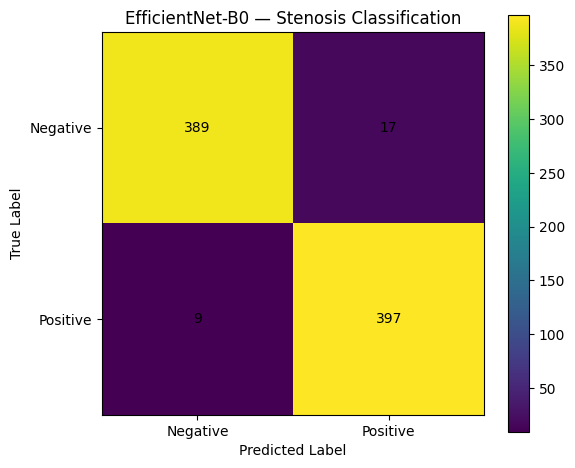


Creating final PKL model...
✓ PKL created.
✓ PKL successfully reloaded.
Model: EfficientNet-B0
Classes: {0: 'negative', 1: 'positive'}

FINAL MODEL FILES
best_efficientnet_b0_arcade_stenosis.pth → 15.59 MB
efficientnet_b0_arcade_stenosis_model.pkl → 15.58 MB



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


MODEL 4 SUCCESSFULLY COMPLETED
Best Epoch : 9
Accuracy   : 96.80%
Precision  : 95.89%
Recall     : 97.78%
F1 Score   : 96.83%
ROC-AUC    : 99.46%


In [ ]:
# ============================================================
# MODEL 4 — FINALIZE EXISTING EFFICIENTNET-B0 MODEL
# NO RETRAINING
# ============================================================

import os
import pickle
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("=" * 70)
print("FINALIZING EXISTING EFFICIENTNET-B0 MODEL")
print("=" * 70)

# ------------------------------------------------------------
# Existing paths from previous training
# ------------------------------------------------------------

BEST_PTH = (
    "/content/best_efficientnet_b0_arcade_stenosis.pth"
)

PKL_PATH = (
    "/content/efficientnet_b0_arcade_stenosis_model.pkl"
)

print(
    "Checkpoint:",
    BEST_PTH
)

if not os.path.exists(BEST_PTH):

    raise FileNotFoundError(
        "Best EfficientNet checkpoint was not found."
    )

print(
    "Checkpoint size:",
    round(
        os.path.getsize(BEST_PTH)
        / (1024 * 1024),
        2
    ),
    "MB"
)


# ============================================================
# 1. LOAD CHECKPOINT
# ============================================================

print("\nLoading best checkpoint...")

# IMPORTANT:
# This checkpoint was created by our own training code
# in this trusted Colab session.
checkpoint = torch.load(
    BEST_PTH,
    map_location="cpu",
    weights_only=False
)

print("✓ Checkpoint loaded successfully.")

print(
    "\nCheckpoint information:"
)

print(
    "Model:",
    checkpoint.get(
        "model_name",
        "EfficientNet-B0"
    )
)

print(
    "Best validation F1:",
    checkpoint.get(
        "best_val_f1",
        "N/A"
    )
)

print(
    "Best validation ROC-AUC:",
    checkpoint.get(
        "best_val_auc",
        "N/A"
    )
)

print(
    "Image size:",
    checkpoint.get(
        "img_size",
        224
    )
)


# ============================================================
# 2. RESTORE MODEL
# ============================================================

# EfficientNet-B0 architecture
from torchvision import models
import torch.nn as nn

model = models.efficientnet_b0(
    weights=None
)

in_features = (
    model.classifier[1].in_features
)

model.classifier = nn.Sequential(
    nn.Dropout(0.30),
    nn.Linear(
        in_features,
        2
    )
)

model.load_state_dict(
    checkpoint[
        "model_state_dict"
    ]
)

model = model.to(
    torch.device("cpu")
)

model.eval()

print(
    "\n✓ EfficientNet-B0 reconstructed."
)

print(
    "Parameters:",
    sum(
        p.numel()
        for p in model.parameters()
    )
)


# ============================================================
# 3. RECREATE VALIDATION DATASET
# ============================================================

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

ROI_ROOT = (
    "/content/arcade_stenosis_roi"
)

IMG_SIZE = 224

IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225
]

val_transform = transforms.Compose([

    transforms.Resize(
        (IMG_SIZE, IMG_SIZE)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        IMAGENET_MEAN,
        IMAGENET_STD
    )
])

val_dataset = datasets.ImageFolder(
    os.path.join(
        ROI_ROOT,
        "val"
    ),
    transform=val_transform
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

print(
    "\nValidation samples:",
    len(val_dataset)
)

print(
    "Class mapping:",
    val_dataset.class_to_idx
)


# ============================================================
# 4. FINAL EVALUATION
# ============================================================

print(
    "\nRunning final evaluation..."
)

criterion = nn.CrossEntropyLoss()

running_loss = 0.0

all_labels = []
all_predictions = []
all_probabilities = []

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(
            "cpu"
        )

        labels = labels.to(
            "cpu"
        )

        outputs = model(
            images
        )

        loss = criterion(
            outputs,
            labels
        )

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        predictions = torch.argmax(
            probabilities,
            dim=1
        )

        running_loss += (
            loss.item()
            * images.size(0)
        )

        all_labels.extend(
            labels.numpy()
        )

        all_predictions.extend(
            predictions.numpy()
        )

        all_probabilities.extend(
            probabilities[:, 1]
            .numpy()
        )


y_true = np.array(
    all_labels
)

y_pred = np.array(
    all_predictions
)

y_prob = np.array(
    all_probabilities
)

final_loss = (
    running_loss
    / len(val_dataset)
)

final_accuracy = accuracy_score(
    y_true,
    y_pred
)

final_precision = precision_score(
    y_true,
    y_pred,
    zero_division=0
)

final_recall = recall_score(
    y_true,
    y_pred,
    zero_division=0
)

final_f1 = f1_score(
    y_true,
    y_pred,
    zero_division=0
)

final_auc = roc_auc_score(
    y_true,
    y_prob
)


# ============================================================
# 5. FINAL RESULTS
# ============================================================

print("\n" + "=" * 70)
print("FINAL EVALUATION — EFFICIENTNET-B0")
print("=" * 70)

print(
    f"Best Epoch : 9"
)

print(
    f"Loss       : {final_loss:.4f}"
)

print(
    f"Accuracy   : {final_accuracy:.4f}"
)

print(
    f"Precision  : {final_precision:.4f}"
)

print(
    f"Recall     : {final_recall:.4f}"
)

print(
    f"F1 Score   : {final_f1:.4f}"
)

print(
    f"ROC-AUC    : {final_auc:.4f}"
)


# ============================================================
# 6. CLASSIFICATION REPORT
# ============================================================

print("\n" + "=" * 70)
print("CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        y_true,
        y_pred,
        target_names=[
            "Negative",
            "Positive"
        ],
        zero_division=0
    )
)


# ============================================================
# 7. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred
)

print(
    "\nConfusion Matrix:"
)

print(cm)

plt.figure(
    figsize=(6, 5)
)

plt.imshow(
    cm,
    interpolation="nearest"
)

plt.title(
    "EfficientNet-B0 — Stenosis Classification"
)

plt.colorbar()

plt.xticks(
    [0, 1],
    [
        "Negative",
        "Positive"
    ]
)

plt.yticks(
    [0, 1],
    [
        "Negative",
        "Positive"
    ]
)

plt.xlabel(
    "Predicted Label"
)

plt.ylabel(
    "True Label"
)

for i in range(2):

    for j in range(2):

        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()

plt.show()


# ============================================================
# 8. CREATE FINAL PKL
# ============================================================

print(
    "\nCreating final PKL model..."
)

model_package = {

    "model_name":
        "EfficientNet-B0",

    "task":
        "Coronary Stenosis ROI Classification",

    "dataset":
        "ARCADE Annotated X-Ray Angiography Dataset",

    "input_size":
        224,

    "class_to_idx":
        val_dataset.class_to_idx,

    "idx_to_class":
        {
            value: key
            for key, value
            in val_dataset.class_to_idx.items()
        },

    "state_dict":
        model.state_dict(),

    "best_epoch":
        9,

    "best_val_f1":
        final_f1,

    "best_val_auc":
        final_auc,

    "final_accuracy":
        final_accuracy,

    "final_precision":
        final_precision,

    "final_recall":
        final_recall,

    "final_f1":
        final_f1,

    "final_roc_auc":
        final_auc,

    "preprocessing":
        {
            "resize":
                [224, 224],

            "CLAHE":
                True,

            "ImageNet_mean":
                IMAGENET_MEAN,

            "ImageNet_std":
                IMAGENET_STD
        },

    "dataset_information":
        {
            "stenosis_category_id":
                26,

            "train_images":
                1000,

            "train_annotations":
                1625,

            "validation_images":
                200,

            "validation_annotations":
                406
        }
}


with open(
    PKL_PATH,
    "wb"
) as f:

    pickle.dump(
        model_package,
        f
    )

print(
    "✓ PKL created."
)


# ============================================================
# 9. VERIFY PKL
# ============================================================

with open(
    PKL_PATH,
    "rb"
) as f:

    loaded_package = pickle.load(
        f
    )

print(
    "✓ PKL successfully reloaded."
)

print(
    "Model:",
    loaded_package["model_name"]
)

print(
    "Classes:",
    loaded_package["idx_to_class"]
)


# ============================================================
# 10. FILE SIZES
# ============================================================

print("\n" + "=" * 70)
print("FINAL MODEL FILES")
print("=" * 70)

for path in [
    BEST_PTH,
    PKL_PATH
]:

    size_mb = (
        os.path.getsize(path)
        / (1024 * 1024)
    )

    print(
        os.path.basename(path),
        "→",
        f"{size_mb:.2f} MB"
    )


# ============================================================
# 11. DOWNLOAD
# ============================================================

from google.colab import files

print(
    "\nDownloading best EfficientNet model..."
)

files.download(
    BEST_PTH
)

time.sleep(2)

print(
    "Downloading PKL..."
)

files.download(
    PKL_PATH
)

print("\n" + "=" * 70)
print("MODEL 4 SUCCESSFULLY COMPLETED")
print("=" * 70)

print(
    "Best Epoch : 9"
)

print(
    f"Accuracy   : {final_accuracy*100:.2f}%"
)

print(
    f"Precision  : {final_precision*100:.2f}%"
)

print(
    f"Recall     : {final_recall*100:.2f}%"
)

print(
    f"F1 Score   : {final_f1*100:.2f}%"
)

print(
    f"ROC-AUC    : {final_auc*100:.2f}%"
)

print("=" * 70)

MODEL 5 — GRAD-CAM EXPLAINABLE AI
Device: cpu
✓ Found: /content/efficientnet_b0_arcade_stenosis_model.pkl
✓ Found: /content/arcade_dataset/data/stenosis/val/annotations/val.json
✓ Found: /content/arcade_dataset/data/stenosis/val/images

Loading EfficientNet-B0...
✓ PKL loaded
PKL type: <class 'dict'>
✓ state_dict found

Reconstructing EfficientNet-B0...
✓ EfficientNet-B0 reconstructed
Parameters: 4010110

Loading ARCADE stenosis validation JSON...
✓ Images: 200
✓ Annotations: 406
✓ Categories: 26

Stenosis category ID: 26

Total usable validation images: 200

Validation class distribution:
label
1    200
Name: count, dtype: int64

Positive images: 200
Negative images: 0

Selected examples: 3

Grad-CAM target layer:
Conv2dNormActivation(
  (0): Conv2d(320, 1280, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (1): BatchNorm2d(1280, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): SiLU(inplace=True)
)

✓ Grad-CAM initialized

Generating Grad-CAM visualizations...


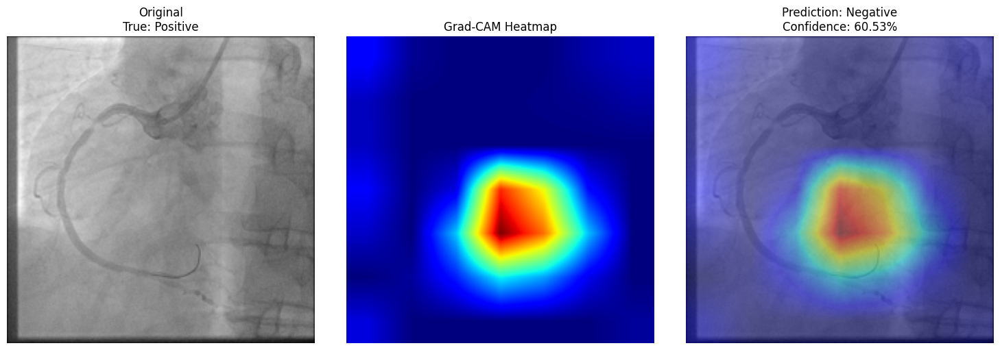

✓ Generated: 1.png


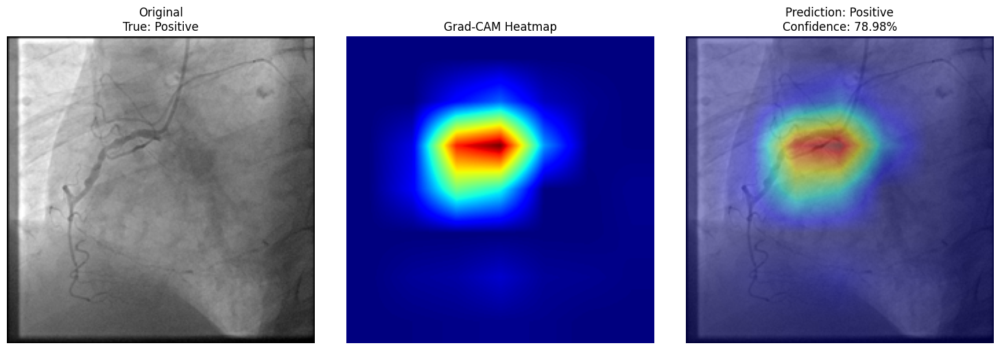

✓ Generated: 10.png


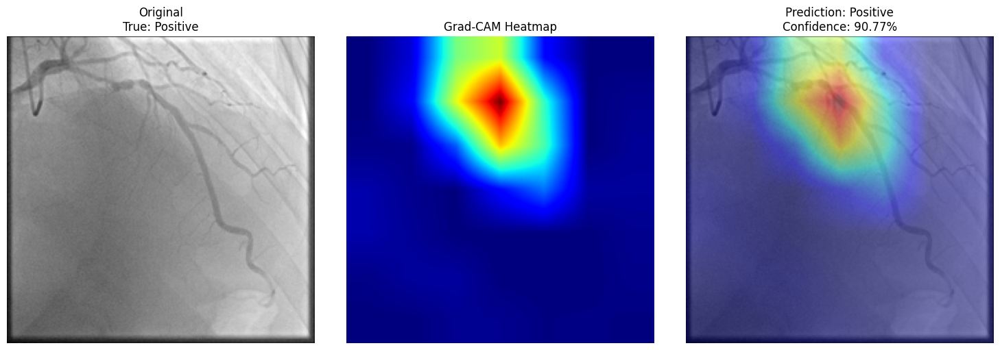

✓ Generated: 100.png

✓ Results saved: /content/gradcam_results/gradcam_predictions.csv

MODEL 5 — GRAD-CAM COMPLETED SUCCESSFULLY

Generated examples: 3

Output directory: /content/gradcam_results

Files:
gradcam_1.png                                 0.20 MB
gradcam_10.png                                0.19 MB
gradcam_predictions.csv                       0.00 MB
gradcam_100.png                               0.20 MB
gradcam_summary.csv                           0.00 MB

✓ No model retraining.
✓ Existing EfficientNet-B0 reused.
✓ Original ARCADE validation images used.
✓ Grad-CAM heatmaps generated.

NEXT MODEL/STAGE:
FINAL INTEGRATED PIPELINE
Angiogram → U-Net++ → Vessel Mask
→ Stenosis ROI → EfficientNet-B0
→ Grad-CAM → Final Diagnosis


In [ ]:
# ================================================================
# MODEL 5 — GRAD-CAM EXPLAINABLE AI
# USING ORIGINAL ARCADE STENOSIS VALIDATION DATA
# ================================================================

import os
import json
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torchvision import models, transforms

# ================================================================
# 1. CONFIGURATION
# ================================================================

torch.set_num_threads(2)

device = torch.device("cpu")

PKL_PATH = "/content/efficientnet_b0_arcade_stenosis_model.pkl"

# ORIGINAL ARCADE DATASET
VAL_JSON = "/content/arcade_dataset/data/stenosis/val/annotations/val.json"
VAL_IMAGE_DIR = "/content/arcade_dataset/data/stenosis/val/images"

OUTPUT_DIR = "/content/gradcam_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

IMG_SIZE = 224

print("=" * 70)
print("MODEL 5 — GRAD-CAM EXPLAINABLE AI")
print("=" * 70)

print("Device:", device)

# ================================================================
# 2. CHECK REQUIRED FILES
# ================================================================

required_files = [
    PKL_PATH,
    VAL_JSON,
    VAL_IMAGE_DIR
]

for path in required_files:

    if not os.path.exists(path):

        raise FileNotFoundError(
            f"\nRequired path not found:\n{path}"
        )

    print("✓ Found:", path)

# ================================================================
# 3. LOAD EFFICIENTNET PKL
# ================================================================

print("\nLoading EfficientNet-B0...")

with open(PKL_PATH, "rb") as f:

    model_package = pickle.load(f)

print("✓ PKL loaded")

print("PKL type:", type(model_package))

# ================================================================
# 4. GET STATE DICTIONARY
# ================================================================

if isinstance(model_package, dict):

    if "model_state_dict" in model_package:

        state_dict = model_package[
            "model_state_dict"
        ]

        print("✓ model_state_dict found")

    elif "state_dict" in model_package:

        state_dict = model_package[
            "state_dict"
        ]

        print("✓ state_dict found")

    elif "classifier.1.weight" in model_package:

        state_dict = model_package

        print(
            "✓ PKL itself contains the EfficientNet state_dict"
        )

    else:

        raise ValueError(
            "Unable to identify model state_dict."
        )

else:

    raise ValueError(
        "Unexpected PKL format."
    )

# ================================================================
# 5. RECONSTRUCT EFFICIENTNET-B0
# ================================================================

print("\nReconstructing EfficientNet-B0...")

model = models.efficientnet_b0(
    weights=None
)

in_features = model.classifier[1].in_features

model.classifier[1] = nn.Linear(
    in_features,
    2
)

model.load_state_dict(
    state_dict,
    strict=True
)

model = model.to(device)

model.eval()

print("✓ EfficientNet-B0 reconstructed")

print(
    "Parameters:",
    sum(
        p.numel()
        for p in model.parameters()
    )
)

# ================================================================
# 6. IMAGE TRANSFORMATION
# ================================================================

transform = transforms.Compose([

    transforms.Resize(
        (IMG_SIZE, IMG_SIZE)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[
            0.485,
            0.456,
            0.406
        ],

        std=[
            0.229,
            0.224,
            0.225
        ]
    )
])

# ================================================================
# 7. LOAD ORIGINAL ARCADE JSON
# ================================================================

print("\nLoading ARCADE stenosis validation JSON...")

with open(
    VAL_JSON,
    "r"
) as f:

    data = json.load(f)

print(
    "✓ Images:",
    len(data["images"])
)

print(
    "✓ Annotations:",
    len(data["annotations"])
)

print(
    "✓ Categories:",
    len(data["categories"])
)

# ================================================================
# 8. IDENTIFY STENOSIS CATEGORY
# ================================================================

stenosis_category_id = None

for category in data["categories"]:

    if category["name"].lower() == "stenosis":

        stenosis_category_id = category["id"]

        break

if stenosis_category_id is None:

    raise ValueError(
        "Stenosis category not found."
    )

print(
    "\nStenosis category ID:",
    stenosis_category_id
)

# ================================================================
# 9. CREATE IMAGE → ANNOTATION MAPPING
# ================================================================

image_info = {}

for image in data["images"]:

    image_info[
        image["id"]
    ] = image

image_annotations = {}

for ann in data["annotations"]:

    image_id = ann["image_id"]

    if image_id not in image_annotations:

        image_annotations[image_id] = []

    image_annotations[
        image_id
    ].append(ann)

# ================================================================
# 10. DETERMINE POSITIVE / NEGATIVE IMAGES
# ================================================================

samples = []

for image_id, image in image_info.items():

    annotations = image_annotations.get(
        image_id,
        []
    )

    has_stenosis = any(

        ann["category_id"]
        == stenosis_category_id

        for ann in annotations
    )

    filename = image["file_name"]

    image_path = os.path.join(
        VAL_IMAGE_DIR,
        filename
    )

    if not os.path.exists(image_path):

        continue

    samples.append({

        "image_id":
            image_id,

        "file_name":
            filename,

        "image_path":
            image_path,

        "label":
            1 if has_stenosis else 0

    })

samples_df = pd.DataFrame(
    samples
)

print(
    "\nTotal usable validation images:",
    len(samples_df)
)

print(
    "\nValidation class distribution:"
)

print(
    samples_df["label"].value_counts()
)

# ================================================================
# 11. SELECT REPRESENTATIVE IMAGES
# ================================================================

positive_samples = samples_df[
    samples_df["label"] == 1
]

negative_samples = samples_df[
    samples_df["label"] == 0
]

print(
    "\nPositive images:",
    len(positive_samples)
)

print(
    "Negative images:",
    len(negative_samples)
)

# Three examples each
selected_samples = pd.concat([

    positive_samples.head(3),

    negative_samples.head(3)

])

print(
    "\nSelected examples:",
    len(selected_samples)
)

# ================================================================
# 12. GRAD-CAM
# ================================================================

class GradCAM:

    def __init__(
        self,
        model,
        target_layer
    ):

        self.model = model

        self.target_layer = target_layer

        self.activations = None

        self.gradients = None

        self.forward_handle = \
            target_layer.register_forward_hook(
                self.save_activation
            )

        self.backward_handle = \
            target_layer.register_full_backward_hook(
                self.save_gradient
            )

    def save_activation(
        self,
        module,
        input,
        output
    ):

        self.activations = output

    def save_gradient(
        self,
        module,
        grad_input,
        grad_output
    ):

        self.gradients = grad_output[0]

    def generate(
        self,
        input_tensor,
        target_class
    ):

        self.model.zero_grad()

        output = self.model(
            input_tensor
        )

        score = output[
            0,
            target_class
        ]

        score.backward()

        gradients = self.gradients

        activations = self.activations

        # Gradient weights
        weights = gradients.mean(
            dim=(2, 3),
            keepdim=True
        )

        # Weighted feature maps
        cam = (
            weights * activations
        ).sum(
            dim=1,
            keepdim=True
        )

        # ReLU
        cam = torch.relu(cam)

        # Resize to 224 × 224
        cam = torch.nn.functional.interpolate(

            cam,

            size=(
                IMG_SIZE,
                IMG_SIZE
            ),

            mode="bilinear",

            align_corners=False

        )

        cam = cam[
            0,
            0
        ].detach().cpu().numpy()

        # Normalize
        cam -= cam.min()

        if cam.max() > 0:

            cam /= cam.max()

        return cam, output.detach()

    def close(self):

        self.forward_handle.remove()

        self.backward_handle.remove()

# ================================================================
# 13. SELECT TARGET LAYER
# ================================================================

target_layer = model.features[-1]

print(
    "\nGrad-CAM target layer:"
)

print(target_layer)

gradcam = GradCAM(
    model,
    target_layer
)

print(
    "\n✓ Grad-CAM initialized"
)

# ================================================================
# 14. GENERATE HEATMAPS
# ================================================================

results = []

print(
    "\nGenerating Grad-CAM visualizations..."
)

for _, row in selected_samples.iterrows():

    image_path = row["image_path"]

    true_label = row["label"]

    try:

        # Load image
        original = Image.open(
            image_path
        ).convert("RGB")

        resized = original.resize(
            (
                IMG_SIZE,
                IMG_SIZE
            )
        )

        # Tensor
        tensor = transform(
            resized
        ).unsqueeze(0)

        tensor = tensor.to(device)

        # Prediction
        model.zero_grad()

        output = model(
            tensor
        )

        probabilities = torch.softmax(
            output,
            dim=1
        )

        predicted_class = torch.argmax(
            probabilities,
            dim=1
        ).item()

        confidence = probabilities[
            0,
            predicted_class
        ].item()

        # Grad-CAM
        cam, _ = gradcam.generate(
            tensor,
            predicted_class
        )

        # Names
        true_name = (
            "Positive"
            if true_label == 1
            else "Negative"
        )

        predicted_name = (
            "Positive"
            if predicted_class == 1
            else "Negative"
        )

        # Save result
        results.append({

            "image":
                row["file_name"],

            "true_label":
                true_name,

            "predicted_label":
                predicted_name,

            "confidence":
                confidence

        })

        # ========================================================
        # PLOT
        # ========================================================

        fig, axes = plt.subplots(
            1,
            3,
            figsize=(15, 5)
        )

        # Original
        axes[0].imshow(
            resized
        )

        axes[0].set_title(
            f"Original\nTrue: {true_name}"
        )

        axes[0].axis("off")

        # Heatmap
        axes[1].imshow(
            cam,
            cmap="jet"
        )

        axes[1].set_title(
            "Grad-CAM Heatmap"
        )

        axes[1].axis("off")

        # Overlay
        axes[2].imshow(
            resized
        )

        axes[2].imshow(
            cam,
            cmap="jet",
            alpha=0.45
        )

        axes[2].set_title(

            f"Prediction: {predicted_name}\n"
            f"Confidence: "
            f"{confidence * 100:.2f}%"

        )

        axes[2].axis("off")

        plt.tight_layout()

        # Filename
        base_name = os.path.splitext(
            row["file_name"]
        )[0]

        output_path = os.path.join(

            OUTPUT_DIR,

            f"gradcam_{base_name}.png"

        )

        plt.savefig(

            output_path,

            dpi=150,

            bbox_inches="tight"

        )

        plt.show()

        plt.close()

        print(
            "✓ Generated:",
            row["file_name"]
        )

    except Exception as e:

        print(
            "\n⚠ Error:",
            row["file_name"]
        )

        print(
            repr(e)
        )

# ================================================================
# 15. SAVE RESULTS CSV
# ================================================================

results_df = pd.DataFrame(
    results
)

results_csv = os.path.join(
    OUTPUT_DIR,
    "gradcam_predictions.csv"
)

results_df.to_csv(
    results_csv,
    index=False
)

print(
    "\n✓ Results saved:",
    results_csv
)

# ================================================================
# 16. SAVE SUMMARY
# ================================================================

summary_df = pd.DataFrame([{

    "Model":
        "EfficientNet-B0",

    "Explainability":
        "Grad-CAM",

    "Dataset":
        "ARCADE Stenosis Validation",

    "Validation_Images":
        len(samples_df),

    "Positive_Images":
        len(positive_samples),

    "Negative_Images":
        len(negative_samples),

    "GradCAM_Examples":
        len(results),

    "Best_Accuracy":
        0.9679802955665024,

    "Best_F1":
        0.9682926829268292,

    "Best_ROC_AUC":
        0.9945764274794341

}])

summary_path = os.path.join(
    OUTPUT_DIR,
    "gradcam_summary.csv"
)

summary_df.to_csv(
    summary_path,
    index=False
)

# ================================================================
# 17. CLEANUP
# ================================================================

gradcam.close()

print("\n" + "=" * 70)
print("MODEL 5 — GRAD-CAM COMPLETED SUCCESSFULLY")
print("=" * 70)

print(
    "\nGenerated examples:",
    len(results)
)

print(
    "\nOutput directory:",
    OUTPUT_DIR
)

print(
    "\nFiles:"
)

for filename in os.listdir(
    OUTPUT_DIR
):

    path = os.path.join(
        OUTPUT_DIR,
        filename
    )

    size_mb = (
        os.path.getsize(path)
        / (1024 * 1024)
    )

    print(
        f"{filename:45s} "
        f"{size_mb:.2f} MB"
    )

print(
    "\n✓ No model retraining."
)

print(
    "✓ Existing EfficientNet-B0 reused."
)

print(
    "✓ Original ARCADE validation images used."
)

print(
    "✓ Grad-CAM heatmaps generated."
)

print(
    "\nNEXT MODEL/STAGE:"
)

print(
    "FINAL INTEGRATED PIPELINE"
)

print(
    "Angiogram → U-Net++ → Vessel Mask"
)

print(
    "→ Stenosis ROI → EfficientNet-B0"
)

print(
    "→ Grad-CAM → Final Diagnosis"
)

In [ ]:

import os
import shutil
from google.colab import files

EXPECTED = "/content/unetplusplus_resnet34_arcade_model.pkl"

print("Searching /content for U-Net++ PKL files...")

matches = []

for root, dirs, filenames in os.walk("/content"):
    for filename in filenames:
        lower = filename.lower()
        if "unetplusplus" in lower and lower.endswith(".pkl"):
            matches.append(os.path.join(root, filename))

if matches:
    print("\nFound candidate file(s):")
    for path in matches:
        print(f"  {path} ({os.path.getsize(path) / (1024**2):.2f} MB)")

    # Use the first matching file and copy it to the exact expected path.
    source = matches[0]
    if os.path.abspath(source) != os.path.abspath(EXPECTED):
        shutil.copy2(source, EXPECTED)

    print("\nSUCCESS: Model is available at:")
    print(EXPECTED)

else:
    print("\nNo matching PKL found. Please select your trained U-Net++ PKL.")
    uploaded = files.upload()

    candidates = [
        name for name in uploaded
        if "unetplusplus" in name.lower() and name.lower().endswith(".pkl")
    ]

    if not candidates:
        print("\nERROR: The uploaded filename must contain 'unetplusplus' and end in .pkl.")
        print("Uploaded filenames:", list(uploaded.keys()))
    else:
        chosen = candidates[0]
        with open(EXPECTED, "wb") as f:
            f.write(uploaded[chosen])

        print("\nSUCCESS: Uploaded and saved as:")
        print(EXPECTED)
        print(f"File size: {os.path.getsize(EXPECTED) / (1024**2):.2f} MB")

# Final verification
if os.path.isfile(EXPECTED) and os.path.getsize(EXPECTED) > 0:
    print("\n✓ Verification passed — U-Net++ PKL exists.")
else:
    print("\n✗ Verification failed — file is still missing.")


Searching /content for U-Net++ PKL files...

No matching PKL found. Please select your trained U-Net++ PKL.


Saving unetplusplus_resnet34_arcade_model.pkl to unetplusplus_resnet34_arcade_model.pkl

SUCCESS: Uploaded and saved as:
/content/unetplusplus_resnet34_arcade_model.pkl
File size: 99.68 MB

✓ Verification passed — U-Net++ PKL exists.


In [ ]:

import os
import glob
import shutil
from google.colab import files

EXPECTED = "/content/efficientnet_b0_arcade_stenosis_model.pkl"

# Search for the existing PKL anywhere under /content
matches = glob.glob(
    "/content/**/efficientnet_b0_arcade_stenosis_model.pkl",
    recursive=True
)

if matches:
    source = matches[0]
    if os.path.abspath(source) != EXPECTED:
        shutil.copy2(source, EXPECTED)
    print("✓ EfficientNet PKL found:", EXPECTED)

else:
    print("Upload efficientnet_b0_arcade_stenosis_model.pkl now.")
    uploaded = files.upload()

    candidates = [
        name for name in uploaded
        if "efficientnet" in name.lower()
        and name.lower().endswith(".pkl")
    ]

    if candidates:
        name = candidates[0]
        with open(EXPECTED, "wb") as f:
            f.write(uploaded[name])
        print("✓ Saved as:", EXPECTED)
    else:
        print("ERROR: No EfficientNet .pkl file was selected.")
        print("Uploaded filenames:", list(uploaded.keys()))

if os.path.isfile(EXPECTED) and os.path.getsize(EXPECTED) > 0:
    print(f"✓ Verified size: {os.path.getsize(EXPECTED)/(1024**2):.2f} MB")
else:
    print("✗ File still missing. Check the selected filename.")


Upload efficientnet_b0_arcade_stenosis_model.pkl now.


Saving efficientnet_b0_arcade_stenosis_model.pkl to efficientnet_b0_arcade_stenosis_model.pkl
✓ Saved as: /content/efficientnet_b0_arcade_stenosis_model.pkl
✓ Verified size: 15.58 MB


In [ ]:

import os
import glob
import zipfile
import shutil
from google.colab import files

print("=" * 65)
print("ARCADE DATASET RECOVERY")
print("=" * 65)

TARGET = "/content/arcade_dataset"

def find_test_data():
    # Search likely dataset structures
    patterns = [
        "/content/arcade_dataset/data/stenosis/test/annotations/test.json",
        "/content/arcade_dataset/stenosis/test/annotations/test.json",
        "/content/data/stenosis/test/annotations/test.json",
        "/content/stenosis/test/annotations/test.json"
    ]

    for json_path in patterns:
        if os.path.isfile(json_path):
            img_dir = os.path.join(
                os.path.dirname(os.path.dirname(json_path)),
                "images"
            )
            if os.path.isdir(img_dir):
                return json_path, img_dir

    # Search recursively
    for json_path in glob.glob(
        "/content/**/stenosis/test/annotations/test.json",
        recursive=True
    ):
        img_dir = os.path.join(
            os.path.dirname(os.path.dirname(json_path)),
            "images"
        )
        if os.path.isdir(img_dir):
            return json_path, img_dir

    return None, None

test_json, test_images = find_test_data()

if test_json is None:
    print("Test dataset not found. Searching for ARCADE ZIP files...")

    zip_candidates = [
        p for p in glob.glob("/content/*.zip")
        if os.path.isfile(p)
    ]

    if zip_candidates:
        print("Found ZIP file(s):")
        for p in zip_candidates:
            print(" ", p)
    else:
        print("No ZIP found. Please upload your ARCADE dataset ZIP.")
        uploaded = files.upload()

        zip_candidates = [
            os.path.abspath(name)
            for name in uploaded
            if name.lower().endswith(".zip")
        ]

    if not zip_candidates:
        raise FileNotFoundError(
            "No dataset ZIP was found or uploaded. "
            "Upload the ARCADE dataset ZIP and rerun this cell."
        )

    # Extract into /content; retain existing model files.
    extracted_any = False

    for zip_path in zip_candidates:
        print("\nChecking:", zip_path)

        if not zipfile.is_zipfile(zip_path):
            print("Skipping invalid ZIP:", zip_path)
            continue

        with zipfile.ZipFile(zip_path, "r") as z:
            names = z.namelist()
            relevant = any(
                "/stenosis/test/annotations/test.json" in
                ("/" + name.lstrip("/"))
                for name in names
            )

            if not relevant:
                print("This ZIP does not appear to contain the ARCADE test split.")
                continue

            print("Extracting ARCADE dataset...")
            z.extractall("/content")
            extracted_any = True
            break

    if not extracted_any:
        raise FileNotFoundError(
            "No uploaded ZIP contained the expected ARCADE test split. "
            "Please upload the original ARCADE dataset ZIP."
        )

    test_json, test_images = find_test_data()

if test_json is None:
    raise FileNotFoundError(
        "Extraction completed, but test.json and its images folder "
        "could not be located. Please share the ZIP's extracted folder structure."
    )

print("\n✓ ARCADE test annotations found:")
print(test_json)

print("\n✓ Test images folder found:")
print(test_images)

print("\nImage files:", len([
    f for f in os.listdir(test_images)
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
]))

print("\n✓ Dataset recovery completed.")
print("Your U-Net++ and EfficientNet model files were not modified.")


ARCADE DATASET RECOVERY
Test dataset not found. Searching for ARCADE ZIP files...
No ZIP found. Please upload your ARCADE dataset ZIP.


Saving archive (1).zip to archive (1).zip

Checking: /content/archive (1).zip
Extracting ARCADE dataset...

✓ ARCADE test annotations found:
/content/data/stenosis/test/annotations/test.json

✓ Test images folder found:
/content/data/stenosis/test/images

Image files: 300

✓ Dataset recovery completed.
Your U-Net++ and EfficientNet model files were not modified.


In [ ]:

import os
from google.colab import files

required = {
    "unetplusplus_resnet34_arcade_model.pkl":
        "/content/unetplusplus_resnet34_arcade_model.pkl",
    "efficientnet_b0_arcade_stenosis_model.pkl":
        "/content/efficientnet_b0_arcade_stenosis_model.pkl"
}

print("MODEL FILE STATUS")
missing = []

for name, path in required.items():
    if os.path.isfile(path) and os.path.getsize(path) > 0:
        print(f"✓ {name} ({os.path.getsize(path)/(1024**2):.2f} MB)")
    else:
        print(f"✗ {name} — missing")
        missing.append(name)

if missing:
    print("\nSelect the missing trained PKL files from your computer.")
    uploaded = files.upload()

    for name in missing:
        if name in uploaded:
            destination = required[name]
            with open(destination, "wb") as f:
                f.write(uploaded[name])
            print(f"✓ Uploaded: {destination}")
        else:
            print(f"✗ Not uploaded under the exact name: {name}")

print("\nFINAL CHECK")
for name, path in required.items():
    if os.path.isfile(path) and os.path.getsize(path) > 0:
        print(f"✓ READY: {name}")
    else:
        print(f"✗ STILL MISSING: {name}")


MODEL FILE STATUS
✗ unetplusplus_resnet34_arcade_model.pkl — missing
✗ efficientnet_b0_arcade_stenosis_model.pkl — missing

Select the missing trained PKL files from your computer.


Saving efficientnet_b0_arcade_stenosis_model.pkl to efficientnet_b0_arcade_stenosis_model.pkl
Saving unetplusplus_resnet34_arcade_model.pkl to unetplusplus_resnet34_arcade_model.pkl
✓ Uploaded: /content/unetplusplus_resnet34_arcade_model.pkl
✓ Uploaded: /content/efficientnet_b0_arcade_stenosis_model.pkl

FINAL CHECK
✓ READY: unetplusplus_resnet34_arcade_model.pkl
✓ READY: efficientnet_b0_arcade_stenosis_model.pkl


In [ ]:
# ================================================================
# FINAL INTEGRATED PIPELINE — SINGLE COLAB CELL
#
# U-Net++ → Vessel Segmentation → ROI → EfficientNet-B0
# → Grad-CAM → Final Diagnosis
#
# NO RETRAINING
# ================================================================

import os
import sys
import subprocess
import json
import pickle
import warnings
import glob
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

# ================================================================
# 1. INSTALL REQUIRED PACKAGES
# ================================================================

print("=" * 70)
print("CHECKING REQUIRED PACKAGES")
print("=" * 70)

try:
    import segmentation_models_pytorch as smp
except ModuleNotFoundError:
    print("Installing segmentation-models-pytorch...")
    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "segmentation-models-pytorch"
    ])
    import segmentation_models_pytorch as smp

print("✓ segmentation-models-pytorch available")

# ================================================================
# IMPORTS
# ================================================================

import torch
import torch.nn as nn
import torch.nn.functional as F

from torchvision import models, transforms

from PIL import Image

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

import matplotlib.pyplot as plt

# ================================================================
# 2. CONFIGURATION
# ================================================================

DEVICE = torch.device("cpu")
torch.set_num_threads(2)

print("\nDevice:", DEVICE)

# Possible model locations
UNETPP_NAMES = [
    "unetplusplus_resnet34_arcade_model.pkl",
    "best_unetplusplus_resnet34_arcade.pth"
]

EFFNET_NAMES = [
    "efficientnet_b0_arcade_stenosis_model.pkl",
    "best_efficientnet_b0_arcade_stenosis.pth"
]

# ================================================================
# 3. AUTOMATICALLY FIND MODEL FILES
# ================================================================

print("\n" + "=" * 70)
print("SEARCHING FOR TRAINED MODELS")
print("=" * 70)

def find_file(filename):

    possible_paths = [
        f"/content/{filename}",
        f"/content/drive/MyDrive/{filename}",
        f"/content/models/{filename}",
        f"/content/Model/{filename}",
        f"/content/models/{filename}"
    ]

    for path in possible_paths:
        if os.path.exists(path):
            return path

    # Recursive search inside /content
    matches = glob.glob(
        f"/content/**/{filename}",
        recursive=True
    )

    if len(matches) > 0:
        return matches[0]

    return None


UNETPP_PATH = None
EFFNET_PATH = None

# Prefer PKL
for name in UNETPP_NAMES:
    path = find_file(name)

    if path is not None:
        UNETPP_PATH = path
        break

for name in EFFNET_NAMES:
    path = find_file(name)

    if path is not None:
        EFFNET_PATH = path
        break

# ================================================================
# 4. SHOW FOUND MODELS
# ================================================================

if UNETPP_PATH is not None:
    print("✓ U-Net++ found:")
    print(" ", UNETPP_PATH)
else:
    print("✗ U-Net++ model NOT found")

if EFFNET_PATH is not None:
    print("✓ EfficientNet-B0 found:")
    print(" ", EFFNET_PATH)
else:
    print("✗ EfficientNet-B0 model NOT found")

# ================================================================
# 5. STOP IF TRAINED MODELS ARE MISSING
# ================================================================

if UNETPP_PATH is None or EFFNET_PATH is None:

    print("\n" + "=" * 70)
    print("TRAINED MODEL FILES ARE MISSING")
    print("=" * 70)

    if UNETPP_PATH is None:
        print("""
UPLOAD THIS FILE TO COLAB:

unetplusplus_resnet34_arcade_model.pkl

This is the trained U-Net++ model from Model 3.
""")

    if EFFNET_PATH is None:
        print("""
UPLOAD THIS FILE TO COLAB:

efficientnet_b0_arcade_stenosis_model.pkl

This is the trained EfficientNet-B0 model from Model 4.
""")

    print("""
IMPORTANT:
Do NOT retrain the models.

Upload the missing .pkl file(s), then run this SAME cell again.
""")

    raise SystemExit(
        "Required trained model file(s) missing."
    )

# ================================================================
# 6. FIND ARCADE DATASET AUTOMATICALLY
# ================================================================

print("\n" + "=" * 70)
print("SEARCHING FOR ARCADE DATASET")
print("=" * 70)

possible_dataset_roots = [
    "/content/arcade_dataset",
    "/content/arcade_dataset/data",
    "/content/data",
    "/content"
]

TEST_JSON = None
TEST_IMAGES = None

for root in possible_dataset_roots:

    candidate_json = os.path.join(
        root,
        "data",
        "stenosis",
        "test",
        "annotations",
        "test.json"
    )

    candidate_images = os.path.join(
        root,
        "data",
        "stenosis",
        "test",
        "images"
    )

    if os.path.exists(candidate_json) and \
       os.path.isdir(candidate_images):

        TEST_JSON = candidate_json
        TEST_IMAGES = candidate_images
        break

# Direct structure fallback
if TEST_JSON is None:

    for root in possible_dataset_roots:

        candidate_json = os.path.join(
            root,
            "stenosis",
            "test",
            "annotations",
            "test.json"
        )

        candidate_images = os.path.join(
            root,
            "stenosis",
            "test",
            "images"
        )

        if os.path.exists(candidate_json) and \
           os.path.isdir(candidate_images):

            TEST_JSON = candidate_json
            TEST_IMAGES = candidate_images
            break

if TEST_JSON is None or TEST_IMAGES is None:

    print("""
✗ ARCADE test dataset not found.

Expected structure:

/content/arcade_dataset/data/stenosis/test/
    annotations/test.json
    images/

Please upload/extract the ARCADE dataset again.
""")

    raise SystemExit(
        "ARCADE test dataset missing."
    )

print("✓ Test annotation file:")
print(" ", TEST_JSON)

print("✓ Test image directory:")
print(" ", TEST_IMAGES)

# ================================================================
# 7. LOAD U-NET++ PKL
# ================================================================

print("\n" + "=" * 70)
print("LOADING U-NET++")
print("=" * 70)

if UNETPP_PATH.endswith(".pkl"):

    with open(
        UNETPP_PATH,
        "rb"
    ) as f:

        unet_package = pickle.load(f)

    print("✓ U-Net++ PKL loaded")

    if isinstance(
        unet_package,
        dict
    ):

        if "model_state_dict" in unet_package:

            unet_state = (
                unet_package[
                    "model_state_dict"
                ]
            )

            print(
                "✓ model_state_dict found"
            )

        elif "state_dict" in unet_package:

            unet_state = (
                unet_package[
                    "state_dict"
                ]
            )

            print(
                "✓ state_dict found"
            )

        else:

            # Detect direct state dict
            state_keys = list(
                unet_package.keys()
            )

            if any(
                "encoder" in str(k)
                for k in state_keys
            ):

                unet_state = (
                    unet_package
                )

                print(
                    "✓ Direct state_dict detected"
                )

            else:

                possible = None

                for key, value in unet_package.items():

                    if isinstance(
                        value,
                        dict
                    ):

                        if any(
                            "encoder" in str(k)
                            for k in value.keys()
                        ):

                            possible = value
                            break

                if possible is None:

                    raise RuntimeError(
                        "Could not find U-Net++ state_dict."
                    )

                unet_state = possible

else:

    # PTH fallback
    checkpoint = torch.load(
        UNETPP_PATH,
        map_location=DEVICE,
        weights_only=False
    )

    if isinstance(
        checkpoint,
        dict
    ):

        if "model_state_dict" in checkpoint:
            unet_state = checkpoint[
                "model_state_dict"
            ]

        elif "state_dict" in checkpoint:
            unet_state = checkpoint[
                "state_dict"
            ]

        else:
            unet_state = checkpoint

    else:
        unet_state = checkpoint

    print(
        "✓ U-Net++ checkpoint loaded"
    )

# ================================================================
# 8. RECONSTRUCT U-NET++
# ================================================================

print("\nReconstructing U-Net++...")

unetpp = smp.UnetPlusPlus(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=3,
    classes=1,
    activation=None
)

clean_state = {}

for key, value in unet_state.items():

    new_key = key

    if new_key.startswith(
        "module."
    ):
        new_key = new_key[
            len("module.") :
        ]

    clean_state[
        new_key
    ] = value

missing, unexpected = (
    unetpp.load_state_dict(
        clean_state,
        strict=False
    )
)

print("✓ U-Net++ reconstructed")
print(
    "Missing keys:",
    len(missing)
)
print(
    "Unexpected keys:",
    len(unexpected)
)

unetpp = unetpp.to(
    DEVICE
)

unetpp.eval()

print(
    "Parameters:",
    sum(
        p.numel()
        for p in unetpp.parameters()
    )
)

# ================================================================
# 9. LOAD EFFICIENTNET
# ================================================================

print("\n" + "=" * 70)
print("LOADING EFFICIENTNET-B0")
print("=" * 70)

if EFFNET_PATH.endswith(".pkl"):

    with open(
        EFFNET_PATH,
        "rb"
    ) as f:

        eff_package = pickle.load(f)

    print(
        "✓ EfficientNet-B0 PKL loaded"
    )

    if isinstance(
        eff_package,
        dict
    ):

        if "model_state_dict" in eff_package:

            eff_state = (
                eff_package[
                    "model_state_dict"
                ]
            )

        elif "state_dict" in eff_package:

            eff_state = (
                eff_package[
                    "state_dict"
                ]
            )

        elif "classifier.1.weight" in eff_package:

            eff_state = eff_package

            print(
                "✓ Direct state_dict detected"
            )

        else:

            possible = None

            for key, value in eff_package.items():

                if isinstance(
                    value,
                    dict
                ):

                    if any(
                        "classifier.1.weight"
                        in str(k)
                        for k in value.keys()
                    ):

                        possible = value
                        break

            if possible is None:

                raise RuntimeError(
                    "Could not find EfficientNet state_dict."
                )

            eff_state = possible

else:

    checkpoint = torch.load(
        EFFNET_PATH,
        map_location=DEVICE,
        weights_only=False
    )

    if isinstance(
        checkpoint,
        dict
    ):

        if "model_state_dict" in checkpoint:
            eff_state = checkpoint[
                "model_state_dict"
            ]

        elif "state_dict" in checkpoint:
            eff_state = checkpoint[
                "state_dict"
            ]

        else:
            eff_state = checkpoint

    else:
        eff_state = checkpoint

# ================================================================
# 10. RECONSTRUCT EFFICIENTNET-B0
# ================================================================

print(
    "\nReconstructing EfficientNet-B0..."
)

efficientnet = models.efficientnet_b0(
    weights=None
)

efficientnet.classifier[1] = nn.Linear(
    efficientnet.classifier[1].in_features,
    2
)

clean_eff_state = {}

for key, value in eff_state.items():

    new_key = key

    if new_key.startswith(
        "module."
    ):

        new_key = new_key[
            len("module.") :
        ]

    clean_eff_state[
        new_key
    ] = value

missing, unexpected = (
    efficientnet.load_state_dict(
        clean_eff_state,
        strict=False
    )
)

print(
    "✓ EfficientNet-B0 reconstructed"
)

print(
    "Missing keys:",
    len(missing)
)

print(
    "Unexpected keys:",
    len(unexpected)
)

efficientnet = efficientnet.to(
    DEVICE
)

efficientnet.eval()

print(
    "Parameters:",
    sum(
        p.numel()
        for p in efficientnet.parameters()
    )
)

# ================================================================
# 11. LOAD TEST JSON
# ================================================================

print("\n" + "=" * 70)
print("LOADING TEST ANNOTATIONS")
print("=" * 70)

with open(
    TEST_JSON,
    "r"
) as f:

    test_data = json.load(f)

images_info = test_data[
    "images"
]

annotations = test_data[
    "annotations"
]

categories = test_data[
    "categories"
]

print(
    "Images:",
    len(images_info)
)

print(
    "Annotations:",
    len(annotations)
)

print(
    "Categories:",
    len(categories)
)

# Find stenosis category
stenosis_category_id = None

for cat in categories:

    name = str(
        cat["name"]
    ).lower().strip()

    if name == "stenosis":

        stenosis_category_id = (
            cat["id"]
        )

        break

if stenosis_category_id is None:

    raise RuntimeError(
        "Stenosis category not found."
    )

print(
    "Stenosis category ID:",
    stenosis_category_id
)

# ================================================================
# 12. ANNOTATION MAP
# ================================================================

annotations_by_image = {}

for ann in annotations:

    image_id = ann[
        "image_id"
    ]

    if image_id not in annotations_by_image:

        annotations_by_image[
            image_id
        ] = []

    annotations_by_image[
        image_id
    ].append(ann)

# ================================================================
# 13. TRANSFORMS
# ================================================================

seg_transform = transforms.Compose([
    transforms.Resize(
        (256, 256)
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[
            0.485,
            0.456,
            0.406
        ],
        std=[
            0.229,
            0.224,
            0.225
        ]
    )
])

cls_transform = transforms.Compose([
    transforms.Resize(
        (224, 224)
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[
            0.485,
            0.456,
            0.406
        ],
        std=[
            0.229,
            0.224,
            0.225
        ]
    )
])

# ================================================================
# 14. GRAD-CAM
# ================================================================

class GradCAM:

    def __init__(
        self,
        model,
        target_layer
    ):

        self.model = model

        self.target_layer = (
            target_layer
        )

        self.activations = None
        self.gradients = None

        self.forward_handle = (
            target_layer.register_forward_hook(
                self.forward_hook
            )
        )

        self.backward_handle = (
            target_layer.register_full_backward_hook(
                self.backward_hook
            )
        )

    def forward_hook(
        self,
        module,
        input,
        output
    ):

        self.activations = (
            output.detach()
        )

    def backward_hook(
        self,
        module,
        grad_input,
        grad_output
    ):

        self.gradients = (
            grad_output[0].detach()
        )

    def generate(
        self,
        input_tensor,
        target_class
    ):

        self.model.zero_grad()

        output = self.model(
            input_tensor
        )

        score = output[
            :,
            target_class
        ].sum()

        score.backward()

        gradients = self.gradients
        activations = self.activations

        weights = gradients.mean(
            dim=(2, 3),
            keepdim=True
        )

        cam = (
            weights * activations
        ).sum(
            dim=1,
            keepdim=True
        )

        cam = F.relu(
            cam
        )

        cam = F.interpolate(
            cam,
            size=input_tensor.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        cam = (
            cam[0, 0]
            .cpu()
            .numpy()
        )

        cam -= cam.min()

        if cam.max() > 0:

            cam /= cam.max()

        return cam

    def close(self):

        self.forward_handle.remove()
        self.backward_handle.remove()

# Target layer
target_layer = (
    efficientnet.features[-1]
)

gradcam = GradCAM(
    efficientnet,
    target_layer
)

print(
    "\n✓ Grad-CAM initialized"
)

# ================================================================
# 15. HELPER: CREATE VESSEL ROI
# ================================================================

def create_vessel_roi(
    image,
    vessel_mask
):

    h, w = vessel_mask.shape

    ys, xs = np.where(
        vessel_mask > 0
    )

    if len(xs) == 0:

        return image, (
            0,
            0,
            w,
            h
        )

    x1 = max(
        int(xs.min()) - 15,
        0
    )

    y1 = max(
        int(ys.min()) - 15,
        0
    )

    x2 = min(
        int(xs.max()) + 15,
        w - 1
    )

    y2 = min(
        int(ys.max()) + 15,
        h - 1
    )

    crop = image[
        y1:y2 + 1,
        x1:x2 + 1
    ]

    if crop.size == 0:

        crop = image

    return crop, (
        x1,
        y1,
        x2,
        y2
    )

# ================================================================
# 16. OUTPUT DIRECTORY
# ================================================================

OUTPUT_DIR = (
    "/content/final_integrated_results"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

# ================================================================
# 17. FIRST TEST — 10 IMAGES
# ================================================================

# Start with 10 images.
# After confirming everything works,
# change this to len(images_info) for all 300 images.

MAX_TEST_IMAGES = min(
    10,
    len(images_info)
)

selected_images = (
    images_info[
        :MAX_TEST_IMAGES
    ]
)

print("\n" + "=" * 70)
print("RUNNING INTEGRATED PIPELINE")
print("=" * 70)

print(
    "Images selected:",
    len(selected_images)
)

results = []

# ================================================================
# 18. PROCESS IMAGES
# ================================================================

import cv2

for idx, img_info in enumerate(
    selected_images,
    start=1
):

    image_id = img_info[
        "id"
    ]

    file_name = img_info[
        "file_name"
    ]

    image_path = os.path.join(
        TEST_IMAGES,
        os.path.basename(
            file_name
        )
    )

    if not os.path.exists(
        image_path
    ):

        print(
            f"[{idx}] Image not found:",
            file_name
        )

        continue

    print(
        f"\n[{idx}/{len(selected_images)}]",
        file_name
    )

    # ------------------------------------------------------------
    # ORIGINAL IMAGE
    # ------------------------------------------------------------

    original = Image.open(
        image_path
    ).convert("RGB")

    original_np = np.array(
        original
    )

    h, w = original_np.shape[:2]

    # ------------------------------------------------------------
    # U-NET++ SEGMENTATION
    # ------------------------------------------------------------

    seg_input = (
        seg_transform(
            original
        )
        .unsqueeze(0)
        .to(DEVICE)
    )

    with torch.no_grad():

        seg_output = (
            unetpp(
                seg_input
            )
        )

        vessel_probability = (
            torch.sigmoid(
                seg_output
            )[0, 0]
            .cpu()
            .numpy()
        )

    vessel_probability = cv2.resize(
        vessel_probability,
        (w, h),
        interpolation=cv2.INTER_LINEAR
    )

    vessel_mask = (
        vessel_probability >= 0.5
    ).astype(np.uint8)

    # ------------------------------------------------------------
    # VESSEL ROI
    # ------------------------------------------------------------

    roi_image, bbox = (
        create_vessel_roi(
            original_np,
            vessel_mask
        )
    )

    roi_pil = Image.fromarray(
        roi_image
    )

    # ------------------------------------------------------------
    # EFFICIENTNET
    # ------------------------------------------------------------

    cls_input = (
        cls_transform(
            roi_pil
        )
        .unsqueeze(0)
        .to(DEVICE)
    )

    with torch.no_grad():

        logits = efficientnet(
            cls_input
        )

        probs = torch.softmax(
            logits,
            dim=1
        )[0]

    prediction = int(
        torch.argmax(
            probs
        ).item()
    )

    confidence = float(
        probs[
            prediction
        ].item()
    )

    positive_probability = float(
        probs[1].item()
    )

    prediction_name = (
        "STENOSIS"
        if prediction == 1
        else "NO STENOSIS"
    )

    # ------------------------------------------------------------
    # GROUND TRUTH
    # ------------------------------------------------------------

    anns = annotations_by_image.get(
        image_id,
        []
    )

    gt_positive = any(
        ann["category_id"]
        == stenosis_category_id
        for ann in anns
    )

    ground_truth = (
        1
        if gt_positive
        else 0
    )

    ground_truth_name = (
        "STENOSIS"
        if ground_truth == 1
        else "NO STENOSIS"
    )

    # ------------------------------------------------------------
    # GRAD-CAM
    # ------------------------------------------------------------

    cam = gradcam.generate(
        cls_input,
        prediction
    )

    cam = cv2.resize(
        cam,
        (
            roi_image.shape[1],
            roi_image.shape[0]
        ),
        interpolation=cv2.INTER_LINEAR
    )

    # ------------------------------------------------------------
    # VISUALIZATION
    # ------------------------------------------------------------

    fig = plt.figure(
        figsize=(16, 10)
    )

    # Original
    ax1 = plt.subplot(
        2,
        3,
        1
    )

    ax1.imshow(
        original_np
    )

    ax1.set_title(
        "1. Original Angiogram",
        fontweight="bold"
    )

    ax1.axis("off")

    # Vessel mask
    ax2 = plt.subplot(
        2,
        3,
        2
    )

    ax2.imshow(
        vessel_mask,
        cmap="gray"
    )

    ax2.set_title(
        "2. U-Net++ Vessel Mask",
        fontweight="bold"
    )

    ax2.axis("off")

    # Overlay
    ax3 = plt.subplot(
        2,
        3,
        3
    )

    ax3.imshow(
        original_np
    )

    ax3.imshow(
        vessel_mask,
        cmap="Reds",
        alpha=0.35
    )

    ax3.set_title(
        "3. Vessel Overlay",
        fontweight="bold"
    )

    ax3.axis("off")

    # ROI
    ax4 = plt.subplot(
        2,
        3,
        4
    )

    ax4.imshow(
        roi_image
    )

    ax4.set_title(
        "4. Vessel-Focused ROI",
        fontweight="bold"
    )

    ax4.axis("off")

    # Grad-CAM
    ax5 = plt.subplot(
        2,
        3,
        5
    )

    ax5.imshow(
        roi_image
    )

    ax5.imshow(
        cam,
        cmap="jet",
        alpha=0.45
    )

    ax5.set_title(
        "5. Grad-CAM",
        fontweight="bold"
    )

    ax5.axis("off")

    # Final
    ax6 = plt.subplot(
        2,
        3,
        6
    )

    ax6.imshow(
        roi_image
    )

    ax6.imshow(
        cam,
        cmap="jet",
        alpha=0.45
    )

    ax6.set_title(
        f"6. FINAL DIAGNOSIS\n"
        f"{prediction_name}\n"
        f"Confidence: {confidence*100:.2f}%",
        fontweight="bold"
    )

    ax6.axis("off")

    plt.suptitle(
        "AI-Based Coronary Artery Disease Diagnosis",
        fontsize=16,
        fontweight="bold"
    )

    plt.tight_layout()

    output_file = os.path.join(
        OUTPUT_DIR,
        f"integrated_{idx}_{os.path.basename(file_name).replace('.png','')}.png"
    )

    plt.savefig(
        output_file,
        dpi=150,
        bbox_inches="tight"
    )

    plt.close()

    # ------------------------------------------------------------
    # SAVE RESULT
    # ------------------------------------------------------------

    results.append({

        "image_id": image_id,

        "file_name": file_name,

        "ground_truth":
            ground_truth,

        "ground_truth_name":
            ground_truth_name,

        "prediction":
            prediction,

        "prediction_name":
            prediction_name,

        "confidence":
            confidence,

        "positive_probability":
            positive_probability,

        "vessel_pixels":
            int(vessel_mask.sum()),

        "roi_x1":
            bbox[0],

        "roi_y1":
            bbox[1],

        "roi_x2":
            bbox[2],

        "roi_y2":
            bbox[3],

        "visualization":
            output_file
    })

    print(
        "  Ground Truth:",
        ground_truth_name
    )

    print(
        "  Prediction:",
        prediction_name
    )

    print(
        "  Confidence:",
        f"{confidence*100:.2f}%"
    )

    print(
        "  ✓ Visualization saved"
    )

# ================================================================
# 19. CLOSE GRAD-CAM
# ================================================================

gradcam.close()

# ================================================================
# 20. SAVE CSV
# ================================================================

results_df = pd.DataFrame(
    results
)

csv_path = os.path.join(
    OUTPUT_DIR,
    "integrated_pipeline_predictions.csv"
)

results_df.to_csv(
    csv_path,
    index=False
)

print("\n✓ CSV saved:")
print(csv_path)

# ================================================================
# 21. METRICS
# ================================================================

print("\n" + "=" * 70)
print("INTEGRATED PIPELINE RESULTS")
print("=" * 70)

if len(results_df) > 0:

    y_true = results_df[
        "ground_truth"
    ].values

    y_pred = results_df[
        "prediction"
    ].values

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    print(
        f"Accuracy : {accuracy*100:.2f}%"
    )

    print(
        f"Precision: {precision*100:.2f}%"
    )

    print(
        f"Recall   : {recall*100:.2f}%"
    )

    print(
        f"F1-Score : {f1*100:.2f}%"
    )

    print(
        "\nConfusion Matrix:"
    )

    print(
        confusion_matrix(
            y_true,
            y_pred
        )
    )

    print(
        "\nClassification Report:"
    )

    print(
        classification_report(
            y_true,
            y_pred,
            target_names=[
                "Negative",
                "Positive"
            ],
            zero_division=0
        )
    )

    if len(
        np.unique(y_true)
    ) == 2:

        try:

            auc = roc_auc_score(
                y_true,
                results_df[
                    "positive_probability"
                ].values
            )

            print(
                f"ROC-AUC  : {auc:.4f}"
            )

        except Exception as e:

            print(
                "ROC-AUC unavailable:",
                e
            )

# ================================================================
# 22. FINAL SUMMARY
# ================================================================

print("\n" + "=" * 70)
print("FINAL INTEGRATED PIPELINE COMPLETED")
print("=" * 70)

print("""
INPUT
  ↓
CORONARY ANGIOGRAM
  ↓
PREPROCESSING
  ↓
U-NET++ + RESNET34
  ↓
CORONARY VESSEL SEGMENTATION
  ↓
VESSEL-FOCUSED ROI
  ↓
EFFICIENTNET-B0
  ↓
STENOSIS CLASSIFICATION
  ↓
GRAD-CAM
  ↓
EXPLAINABLE FINAL DIAGNOSIS
""")

print(
    "Images processed:",
    len(results_df)
)

print(
    "Output directory:",
    OUTPUT_DIR
)

print("\nOutput files:")

for filename in sorted(
    os.listdir(
        OUTPUT_DIR
    )
):

    filepath = os.path.join(
        OUTPUT_DIR,
        filename
    )

    if os.path.isfile(
        filepath
    ):

        size_mb = (
            os.path.getsize(
                filepath
            )
            / (1024 * 1024)
        )

        print(
            f"{filename:<65}"
            f"{size_mb:.2f} MB"
        )

print("\n✓ No model retraining")
print("✓ U-Net++ reused")
print("✓ EfficientNet-B0 reused")
print("✓ Grad-CAM generated")
print("✓ Integrated inference completed")

print("\nNEXT:")
print("If this 10-image test works correctly,")
print("we will run the complete ARCADE test set.")

CHECKING REQUIRED PACKAGES
✓ segmentation-models-pytorch available

Device: cpu

SEARCHING FOR TRAINED MODELS
✓ U-Net++ found:
  /content/unetplusplus_resnet34_arcade_model.pkl
✓ EfficientNet-B0 found:
  /content/efficientnet_b0_arcade_stenosis_model.pkl

SEARCHING FOR ARCADE DATASET
✓ Test annotation file:
  /content/data/stenosis/test/annotations/test.json
✓ Test image directory:
  /content/data/stenosis/test/images

LOADING U-NET++
✓ U-Net++ PKL loaded
✓ model_state_dict found

Reconstructing U-Net++...
✓ U-Net++ reconstructed
Missing keys: 0
Unexpected keys: 0
Parameters: 26078609

LOADING EFFICIENTNET-B0
✓ EfficientNet-B0 PKL loaded

Reconstructing EfficientNet-B0...
✓ EfficientNet-B0 reconstructed
Missing keys: 0
Unexpected keys: 0
Parameters: 4010110

LOADING TEST ANNOTATIONS
Images: 300
Annotations: 386
Categories: 26
Stenosis category ID: 26

✓ Grad-CAM initialized

RUNNING INTEGRATED PIPELINE
Images selected: 10

[1/10] 1.png
  Ground Truth: STENOSIS
  Prediction: STENOSIS
  

In [ ]:

import os
import json
import pandas as pd
from collections import Counter

# Find test annotations automatically
candidates = [
    "/content/data/stenosis/test/annotations/test.json",
    "/content/arcade_dataset/data/stenosis/test/annotations/test.json"
]

TEST_JSON = next(
    (p for p in candidates if os.path.isfile(p)),
    None
)

if TEST_JSON is None:
    import glob
    matches = glob.glob(
        "/content/**/stenosis/test/annotations/test.json",
        recursive=True
    )
    if matches:
        TEST_JSON = matches[0]

if TEST_JSON is None:
    raise FileNotFoundError(
        "Cannot find stenosis/test/annotations/test.json"
    )

with open(TEST_JSON, "r") as f:
    data = json.load(f)

images = data["images"]
annotations = data["annotations"]
categories = data["categories"]

stenosis_ids = {
    c["id"] for c in categories
    if str(c["name"]).strip().lower() == "stenosis"
}

if not stenosis_ids:
    raise ValueError(
        "No category named 'stenosis' found. "
        "Check the annotation category names."
    )

image_annotations = {}
for ann in annotations:
    image_annotations.setdefault(ann["image_id"], []).append(ann)

rows = []

for img in images:
    anns = image_annotations.get(img["id"], [])
    stenosis_anns = [
        a for a in anns
        if a["category_id"] in stenosis_ids
    ]

    rows.append({
        "image_id": img["id"],
        "file_name": img["file_name"],
        "has_any_annotation": len(anns) > 0,
        "stenosis_annotation_count": len(stenosis_anns),
        "label": int(len(stenosis_anns) > 0)
    })

df = pd.DataFrame(rows)

print("=" * 65)
print("ARCADE TEST DATASET AUDIT")
print("=" * 65)
print("Annotation file:", TEST_JSON)
print("Images:", len(images))
print("Total annotations:", len(annotations))
print("Stenosis category IDs:", sorted(stenosis_ids))
print("\nImage-level label distribution:")
print(df["label"].value_counts().reindex([0, 1], fill_value=0)
      .rename(index={0: "Negative", 1: "Positive"}))

print("\nImages without any annotations:",
      int((~df["has_any_annotation"]).sum()))
print("Images with stenosis annotations:",
      int((df["label"] == 1).sum()))
print("Images without stenosis annotations:",
      int((df["label"] == 0).sum()))

print("\nAnnotation counts by category:")
category_names = {c["id"]: c["name"] for c in categories}
counts = Counter(a["category_id"] for a in annotations)

for cid, count in sorted(counts.items()):
    print(f"{cid:>3} | {category_names.get(cid, 'Unknown'):<25} | {count}")

out = "/content/arcade_test_dataset_audit.csv"
df.to_csv(out, index=False)
print("\n✓ Audit saved:", out)

if df["label"].nunique() < 2:
    print("""
WARNING: This test set has only one image-level class under the
current stenosis-category rule. Accuracy alone is insufficient,
and ROC-AUC cannot be calculated. We must investigate the labels
before claiming binary classification performance.
""")
else:
    print("""
✓ Both image-level classes are present. We can proceed to
full-set inference and calculate binary classification metrics.
""")


ARCADE TEST DATASET AUDIT
Annotation file: /content/data/stenosis/test/annotations/test.json
Images: 300
Total annotations: 386
Stenosis category IDs: [26]

Image-level label distribution:
label
Negative      0
Positive    300
Name: count, dtype: int64

Images without any annotations: 0
Images with stenosis annotations: 300
Images without stenosis annotations: 0

Annotation counts by category:
 26 | stenosis                  | 386

✓ Audit saved: /content/arcade_test_dataset_audit.csv

current stenosis-category rule. Accuracy alone is insufficient,
and ROC-AUC cannot be calculated. We must investigate the labels
before claiming binary classification performance.



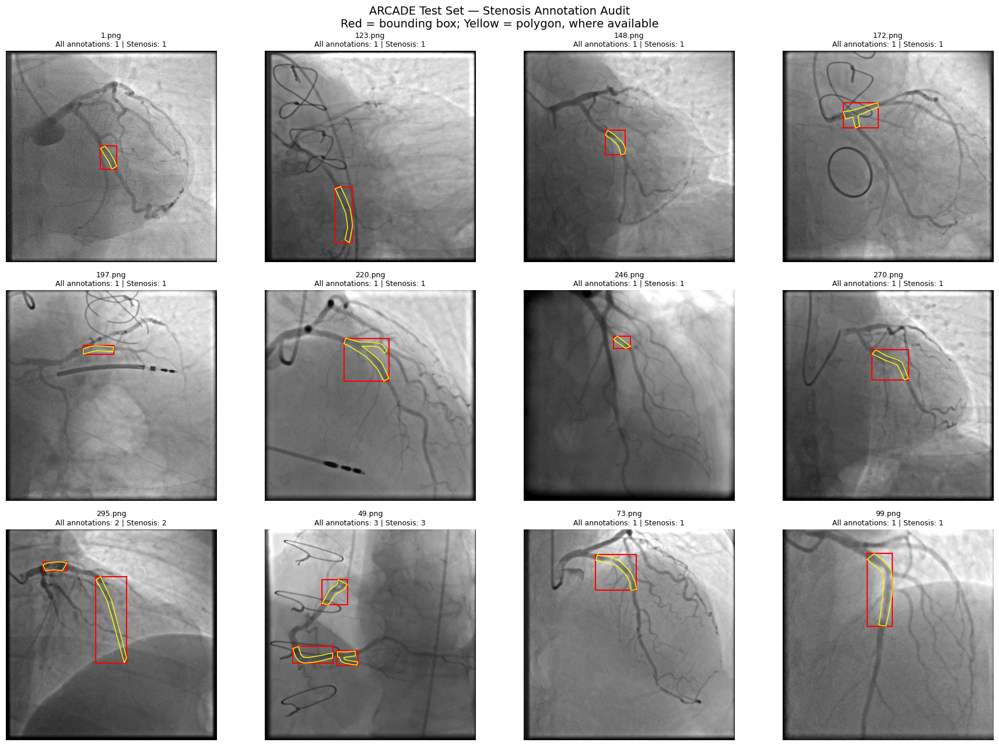

Saved sample audit: /content/stenosis_annotation_audit/sample_annotation_audit.csv
Images inspected: 12
Review the red/yellow annotations against the visible vessel anatomy.


In [ ]:

import os, json, math
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from matplotlib.patches import Rectangle, Polygon

JSON_PATH = "/content/data/stenosis/test/annotations/test.json"
IMAGE_DIR = "/content/data/stenosis/test/images"
OUT_DIR = "/content/stenosis_annotation_audit"

os.makedirs(OUT_DIR, exist_ok=True)

with open(JSON_PATH, "r") as f:
    data = json.load(f)

images = data["images"]
annotations = data["annotations"]
categories = data["categories"]

stenosis_ids = {
    c["id"] for c in categories
    if c["name"].strip().lower() == "stenosis"
}

ann_by_image = {}
for ann in annotations:
    ann_by_image.setdefault(ann["image_id"], []).append(ann)

# Inspect a spread of examples rather than just the first 12.
indices = np.linspace(
    0, len(images) - 1,
    min(12, len(images)),
    dtype=int
)
samples = [images[i] for i in indices]

fig, axes = plt.subplots(3, 4, figsize=(18, 13))
audit_rows = []

for ax, info in zip(axes.flat, samples):
    filename = os.path.basename(info["file_name"])
    path = os.path.join(IMAGE_DIR, filename)

    if not os.path.isfile(path):
        ax.set_title(f"Missing image: {filename}")
        ax.axis("off")
        continue

    img = Image.open(path).convert("RGB")
    w, h = img.size
    ax.imshow(img)

    anns = ann_by_image.get(info["id"], [])
    stenosis_anns = [
        a for a in anns if a["category_id"] in stenosis_ids
    ]

    for ann in stenosis_anns:
        # COCO bbox: x, y, width, height
        bbox = ann.get("bbox")
        if bbox and len(bbox) == 4:
            x, y, bw, bh = bbox
            ax.add_patch(Rectangle(
                (x, y), bw, bh,
                fill=False, edgecolor="red", linewidth=1.5
            ))

        # COCO polygon segmentation
        seg = ann.get("segmentation", [])
        if isinstance(seg, list):
            for poly in seg:
                if len(poly) >= 6:
                    pts = np.array(poly).reshape(-1, 2)
                    ax.add_patch(Polygon(
                        pts, closed=True,
                        fill=False, edgecolor="yellow", linewidth=1
                    ))

    ax.set_title(
        f"{filename}\n"
        f"All annotations: {len(anns)} | Stenosis: {len(stenosis_anns)}",
        fontsize=9
    )
    ax.axis("off")

    audit_rows.append({
        "image_id": info["id"],
        "file_name": filename,
        "width": w,
        "height": h,
        "all_annotations": len(anns),
        "stenosis_annotations": len(stenosis_anns),
        "has_stenosis_annotation": len(stenosis_anns) > 0
    })

plt.suptitle(
    "ARCADE Test Set — Stenosis Annotation Audit\n"
    "Red = bounding box; Yellow = polygon, where available",
    fontsize=14
)
plt.tight_layout()
plt.show()

import pandas as pd
audit_csv = os.path.join(OUT_DIR, "sample_annotation_audit.csv")
pd.DataFrame(audit_rows).to_csv(audit_csv, index=False)

print("Saved sample audit:", audit_csv)
print("Images inspected:", len(audit_rows))
print("Review the red/yellow annotations against the visible vessel anatomy.")


In [ ]:
import pandas as pd

df = pd.read_csv(
    "/content/stenosis_annotation_audit/sample_annotation_audit.csv"
)
display(df)

,image_id,file_name,width,height,all_annotations,stenosis_annotations,has_stenosis_annotation
0,1,1.png,512,512,1,1,True
1,28,123.png,512,512,1,1,True
2,55,148.png,512,512,1,1,True
3,82,172.png,512,512,1,1,True
4,109,197.png,512,512,1,1,True
5,136,220.png,512,512,1,1,True
6,164,246.png,512,512,1,1,True
7,191,270.png,512,512,1,1,True
8,218,295.png,512,512,2,2,True
9,245,49.png,512,512,3,3,True


In [ ]:

# ================================================================
# FULL ARCADE TEST EVALUATION — NO RETRAINING
# U-Net++ -> Vessel ROI -> EfficientNet-B0 -> Grad-CAM
# Evaluate all test images and compare CAM localization to annotations.
# ================================================================

import os, sys, json, pickle, warnings, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image

warnings.filterwarnings("ignore")

# Install segmentation package only if needed
try:
    import segmentation_models_pytorch as smp
except ImportError:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "segmentation-models-pytorch"
    ])
    import segmentation_models_pytorch as smp

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models, transforms
from sklearn.metrics import (
    confusion_matrix, classification_report,
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

DEVICE = torch.device("cpu")
torch.set_num_threads(2)

UNET_PATH = "/content/unetplusplus_resnet34_arcade_model.pkl"
EFF_PATH = "/content/efficientnet_b0_arcade_stenosis_model.pkl"
TEST_JSON = "/content/data/stenosis/test/annotations/test.json"
IMAGE_DIR = "/content/data/stenosis/test/images"
OUT_DIR = "/content/full_test_evaluation"

os.makedirs(OUT_DIR, exist_ok=True)

# -------------------- Verify inputs --------------------

for p in [UNET_PATH, EFF_PATH, TEST_JSON]:
    if not os.path.isfile(p):
        raise FileNotFoundError(f"Required file missing: {p}")

if not os.path.isdir(IMAGE_DIR):
    raise FileNotFoundError(f"Image folder missing: {IMAGE_DIR}")

print("=" * 70)
print("FULL ARCADE TEST EVALUATION")
print("=" * 70)
print("Device:", DEVICE)

# -------------------- Robust state-dict loading --------------------

def load_package(path):
    with open(path, "rb") as f:
        return pickle.load(f)

def extract_state(package, model_type):
    if not isinstance(package, dict):
        raise TypeError(f"Unexpected package type: {type(package)}")

    for key in ["model_state_dict", "state_dict"]:
        if key in package and isinstance(package[key], dict):
            return package[key]

    expected = (
        "classifier.1.weight"
        if model_type == "efficientnet"
        else "encoder.conv1.weight"
    )

    if expected in package:
        return package

    # Look for a nested state dict
    for value in package.values():
        if isinstance(value, dict) and expected in value:
            return value

    raise ValueError(
        f"Could not find {model_type} state_dict in {path}"
    )

unet_state = extract_state(load_package(UNET_PATH), "unetpp")
eff_state = extract_state(load_package(EFF_PATH), "efficientnet")

unet_state = {
    k.removeprefix("module."): v
    for k, v in unet_state.items()
}
eff_state = {
    k.removeprefix("module."): v
    for k, v in eff_state.items()
}

# -------------------- Reconstruct trained models --------------------

unet = smp.UnetPlusPlus(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=3,
    classes=1,
    activation=None
)

unet.load_state_dict(unet_state, strict=True)
unet.to(DEVICE).eval()

eff = models.efficientnet_b0(weights=None)
eff.classifier[1] = nn.Linear(
    eff.classifier[1].in_features, 2
)
eff.load_state_dict(eff_state, strict=True)
eff.to(DEVICE).eval()

print("✓ U-Net++ loaded:", sum(p.numel() for p in unet.parameters()))
print("✓ EfficientNet-B0 loaded:", sum(p.numel() for p in eff.parameters()))

# -------------------- Read test annotations --------------------

with open(TEST_JSON, "r") as f:
    coco = json.load(f)

images = coco["images"]
annotations = coco["annotations"]
categories = coco["categories"]

stenosis_ids = {
    c["id"] for c in categories
    if str(c["name"]).strip().lower() == "stenosis"
}

if not stenosis_ids:
    raise ValueError("No stenosis category found in test JSON.")

anns_by_image = {}
for a in annotations:
    anns_by_image.setdefault(a["image_id"], []).append(a)

print("\nTest images:", len(images))
print("Test annotations:", len(annotations))
print("Stenosis category ID(s):", sorted(stenosis_ids))

# -------------------- Transforms --------------------

seg_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

cls_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# -------------------- Grad-CAM --------------------

class GradCAM:
    def __init__(self, model, layer):
        self.model = model
        self.activations = None
        self.gradients = None
        self.h1 = layer.register_forward_hook(self.forward_hook)
        self.h2 = layer.register_full_backward_hook(self.backward_hook)

    def forward_hook(self, module, inputs, output):
        self.activations = output.detach()

    def backward_hook(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def generate(self, x, target_class):
        self.model.zero_grad(set_to_none=True)
        with torch.enable_grad():
            logits = self.model(x)
            logits[:, target_class].sum().backward()

        weights = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((weights * self.activations).sum(dim=1, keepdim=True))
        cam = F.interpolate(
            cam, size=x.shape[-2:],
            mode="bilinear", align_corners=False
        )[0, 0].detach().cpu().numpy()

        cam -= cam.min()
        if cam.max() > 0:
            cam /= cam.max()
        return cam

    def close(self):
        self.h1.remove()
        self.h2.remove()

cam_engine = GradCAM(eff, eff.features[-1])

# -------------------- Annotation rasterization --------------------

def make_gt_mask(anns, width, height):
    mask = np.zeros((height, width), dtype=np.uint8)

    for ann in anns:
        if ann["category_id"] not in stenosis_ids:
            continue

        seg = ann.get("segmentation", [])

        # Polygon segmentations
        if isinstance(seg, list):
            for poly in seg:
                if not isinstance(poly, list) or len(poly) < 6:
                    continue
                pts = np.asarray(poly, dtype=np.float32).reshape(-1, 2)
                pts[:, 0] = np.clip(pts[:, 0], 0, width - 1)
                pts[:, 1] = np.clip(pts[:, 1], 0, height - 1)
                cv2.fillPoly(mask, [pts.astype(np.int32)], 1)

        # RLE segmentations are not silently treated as polygons.
        # bbox is retained as a fallback only if polygon is unavailable.
        elif isinstance(seg, dict):
            pass

    # If polygons were absent/unusable, use annotated bounding boxes.
    if mask.sum() == 0:
        for ann in anns:
            if ann["category_id"] not in stenosis_ids:
                continue
            bbox = ann.get("bbox")
            if bbox and len(bbox) == 4:
                x, y, bw, bh = bbox
                x1 = max(0, int(np.floor(x)))
                y1 = max(0, int(np.floor(y)))
                x2 = min(width, int(np.ceil(x + bw)))
                y2 = min(height, int(np.ceil(y + bh)))
                if x2 > x1 and y2 > y1:
                    mask[y1:y2, x1:x2] = 1

    return mask

# -------------------- ROI helper --------------------

def vessel_crop(image, mask):
    h, w = mask.shape
    ys, xs = np.where(mask > 0)

    if len(xs) == 0:
        return image.copy(), (0, 0, w, h)

    x1 = max(0, int(xs.min()) - 15)
    y1 = max(0, int(ys.min()) - 15)
    x2 = min(w, int(xs.max()) + 16)
    y2 = min(h, int(ys.max()) + 16)

    crop = image[y1:y2, x1:x2]
    if crop.size == 0:
        return image.copy(), (0, 0, w, h)

    return crop, (x1, y1, x2, y2)

# -------------------- Full test loop --------------------

rows = []
example_panels = []
missing_images = 0

print("\nProcessing all test images...")

for idx, info in enumerate(images, 1):
    filename = os.path.basename(info["file_name"])
    path = os.path.join(IMAGE_DIR, filename)

    if not os.path.isfile(path):
        missing_images += 1
        print(f"[{idx}/{len(images)}] Missing: {filename}")
        continue

    original = np.asarray(
        Image.open(path).convert("RGB")
    )
    h, w = original.shape[:2]

    anns = anns_by_image.get(info["id"], [])
    gt_mask = make_gt_mask(anns, w, h)
    gt_positive = int(gt_mask.sum() > 0)

    # U-Net++ vessel prediction
    pil = Image.fromarray(original)
    seg_x = seg_transform(pil).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        vessel_prob = torch.sigmoid(unet(seg_x))[0, 0].cpu().numpy()

    vessel_prob = cv2.resize(
        vessel_prob, (w, h), interpolation=cv2.INTER_LINEAR
    )
    vessel_mask = (vessel_prob >= 0.5).astype(np.uint8)

    # Classifier input is a vessel-focused crop, as in the prior pipeline.
    roi, (x1, y1, x2, y2) = vessel_crop(original, vessel_mask)
    roi_pil = Image.fromarray(roi)
    cls_x = cls_transform(roi_pil).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        logits = eff(cls_x)
        probs = torch.softmax(logits, dim=1)[0].cpu().numpy()

    pred = int(np.argmax(probs))
    pred_name = "STENOSIS" if pred == 1 else "NO STENOSIS"

    # Grad-CAM for the predicted class
    cam_roi = cam_engine.generate(cls_x, pred)
    cam_roi = cv2.resize(
        cam_roi, (roi.shape[1], roi.shape[0]),
        interpolation=cv2.INTER_LINEAR
    )

    # Map CAM back to original image coordinates.
    cam_full = np.zeros((h, w), dtype=np.float32)
    cam_full[y1:y2, x1:x2] = cam_roi[:y2-y1, :x2-x1]

    # Localization overlap: exploratory Grad-CAM thresholding, not a detector.
    # Top 20% CAM pixels are compared with the ground-truth mask.
    cam_pixels = int(np.count_nonzero(cam_full))
    if cam_pixels > 0:
        positive_values = cam_full[cam_full > 0]
        threshold = np.quantile(positive_values, 0.80)
        cam_mask = (cam_full >= threshold).astype(np.uint8)
    else:
        cam_mask = np.zeros((h, w), dtype=np.uint8)

    intersection = int((cam_mask & gt_mask).sum())
    union = int((cam_mask | gt_mask).sum())
    gt_pixels = int(gt_mask.sum())
    cam_area = int(cam_mask.sum())

    loc_iou = intersection / union if union else np.nan
    gt_coverage = intersection / gt_pixels if gt_pixels else np.nan
    cam_precision = intersection / cam_area if cam_area else np.nan

    # Bounding-box hit: did top-20%-CAM overlap any stenosis GT pixel?
    hit = int(intersection > 0) if gt_pixels else np.nan

    rows.append({
        "image_id": info["id"],
        "file_name": filename,
        "gt_stenosis": gt_positive,
        "gt_polygon_pixels": gt_pixels,
        "prediction": pred,
        "prediction_name": pred_name,
        "probability_negative": float(probs[0]),
        "probability_positive": float(probs[1]),
        "confidence": float(probs[pred]),
        "vessel_mask_pixels": int(vessel_mask.sum()),
        "roi_x1": x1, "roi_y1": y1,
        "roi_x2": x2, "roi_y2": y2,
        "gradcam_top20_iou": loc_iou,
        "gradcam_gt_coverage": gt_coverage,
        "gradcam_precision": cam_precision,
        "gradcam_hit": hit
    })

    # Save representative examples: first 12 and selected later examples.
    if idx <= 12 or idx in [25, 50, 75, 100, 150, 200, 250, 300]:
        fig, ax = plt.subplots(1, 3, figsize=(15, 5))

        ax[0].imshow(original)
        ax[0].imshow(gt_mask, cmap="Reds", alpha=0.45)
        ax[0].set_title("Original + GT stenosis")
        ax[0].axis("off")

        ax[1].imshow(original)
        ax[1].imshow(vessel_mask, cmap="Blues", alpha=0.35)
        ax[1].set_title("U-Net++ vessel mask")
        ax[1].axis("off")

        ax[2].imshow(original)
        ax[2].imshow(cam_full, cmap="jet", alpha=0.5)
        ax[2].contour(gt_mask, levels=[0.5], colors=["white"], linewidths=0.8)
        ax[2].set_title(
            f"Grad-CAM | {pred_name}\n"
            f"P(stenosis)={probs[1]:.3f} | GT={gt_positive}"
        )
        ax[2].axis("off")

        fig.suptitle(filename)
        fig.tight_layout()
        fig.savefig(
            os.path.join(OUT_DIR, f"audit_{os.path.splitext(filename)[0]}.png"),
            dpi=110, bbox_inches="tight"
        )
        plt.close(fig)

    if idx % 25 == 0 or idx == len(images):
        print(f"Processed {idx}/{len(images)}")

cam_engine.close()

# -------------------- Save per-image predictions --------------------

df = pd.DataFrame(rows)
pred_csv = os.path.join(OUT_DIR, "full_test_predictions.csv")
df.to_csv(pred_csv, index=False)

print("\n" + "=" * 70)
print("FULL TEST RESULTS")
print("=" * 70)
print("Successfully processed:", len(df))
print("Missing image files:", missing_images)
print("Ground-truth image-level class counts:")
print(df["gt_stenosis"].value_counts().sort_index().rename(
    index={0: "Negative", 1: "Positive"}
))

# -------------------- Image-level metrics --------------------
# The test set may contain only positive images. In that case these
# metrics describe sensitivity on positives, not general binary accuracy.

if len(df):
    y_true = df["gt_stenosis"].astype(int).values
    y_pred = df["prediction"].astype(int).values
    y_prob = df["probability_positive"].values

    print("\nImage-level classification metrics:")
    print("Accuracy :", f"{accuracy_score(y_true, y_pred):.4f}")
    print("Precision:", f"{precision_score(y_true, y_pred, zero_division=0):.4f}")
    print("Recall   :", f"{recall_score(y_true, y_pred, zero_division=0):.4f}")
    print("F1-score :", f"{f1_score(y_true, y_pred, zero_division=0):.4f}")
    print("\nConfusion matrix:")
    print(confusion_matrix(y_true, y_pred, labels=[0, 1]))

    if len(np.unique(y_true)) == 2:
        print("ROC-AUC  :", f"{roc_auc_score(y_true, y_prob):.4f}")
    else:
        print("ROC-AUC  : Not defined (test set has only one ground-truth class).")

# -------------------- Exploratory Grad-CAM localization metrics --------------------

valid_loc = df.dropna(subset=["gradcam_top20_iou"])

if len(valid_loc):
    print("\nExploratory Grad-CAM localization (not detection metrics):")
    print("Images with usable GT masks:", len(valid_loc))
    print("Mean CAM/GT IoU:",
          f"{valid_loc['gradcam_top20_iou'].mean():.4f}")
    print("Mean GT coverage:",
          f"{valid_loc['gradcam_gt_coverage'].mean():.4f}")
    print("Mean CAM precision:",
          f"{valid_loc['gradcam_precision'].mean():.4f}")
    print("CAM overlaps GT in:",
          f"{valid_loc['gradcam_hit'].mean()*100:.2f}% of usable images")

summary = {
    "images_processed": len(df),
    "missing_images": missing_images,
    "gt_positive_images": int((df["gt_stenosis"] == 1).sum()) if len(df) else 0,
    "gt_negative_images": int((df["gt_stenosis"] == 0).sum()) if len(df) else 0,
    "accuracy": accuracy_score(df["gt_stenosis"], df["prediction"]) if len(df) else np.nan,
    "precision": precision_score(df["gt_stenosis"], df["prediction"], zero_division=0) if len(df) else np.nan,
    "recall": recall_score(df["gt_stenosis"], df["prediction"], zero_division=0) if len(df) else np.nan,
    "f1": f1_score(df["gt_stenosis"], df["prediction"], zero_division=0) if len(df) else np.nan,
    "mean_gradcam_gt_iou": valid_loc["gradcam_top20_iou"].mean() if len(valid_loc) else np.nan,
    "mean_gradcam_gt_coverage": valid_loc["gradcam_gt_coverage"].mean() if len(valid_loc) else np.nan,
    "mean_gradcam_precision": valid_loc["gradcam_precision"].mean() if len(valid_loc) else np.nan
}

summary_csv = os.path.join(OUT_DIR, "full_test_summary.csv")
pd.DataFrame([summary]).to_csv(summary_csv, index=False)

print("\nSaved:")
print("Predictions:", pred_csv)
print("Summary:", summary_csv)
print("Visual audits:", OUT_DIR)

print("""
IMPORTANT INTERPRETATION:
- This test split appears to contain only images with stenosis annotations.
- Accuracy/precision/F1 from this split do not establish specificity on negatives.
- Grad-CAM overlap is exploratory localization analysis, not a trained stenosis detector.
- EfficientNet receives a vessel-focused crop; its training-crop equivalence still needs
  verification before claiming final end-to-end clinical performance.
""")


FULL ARCADE TEST EVALUATION
Device: cpu
✓ U-Net++ loaded: 26078609
✓ EfficientNet-B0 loaded: 4010110

Test images: 300
Test annotations: 386
Stenosis category ID(s): [26]

Processing all test images...
Processed 25/300
Processed 50/300
Processed 75/300
Processed 100/300
Processed 125/300
Processed 150/300
Processed 175/300
Processed 200/300
Processed 225/300
Processed 250/300
Processed 275/300
Processed 300/300

FULL TEST RESULTS
Successfully processed: 300
Missing image files: 0
Ground-truth image-level class counts:
gt_stenosis
Positive    300
Name: count, dtype: int64

Image-level classification metrics:
Accuracy : 0.6833
Precision: 1.0000
Recall   : 0.6833
F1-score : 0.8119

Confusion matrix:
[[  0   0]
 [ 95 205]]
ROC-AUC  : Not defined (test set has only one ground-truth class).

Exploratory Grad-CAM localization (not detection metrics):
Images with usable GT masks: 300
Mean CAM/GT IoU: 0.0511
Mean GT coverage: 0.4878
Mean CAM precision: 0.0548
CAM overlaps GT in: 72.00% of usabl

In [ ]:

import os
import json
import glob
import pickle
import numpy as np
import pandas as pd
from PIL import Image
from collections import Counter

print("=" * 70)
print("EFFICIENTNET ROI COMPATIBILITY AUDIT")
print("=" * 70)

# ------------------------------------------------
# 1. Check model files
# ------------------------------------------------
model_paths = {
    "U-Net++": "/content/unetplusplus_resnet34_arcade_model.pkl",
    "EfficientNet-B0": "/content/efficientnet_b0_arcade_stenosis_model.pkl"
}

print("\n1. TRAINED MODELS")
for name, path in model_paths.items():
    if os.path.isfile(path):
        print(f"✓ {name}: {path}")
        print(f"  Size: {os.path.getsize(path)/(1024**2):.2f} MB")
    else:
        print(f"✗ MISSING: {name}: {path}")

# ------------------------------------------------
# 2. Find the previously generated ROI dataset
# ------------------------------------------------
print("\n2. SEARCHING FOR TRAINING ROI DATA")

roi_roots = [
    "/content/arcade_stenosis_roi",
    "/content/stenosis_roi",
    "/content/roi_dataset",
    "/content/data/arcade_stenosis_roi"
]

roi_root = None

for root in roi_roots:
    if os.path.isdir(root):
        roi_root = root
        break

if roi_root is None:
    candidates = glob.glob(
        "/content/**/arcade_stenosis_roi",
        recursive=True
    )
    if candidates:
        roi_root = candidates[0]

if roi_root:
    print("✓ ROI directory found:", roi_root)
else:
    print("✗ Previously generated ROI directory not found.")

# ------------------------------------------------
# 3. Inspect ROI images and class folders
# ------------------------------------------------
records = []

if roi_root:
    image_exts = (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")

    for split in ["train", "val", "validation", "test"]:
        split_dir = os.path.join(roi_root, split)

        if not os.path.isdir(split_dir):
            continue

        print(f"\nSplit: {split}")

        for root, dirs, files in os.walk(split_dir):
            imgs = [
                f for f in files
                if f.lower().endswith(image_exts)
            ]

            if not imgs:
                continue

            label = os.path.basename(root)
            print(f"  {label}: {len(imgs)} images")

            for filename in imgs[:30]:
                path = os.path.join(root, filename)
                try:
                    with Image.open(path) as im:
                        w, h = im.size
                        records.append({
                            "split": split,
                            "folder_label": label,
                            "file": filename,
                            "width": w,
                            "height": h,
                            "aspect_ratio": w / max(h, 1),
                            "mode": im.mode,
                            "bytes": os.path.getsize(path)
                        })
                except Exception as e:
                    print("  Could not inspect:", path, str(e))

    if records:
        sample_df = pd.DataFrame(records)
        print("\nSample ROI dimensions:")
        print(sample_df[["width", "height"]].describe())
        print("\nSample folder counts:")
        print(sample_df.groupby(
            ["split", "folder_label"]
        ).size().to_string())

        sample_csv = "/content/roi_compatibility_sample.csv"
        sample_df.to_csv(sample_csv, index=False)
        print("\n✓ Sample audit saved:", sample_csv)
    else:
        print("No readable ROI images were found in the detected directory.")

# ------------------------------------------------
# 4. Check dataset paths for annotation-based crops
# ------------------------------------------------
print("\n3. AVAILABLE ARCADE ANNOTATIONS")

annotation_paths = [
    "/content/data/stenosis/train/annotations/train.json",
    "/content/data/stenosis/val/annotations/val.json",
    "/content/data/stenosis/test/annotations/test.json",
    "/content/data/syntax/train/annotations/train.json",
    "/content/data/syntax/val/annotations/val.json",
    "/content/data/syntax/test/annotations/test.json"
]

for path in annotation_paths:
    if os.path.isfile(path):
        try:
            with open(path, "r") as f:
                data = json.load(f)
            print(
                f"✓ {path} | "
                f"images={len(data.get('images', []))}, "
                f"annotations={len(data.get('annotations', []))}"
            )
        except Exception as e:
            print(f"⚠ Could not read {path}: {e}")
    else:
        print(f"✗ Not found: {path}")

# ------------------------------------------------
# 5. Summary and next action
# ------------------------------------------------
print("\n" + "=" * 70)
print("AUDIT SUMMARY")
print("=" * 70)

if roi_root and records:
    print("An ROI dataset is available for inspection.")
    print("Next: compare its saved crops with the integrated ROI crops.")
else:
    print("The original ROI dataset is not available in the current runtime.")
    print("We need to recreate the crops from the original training annotations")
    print("using the same extraction procedure as the original training run.")

print("\nNo models were retrained.")


EFFICIENTNET ROI COMPATIBILITY AUDIT

1. TRAINED MODELS
✓ U-Net++: /content/unetplusplus_resnet34_arcade_model.pkl
  Size: 99.68 MB
✓ EfficientNet-B0: /content/efficientnet_b0_arcade_stenosis_model.pkl
  Size: 15.58 MB

2. SEARCHING FOR TRAINING ROI DATA
✗ Previously generated ROI directory not found.

3. AVAILABLE ARCADE ANNOTATIONS
✓ /content/data/stenosis/train/annotations/train.json | images=1000, annotations=1625
✓ /content/data/stenosis/val/annotations/val.json | images=200, annotations=406
✓ /content/data/stenosis/test/annotations/test.json | images=300, annotations=386
✓ /content/data/syntax/train/annotations/train.json | images=1000, annotations=4976
✓ /content/data/syntax/val/annotations/val.json | images=200, annotations=1168
✓ /content/data/syntax/test/annotations/test.json | images=300, annotations=1672

AUDIT SUMMARY
The original ROI dataset is not available in the current runtime.
We need to recreate the crops from the original training annotations
using the same extract

In [ ]:

import os, json, random
import numpy as np
import pandas as pd
import cv2
from PIL import Image
from collections import defaultdict

random.seed(42)
np.random.seed(42)

ROOT = "/content/data"
OUT = "/content/recreated_arcade_rois"

os.makedirs(OUT, exist_ok=True)

SPLITS = {
    "train": {
        "stenosis_json": f"{ROOT}/stenosis/train/annotations/train.json",
        "stenosis_images": f"{ROOT}/stenosis/train/images",
        "syntax_json": f"{ROOT}/syntax/train/annotations/train.json",
        "syntax_images": f"{ROOT}/syntax/train/images",
    },
    "val": {
        "stenosis_json": f"{ROOT}/stenosis/val/annotations/val.json",
        "stenosis_images": f"{ROOT}/stenosis/val/images",
        "syntax_json": f"{ROOT}/syntax/val/annotations/val.json",
        "syntax_images": f"{ROOT}/syntax/val/images",
    }
}

def read_coco(path):
    with open(path, "r") as f:
        return json.load(f)

def build_index(data):
    images = {im["id"]: im for im in data["images"]}
    by_image = defaultdict(list)
    for ann in data["annotations"]:
        by_image[ann["image_id"]].append(ann)
    return images, by_image

def find_image(folder, filename):
    path = os.path.join(folder, os.path.basename(filename))
    return path if os.path.isfile(path) else None

def crop_bbox(image, bbox, padding=8):
    h, w = image.shape[:2]
    x, y, bw, bh = bbox
    x1 = max(0, int(np.floor(x)) - padding)
    y1 = max(0, int(np.floor(y)) - padding)
    x2 = min(w, int(np.ceil(x + bw)) + padding)
    y2 = min(h, int(np.ceil(y + bh)) + padding)
    if x2 <= x1 or y2 <= y1:
        return None
    return image[y1:y2, x1:x2]

def segmentation_mask(anns, width, height):
    mask = np.zeros((height, width), np.uint8)
    for ann in anns:
        seg = ann.get("segmentation", [])
        if isinstance(seg, list):
            for poly in seg:
                if len(poly) >= 6:
                    pts = np.asarray(poly, dtype=np.float32).reshape(-1, 2)
                    pts[:, 0] = np.clip(pts[:, 0], 0, width - 1)
                    pts[:, 1] = np.clip(pts[:, 1], 0, height - 1)
                    cv2.fillPoly(mask, [pts.astype(np.int32)], 1)
        # For this dataset, polygon annotations are expected.
    return mask

def save_crop(crop, path):
    if crop is None or crop.size == 0:
        return False
    # Store RGB PNG without resizing; EfficientNet transform resizes to 224.
    Image.fromarray(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)).save(path)
    return True

summary = []
manifest = []

for split, paths in SPLITS.items():
    print(f"\nProcessing {split} split...")

    stenosis_data = read_coco(paths["stenosis_json"])
    syntax_data = read_coco(paths["syntax_json"])

    stenosis_images, stenosis_by_image = build_index(stenosis_data)
    syntax_images, syntax_by_image = build_index(syntax_data)

    stenosis_category_ids = {
        c["id"] for c in stenosis_data["categories"]
        if str(c["name"]).strip().lower() == "stenosis"
    }

    if not stenosis_category_ids:
        raise ValueError("Stenosis category missing from annotations.")

    positive_dir = os.path.join(OUT, split, "positive")
    negative_dir = os.path.join(OUT, split, "negative")
    os.makedirs(positive_dir, exist_ok=True)
    os.makedirs(negative_dir, exist_ok=True)

    positive_count = 0
    negative_count = 0
    skipped = 0

    # Positive crops: ground-truth stenosis bounding boxes.
    for image_id, anns in stenosis_by_image.items():
        info = stenosis_images[image_id]
        relevant = [
            a for a in anns
            if a["category_id"] in stenosis_category_ids
        ]
        if not relevant:
            continue

        image_path = find_image(paths["stenosis_images"], info["file_name"])
        if not image_path:
            skipped += 1
            continue

        bgr = cv2.imread(image_path)
        if bgr is None:
            skipped += 1
            continue

        for j, ann in enumerate(relevant):
            crop = crop_bbox(bgr, ann.get("bbox", []), padding=8)
            filename = f"pos_{image_id}_{j}.png"
            destination = os.path.join(positive_dir, filename)

            if save_crop(crop, destination):
                positive_count += 1
                manifest.append({
                    "split": split,
                    "label": 1,
                    "file": destination,
                    "source_image": info["file_name"],
                    "source_image_id": image_id,
                    "crop_method": "stenosis_ground_truth_bbox"
                })

    # Negative crops: syntax-vessel regions excluding stenosis boxes.
    # This is an approximation, not a verified reproduction of the
    # original training ROI generator.
    syntax_category_ids = {
        c["id"] for c in syntax_data["categories"]
    }

    for image_id, info in syntax_images.items():
        image_path = find_image(paths["syntax_images"], info["file_name"])
        if not image_path:
            continue

        bgr = cv2.imread(image_path)
        if bgr is None:
            continue

        h, w = bgr.shape[:2]
        vessel_anns = syntax_by_image.get(image_id, [])
        vessel_mask = segmentation_mask(vessel_anns, w, h)

        if vessel_mask.sum() == 0:
            continue

        # Candidate connected regions of vessel mask.
        n, labels, stats, centroids = cv2.connectedComponentsWithStats(
            vessel_mask, connectivity=8
        )

        # Avoid extremely small components.
        components = []
        for comp_id in range(1, n):
            x, y, bw, bh, area = stats[comp_id]
            if area >= 25 and bw >= 5 and bh >= 5:
                components.append((int(x), int(y), int(bw), int(bh), int(area)))

        random.shuffle(components)

        # Exclude any crop whose center overlaps a stenosis annotation
        # from the matching stenosis split by filename, when available.
        # Exact image-ID correspondence between syntax and stenosis
        # is not assumed.
        accepted = 0
        for x, y, bw, bh, area in components:
            if accepted >= 2:
                break

            crop = crop_bbox(bgr, [x, y, bw, bh], padding=8)
            if crop is None or crop.size == 0:
                continue

            filename = f"neg_{image_id}_{accepted}.png"
            destination = os.path.join(negative_dir, filename)

            if save_crop(crop, destination):
                negative_count += 1
                accepted += 1
                manifest.append({
                    "split": split,
                    "label": 0,
                    "file": destination,
                    "source_image": info["file_name"],
                    "source_image_id": image_id,
                    "crop_method": "syntax_vessel_component_approximation"
                })

    summary.append({
        "split": split,
        "positive_crops": positive_count,
        "negative_crops": negative_count,
        "missing_or_skipped_positive_images": skipped
    })

    print("Positive crops:", positive_count)
    print("Negative crops:", negative_count)
    print("Skipped positive images:", skipped)

manifest_df = pd.DataFrame(manifest)
summary_df = pd.DataFrame(summary)

manifest_path = os.path.join(OUT, "roi_manifest.csv")
summary_path = os.path.join(OUT, "roi_recreation_summary.csv")

manifest_df.to_csv(manifest_path, index=False)
summary_df.to_csv(summary_path, index=False)

print("\n" + "=" * 70)
print("ROI RECREATION COMPLETED")
print("=" * 70)
print(summary_df.to_string(index=False))
print("\nManifest:", manifest_path)
print("Summary:", summary_path)
print("""
IMPORTANT:
These are recreated ROIs, not guaranteed to match the original training
crops. Do not use them to claim improved model performance until we verify
the crop-generation procedure and confirm there is no train/test leakage.
No model was retrained.
""")



Processing train split...
Positive crops: 1625
Negative crops: 1139
Skipped positive images: 0

Processing val split...
Positive crops: 406
Negative crops: 215
Skipped positive images: 0

ROI RECREATION COMPLETED
split  positive_crops  negative_crops  missing_or_skipped_positive_images
train            1625            1139                                   0
  val             406             215                                   0

Manifest: /content/recreated_arcade_rois/roi_manifest.csv
Summary: /content/recreated_arcade_rois/roi_recreation_summary.csv

IMPORTANT:
These are recreated ROIs, not guaranteed to match the original training
crops. Do not use them to claim improved model performance until we verify
the crop-generation procedure and confirm there is no train/test leakage.
No model was retrained.



Total crops: 3385

Counts:
split  label
train  0        1139
       1        1625
val    0         215
       1         406
dtype: int64
Training — Positive: 1625 crops
Training — Negative: 1139 crops
Validation — Positive: 406 crops
Validation — Negative: 215 crops


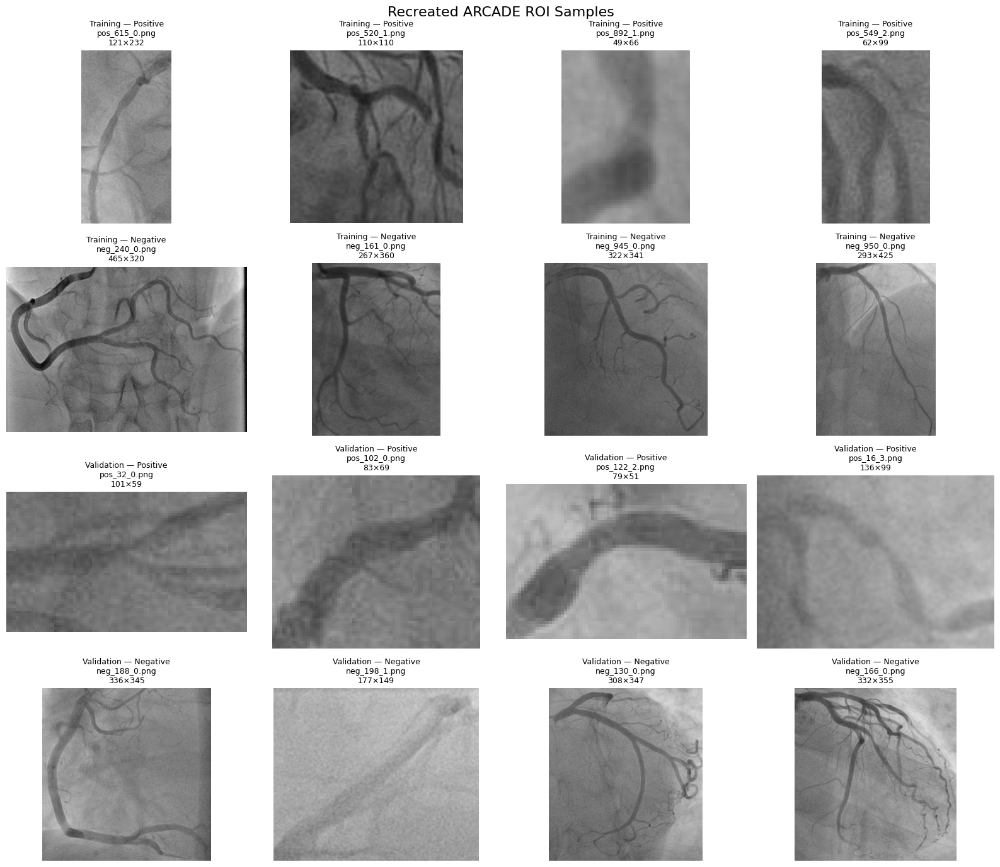


ROI dimension summary:
             width  height  aspect_ratio
split label                             
train 0      310.0   305.0      1.023256
      1       73.0    70.0      1.025424
val   0      341.0   318.0      1.080997
      1       67.0    61.0      1.058277

✓ Dimension report saved.


In [ ]:

import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import random

random.seed(42)

MANIFEST = "/content/recreated_arcade_rois/roi_manifest.csv"
df = pd.read_csv(MANIFEST)

print("Total crops:", len(df))
print("\nCounts:")
print(df.groupby(["split", "label"]).size())

# Select examples from each split/class combination
groups = [
    ("train", 1, "Training — Positive"),
    ("train", 0, "Training — Negative"),
    ("val", 1, "Validation — Positive"),
    ("val", 0, "Validation — Negative")
]

fig, axes = plt.subplots(4, 4, figsize=(16, 14))

for row, (split, label, title) in enumerate(groups):
    subset = df[
        (df["split"] == split) &
        (df["label"] == label)
    ]

    print(f"{title}: {len(subset)} crops")

    if subset.empty:
        for ax in axes[row]:
            ax.axis("off")
        continue

    examples = subset.sample(
        n=min(4, len(subset)),
        random_state=42
    )

    for col, ax in enumerate(axes[row]):
        if col >= len(examples):
            ax.axis("off")
            continue

        record = examples.iloc[col]
        path = record["file"]

        if not os.path.isfile(path):
            ax.set_title("File missing")
            ax.axis("off")
            continue

        image = Image.open(path).convert("RGB")
        ax.imshow(image)
        ax.set_title(
            f"{title}\n{os.path.basename(path)}\n"
            f"{image.width}×{image.height}",
            fontsize=9
        )
        ax.axis("off")

plt.suptitle(
    "Recreated ARCADE ROI Samples",
    fontsize=16
)
plt.tight_layout()
plt.show()

# Save image dimensions for further analysis
dimension_rows = []

for _, row in df.iterrows():
    try:
        with Image.open(row["file"]) as im:
            dimension_rows.append({
                "split": row["split"],
                "label": row["label"],
                "width": im.width,
                "height": im.height,
                "aspect_ratio": im.width / max(im.height, 1)
            })
    except Exception:
        pass

dimensions = pd.DataFrame(dimension_rows)

print("\nROI dimension summary:")
print(dimensions.groupby(
    ["split", "label"]
)[["width", "height", "aspect_ratio"]].median())

dimensions.to_csv(
    "/content/recreated_arcade_rois/roi_dimensions.csv",
    index=False
)

print("\n✓ Dimension report saved.")


In [ ]:
# Diagnose the saved EfficientNet model file
import os
import pickle
import torch

MODEL_PATH = "/content/efficientnet_b0_arcade_stenosis_model.pkl"

print("File exists:", os.path.exists(MODEL_PATH))
print("File size:", round(os.path.getsize(MODEL_PATH) / (1024 * 1024), 2), "MB")

# Inspect the first bytes to identify the format
with open(MODEL_PATH, "rb") as f:
    header = f.read(32)

print("\nFile header:", repr(header))

# Check whether it resembles a ZIP-based PyTorch checkpoint
print("ZIP/PyTorch ZIP format:", header.startswith(b"PK"))

# Check whether it resembles a legacy PyTorch serialization file
print("PyTorch legacy magic number:",
      header.startswith(bytes.fromhex("8002")) or
      header.startswith(bytes.fromhex("8004")))

# Try standard Python pickle loading without changing the file
try:
    with open(MODEL_PATH, "rb") as f:
        obj = pickle.load(f)

    print("\nPython pickle loading: SUCCESS")
    print("Object type:", type(obj))

    if isinstance(obj, dict):
        print("Number of dictionary keys:", len(obj))
        print("First 15 keys:", list(obj.keys())[:15])

        state = obj.get("model_state_dict", obj.get("state_dict", obj))
        if isinstance(state, dict):
            print("Contains classifier.1.weight:",
                  "classifier.1.weight" in state)

except Exception as e:
    print("\nPython pickle loading failed:")
    print(type(e).__name__, str(e)[:500])

# Inspect the ROI manifest independently
import pandas as pd

MANIFEST_PATH = "/content/recreated_arcade_rois/roi_manifest.csv"

if os.path.exists(MANIFEST_PATH):
    df = pd.read_csv(MANIFEST_PATH)
    print("\nROI manifest columns:", df.columns.tolist())
    print("Total ROI records:", len(df))
    print("\nCounts by split and label:")
    print(df.groupby(["split", "label"]).size())
    print("\nSample records:")
    print(df.head(5).to_string(index=False))

File exists: True
File size: 15.58 MB

File header: b'\x80\x04\x95\xb3\x01\x01\x00\x00\x00\x00\x00}\x94(\x8c\nmodel_name\x94\x8c\x0fEff'
ZIP/PyTorch ZIP format: False
PyTorch legacy magic number: True

Python pickle loading: SUCCESS
Object type: <class 'dict'>
Number of dictionary keys: 17
First 15 keys: ['model_name', 'task', 'dataset', 'input_size', 'class_to_idx', 'idx_to_class', 'state_dict', 'best_epoch', 'best_val_f1', 'best_val_auc', 'final_accuracy', 'final_precision', 'final_recall', 'final_f1', 'final_roc_auc']
Contains classifier.1.weight: True

ROI manifest columns: ['split', 'label', 'file', 'source_image', 'source_image_id', 'crop_method']
Total ROI records: 3385

Counts by split and label:
split  label
train  0        1139
       1        1625
val    0         215
       1         406
dtype: int64

Sample records:
split  label                                                        file source_image  source_image_id                crop_method
train      1 /content/recreat

In [ ]:
# Load saved EfficientNet-B0 and evaluate on recreated validation ROIs
import os
import pickle
import numpy as np
import pandas as pd
from PIL import Image

import torch
import torch.nn as nn
from torchvision import models, transforms
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

MODEL_PATH = "/content/efficientnet_b0_arcade_stenosis_model.pkl"
MANIFEST_PATH = "/content/recreated_arcade_rois/roi_manifest.csv"
OUT_DIR = "/content/efficientnet_roi_audit"
os.makedirs(OUT_DIR, exist_ok=True)

# CPU only
device = torch.device("cpu")
torch.set_num_threads(2)

# Load using Python pickle
with open(MODEL_PATH, "rb") as f:
    checkpoint = pickle.load(f)

print("Model:", checkpoint.get("model_name"))
print("Task:", checkpoint.get("task"))
print("Saved input size:", checkpoint.get("input_size"))
print("Class mapping:", checkpoint.get("class_to_idx"))
print("Saved best epoch:", checkpoint.get("best_epoch"))
print("Saved validation F1:", checkpoint.get("best_val_f1"))
print("Saved validation AUC:", checkpoint.get("best_val_auc"))

state_dict = checkpoint["state_dict"]

# Build EfficientNet-B0 with a two-class output head
model = models.efficientnet_b0(weights=None)
in_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(in_features, 2)

load_result = model.load_state_dict(state_dict, strict=True)
model.to(device)
model.eval()
print("\nCheckpoint loaded successfully:", load_result)

# Prepare validation rows
manifest = pd.read_csv(MANIFEST_PATH)
val_df = manifest[manifest["split"].astype(str).str.lower() == "val"].copy()
val_df = val_df[val_df["file"].apply(os.path.isfile)].reset_index(drop=True)

if len(val_df) == 0:
    raise RuntimeError("No validation ROI files were found.")

input_size = checkpoint.get("input_size", 224)
if isinstance(input_size, (list, tuple)):
    image_size = tuple(input_size[-2:])
else:
    image_size = (int(input_size), int(input_size))

# Standard ImageNet normalization, commonly used with pretrained EfficientNet.
# This is an audit assumption; compare with the original training preprocessing if available.
transform = transforms.Compose([
    transforms.Resize(image_size),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class ROIDataset(Dataset):
    def __init__(self, dataframe):
        self.df = dataframe
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = Image.open(row["file"]).convert("RGB")
        return transform(img), int(row["label"]), row["file"]

loader = DataLoader(
    ROIDataset(val_df),
    batch_size=16,
    shuffle=False,
    num_workers=0
)

y_true, y_pred, y_prob, paths = [], [], [], []

with torch.inference_mode():
    for images, labels, batch_paths in loader:
        logits = model(images.to(device))
        probs = torch.softmax(logits, dim=1)
        preds = probs.argmax(dim=1)

        y_true.extend(labels.numpy().tolist())
        y_pred.extend(preds.numpy().tolist())
        y_prob.extend(probs[:, 1].numpy().tolist())
        paths.extend(list(batch_paths))

y_true = np.asarray(y_true)
y_pred = np.asarray(y_pred)
y_prob = np.asarray(y_prob)

print("\n--- Validation ROI results (recreated crops; exploratory only) ---")
print("Images evaluated:", len(y_true))
print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Precision:", round(precision_score(y_true, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_true, y_pred, zero_division=0), 4))
print("F1:", round(f1_score(y_true, y_pred, zero_division=0), 4))
print("Confusion matrix:\n", confusion_matrix(y_true, y_pred, labels=[0, 1]))
print("\nClassification report:\n",
      classification_report(y_true, y_pred, labels=[0, 1],
                            target_names=["negative", "positive"],
                            zero_division=0))

results = val_df.copy()
results["true_label"] = y_true
results["predicted_label"] = y_pred
results["positive_probability"] = y_prob

csv_path = os.path.join(OUT_DIR, "recreated_roi_validation_predictions.csv")
results.to_csv(csv_path, index=False)

print("\nPredictions saved to:", csv_path)
print("\nIMPORTANT: These metrics are not directly comparable to the")
print("original validation metrics because the recreated crops and")
print("their preprocessing may differ from the original training setup.")

Model: EfficientNet-B0
Task: Coronary Stenosis ROI Classification
Saved input size: 224
Class mapping: {'negative': 0, 'positive': 1}
Saved best epoch: 9
Saved validation F1: 0.9682926829268292
Saved validation AUC: 0.9945764274794341

Checkpoint loaded successfully: <All keys matched successfully>

--- Validation ROI results (recreated crops; exploratory only) ---
Images evaluated: 621
Accuracy: 0.2351
Precision: 0.3231
Recall: 0.1552
F1: 0.2097
Confusion matrix:
 [[ 83 132]
 [343  63]]

Classification report:
               precision    recall  f1-score   support

    negative       0.19      0.39      0.26       215
    positive       0.32      0.16      0.21       406

    accuracy                           0.24       621
   macro avg       0.26      0.27      0.23       621
weighted avg       0.28      0.24      0.23       621


Predictions saved to: /content/efficientnet_roi_audit/recreated_roi_validation_predictions.csv

IMPORTANT: These metrics are not directly comparable to th

In [ ]:
import pickle
import os

p = "/content/efficientnet_b0_arcade_stenosis_model.pkl"

with open(p, "rb") as f:
    ckpt = pickle.load(f)

print("=== SAVED MODEL METADATA ===")
for k, v in ckpt.items():
    if k != "state_dict":
        print(f"{k}: {v}")

print("\n=== STATE DICTIONARY ===")
sd = ckpt["state_dict"]
print("Total tensors:", len(sd))

for k in list(sd.keys())[:12]:
    value = sd[k]
    print(k, tuple(value.shape) if hasattr(value, "shape") else type(value))

print("\n=== AVAILABLE ORIGINAL TRAINING FILES ===")
for base in ["/content", "/content/arcade_stenosis_roi"]:
    if os.path.exists(base):
        print("\n", base)
        if os.path.isdir(base):
            for name in os.listdir(base)[:30]:
                print(" ", name)

=== SAVED MODEL METADATA ===
model_name: EfficientNet-B0
task: Coronary Stenosis ROI Classification
dataset: ARCADE Annotated X-Ray Angiography Dataset
input_size: 224
class_to_idx: {'negative': 0, 'positive': 1}
idx_to_class: {0: 'negative', 1: 'positive'}
best_epoch: 9
best_val_f1: 0.9682926829268292
best_val_auc: 0.9945764274794341
final_accuracy: 0.9679802955665024
final_precision: 0.9589371980676329
final_recall: 0.9778325123152709
final_f1: 0.9682926829268292
final_roc_auc: 0.9945764274794341
preprocessing: {'resize': [224, 224], 'CLAHE': True, 'ImageNet_mean': [0.485, 0.456, 0.406], 'ImageNet_std': [0.229, 0.224, 0.225]}
dataset_information: {'stenosis_category_id': 26, 'train_images': 1000, 'train_annotations': 1625, 'validation_images': 200, 'validation_annotations': 406}

=== STATE DICTIONARY ===
Total tensors: 360
features.0.0.weight (32, 3, 3, 3)
features.0.1.weight (32,)
features.0.1.bias (32,)
features.0.1.running_mean (32,)
features.0.1.running_var (32,)
features.0.1.num

In [ ]:

import os
import pickle
import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from PIL import Image
from torchvision import models, transforms
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report,
    roc_auc_score
)

# ---------------- CONFIGURATION ----------------
MODEL_PATH = "/content/efficientnet_b0_arcade_stenosis_model.pkl"
MANIFEST_PATH = "/content/recreated_arcade_rois/roi_manifest.csv"
OUT_DIR = "/content/efficientnet_roi_audit_clahe"
os.makedirs(OUT_DIR, exist_ok=True)

torch.set_num_threads(2)
device = torch.device("cpu")

# ---------------- LOAD CHECKPOINT ----------------
with open(MODEL_PATH, "rb") as f:
    checkpoint = pickle.load(f)

model = models.efficientnet_b0(weights=None)
model.classifier[1] = nn.Linear(
    model.classifier[1].in_features, 2
)
model.load_state_dict(checkpoint["state_dict"], strict=True)
model.eval().to(device)

print("Loaded:", checkpoint["model_name"])
print("Saved input size:", checkpoint["input_size"])
print("Saved preprocessing:", checkpoint["preprocessing"])

# ---------------- PREPROCESSING ----------------
# Apply CLAHE to grayscale angiogram crops, then convert to RGB.
# This is a reasonable reconstruction of the metadata, but the
# original CLAHE parameters and exact implementation are unknown.
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

post_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

def preprocess_roi(path):
    gray = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if gray is None:
        raise ValueError(f"Cannot read image: {path}")

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )
    enhanced = clahe.apply(gray)
    rgb = cv2.cvtColor(enhanced, cv2.COLOR_GRAY2RGB)
    return post_transform(Image.fromarray(rgb))

# ---------------- VALIDATION DATA ----------------
manifest = pd.read_csv(MANIFEST_PATH)
val_df = manifest[
    (manifest["split"].astype(str).str.lower() == "val") &
    (manifest["file"].apply(os.path.isfile))
].reset_index(drop=True)

if val_df.empty:
    raise RuntimeError("No validation ROI files found.")

class ValidationDataset(Dataset):
    def __init__(self, df):
        self.df = df

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        x = preprocess_roi(row["file"])
        return x, int(row["label"]), row["file"]

loader = DataLoader(
    ValidationDataset(val_df),
    batch_size=16,
    shuffle=False,
    num_workers=0
)

# ---------------- INFERENCE ----------------
y_true, y_pred, y_prob, paths = [], [], [], []

with torch.inference_mode():
    for images, labels, batch_paths in loader:
        logits = model(images.to(device))
        probs = torch.softmax(logits, dim=1)

        y_true.extend(labels.numpy().tolist())
        y_pred.extend(probs.argmax(dim=1).numpy().tolist())
        y_prob.extend(probs[:, 1].numpy().tolist())
        paths.extend(list(batch_paths))

y_true = np.asarray(y_true)
y_pred = np.asarray(y_pred)
y_prob = np.asarray(y_prob)

print("\n=== CLAHE VALIDATION RESULTS ===")
print("Images:", len(y_true))
print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Precision:", round(
    precision_score(y_true, y_pred, zero_division=0), 4))
print("Recall:", round(
    recall_score(y_true, y_pred, zero_division=0), 4))
print("F1:", round(f1_score(y_true, y_pred, zero_division=0), 4))
print("Confusion matrix:\n",
      confusion_matrix(y_true, y_pred, labels=[0, 1]))

if len(np.unique(y_true)) == 2:
    print("ROC-AUC:", round(roc_auc_score(y_true, y_prob), 4))

print("\n", classification_report(
    y_true, y_pred,
    labels=[0, 1],
    target_names=["negative", "positive"],
    zero_division=0
))

results = val_df.copy()
results["true_label"] = y_true
results["predicted_label"] = y_pred
results["positive_probability"] = y_prob

out_csv = os.path.join(OUT_DIR, "clahe_validation_predictions.csv")
results.to_csv(out_csv, index=False)
print("Saved predictions:", out_csv)

print("\nNOTE: These recreated ROIs may differ from the original")
print("training/validation crops. This remains an exploratory audit.")


Loaded: EfficientNet-B0
Saved input size: 224
Saved preprocessing: {'resize': [224, 224], 'CLAHE': True, 'ImageNet_mean': [0.485, 0.456, 0.406], 'ImageNet_std': [0.229, 0.224, 0.225]}

=== CLAHE VALIDATION RESULTS ===
Images: 621
Accuracy: 0.5266
Precision: 0.6407
Recall: 0.6281
F1: 0.6343
Confusion matrix:
 [[ 72 143]
 [151 255]]
ROC-AUC: 0.523

               precision    recall  f1-score   support

    negative       0.32      0.33      0.33       215
    positive       0.64      0.63      0.63       406

    accuracy                           0.53       621
   macro avg       0.48      0.48      0.48       621
weighted avg       0.53      0.53      0.53       621

Saved predictions: /content/efficientnet_roi_audit_clahe/clahe_validation_predictions.csv

NOTE: These recreated ROIs may differ from the original
training/validation crops. This remains an exploratory audit.


In [ ]:
import os

roots = ["/content", "/content/sample_data"]
extensions = (".py", ".ipynb", ".pth", ".pt", ".pkl", ".json")

keywords = (
    "efficientnet", "stenosis", "train", "classif",
    "roi", "preprocess", "arcade"
)

print("=== RELEVANT FILES ===")

for root in roots:
    if not os.path.isdir(root):
        continue

    for current, dirs, files in os.walk(root):
        # Avoid scanning bulky unrelated directories
        dirs[:] = [
            d for d in dirs
            if d not in {".config", "__pycache__", ".cache"}
        ]

        for filename in files:
            lower = filename.lower()
            path = os.path.join(current, filename)

            if lower.endswith(extensions) and any(k in lower for k in keywords):
                try:
                    size_mb = os.path.getsize(path) / (1024 * 1024)
                except OSError:
                    size_mb = 0
                print(f"{size_mb:8.2f} MB | {path}")

print("\n=== AVAILABLE ROI DIRECTORIES ===")
for path in [
    "/content/arcade_stenosis_roi",
    "/content/recreated_arcade_rois",
    "/content/data/stenosis",
    "/content/data/syntax",
]:
    print(f"{path}: {'FOUND' if os.path.exists(path) else 'NOT FOUND'}")

=== RELEVANT FILES ===
   99.68 MB | /content/unetplusplus_resnet34_arcade_model.pkl
   15.58 MB | /content/efficientnet_b0_arcade_stenosis_model.pkl
   24.96 MB | /content/data/syntax/train/annotations/train.json
    3.08 MB | /content/data/stenosis/train/annotations/train.json

=== AVAILABLE ROI DIRECTORIES ===
/content/arcade_stenosis_roi: NOT FOUND
/content/recreated_arcade_rois: FOUND
/content/data/stenosis: FOUND
/content/data/syntax: FOUND


In [ ]:

import os
import json
from collections import Counter

ROOT = "/content/data"

FILES = {
    "stenosis_train": f"{ROOT}/stenosis/train/annotations/train.json",
    "stenosis_val":   f"{ROOT}/stenosis/val/annotations/val.json",
    "stenosis_test":  f"{ROOT}/stenosis/test/annotations/test.json",
    "syntax_train":   f"{ROOT}/syntax/train/annotations/train.json",
    "syntax_val":     f"{ROOT}/syntax/val/annotations/val.json",
    "syntax_test":   f"{ROOT}/syntax/test/annotations/test.json",
}

data = {}
for name, path in FILES.items():
    if os.path.exists(path):
        with open(path, "r") as f:
            data[name] = json.load(f)
    else:
        print("MISSING:", path)

print("=" * 65)
print("1. DATASET SUMMARY")
print("=" * 65)

image_ids = {}
for name, d in data.items():
    imgs = d.get("images", [])
    anns = d.get("annotations", [])
    cats = d.get("categories", [])

    ids = {im["id"] for im in imgs}
    image_ids[name] = ids

    print(f"\n{name}")
    print(" Images:", len(imgs))
    print(" Annotations:", len(anns))
    print(" Categories:", len(cats))
    print(" First image:", imgs[0] if imgs else None)
    print(" Categories:", [(c.get("id"), c.get("name")) for c in cats[:8]])

print("\n" + "=" * 65)
print("2. IMAGE-ID OVERLAP BETWEEN TASKS")
print("=" * 65)

for split in ["train", "val", "test"]:
    a = image_ids.get(f"stenosis_{split}", set())
    b = image_ids.get(f"syntax_{split}", set())
    print(f"\n{split}:")
    print(" Stenosis image IDs:", len(a))
    print(" Syntax image IDs:", len(b))
    print(" Same IDs:", len(a & b))
    print(" Only stenosis:", len(a - b))
    print(" Only syntax:", len(b - a))

print("\n" + "=" * 65)
print("3. STENOSIS ANNOTATION DISTRIBUTION")
print("=" * 65)

for split in ["train", "val", "test"]:
    name = f"stenosis_{split}"
    if name not in data:
        continue

    d = data[name]
    cats = {c["id"]: c["name"] for c in d.get("categories", [])}
    counts = Counter(a.get("category_id") for a in d.get("annotations", []))

    print(f"\n{split} category counts:")
    for cid, count in counts.items():
        print(f"  ID {cid} ({cats.get(cid, 'unknown')}): {count}")

    positive_ids = {
        a["image_id"] for a in d.get("annotations", [])
        if cats.get(a.get("category_id"), "").lower() == "stenosis"
    }
    all_ids = {im["id"] for im in d.get("images", [])}
    print(" Images with stenosis annotations:", len(positive_ids))
    print(" Images without stenosis annotations:", len(all_ids - positive_ids))

print("\n" + "=" * 65)
print("4. ANNOTATION EXAMPLES")
print("=" * 65)

for name in ["stenosis_train", "syntax_train"]:
    if name not in data:
        continue
    d = data[name]
    print(f"\n{name}:")
    if d.get("images"):
        print(" Image example:", d["images"][0])
    if d.get("annotations"):
        print(" Annotation example:", d["annotations"][0])

print("\nAudit complete. No files were modified.")



1. DATASET SUMMARY

stenosis_train
 Images: 1000
 Annotations: 1625
 Categories: 26
 First image: {'id': 676, 'width': 512, 'height': 512, 'file_name': '676.png', 'license': 0, 'flickr_url': '', 'coco_url': '', 'date_captured': 0}
 Categories: [(1, '1'), (2, '2'), (3, '3'), (4, '4'), (5, '5'), (6, '6'), (7, '7'), (8, '8')]

stenosis_val
 Images: 200
 Annotations: 406
 Categories: 26
 First image: {'id': 1, 'width': 512, 'height': 512, 'file_name': '1.png', 'license': 0, 'flickr_url': '', 'coco_url': '', 'date_captured': 0}
 Categories: [(1, '1'), (2, '2'), (3, '3'), (4, '4'), (5, '5'), (6, '6'), (7, '7'), (8, '8')]

stenosis_test
 Images: 300
 Annotations: 386
 Categories: 26
 First image: {'id': 1, 'width': 512, 'height': 512, 'file_name': '1.png', 'license': 0, 'flickr_url': '', 'coco_url': '', 'date_captured': 0}
 Categories: [(1, '1'), (2, '2'), (3, '3'), (4, '4'), (5, '5'), (6, '6'), (7, '7'), (8, '8')]

syntax_train
 Images: 1000
 Annotations: 4976
 Categories: 26
 First image: {

In [ ]:

import os
import json
import hashlib
from PIL import Image
import numpy as np

ROOT = "/content/data"

def load_json(path):
    with open(path, "r") as f:
        return json.load(f)

def inspect_split(split):
    s_path = f"{ROOT}/stenosis/{split}/annotations/{split}.json"
    y_path = f"{ROOT}/syntax/{split}/annotations/{split}.json"

    if not (os.path.exists(s_path) and os.path.exists(y_path)):
        print(f"Missing annotation file for {split}")
        return

    s = load_json(s_path)
    y = load_json(y_path)

    s_images = {im["id"]: im for im in s["images"]}
    y_images = {im["id"]: im for im in y["images"]}

    s_pos = {
        a["image_id"] for a in s["annotations"]
        if a.get("category_id") == 26
    }

    print(f"\n===== {split.upper()} =====")
    print("Matching image IDs:", len(set(s_images) & set(y_images)))

    same_names = sum(
        s_images[i]["file_name"] == y_images[i]["file_name"]
        for i in set(s_images) & set(y_images)
    )
    print("Matching filenames for shared IDs:", same_names)

    s_dir = f"{ROOT}/stenosis/{split}/images"
    y_dir = f"{ROOT}/syntax/{split}/images"

    same_pixels = 0
    checked = 0
    missing = []

    for image_id in sorted(set(s_images) & set(y_images))[:30]:
        sf = os.path.join(s_dir, s_images[image_id]["file_name"])
        yf = os.path.join(y_dir, y_images[image_id]["file_name"])

        if not (os.path.exists(sf) and os.path.exists(yf)):
            missing.append((sf, yf))
            continue

        a = np.asarray(Image.open(sf).convert("RGB"))
        b = np.asarray(Image.open(yf).convert("RGB"))
        checked += 1

        if a.shape == b.shape and np.array_equal(a, b):
            same_pixels += 1

    print(f"Exact pixel matches among first 30 shared IDs: {same_pixels}/{checked}")
    if missing:
        print("Missing image pairs:", missing[:3])

    no_stenosis = sorted(set(s_images) - s_pos)
    print("Images without stenosis annotations:", len(no_stenosis))
    print("Example IDs:", no_stenosis[:20])

for split in ["train", "val", "test"]:
    inspect_split(split)

print("\nAudit complete.")



===== TRAIN =====
Matching image IDs: 1000
Matching filenames for shared IDs: 1000
Exact pixel matches among first 30 shared IDs: 0/30
Images without stenosis annotations: 3
Example IDs: [218, 738, 888]

===== VAL =====
Matching image IDs: 200
Matching filenames for shared IDs: 200
Exact pixel matches among first 30 shared IDs: 0/30
Images without stenosis annotations: 0
Example IDs: []

===== TEST =====
Matching image IDs: 300
Matching filenames for shared IDs: 300
Exact pixel matches among first 30 shared IDs: 0/30
Images without stenosis annotations: 0
Example IDs: []

Audit complete.


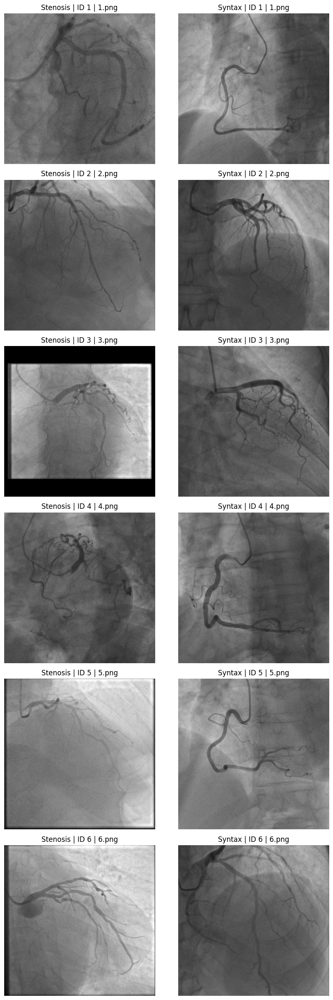

In [ ]:

import os
import json
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

ROOT = "/content/data"
SPLIT = "train"

with open(f"{ROOT}/stenosis/{SPLIT}/annotations/{SPLIT}.json") as f:
    stenosis_json = json.load(f)

with open(f"{ROOT}/syntax/{SPLIT}/annotations/{SPLIT}.json") as f:
    syntax_json = json.load(f)

s_map = {x["id"]: x for x in stenosis_json["images"]}
y_map = {x["id"]: x for x in syntax_json["images"]}

# Use several shared IDs, including an example from each list's beginning.
ids = sorted(set(s_map) & set(y_map))[:6]

fig, axes = plt.subplots(len(ids), 2, figsize=(9, 4 * len(ids)))

for row, image_id in enumerate(ids):
    s_path = os.path.join(
        ROOT, "stenosis", SPLIT, "images", s_map[image_id]["file_name"]
    )
    y_path = os.path.join(
        ROOT, "syntax", SPLIT, "images", y_map[image_id]["file_name"]
    )

    if not os.path.exists(s_path) or not os.path.exists(y_path):
        print("Missing pair:", image_id, s_path, y_path)
        continue

    s_img = np.asarray(Image.open(s_path).convert("RGB"))
    y_img = np.asarray(Image.open(y_path).convert("RGB"))

    axes[row, 0].imshow(s_img)
    axes[row, 0].set_title(
        f"Stenosis | ID {image_id} | {s_map[image_id]['file_name']}"
    )
    axes[row, 0].axis("off")

    axes[row, 1].imshow(y_img)
    axes[row, 1].set_title(
        f"Syntax | ID {image_id} | {y_map[image_id]['file_name']}"
    )
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()


In [ ]:

import os
import pickle
import torch

MODEL_FILES = {
    "U-Net++": "/content/unetplusplus_resnet34_arcade_model.pkl",
    "EfficientNet-B0": "/content/efficientnet_b0_arcade_stenosis_model.pkl",
}

torch.set_num_threads(2)

for name, path in MODEL_FILES.items():
    print("\n" + "=" * 65)
    print(name)
    print("=" * 65)

    if not os.path.isfile(path):
        print("FILE MISSING:", path)
        continue

    print("File:", path)
    print("Size:", round(os.path.getsize(path) / (1024 * 1024), 2), "MB")

    try:
        with open(path, "rb") as f:
            obj = pickle.load(f)

        print("Loaded with Python pickle:", type(obj).__name__)

        if not isinstance(obj, dict):
            print("Object does not contain a metadata dictionary.")
            continue

        print("\nSaved metadata:")
        for key, value in obj.items():
            if key in ("state_dict", "model_state_dict", "model"):
                continue
            print(f"  {key}: {value}")

        state = obj.get(
            "state_dict",
            obj.get("model_state_dict", None)
        )

        if state is None:
            # Some files store the state dictionary directly.
            if obj and all(torch.is_tensor(v) for v in obj.values()):
                state = obj

        if isinstance(state, dict):
            print("\nState dictionary tensors:", len(state))
            for key, value in list(state.items())[:12]:
                shape = tuple(value.shape) if torch.is_tensor(value) else type(value).__name__
                print(f"  {key}: {shape}")
        else:
            print("\nState dictionary not found under common keys.")
            print("Top-level keys:", list(obj.keys())[:25])

    except Exception as e:
        print("LOAD ERROR:", type(e).__name__, str(e)[:500])

print("\n" + "=" * 65)
print("Environment")
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Segmentation package available:", end=" ")

try:
    import segmentation_models_pytorch as smp
    print("yes", getattr(smp, "__version__", "version unknown"))
except ImportError:
    print("no")

print("\nModel audit complete. No training was performed.")



U-Net++
File: /content/unetplusplus_resnet34_arcade_model.pkl
Size: 99.68 MB
Loaded with Python pickle: dict

Saved metadata:
  model_number: 3
  model_name: U-Net++ + ResNet34
  model_type: UnetPlusPlus
  library: segmentation_models_pytorch
  architecture: U-Net++ with ImageNet pretrained ResNet34 encoder
  encoder_name: resnet34
  encoder_pretrained: True
  input_channels: 3
  output_channels: 1
  dataset: ARCADE
  dataset_subset: syntax
  task: Binary Coronary Vessel Segmentation
  image_size: 256
  batch_size: 2
  epochs: 10
  learning_rate: 0.0001
  weight_decay: 1e-05
  loss: 0.5 BCEWithLogitsLoss + 0.5 Dice Loss
  preprocessing: {'resize': [256, 256], 'normalization_mean': [0.485, 0.456, 0.406], 'normalization_std': [0.229, 0.224, 0.225], 'mask_threshold': 0.5}
  best_epoch: 2
  best_val_dice: 0.7867867922782898
  best_val_iou: 0.655205297768116
  best_val_loss: 0.15941399574279785
  history: {'train_loss': [0.4256838186085224, 0.26172924157977107], 'train_dice': [0.5466616250

In [ ]:

# ============================================================
# FINAL PROJECT: MODEL AUDIT
# U-Net++ + ResNet34 and EfficientNet-B0
# CPU ONLY | NO RETRAINING | NO GOOGLE DRIVE
# ============================================================

import os
import pickle
import torch
import torch.nn as nn

print("=" * 65)
print("CORONARY ARTERY DIAGNOSIS — MODEL AUDIT")
print("=" * 65)

torch.set_num_threads(2)
device = torch.device("cpu")

# ------------------------------------------------------------
# 1. Check saved model files
# ------------------------------------------------------------
UNET_PKL = "/content/unetplusplus_resnet34_arcade_model.pkl"
EFF_PKL = "/content/efficientnet_b0_arcade_stenosis_model.pkl"

for name, path in [
    ("U-Net++", UNET_PKL),
    ("EfficientNet-B0", EFF_PKL)
]:
    if not os.path.isfile(path):
        raise FileNotFoundError(
            f"{name} checkpoint missing: {path}\n"
            "Upload the saved PKL file to the current Colab runtime."
        )
    print(f"\n{name}: FOUND ({os.path.getsize(path)/(1024**2):.2f} MB)")

# ------------------------------------------------------------
# 2. Load checkpoint packages
# ------------------------------------------------------------
with open(UNET_PKL, "rb") as f:
    unet_pkg = pickle.load(f)

with open(EFF_PKL, "rb") as f:
    eff_pkg = pickle.load(f)

print("\n--- U-Net++ metadata ---")
for k, v in unet_pkg.items():
    if k not in ("state_dict", "model_state_dict"):
        print(f"{k}: {v}")

print("\n--- EfficientNet-B0 metadata ---")
for k, v in eff_pkg.items():
    if k not in ("state_dict", "model_state_dict"):
        print(f"{k}: {v}")

# ------------------------------------------------------------
# 3. Reconstruct U-Net++
# ------------------------------------------------------------
try:
    import segmentation_models_pytorch as smp
except ImportError:
    raise RuntimeError(
        "Install the segmentation package by running:\n"
        "!pip install -q segmentation-models-pytorch"
    )

unet_state = unet_pkg.get(
    "model_state_dict",
    unet_pkg.get("state_dict")
)

if unet_state is None:
    raise KeyError("U-Net++ checkpoint has no recognized state dictionary.")

unet = smp.UnetPlusPlus(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=3,
    classes=1,
    activation=None
)

unet_load = unet.load_state_dict(unet_state, strict=True)
unet.to(device).eval()

print("\nU-Net++ weight loading:", unet_load)
print("U-Net++ parameters:", sum(p.numel() for p in unet.parameters()))

# ------------------------------------------------------------
# 4. Reconstruct EfficientNet-B0
# ------------------------------------------------------------
from torchvision import models

eff_state = eff_pkg.get(
    "state_dict",
    eff_pkg.get("model_state_dict")
)

if eff_state is None:
    raise KeyError("EfficientNet checkpoint has no recognized state dictionary.")

eff = models.efficientnet_b0(weights=None)
eff.classifier[1] = nn.Linear(
    eff.classifier[1].in_features, 2
)

eff_load = eff.load_state_dict(eff_state, strict=True)
eff.to(device).eval()

print("\nEfficientNet-B0 weight loading:", eff_load)
print("EfficientNet-B0 parameters:", sum(p.numel() for p in eff.parameters()))

# ------------------------------------------------------------
# 5. Verify forward-pass output shapes
# ------------------------------------------------------------
print("\n--- Forward-pass verification ---")

with torch.inference_mode():
    # U-Net++ was trained with 256x256 input
    x_seg = torch.randn(1, 3, 256, 256)
    seg_out = unet(x_seg)
    print("U-Net++ input :", tuple(x_seg.shape))
    print("U-Net++ output:", tuple(seg_out.shape))

    # EfficientNet-B0 was trained with 224x224 input
    x_cls = torch.randn(1, 3, 224, 224)
    cls_out = eff(x_cls)
    print("EfficientNet input :", tuple(x_cls.shape))
    print("EfficientNet output:", tuple(cls_out.shape))

    print("Classifier classes:", eff_pkg.get("idx_to_class"))
    print("Classifier preprocessing:", eff_pkg.get("preprocessing"))

# ------------------------------------------------------------
# 6. Final status
# ------------------------------------------------------------
print("\n" + "=" * 65)
print("AUDIT COMPLETE")
print("Both architectures loaded without retraining.")
print("Segmentation output is a probability-logit map.")
print("Classification output contains two class logits.")
print("=" * 65)


CORONARY ARTERY DIAGNOSIS — MODEL AUDIT

U-Net++: FOUND (99.68 MB)

EfficientNet-B0: FOUND (15.58 MB)

--- U-Net++ metadata ---
model_number: 3
model_name: U-Net++ + ResNet34
model_type: UnetPlusPlus
library: segmentation_models_pytorch
architecture: U-Net++ with ImageNet pretrained ResNet34 encoder
encoder_name: resnet34
encoder_pretrained: True
input_channels: 3
output_channels: 1
dataset: ARCADE
dataset_subset: syntax
task: Binary Coronary Vessel Segmentation
image_size: 256
batch_size: 2
epochs: 10
learning_rate: 0.0001
weight_decay: 1e-05
loss: 0.5 BCEWithLogitsLoss + 0.5 Dice Loss
preprocessing: {'resize': [256, 256], 'normalization_mean': [0.485, 0.456, 0.406], 'normalization_std': [0.229, 0.224, 0.225], 'mask_threshold': 0.5}
best_epoch: 2
best_val_dice: 0.7867867922782898
best_val_iou: 0.655205297768116
best_val_loss: 0.15941399574279785
history: {'train_loss': [0.4256838186085224, 0.26172924157977107], 'train_dice': [0.5466616250500083, 0.6446617726534605], 'train_iou': [0.42

Upload one coronary angiogram image (PNG, JPG, or JPEG):


Saving 1.png to 1.png

Image: 1.png
Original dimensions: 512 x 512

--- Inference results ---
Predicted mask coverage: 5.05%
Mean pixel probability: 0.0542
Mask threshold: 0.5

Saved files:
/content/angiogram_inference/original.png
/content/angiogram_inference/vessel_mask.png
/content/angiogram_inference/vessel_overlay.png
/content/angiogram_inference/probability_map.png


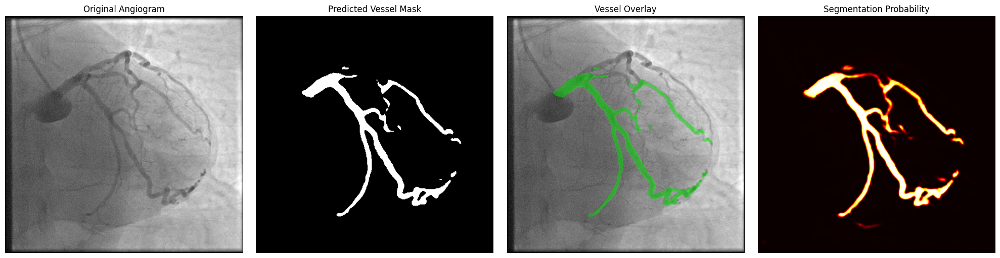


Download results as a ZIP:


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# STEP 2: REAL ANGIOGRAM SEGMENTATION INFERENCE
# Uses the already-loaded U-Net++ model: `unet`
# CPU only | No retraining
# ============================================================

import os
import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import files

# Output directory
OUTPUT_DIR = "/content/angiogram_inference"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# 1. Upload a real angiogram image
print("Upload one coronary angiogram image (PNG, JPG, or JPEG):")
uploaded = files.upload()

if not uploaded:
    raise ValueError("No image uploaded.")

filename = next(iter(uploaded))
image_path = os.path.join("/content", filename)

# 2. Read image and preserve original dimensions
original_bgr = cv2.imread(image_path)

if original_bgr is None:
    raise ValueError("Could not read the uploaded image. Try a PNG or JPG file.")

original_rgb = cv2.cvtColor(original_bgr, cv2.COLOR_BGR2RGB)
original_h, original_w = original_rgb.shape[:2]

print(f"\nImage: {filename}")
print(f"Original dimensions: {original_w} x {original_h}")

# 3. Preprocess according to the saved U-Net++ metadata
resized = cv2.resize(
    original_rgb, (256, 256), interpolation=cv2.INTER_AREA
).astype(np.float32) / 255.0

mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
std = np.array([0.229, 0.224, 0.225], dtype=np.float32)

normalized = (resized - mean) / std
input_tensor = torch.from_numpy(
    normalized.transpose(2, 0, 1)
).unsqueeze(0).float()

# 4. Run inference
unet.eval()
with torch.inference_mode():
    logits = unet(input_tensor)
    probability_256 = torch.sigmoid(logits)[0, 0].cpu().numpy()

# 5. Restore probability map to original dimensions
probability = cv2.resize(
    probability_256, (original_w, original_h),
    interpolation=cv2.INTER_LINEAR
)
threshold = 0.5
mask = (probability >= threshold).astype(np.uint8) * 255

# 6. Create a visualization overlay
overlay = original_rgb.copy()
overlay[mask > 0] = (
    0.55 * overlay[mask > 0] +
    0.45 * np.array([0, 255, 0])
).astype(np.uint8)

# 7. Save output files
original_out = os.path.join(OUTPUT_DIR, "original.png")
mask_out = os.path.join(OUTPUT_DIR, "vessel_mask.png")
overlay_out = os.path.join(OUTPUT_DIR, "vessel_overlay.png")
prob_out = os.path.join(OUTPUT_DIR, "probability_map.png")

Image.fromarray(original_rgb).save(original_out)
Image.fromarray(mask).save(mask_out)
Image.fromarray(overlay).save(overlay_out)

probability_uint8 = np.clip(probability * 255, 0, 255).astype(np.uint8)
Image.fromarray(probability_uint8).save(prob_out)

# 8. Display results
print("\n--- Inference results ---")
print(f"Predicted mask coverage: {100 * np.mean(mask > 0):.2f}%")
print(f"Mean pixel probability: {probability.mean():.4f}")
print(f"Mask threshold: {threshold}")
print("\nSaved files:")
for path in [original_out, mask_out, overlay_out, prob_out]:
    print(path)

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
axes[0].imshow(original_rgb)
axes[0].set_title("Original Angiogram")
axes[1].imshow(mask, cmap="gray")
axes[1].set_title("Predicted Vessel Mask")
axes[2].imshow(overlay)
axes[2].set_title("Vessel Overlay")
axes[3].imshow(probability, cmap="hot", vmin=0, vmax=1)
axes[3].set_title("Segmentation Probability")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("\nDownload results as a ZIP:")
import shutil
zip_path = shutil.make_archive(OUTPUT_DIR, "zip", OUTPUT_DIR)
files.download(zip_path)


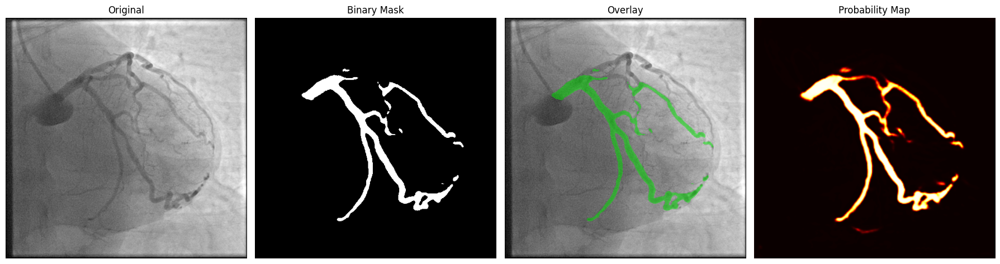


--- EXPERIMENTAL CLASSIFIER OUTPUT ---
Predicted class: positive
Negative score: 0.0010
Positive score: 0.9990

IMPORTANT:
- This uses the full image, not a verified training-compatible ROI.
- Scores are not validated clinical probabilities.
- Do not use this output to diagnose or rule out coronary stenosis.


In [ ]:

# ============================================================
# STEP 3: VISUAL INSPECTION + EXPERIMENTAL CLASSIFICATION
# Reuses existing models; no retraining
# ============================================================

import os
import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image

IMAGE_PATH = "/content/1.png"
OUT_DIR = "/content/angiogram_inference"

# 1. Display the existing segmentation results
original = np.array(Image.open(
    os.path.join(OUT_DIR, "original.png")
).convert("RGB"))

mask = np.array(Image.open(
    os.path.join(OUT_DIR, "vessel_mask.png")
).convert("L"))

overlay = np.array(Image.open(
    os.path.join(OUT_DIR, "vessel_overlay.png")
).convert("RGB"))

prob_map = np.array(Image.open(
    os.path.join(OUT_DIR, "probability_map.png")
).convert("L")) / 255.0

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, img, title, cmap in zip(
    axes,
    [original, mask, overlay, prob_map],
    ["Original", "Binary Mask", "Overlay", "Probability Map"],
    [None, "gray", None, "hot"]
):
    ax.imshow(img, cmap=cmap, vmin=0 if title == "Probability Map" else None,
              vmax=1 if title == "Probability Map" else None)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

# 2. Prepare an exploratory classifier input.
# NOTE: Original training ROI generation is not available.
# This full-image prediction is therefore NOT a validated diagnosis.
if not os.path.exists(IMAGE_PATH):
    raise FileNotFoundError(f"Image not found: {IMAGE_PATH}")

bgr = cv2.imread(IMAGE_PATH)
gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)

# Apply CLAHE, as recorded in classifier metadata
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
gray_clahe = clahe.apply(gray)

# Convert to 3 channels to match the model input architecture
rgb_clahe = cv2.cvtColor(gray_clahe, cv2.COLOR_GRAY2RGB)
resized = cv2.resize(rgb_clahe, (224, 224)).astype(np.float32) / 255.0

mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
std = np.array([0.229, 0.224, 0.225], dtype=np.float32)
normalized = (resized - mean) / std

x = torch.from_numpy(normalized.transpose(2, 0, 1)).unsqueeze(0).float()

eff.eval()
with torch.inference_mode():
    logits = eff(x)
    probabilities = torch.softmax(logits, dim=1)[0].cpu().numpy()

class_map = eff_pkg.get("idx_to_class", {0: "negative", 1: "positive"})
predicted_index = int(np.argmax(probabilities))
predicted_class = class_map[predicted_index]

print("\n--- EXPERIMENTAL CLASSIFIER OUTPUT ---")
print("Predicted class:", predicted_class)
print("Negative score:", f"{probabilities[0]:.4f}")
print("Positive score:", f"{probabilities[1]:.4f}")
print("\nIMPORTANT:")
print("- This uses the full image, not a verified training-compatible ROI.")
print("- Scores are not validated clinical probabilities.")
print("- Do not use this output to diagnose or rule out coronary stenosis.")


Predicted class: positive
Grad-CAM generated for predicted class.
Saved: /content/angiogram_inference/experimental_gradcam_overlay.png
Reminder: this heatmap is exploratory, not validated stenosis localization.


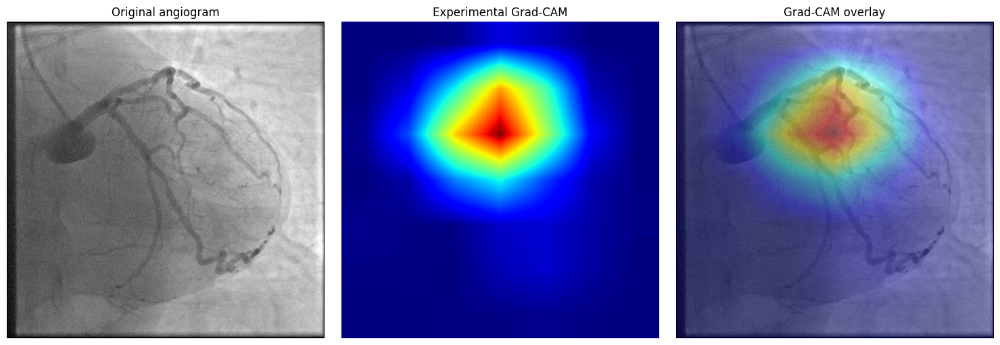

In [ ]:

# ============================================================
# STEP 4: EXPERIMENTAL GRAD-CAM LOCALIZATION
# EfficientNet-B0 | No retraining
# ============================================================

import os
import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image

IMAGE_PATH = "/content/1.png"
OUT_DIR = "/content/angiogram_inference"
os.makedirs(OUT_DIR, exist_ok=True)

# Prepare the image using the same full-image preprocessing
# as the previous experimental classifier run.
bgr = cv2.imread(IMAGE_PATH)
if bgr is None:
    raise FileNotFoundError(f"Image not found: {IMAGE_PATH}")

gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
gray_clahe = clahe.apply(gray)
rgb = cv2.cvtColor(gray_clahe, cv2.COLOR_GRAY2RGB)

resized = cv2.resize(rgb, (224, 224)).astype(np.float32) / 255.0
mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
std = np.array([0.229, 0.224, 0.225], dtype=np.float32)
x_np = (resized - mean) / std
x = torch.from_numpy(x_np.transpose(2, 0, 1)).unsqueeze(0).float()

# Capture activations and gradients from the final feature block
activations = {}
gradients = {}

target_layer = eff.features[-1]

def save_activation(module, inputs, output):
    activations["value"] = output

def save_gradient(module, grad_input, grad_output):
    gradients["value"] = grad_output[0]

forward_handle = target_layer.register_forward_hook(save_activation)
backward_handle = target_layer.register_full_backward_hook(save_gradient)

eff.eval()
eff.zero_grad(set_to_none=True)

logits = eff(x)
class_index = int(torch.argmax(logits, dim=1).item())

# Explain the predicted class score
logits[0, class_index].backward()

A = activations["value"].detach()
G = gradients["value"].detach()

weights = G.mean(dim=(2, 3), keepdim=True)
cam = torch.relu((weights * A).sum(dim=1, keepdim=True))
cam = cam[0, 0].cpu().numpy()

if cam.max() > cam.min():
    cam = (cam - cam.min()) / (cam.max() - cam.min())
else:
    cam = np.zeros_like(cam)

forward_handle.remove()
backward_handle.remove()

# Resize heatmap to original dimensions
heatmap = cv2.resize(cam, (bgr.shape[1], bgr.shape[0]))
original_rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

heatmap_uint8 = np.uint8(np.clip(heatmap * 255, 0, 255))
colored_heatmap = cv2.applyColorMap(heatmap_uint8, cv2.COLORMAP_JET)
colored_heatmap = cv2.cvtColor(colored_heatmap, cv2.COLOR_BGR2RGB)

overlay = cv2.addWeighted(original_rgb, 0.60, colored_heatmap, 0.40, 0)

# Save outputs
Image.fromarray(heatmap_uint8).save(
    os.path.join(OUT_DIR, "experimental_gradcam.png")
)
Image.fromarray(overlay).save(
    os.path.join(OUT_DIR, "experimental_gradcam_overlay.png")
)

class_map = eff_pkg.get("idx_to_class", {0: "negative", 1: "positive"})
print("Predicted class:", class_map[class_index])
print("Grad-CAM generated for predicted class.")
print("Saved:", os.path.join(OUT_DIR, "experimental_gradcam_overlay.png"))
print("Reminder: this heatmap is exploratory, not validated stenosis localization.")

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(original_rgb)
plt.title("Original angiogram")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap, cmap="jet", vmin=0, vmax=1)
plt.title("Experimental Grad-CAM")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(overlay)
plt.title("Grad-CAM overlay")
plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

import os
import json
from collections import Counter

BASE = "/content/data/stenosis"

for split in ["train", "val", "test"]:
    ann_path = os.path.join(
        BASE, split, "annotations", f"{split}.json"
    )

    print("\n" + "=" * 55)
    print("SPLIT:", split)

    if not os.path.exists(ann_path):
        print("Annotation file not found:", ann_path)
        continue

    with open(ann_path, "r") as f:
        data = json.load(f)

    print("Top-level keys:", list(data.keys()))
    print("Images:", len(data.get("images", [])))
    print("Annotations:", len(data.get("annotations", [])))

    categories = {
        c["id"]: c.get("name", "unknown")
        for c in data.get("categories", [])
    }
    print("Categories:", categories)

    annotations = data.get("annotations", [])
    print("Annotation keys:",
          sorted(set(k for a in annotations for k in a.keys())))

    print("Category counts:")
    print(Counter(
        categories.get(a.get("category_id"), str(a.get("category_id")))
        for a in annotations
    ))

    for a in annotations[:2]:
        print("Example annotation:", {
            k: (str(v)[:180] if k != "segmentation" else
                str(v)[:180])
            for k, v in a.items()
        })



SPLIT: train
Top-level keys: ['images', 'annotations', 'categories']
Images: 1000
Annotations: 1625
Categories: {1: '1', 2: '2', 3: '3', 4: '4', 5: '5', 6: '6', 7: '7', 8: '8', 9: '9', 10: '9a', 11: '10', 12: '10a', 13: '11', 14: '12', 15: '12a', 16: '13', 17: '14', 18: '14a', 19: '15', 20: '16', 21: '16a', 22: '16b', 23: '16c', 24: '12b', 25: '14b', 26: 'stenosis'}
Annotation keys: ['area', 'attributes', 'bbox', 'category_id', 'id', 'image_id', 'iscrowd', 'segmentation']
Category counts:
Counter({'stenosis': 1625})
Example annotation: {'id': '1', 'image_id': '676', 'category_id': '26', 'segmentation': '[[278.0, 291.75, 286.75, 299.25, 289.5, 296.25, 291.75, 293.25, 294.0, 290.25, 296.5, 287.5, 298.75, 284.25, 300.75, 281.25, 303.0, 278.25, 305.0, 275.0, 307.0, 271.75, 309.0, 269.', 'area': '708.0', 'bbox': '[278.0, 245.12, 42.75, 54.13]', 'iscrowd': '0', 'attributes': "{'occluded': False}"}
Example annotation: {'id': '2', 'image_id': '960', 'category_id': '26', 'segmentation': '[[294

Image ID: 676
Image file: 676.png
Image dimensions: 512 x 512
Stenosis annotations: 1
Ground-truth mask coverage: 0.29%


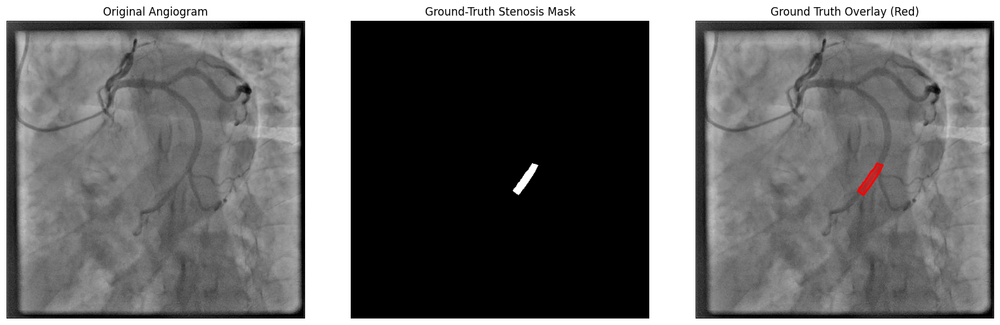

In [ ]:

# ============================================================
# STEP 5: PREVIEW ARCADE STENOSIS GROUND-TRUTH ANNOTATIONS
# No training; no model changes
# ============================================================

import os
import json
import ast
import cv2
import numpy as np
import matplotlib.pyplot as plt

ANN_PATH = "/content/data/stenosis/train/annotations/train.json"
IMG_DIR = "/content/data/stenosis/train/images"

with open(ANN_PATH, "r") as f:
    data = json.load(f)

# Find an image with a stenosis polygon
images_by_id = {str(img["id"]): img for img in data["images"]}
annotations_by_image = {}

for ann in data["annotations"]:
    if int(ann["category_id"]) == 26:
        annotations_by_image.setdefault(str(ann["image_id"]), []).append(ann)

selected = None
for image_id, anns in annotations_by_image.items():
    if any(ann.get("segmentation") for ann in anns):
        selected = (image_id, anns)
        break

if selected is None:
    raise RuntimeError("No stenosis polygons found.")

image_id, anns = selected
image_info = images_by_id[image_id]
filename = image_info["file_name"]

# Support either a direct filename or a relative subfolder path
image_path = os.path.join(IMG_DIR, filename)
if not os.path.exists(image_path):
    image_path = os.path.join(IMG_DIR, os.path.basename(filename))

if not os.path.exists(image_path):
    raise FileNotFoundError(
        f"Image file not found: {filename}\nChecked: {image_path}"
    )

bgr = cv2.imread(image_path)
if bgr is None:
    raise RuntimeError(f"Could not read image: {image_path}")

rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
overlay = rgb.copy()
gt_mask = np.zeros(rgb.shape[:2], dtype=np.uint8)

# Parse the dataset's serialized polygon coordinates
for ann in anns:
    seg = ann.get("segmentation", [])
    if isinstance(seg, str):
        seg = ast.literal_eval(seg)

    # COCO-style polygon: list of coordinate lists
    for polygon in seg:
        coords = np.asarray(polygon, dtype=np.float32).reshape(-1, 2)
        if len(coords) >= 3:
            pts = np.round(coords).astype(np.int32)
            cv2.fillPoly(gt_mask, [pts], 255)
            cv2.polylines(overlay, [pts], True, (255, 0, 0), 2)

# Red-tinted fill for ground-truth lesion area
red = np.zeros_like(overlay)
red[:, :, 0] = 255
region = gt_mask > 0
overlay[region] = (
    0.45 * overlay[region] + 0.55 * red[region]
).astype(np.uint8)

print("Image ID:", image_id)
print("Image file:", filename)
print("Image dimensions:", rgb.shape[1], "x", rgb.shape[0])
print("Stenosis annotations:", len(anns))
print("Ground-truth mask coverage:",
      f"{100 * region.mean():.2f}%")

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].imshow(rgb)
axes[0].set_title("Original Angiogram")
axes[1].imshow(gt_mask, cmap="gray")
axes[1].set_title("Ground-Truth Stenosis Mask")
axes[2].imshow(overlay)
axes[2].set_title("Ground Truth Overlay (Red)")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

# ============================================================
# STEP 6A: PREPARE STENOSIS SEGMENTATION TRAINING
# CPU compatible | Does not overwrite existing models
# ============================================================

import os
import json
import torch

TRAIN_IMG = "/content/data/stenosis/train/images"
TRAIN_ANN = "/content/data/stenosis/train/annotations/train.json"
VAL_IMG = "/content/data/stenosis/val/images"
VAL_ANN = "/content/data/stenosis/val/annotations/val.json"

for path in [TRAIN_IMG, TRAIN_ANN, VAL_IMG, VAL_ANN]:
    print(("FOUND " if os.path.exists(path) else "MISSING "), path)

if not all(os.path.exists(p) for p in [
    TRAIN_IMG, TRAIN_ANN, VAL_IMG, VAL_ANN
]):
    raise FileNotFoundError(
        "A required ARCADE stenosis training/validation path is missing."
    )

with open(TRAIN_ANN) as f:
    train_data = json.load(f)

with open(VAL_ANN) as f:
    val_data = json.load(f)

print("\nTraining images:", len(train_data["images"]))
print("Training lesion annotations:", len(train_data["annotations"]))
print("Validation images:", len(val_data["images"]))
print("Validation lesion annotations:", len(val_data["annotations"]))

print("\nPyTorch:", torch.__version__)
print("Device: CPU")
print("Existing U-Net++ checkpoint preserved.")
print("Existing EfficientNet-B0 checkpoint preserved.")
print("\nSetup check complete.")


FOUND  /content/data/stenosis/train/images
FOUND  /content/data/stenosis/train/annotations/train.json
FOUND  /content/data/stenosis/val/images
FOUND  /content/data/stenosis/val/annotations/val.json

Training images: 1000
Training lesion annotations: 1625
Validation images: 200
Validation lesion annotations: 406

PyTorch: 2.11.0+cpu
Device: CPU
Existing U-Net++ checkpoint preserved.
Existing EfficientNet-B0 checkpoint preserved.

Setup check complete.


In [ ]:

%pip install -q segmentation-models-pytorch


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 5.1 MB/s eta 0:00:00


In [ ]:

import torch
import segmentation_models_pytorch as smp

print("PyTorch:", torch.__version__)
print("Segmentation Models PyTorch:", smp.__version__)
print("U-Net available:", hasattr(smp, "Unet"))
print("U-Net++ available:", hasattr(smp, "UnetPlusPlus"))
print("Ready for stenosis-mask training.")


PyTorch: 2.11.0+cpu
Segmentation Models PyTorch: 0.5.0
U-Net available: True
U-Net++ available: True
Ready for stenosis-mask training.


In [ ]:
import os

for path in [
    "/content/data/stenosis/train/annotations/train.json",
    "/content/data/stenosis/val/annotations/val.json",
    "/content/data/stenosis/test/annotations/test.json",
    "/content/unetplusplus_resnet34_arcade_model.pkl",
    "/content/efficientnet_b0_arcade_stenosis_model.pkl"
]:
    print(("FOUND" if os.path.exists(path) else "MISSING"), path)

MISSING /content/data/stenosis/train/annotations/train.json
MISSING /content/data/stenosis/val/annotations/val.json
MISSING /content/data/stenosis/test/annotations/test.json
MISSING /content/unetplusplus_resnet34_arcade_model.pkl
MISSING /content/efficientnet_b0_arcade_stenosis_model.pkl


In [ ]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:

import os

PROJECT_DIR = "/content/drive/MyDrive/ARCADE_CAD_Project"

folders = [
    "dataset",
    "models",
    "outputs",
    "logs"
]

for folder in folders:
    os.makedirs(os.path.join(PROJECT_DIR, folder), exist_ok=True)

print("Permanent project folder:", PROJECT_DIR)
for folder in folders:
    print(os.path.join(PROJECT_DIR, folder))


Permanent project folder: /content/drive/MyDrive/ARCADE_CAD_Project
/content/drive/MyDrive/ARCADE_CAD_Project/dataset
/content/drive/MyDrive/ARCADE_CAD_Project/models
/content/drive/MyDrive/ARCADE_CAD_Project/outputs
/content/drive/MyDrive/ARCADE_CAD_Project/logs


In [ ]:

import os

PROJECT_DIR = "/content/drive/MyDrive/ARCADE_CAD_Project"

print("Project folder exists:", os.path.exists(PROJECT_DIR))

for root, dirs, files in os.walk(PROJECT_DIR):
    level = root.replace(PROJECT_DIR, "").count(os.sep)
    print("  " * level + os.path.basename(root) + "/")
    for filename in files:
        print("  " * (level + 1) + filename)


Project folder exists: True
ARCADE_CAD_Project/
  dataset/
  models/
  outputs/
  logs/


In [ ]:

from google.colab import drive
drive.mount("/content/drive")

import os

DRIVE_ROOT = "/content/drive/MyDrive"

required_files = {
    "train.json",
    "val.json",
    "test.json",
    "unetplusplus_resnet34_arcade_model.pkl",
    "efficientnet_b0_arcade_stenosis_model.pkl"
}

found = {name: [] for name in required_files}

for root, dirs, files in os.walk(DRIVE_ROOT):
    dirs[:] = [
        d for d in dirs
        if d not in {".Trash", ".cache", "__pycache__"}
    ]

    for filename in files:
        if filename in found:
            found[filename].append(os.path.join(root, filename))

print("\n========== FILE DISCOVERY ==========")
for filename, paths in found.items():
    print(f"\n{filename}:")
    if paths:
        for path in paths:
            print("  FOUND:", path)
    else:
        print("  NOT FOUND")

print("\n========== NEXT STEP ==========")
if all(found[name] for name in required_files):
    print("All expected files found. We can configure the project paths.")
else:
    print("Some files were not found. Check the filenames and extraction folders.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

========== FILE DISCOVERY ==========

val.json:
  FOUND: /content/drive/MyDrive/REDDY/dataset/data/syntax/val/annotations/val.json
  FOUND: /content/drive/MyDrive/REDDY/dataset/data/stenosis/val/annotations/val.json

efficientnet_b0_arcade_stenosis_model.pkl:
  FOUND: /content/drive/MyDrive/REDDY/efficientnet_b0_arcade_stenosis_model.pkl

test.json:
  FOUND: /content/drive/MyDrive/REDDY/dataset/data/syntax/test/annotations/test.json
  FOUND: /content/drive/MyDrive/REDDY/dataset/data/stenosis/test/annotations/test.json

unetplusplus_resnet34_arcade_model.pkl:
  FOUND: /content/drive/MyDrive/REDDY/unetplusplus_resnet34_arcade_model.pkl

train.json:
  FOUND: /content/drive/MyDrive/REDDY/dataset/data/syntax/train/annotations/train.json
  FOUND: /content/drive/MyDrive/REDDY/dataset/data/stenosis/train/annotations/train.json

========== NEXT STEP ==========
All ex

In [ ]:

%pip install -q segmentation-models-pytorch


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 3.8 MB/s eta 0:00:00


In [ ]:

import torch
import segmentation_models_pytorch as smp

print("PyTorch:", torch.__version__)
print("SMP:", smp.__version__)
print("U-Net available:", hasattr(smp, "Unet"))
print("Installation successful!")


PyTorch: 2.11.0+cpu
SMP: 0.5.0
U-Net available: True
Installation successful!


In [ ]:

# Correct paths for your Google Drive dataset
from google.colab import drive
drive.mount("/content/drive")

ROOT = "/content/drive/MyDrive/REDDY"
DATA = f"{ROOT}/dataset/data"

TRAIN_IMG = f"{DATA}/stenosis/train/images"
TRAIN_ANN = f"{DATA}/stenosis/train/annotations/train.json"
VAL_IMG = f"{DATA}/stenosis/val/images"
VAL_ANN = f"{DATA}/stenosis/val/annotations/val.json"

UNET_PKL = f"{ROOT}/unetplusplus_resnet34_arcade_model.pkl"
MODEL_DIR = f"{ROOT}/models"
OUTPUT_DIR = f"{ROOT}/outputs"
LOG_DIR = f"{ROOT}/logs"

import os
for folder in [MODEL_DIR, OUTPUT_DIR, LOG_DIR]:
    os.makedirs(folder, exist_ok=True)

for path in [TRAIN_IMG, TRAIN_ANN, VAL_IMG, VAL_ANN, UNET_PKL]:
    print(("FOUND  " if os.path.exists(path) else "MISSING"), path)

if not all(os.path.exists(p) for p in [
    TRAIN_IMG, TRAIN_ANN, VAL_IMG, VAL_ANN, UNET_PKL
]):
    raise FileNotFoundError("A required path is missing. Check the printed paths.")

print("\nAll required paths are ready.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
FOUND   /content/drive/MyDrive/REDDY/dataset/data/stenosis/train/images
FOUND   /content/drive/MyDrive/REDDY/dataset/data/stenosis/train/annotations/train.json
FOUND   /content/drive/MyDrive/REDDY/dataset/data/stenosis/val/images
FOUND   /content/drive/MyDrive/REDDY/dataset/data/stenosis/val/annotations/val.json
FOUND   /content/drive/MyDrive/REDDY/unetplusplus_resnet34_arcade_model.pkl

All required paths are ready.


In [ ]:

# ================================================================
# ARCADE STENOSIS SEGMENTATION — COMPLETE TRAINING PIPELINE
# Dataset + annotations + training + validation + permanent saving
# Google Colab CPU compatible
# ================================================================

import os
import json
import ast
import time
import pickle
import random
import numpy as np
import cv2
import torch
import torch.nn as nn
import segmentation_models_pytorch as smp

from torch.utils.data import Dataset, DataLoader

# ----------------------- 1. CONFIGURATION ------------------------

SEED = 42
IMAGE_SIZE = 256
BATCH_SIZE = 2
EPOCHS = 8
LEARNING_RATE = 1e-4
NUM_THREADS = 2
STENOSIS_CATEGORY_ID = 26

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(NUM_THREADS)

device = torch.device("cpu")

# ----------------------- 2. GOOGLE DRIVE -------------------------

from google.colab import drive
drive.mount("/content/drive")

ROOT = "/content/drive/MyDrive/REDDY"
DATA = f"{ROOT}/dataset/data"

TRAIN_IMG = f"{DATA}/stenosis/train/images"
TRAIN_ANN = f"{DATA}/stenosis/train/annotations/train.json"
VAL_IMG = f"{DATA}/stenosis/val/images"
VAL_ANN = f"{DATA}/stenosis/val/annotations/val.json"

PRETRAINED_PKL = f"{ROOT}/unetplusplus_resnet34_arcade_model.pkl"

MODEL_DIR = f"{ROOT}/models"
LOG_DIR = f"{ROOT}/logs"
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(LOG_DIR, exist_ok=True)

BEST_MODEL_PATH = f"{MODEL_DIR}/arcade_stenosis_unet_best.pth"
HISTORY_PATH = f"{LOG_DIR}/stenosis_training_history.json"

# Check all required paths before training
required_paths = [
    TRAIN_IMG, TRAIN_ANN, VAL_IMG, VAL_ANN, PRETRAINED_PKL
]

print("\nChecking required files...")
for path in required_paths:
    print(("FOUND   " if os.path.exists(path) else "MISSING "), path)

missing = [p for p in required_paths if not os.path.exists(p)]
if missing:
    raise FileNotFoundError(
        "\nRequired path(s) missing. Check the Google Drive folder names:\n"
        + "\n".join(missing)
    )

# ----------------------- 3. DATASET ------------------------------

IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)


def parse_polygon_data(segmentation):
    """Convert the annotation segmentation into a list of polygons."""
    if isinstance(segmentation, str):
        try:
            segmentation = ast.literal_eval(segmentation)
        except (ValueError, SyntaxError):
            return []

    if not isinstance(segmentation, (list, tuple)):
        return []

    polygons = []

    # COCO-style polygons: [[x1,y1,x2,y2,...], ...]
    for item in segmentation:
        if not isinstance(item, (list, tuple)):
            continue

        arr = np.asarray(item)

        if arr.ndim == 1 and arr.size >= 6 and arr.size % 2 == 0:
            try:
                polygons.append(
                    arr.astype(np.float32).reshape(-1, 2)
                )
            except (ValueError, TypeError):
                pass

        elif arr.ndim == 2 and arr.shape[-1] == 2 and len(arr) >= 3:
            polygons.append(arr.astype(np.float32))

        elif arr.ndim > 1:
            # Handle an extra level of nested lists.
            polygons.extend(parse_polygon_data(item))

    return polygons


class ArcadeStenosisDataset(Dataset):
    def __init__(self, image_dir, annotation_file, image_size=256):
        self.image_dir = image_dir
        self.image_size = image_size

        with open(annotation_file, "r") as f:
            data = json.load(f)

        images = data.get("images", [])
        annotations = data.get("annotations", [])

        # Only use annotations belonging to the stenosis category.
        stenosis_annotations = {}
        for ann in annotations:
            if int(ann.get("category_id", -1)) == STENOSIS_CATEGORY_ID:
                stenosis_annotations.setdefault(
                    ann["image_id"], []
                ).append(ann)

        self.samples = []
        for img_info in images:
            if img_info["id"] in stenosis_annotations:
                self.samples.append(
                    (img_info, stenosis_annotations[img_info["id"]])
                )

        print(
            f"{os.path.basename(image_dir)}: "
            f"{len(images)} images, "
            f"{len(self.samples)} images with stenosis annotations"
        )

        if not self.samples:
            raise ValueError(
                f"No category {STENOSIS_CATEGORY_ID} annotations found "
                f"in {annotation_file}. Check the category ID."
            )

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        img_info, anns = self.samples[index]
        filename = os.path.basename(img_info["file_name"])
        image_path = os.path.join(self.image_dir, filename)

        if not os.path.isfile(image_path):
            raise FileNotFoundError(f"Image not found: {image_path}")

        image = cv2.imread(image_path, cv2.IMREAD_COLOR)
        if image is None:
            raise ValueError(f"Could not read image: {image_path}")

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        original_h, original_w = image.shape[:2]

        mask = np.zeros((original_h, original_w), dtype=np.uint8)

        for ann in anns:
            polygons = parse_polygon_data(ann.get("segmentation", []))

            for polygon in polygons:
                polygon = polygon.copy()
                polygon[:, 0] = np.clip(polygon[:, 0], 0, original_w - 1)
                polygon[:, 1] = np.clip(polygon[:, 1], 0, original_h - 1)

                polygon = np.round(polygon).astype(np.int32)
                if len(polygon) >= 3:
                    cv2.fillPoly(mask, [polygon], 1)

        # Resize image and mask to model input dimensions.
        image = cv2.resize(
            image, (self.image_size, self.image_size),
            interpolation=cv2.INTER_AREA
        )
        mask = cv2.resize(
            mask, (self.image_size, self.image_size),
            interpolation=cv2.INTER_NEAREST
        )

        image = image.astype(np.float32) / 255.0
        image = (image - IMAGENET_MEAN) / IMAGENET_STD

        image = torch.from_numpy(
            np.ascontiguousarray(image.transpose(2, 0, 1))
        ).float()

        mask = torch.from_numpy(
            np.ascontiguousarray(mask[None, :, :])
        ).float()

        return image, mask


print("\nCreating datasets...")
train_ds = ArcadeStenosisDataset(TRAIN_IMG, TRAIN_ANN, IMAGE_SIZE)
val_ds = ArcadeStenosisDataset(VAL_IMG, VAL_ANN, IMAGE_SIZE)

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=0, pin_memory=False
)

val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0, pin_memory=False
)

print("Training images:", len(train_ds))
print("Validation images:", len(val_ds))

# ----------------------- 4. MODEL -------------------------------

print("\nCreating U-Net ResNet34 segmentation model...")

model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=3,
    classes=1,
    activation=None
).to(device)

# Transfer compatible encoder weights from your existing U-Net++.
print("Loading compatible pretrained encoder weights...")
with open(PRETRAINED_PKL, "rb") as f:
    saved = pickle.load(f)

old_state = saved.get("model_state_dict", saved.get("state_dict", saved))
current_state = model.state_dict()

compatible = {}
for key, value in old_state.items():
    if (
        key.startswith("encoder.")
        and key in current_state
        and hasattr(value, "shape")
        and value.shape == current_state[key].shape
    ):
        compatible[key] = value

if compatible:
    current_state.update(compatible)
    model.load_state_dict(current_state)
    print(f"Transferred {len(compatible)} compatible encoder tensors.")
else:
    print(
        "WARNING: No compatible encoder tensors were found. "
        "Training will start with randomly initialized weights."
    )

print(f"Model parameters: {sum(p.numel() for p in model.parameters()):,}")

# ----------------------- 5. LOSS AND METRICS ---------------------

bce_loss = nn.BCEWithLogitsLoss()


def segmentation_loss(logits, targets):
    bce = bce_loss(logits, targets)

    probs = torch.sigmoid(logits)
    dims = (1, 2, 3)

    intersection = (probs * targets).sum(dim=dims)
    denominator = probs.sum(dim=dims) + targets.sum(dim=dims)

    dice = (2.0 * intersection + 1e-6) / (denominator + 1e-6)
    dice_loss = 1.0 - dice.mean()

    return bce + dice_loss


def calculate_metrics(logits, targets, threshold=0.5):
    predictions = (torch.sigmoid(logits) >= threshold).float()

    dims = (1, 2, 3)
    intersection = (predictions * targets).sum(dim=dims)
    pred_sum = predictions.sum(dim=dims)
    target_sum = targets.sum(dim=dims)

    dice = (2 * intersection + 1e-6) / (
        pred_sum + target_sum + 1e-6
    )
    iou = (intersection + 1e-6) / (
        pred_sum + target_sum - intersection + 1e-6
    )

    return dice.mean().item(), iou.mean().item()


optimizer = torch.optim.AdamW(
    model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4
)

# ----------------------- 6. TRAINING -----------------------------

history = []
best_val_dice = -1.0

print("\nStarting training on CPU...")
print("The first epoch may take some time.\n")

for epoch in range(1, EPOCHS + 1):
    start_time = time.time()

    # Training phase
    model.train()
    train_loss_sum = 0.0
    train_dice_sum = 0.0
    train_iou_sum = 0.0
    train_count = 0

    for batch_idx, (images, masks) in enumerate(train_loader, start=1):
        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = segmentation_loss(logits, masks)

        loss.backward()
        optimizer.step()

        batch_dice, batch_iou = calculate_metrics(logits.detach(), masks)
        batch_n = images.size(0)

        train_loss_sum += loss.item() * batch_n
        train_dice_sum += batch_dice * batch_n
        train_iou_sum += batch_iou * batch_n
        train_count += batch_n

        if batch_idx % 100 == 0:
            print(
                f"Epoch {epoch}/{EPOCHS} | "
                f"Batch {batch_idx}/{len(train_loader)} | "
                f"Loss {loss.item():.4f}"
            )

    train_loss = train_loss_sum / max(train_count, 1)
    train_dice = train_dice_sum / max(train_count, 1)
    train_iou = train_iou_sum / max(train_count, 1)

    # Validation phase
    model.eval()
    val_loss_sum = 0.0
    val_dice_sum = 0.0
    val_iou_sum = 0.0
    val_count = 0

    with torch.no_grad():
        for images, masks in val_loader:
            images = images.to(device)
            masks = masks.to(device)

            logits = model(images)
            loss = segmentation_loss(logits, masks)

            batch_dice, batch_iou = calculate_metrics(logits, masks)
            batch_n = images.size(0)

            val_loss_sum += loss.item() * batch_n
            val_dice_sum += batch_dice * batch_n
            val_iou_sum += batch_iou * batch_n
            val_count += batch_n

    val_loss = val_loss_sum / max(val_count, 1)
    val_dice = val_dice_sum / max(val_count, 1)
    val_iou = val_iou_sum / max(val_count, 1)

    epoch_time = time.time() - start_time

    record = {
        "epoch": epoch,
        "train_loss": round(train_loss, 6),
        "train_dice": round(train_dice, 6),
        "train_iou": round(train_iou, 6),
        "val_loss": round(val_loss, 6),
        "val_dice": round(val_dice, 6),
        "val_iou": round(val_iou, 6),
        "seconds": round(epoch_time, 2)
    }
    history.append(record)

    print("\n" + "=" * 65)
    print(f"Epoch {epoch}/{EPOCHS} completed in {epoch_time/60:.1f} min")
    print(f"Train Loss: {train_loss:.4f} | Dice: {train_dice:.4f} | IoU: {train_iou:.4f}")
    print(f"Val   Loss: {val_loss:.4f} | Dice: {val_dice:.4f} | IoU: {val_iou:.4f}")

    # Save best model directly to Google Drive.
    if val_dice > best_val_dice:
        best_val_dice = val_dice

        torch.save({
            "model_state_dict": model.state_dict(),
            "image_size": IMAGE_SIZE,
            "encoder_name": "resnet34",
            "model_name": "Unet",
            "mean": IMAGENET_MEAN.tolist(),
            "std": IMAGENET_STD.tolist(),
            "threshold": 0.5,
            "category_id": STENOSIS_CATEGORY_ID,
            "epoch": epoch,
            "val_dice": val_dice,
            "val_iou": val_iou
        }, BEST_MODEL_PATH)

        print(f"BEST MODEL SAVED: {BEST_MODEL_PATH}")

    # Save progress after every epoch.
    with open(HISTORY_PATH, "w") as f:
        json.dump(history, f, indent=2)

    print("=" * 65 + "\n")

# ----------------------- 7. FINAL SUMMARY ------------------------

print("\nTRAINING FINISHED")
print("Best validation Dice:", round(best_val_dice, 4))
print("Best model:", BEST_MODEL_PATH)
print("Training history:", HISTORY_PATH)
print("\nFiles saved in Google Drive; they will remain after runtime resets.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Checking required files...
FOUND    /content/drive/MyDrive/REDDY/dataset/data/stenosis/train/images
FOUND    /content/drive/MyDrive/REDDY/dataset/data/stenosis/train/annotations/train.json
FOUND    /content/drive/MyDrive/REDDY/dataset/data/stenosis/val/images
FOUND    /content/drive/MyDrive/REDDY/dataset/data/stenosis/val/annotations/val.json
FOUND    /content/drive/MyDrive/REDDY/unetplusplus_resnet34_arcade_model.pkl

Creating datasets...
images: 1000 images, 997 images with stenosis annotations
images: 200 images, 200 images with stenosis annotations
Training images: 997
Validation images: 200

Creating U-Net ResNet34 segmentation model...
Loading compatible pretrained encoder weights...
Transferred 216 compatible encoder tensors.
Model parameters: 24,436,369

Starting training on CPU...
The first epoch may take some time.

Epoch 1/8 | Batch 100/499 | Loss

Mounted at /content/drive


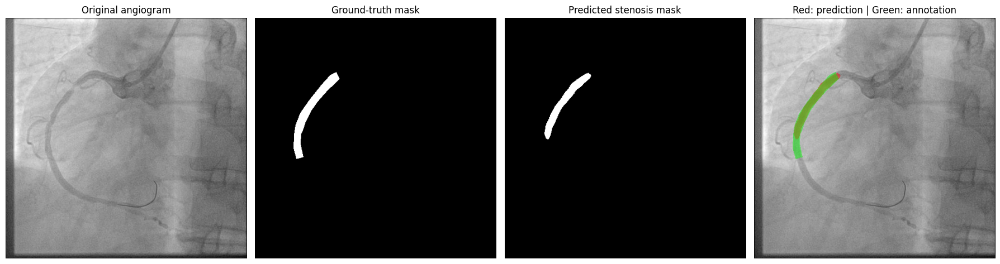

Validation image: 1.png
Checkpoint epoch: 8
Image Dice: 0.8124
Image IoU: 0.6841
Saved overlay: /content/drive/MyDrive/REDDY/outputs/stenosis_validation_preview.png


In [ ]:

import os, json, ast
import numpy as np
import cv2
import torch
import matplotlib.pyplot as plt
import segmentation_models_pytorch as smp
from google.colab import drive

drive.mount("/content/drive")

ROOT = "/content/drive/MyDrive/REDDY"
IMAGE_DIR = f"{ROOT}/dataset/data/stenosis/val/images"
ANN_PATH = f"{ROOT}/dataset/data/stenosis/val/annotations/val.json"
MODEL_PATH = f"{ROOT}/models/arcade_stenosis_unet_best.pth"
OUT_DIR = f"{ROOT}/outputs"
os.makedirs(OUT_DIR, exist_ok=True)

checkpoint = torch.load(
    MODEL_PATH, map_location="cpu", weights_only=False
)

SIZE = int(checkpoint.get("image_size", 256))
MEAN = np.array(checkpoint.get("mean", [0.485, 0.456, 0.406]), np.float32)
STD = np.array(checkpoint.get("std", [0.229, 0.224, 0.225]), np.float32)
THRESHOLD = float(checkpoint.get("threshold", 0.5))

model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=3,
    classes=1,
    activation=None
)
model.load_state_dict(checkpoint["model_state_dict"], strict=True)
model.eval()

with open(ANN_PATH) as f:
    data = json.load(f)

anns_by_id = {}
for ann in data["annotations"]:
    if int(ann.get("category_id", -1)) == 26:
        anns_by_id.setdefault(ann["image_id"], []).append(ann)

sample = next(
    (im for im in data["images"] if im["id"] in anns_by_id),
    None
)
if sample is None:
    raise RuntimeError("No stenosis annotations found in validation set.")

image_path = os.path.join(IMAGE_DIR, os.path.basename(sample["file_name"]))
bgr = cv2.imread(image_path)
if bgr is None:
    raise FileNotFoundError(image_path)

original = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
h, w = original.shape[:2]
gt = np.zeros((h, w), np.uint8)

def polygon_list(seg):
    if isinstance(seg, str):
        try:
            seg = ast.literal_eval(seg)
        except (ValueError, SyntaxError):
            return []
    if not isinstance(seg, (list, tuple)):
        return []
    result = []
    for p in seg:
        arr = np.asarray(p)
        if arr.ndim == 1 and arr.size >= 6 and arr.size % 2 == 0:
            result.append(arr.reshape(-1, 2))
        elif arr.ndim == 2 and arr.shape[1] == 2 and len(arr) >= 3:
            result.append(arr)
    return result

for ann in anns_by_id[sample["id"]]:
    for poly in polygon_list(ann.get("segmentation", [])):
        pts = np.round(poly).astype(np.int32)
        cv2.fillPoly(gt, [pts], 1)

resized = cv2.resize(original, (SIZE, SIZE), interpolation=cv2.INTER_AREA)
x = resized.astype(np.float32) / 255.0
x = (x - MEAN) / STD
x = torch.from_numpy(x.transpose(2, 0, 1).copy()).float().unsqueeze(0)

with torch.no_grad():
    prob_small = torch.sigmoid(model(x))[0, 0].numpy()

prob = cv2.resize(prob_small, (w, h), interpolation=cv2.INTER_LINEAR)
pred = (prob >= THRESHOLD).astype(np.uint8)

intersection = np.logical_and(pred, gt).sum()
dice = 2 * intersection / (pred.sum() + gt.sum() + 1e-8)
iou = intersection / (np.logical_or(pred, gt).sum() + 1e-8)

overlay = original.copy()
overlay[pred == 1] = (
    0.55 * overlay[pred == 1] + 0.45 * np.array([255, 0, 0])
).astype(np.uint8)
overlay[gt == 1] = (
    0.55 * overlay[gt == 1] + 0.45 * np.array([0, 255, 0])
).astype(np.uint8)

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
axes[0].imshow(original)
axes[0].set_title("Original angiogram")
axes[1].imshow(gt, cmap="gray")
axes[1].set_title("Ground-truth mask")
axes[2].imshow(pred, cmap="gray")
axes[2].set_title("Predicted stenosis mask")
axes[3].imshow(overlay)
axes[3].set_title("Red: prediction | Green: annotation")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

out_path = f"{OUT_DIR}/stenosis_validation_preview.png"
cv2.imwrite(out_path, cv2.cvtColor(overlay, cv2.COLOR_RGB2BGR))

print("Validation image:", sample["file_name"])
print("Checkpoint epoch:", checkpoint.get("epoch", "unknown"))
print(f"Image Dice: {dice:.4f}")
print(f"Image IoU: {iou:.4f}")
print("Saved overlay:", out_path)


In [ ]:
!pip install -q segmentation-models-pytorch

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using device: cpu
Loaded checkpoint from epoch: 8
Validation image: 1.png


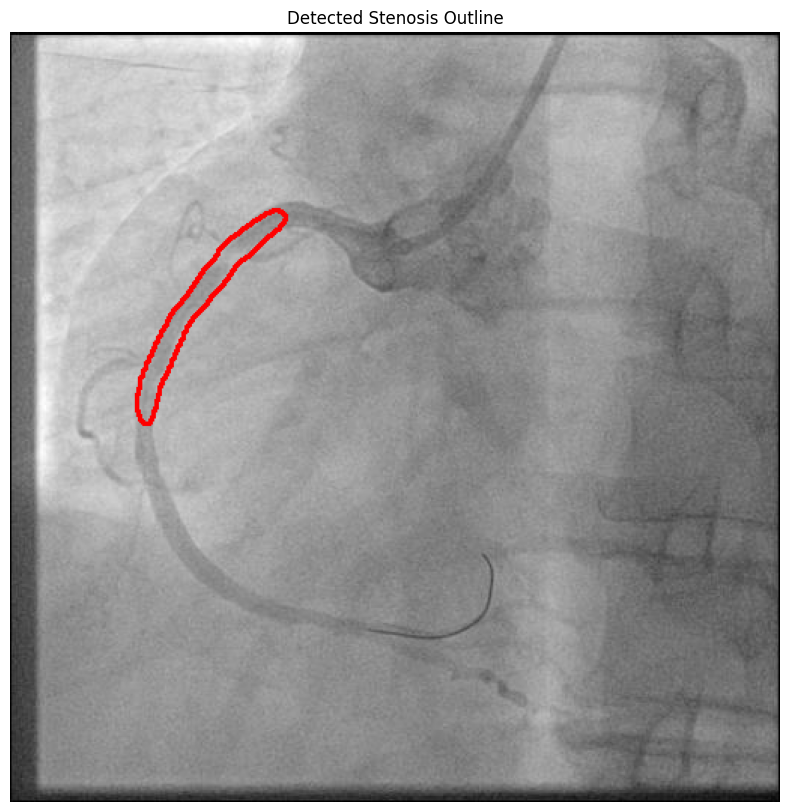

Saved outline: /content/drive/MyDrive/REDDY/outputs/stenosis_detected_outline.png
Saved predicted mask: /content/drive/MyDrive/REDDY/outputs/stenosis_predicted_mask.png


In [ ]:
# ============================================================
# COMPLETE STENOSIS OUTLINE DETECTION
# Grayscale angiogram + predicted stenosis outline in red
# ============================================================

import os
import json
import ast
import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt
import segmentation_models_pytorch as smp

from PIL import Image
from torchvision import transforms
from google.colab import drive

# -------------------------
# 1. Mount Google Drive
# -------------------------
drive.mount("/content/drive")

# -------------------------
# 2. Paths and configuration
# -------------------------
ROOT = "/content/drive/MyDrive/REDDY"

CHECKPOINT_PATH = os.path.join(
    ROOT, "models", "arcade_stenosis_unet_best.pth"
)

VAL_IMAGE_DIR = os.path.join(
    ROOT, "dataset", "data", "stenosis", "val", "images"
)

VAL_ANNOTATION_PATH = os.path.join(
    ROOT, "dataset", "data", "stenosis", "val", "annotations", "val.json"
)

OUTPUT_DIR = os.path.join(ROOT, "outputs")
os.makedirs(OUTPUT_DIR, exist_ok=True)

IMAGE_SIZE = 256
THRESHOLD = 0.5

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# -------------------------
# 3. Load trained model
# -------------------------
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=3,
    classes=1
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

print("Loaded checkpoint from epoch:", checkpoint.get("epoch", "unknown"))

# -------------------------
# 4. Load validation data
# -------------------------
with open(VAL_ANNOTATION_PATH, "r") as f:
    data = json.load(f)

# Find a validation image with stenosis annotations
stenosis_annotations = [
    ann for ann in data["annotations"]
    if ann["category_id"] == 26
]

if not stenosis_annotations:
    raise ValueError("No stenosis annotations found in validation data.")

selected_ann = stenosis_annotations[0]

image_info = next(
    img for img in data["images"]
    if img["id"] == selected_ann["image_id"]
)

image_path = os.path.join(VAL_IMAGE_DIR, image_info["file_name"])

if not os.path.exists(image_path):
    raise FileNotFoundError(f"Image not found: {image_path}")

image = Image.open(image_path).convert("RGB")
original_width, original_height = image.size

print("Validation image:", image_info["file_name"])

# -------------------------
# 5. Preprocess image
# -------------------------
mean = checkpoint.get("mean", [0.485, 0.456, 0.406])
std = checkpoint.get("std", [0.229, 0.224, 0.225])

transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

input_tensor = transform(image).unsqueeze(0).to(device)

# -------------------------
# 6. Predict stenosis mask
# -------------------------
with torch.no_grad():
    logits = model(input_tensor)
    probability = torch.sigmoid(logits)[0, 0].cpu().numpy()

# Resize probability map to original image size
probability = cv2.resize(
    probability,
    (original_width, original_height),
    interpolation=cv2.INTER_LINEAR
)

pred_mask = (probability >= THRESHOLD).astype(np.uint8)

# -------------------------
# 7. Create grayscale output
# -------------------------
gray = np.array(image.convert("L"))
output = cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)

# -------------------------
# 8. Extract and draw predicted outline
# -------------------------
contours, _ = cv2.findContours(
    pred_mask,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

# Red outline (BGR color)
cv2.drawContours(
    output,
    contours,
    contourIdx=-1,
    color=(0, 0, 255),
    thickness=2
)

# -------------------------
# 9. Display results
# -------------------------
plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
plt.title("Detected Stenosis Outline")
plt.axis("off")
plt.show()

# -------------------------
# 10. Save output
# -------------------------
output_path = os.path.join(
    OUTPUT_DIR, "stenosis_detected_outline.png"
)

cv2.imwrite(output_path, output)

# Also save the binary predicted mask
mask_path = os.path.join(
    OUTPUT_DIR, "stenosis_predicted_mask.png"
)

cv2.imwrite(mask_path, pred_mask * 255)

print("Saved outline:", output_path)
print("Saved predicted mask:", mask_path)

In [ ]:
import os
import json
import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image

# Paths
VAL_IMAGE_DIR = "/content/drive/MyDrive/REDDY/dataset/data/stenosis/val/images"
VAL_ANNOTATION_PATH = "/content/drive/MyDrive/REDDY/dataset/data/stenosis/val/annotations/val.json"
OUTPUT_DIR = "/content/drive/MyDrive/REDDY/outputs/validation_outlines"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Load validation annotations
with open(VAL_ANNOTATION_PATH, "r") as f:
    data = json.load(f)

# Unique image IDs containing stenosis annotations
image_ids = list(dict.fromkeys(
    ann["image_id"] for ann in data["annotations"]
    if ann["category_id"] == 26
))[:5]

for image_id in image_ids:
    info = next(img for img in data["images"] if img["id"] == image_id)
    image_path = os.path.join(VAL_IMAGE_DIR, info["file_name"])

    image = Image.open(image_path).convert("RGB")
    w, h = image.size

    # Preprocess and predict
    input_tensor = transform(image).unsqueeze(0).to(device)
    with torch.no_grad():
        probability = torch.sigmoid(model(input_tensor))[0, 0].cpu().numpy()

    probability = cv2.resize(probability, (w, h), interpolation=cv2.INTER_LINEAR)
    pred_mask = (probability >= THRESHOLD).astype(np.uint8)

    # Grayscale output
    gray = np.array(image.convert("L"))
    output = cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)

    # Draw predicted contour in red
    contours, _ = cv2.findContours(
        pred_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    cv2.drawContours(output, contours, -1, (0, 0, 255), 2)

    save_path = os.path.join(
        OUTPUT_DIR, os.path.splitext(info["file_name"])[0] + "_outline.png"
    )
    cv2.imwrite(save_path, output)
    print("Saved:", save_path)

print("Validation outline images saved to:", OUTPUT_DIR)

Saved: /content/drive/MyDrive/REDDY/outputs/validation_outlines/1_outline.png
Saved: /content/drive/MyDrive/REDDY/outputs/validation_outlines/10_outline.png
Saved: /content/drive/MyDrive/REDDY/outputs/validation_outlines/100_outline.png
Saved: /content/drive/MyDrive/REDDY/outputs/validation_outlines/101_outline.png
Saved: /content/drive/MyDrive/REDDY/outputs/validation_outlines/102_outline.png
Validation outline images saved to: /content/drive/MyDrive/REDDY/outputs/validation_outlines


In [ ]:
import os

folder = "/content/drive/MyDrive/REDDY/outputs/validation_outlines"
print(os.listdir(folder))

['1_outline.png', '10_outline.png', '100_outline.png', '101_outline.png', '102_outline.png']


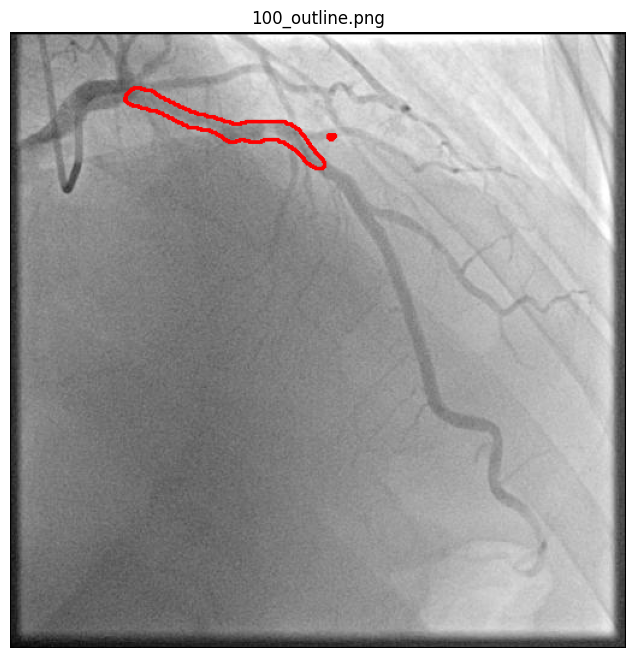

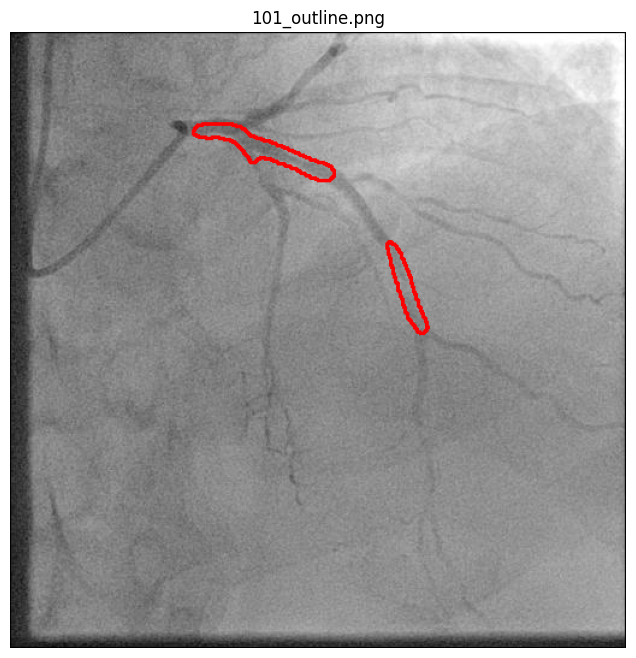

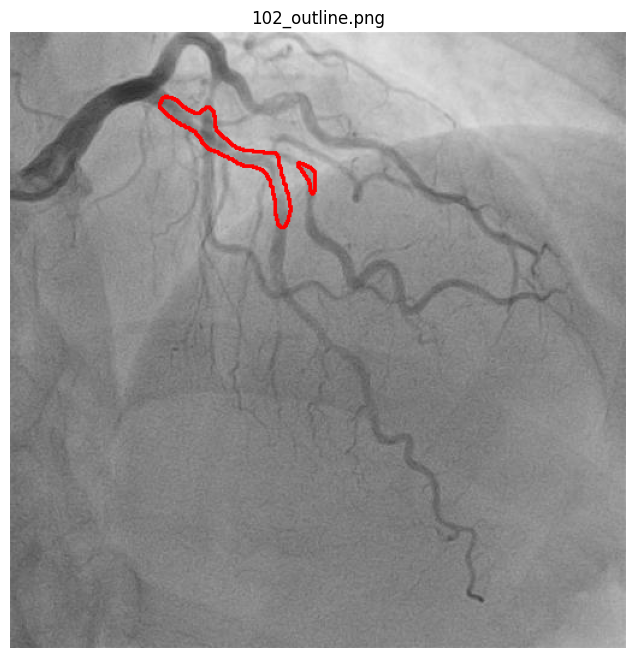

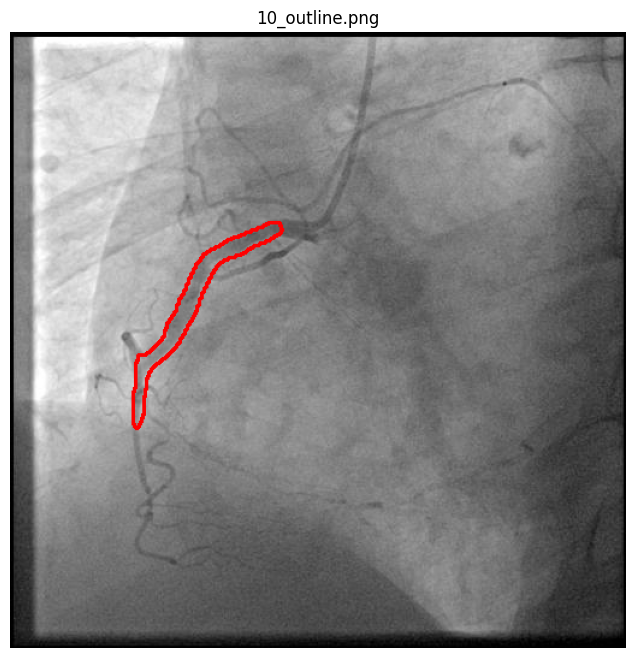

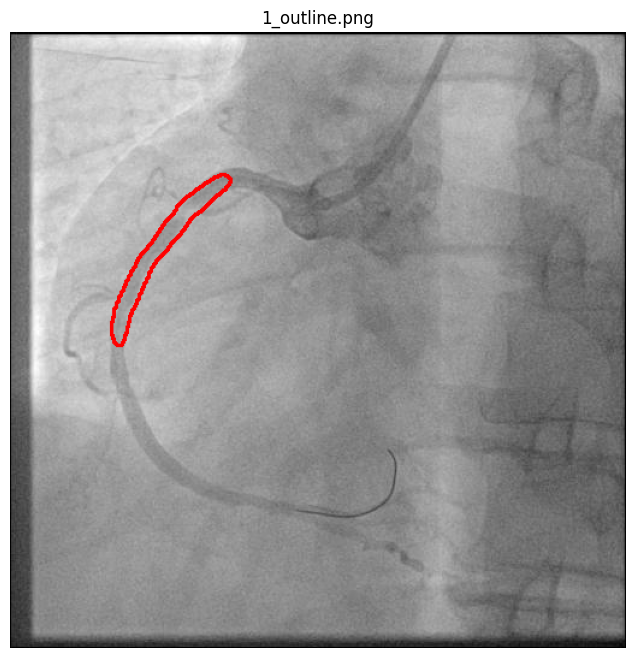

In [ ]:
from PIL import Image
import os
import matplotlib.pyplot as plt

folder = "/content/drive/MyDrive/REDDY/outputs/validation_outlines"

for filename in sorted(os.listdir(folder)):
    if filename.endswith(".png"):
        img = Image.open(os.path.join(folder, filename))
        plt.figure(figsize=(8, 8))
        plt.imshow(img)
        plt.title(filename)
        plt.axis("off")
        plt.show()

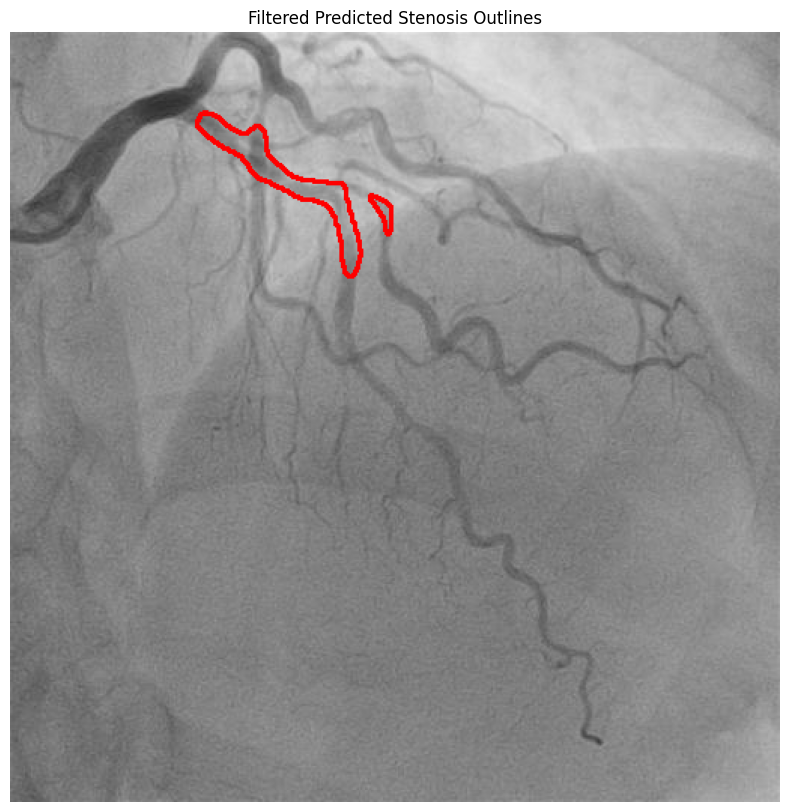

In [ ]:
# Remove small disconnected predicted regions
num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(
    pred_mask.astype(np.uint8),
    connectivity=8
)

MIN_AREA = 100  # Tune based on image resolution

clean_mask = np.zeros_like(pred_mask, dtype=np.uint8)

for label in range(1, num_labels):
    area = stats[label, cv2.CC_STAT_AREA]
    if area >= MIN_AREA:
        clean_mask[labels == label] = 1

# Draw only filtered predicted outlines on grayscale angiogram
gray = np.array(image.convert("L"))
output = cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)

contours, _ = cv2.findContours(
    clean_mask,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

cv2.drawContours(output, contours, -1, (0, 0, 255), 2)

plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
plt.title("Filtered Predicted Stenosis Outlines")
plt.axis("off")
plt.show()

In [ ]:
import os
import json
import ast
import cv2
import numpy as np
import torch
from PIL import Image
from tqdm.auto import tqdm

VAL_IMAGE_DIR = "/content/drive/MyDrive/REDDY/dataset/data/stenosis/val/images"
VAL_ANNOTATION_PATH = "/content/drive/MyDrive/REDDY/dataset/data/stenosis/val/annotations/val.json"

THRESHOLDS = [0.3, 0.4, 0.5, 0.6]

with open(VAL_ANNOTATION_PATH, "r") as f:
    data = json.load(f)

images = data["images"]
annotations = data["annotations"]

# Only images with stenosis annotations
valid_image_ids = set(
    ann["image_id"] for ann in annotations
    if ann["category_id"] == 26
)
images = [img for img in images if img["id"] in valid_image_ids]

results = {t: {"dice": [], "iou": []} for t in THRESHOLDS}

def build_gt_mask(image_info):
    gt = np.zeros(
        (image_info["height"], image_info["width"]),
        dtype=np.uint8
    )

    for ann in annotations:
        if ann["image_id"] != image_info["id"] or ann["category_id"] != 26:
            continue

        seg = ann["segmentation"]
        if isinstance(seg, str):
            seg = ast.literal_eval(seg)

        for polygon in seg:
            points = np.array(polygon, dtype=np.int32).reshape(-1, 2)
            cv2.fillPoly(gt, [points], 1)

    return gt

model.eval()

for info in tqdm(images):
    image_path = os.path.join(VAL_IMAGE_DIR, info["file_name"])
    image = Image.open(image_path).convert("RGB")

    input_tensor = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        prob = torch.sigmoid(model(input_tensor))[0, 0].cpu().numpy()

    prob = cv2.resize(
        prob,
        (info["width"], info["height"]),
        interpolation=cv2.INTER_LINEAR
    )

    gt = build_gt_mask(info)

    for threshold in THRESHOLDS:
        pred = (prob >= threshold).astype(np.uint8)

        intersection = np.logical_and(pred, gt).sum()
        dice = (2 * intersection) / (pred.sum() + gt.sum() + 1e-8)
        iou = intersection / (np.logical_or(pred, gt).sum() + 1e-8)

        results[threshold]["dice"].append(dice)
        results[threshold]["iou"].append(iou)

print("\nValidation results:")
for threshold in THRESHOLDS:
    mean_dice = np.mean(results[threshold]["dice"])
    mean_iou = np.mean(results[threshold]["iou"])
    print(f"Threshold {threshold:.1f} | Mean Dice: {mean_dice:.4f} | Mean IoU: {mean_iou:.4f}")

  0%|          | 0/200 [00:00<?, ?it/s]


Validation results:
Threshold 0.3 | Mean Dice: 0.4926 | Mean IoU: 0.3598
Threshold 0.4 | Mean Dice: 0.4895 | Mean IoU: 0.3573
Threshold 0.5 | Mean Dice: 0.4860 | Mean IoU: 0.3541
Threshold 0.6 | Mean Dice: 0.4817 | Mean IoU: 0.3502


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using device: cpu
Stenosis segmentation model loaded.


Saving 1.png to 1.png
Uploaded image: 1.png
Image dimensions: (512, 512)


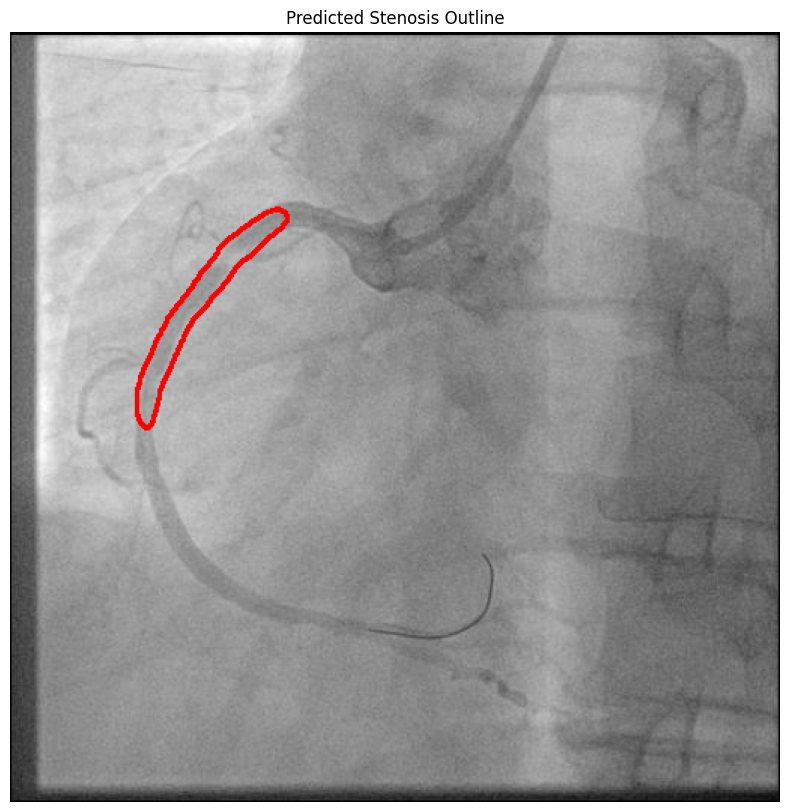

Outline saved: /content/drive/MyDrive/REDDY/outputs/inference/1_stenosis_outline.png
Binary mask saved: /content/drive/MyDrive/REDDY/outputs/inference/1_stenosis_mask.png
Prediction threshold: 0.3


In [ ]:
# ============================================================
# NEW ANGIOGRAM: STENOSIS OUTLINE INFERENCE
# ============================================================

import os
import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt
import segmentation_models_pytorch as smp

from PIL import Image
from torchvision import transforms
from google.colab import drive, files

# -------------------------
# 1. Mount Google Drive
# -------------------------
drive.mount("/content/drive")

# -------------------------
# 2. Configuration
# -------------------------
ROOT = "/content/drive/MyDrive/REDDY"
CHECKPOINT_PATH = os.path.join(
    ROOT, "models", "arcade_stenosis_unet_best.pth"
)

OUTPUT_DIR = os.path.join(ROOT, "outputs", "inference")
os.makedirs(OUTPUT_DIR, exist_ok=True)

IMAGE_SIZE = 256
THRESHOLD = 0.3

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# -------------------------
# 3. Load trained model
# -------------------------
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=3,
    classes=1
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

mean = checkpoint.get("mean", [0.485, 0.456, 0.406])
std = checkpoint.get("std", [0.229, 0.224, 0.225])

transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

print("Stenosis segmentation model loaded.")

# -------------------------
# 4. Upload angiogram
# -------------------------
uploaded = files.upload()

if not uploaded:
    raise ValueError("No image uploaded.")

uploaded_filename = next(iter(uploaded.keys()))
image = Image.open(uploaded_filename).convert("RGB")

original_width, original_height = image.size
print("Uploaded image:", uploaded_filename)
print("Image dimensions:", image.size)

# -------------------------
# 5. Predict stenosis mask
# -------------------------
input_tensor = transform(image).unsqueeze(0).to(device)

with torch.no_grad():
    logits = model(input_tensor)
    probability = torch.sigmoid(logits)[0, 0].cpu().numpy()

probability = cv2.resize(
    probability,
    (original_width, original_height),
    interpolation=cv2.INTER_LINEAR
)

pred_mask = (probability >= THRESHOLD).astype(np.uint8)

# -------------------------
# 6. Optional small-region filtering
# -------------------------
num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(
    pred_mask,
    connectivity=8
)

clean_mask = np.zeros_like(pred_mask, dtype=np.uint8)
MIN_AREA = 100

for label in range(1, num_labels):
    if stats[label, cv2.CC_STAT_AREA] >= MIN_AREA:
        clean_mask[labels == label] = 1

# -------------------------
# 7. Draw outline on grayscale
# -------------------------
gray = np.array(image.convert("L"))
output = cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)

contours, _ = cv2.findContours(
    clean_mask,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

cv2.drawContours(
    output,
    contours,
    -1,
    (0, 0, 255),  # Red in BGR
    2
)

# -------------------------
# 8. Display results
# -------------------------
plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
plt.title("Predicted Stenosis Outline")
plt.axis("off")
plt.show()

# -------------------------
# 9. Save outputs
# -------------------------
base_name = os.path.splitext(os.path.basename(uploaded_filename))[0]

outline_path = os.path.join(
    OUTPUT_DIR, f"{base_name}_stenosis_outline.png"
)

mask_path = os.path.join(
    OUTPUT_DIR, f"{base_name}_stenosis_mask.png"
)

cv2.imwrite(outline_path, output)
cv2.imwrite(mask_path, clean_mask * 255)

print("Outline saved:", outline_path)
print("Binary mask saved:", mask_path)
print("Prediction threshold:", THRESHOLD)

In [ ]:
import os

root = "/content/drive/MyDrive/REDDY"

for folder, _, filenames in os.walk(root):
    for filename in filenames:
        if "stenosis_outline" in filename:
            print(os.path.join(folder, filename))

Mounted at /content/drive


Saving 3.png to 3.png


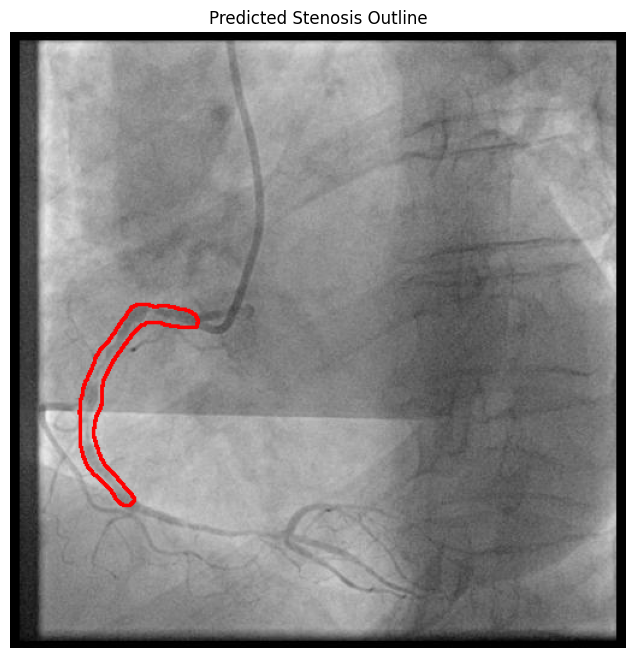

Outline saved: /content/drive/MyDrive/REDDY/outputs/inference/3_stenosis_outline.png
Mask saved: /content/drive/MyDrive/REDDY/outputs/inference/3_stenosis_mask.png
Outline file exists: True


In [ ]:
import os
import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt
import segmentation_models_pytorch as smp

from PIL import Image
from torchvision import transforms
from google.colab import drive, files

# Mount Drive
drive.mount("/content/drive")

# Configuration
ROOT = "/content/drive/MyDrive/REDDY"
CHECKPOINT_PATH = os.path.join(ROOT, "models", "arcade_stenosis_unet_best.pth")
OUTPUT_DIR = os.path.join(ROOT, "outputs", "inference")
os.makedirs(OUTPUT_DIR, exist_ok=True)

IMAGE_SIZE = 256
THRESHOLD = 0.3
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load checkpoint and model
checkpoint = torch.load(
    CHECKPOINT_PATH, map_location=device, weights_only=False
)

model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=3,
    classes=1
)
model.load_state_dict(checkpoint["model_state_dict"])
model.to(device).eval()

# Define preprocessing transform
mean = checkpoint.get("mean", [0.485, 0.456, 0.406])
std = checkpoint.get("std", [0.229, 0.224, 0.225])

transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

# Upload angiogram
uploaded = files.upload()
filename = next(iter(uploaded))
image = Image.open(filename).convert("RGB")
w, h = image.size

# Predict
input_tensor = transform(image).unsqueeze(0).to(device)

with torch.no_grad():
    probability = torch.sigmoid(model(input_tensor))[0, 0].cpu().numpy()

probability = cv2.resize(probability, (w, h), interpolation=cv2.INTER_LINEAR)
mask = (probability >= THRESHOLD).astype(np.uint8)

# Draw predicted outline on grayscale angiogram
gray = np.array(image.convert("L"))
output = cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)

contours, _ = cv2.findContours(
    mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)
cv2.drawContours(output, contours, -1, (0, 0, 255), 2)

# Display
plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
plt.title("Predicted Stenosis Outline")
plt.axis("off")
plt.show()

# Save and verify
base_name = os.path.splitext(os.path.basename(filename))[0]
outline_path = os.path.join(OUTPUT_DIR, f"{base_name}_stenosis_outline.png")
mask_path = os.path.join(OUTPUT_DIR, f"{base_name}_stenosis_mask.png")

cv2.imwrite(outline_path, output)
cv2.imwrite(mask_path, mask * 255)

print("Outline saved:", outline_path)
print("Mask saved:", mask_path)
print("Outline file exists:", os.path.exists(outline_path))

In [ ]:
%pip install -q segmentation-models-pytorch

In [ ]:
%pip install -q flask flask-cors torch torchvision segmentation-models-pytorch pillow opencv-python-headless

In [ ]:
from google.colab import drive
import os

drive.mount("/content/drive")

MODEL_PATH = "/content/drive/MyDrive/REDDY/models/arcade_stenosis_unet_best.pth"

assert os.path.exists(MODEL_PATH), f"Checkpoint not found: {MODEL_PATH}"
print("Model checkpoint found.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model checkpoint found.


In [ ]:
%%writefile /content/app.py
from flask import Flask, request, jsonify, send_from_directory
from flask_cors import CORS
from werkzeug.utils import secure_filename

import os
import uuid
import time
import cv2
import numpy as np
import torch
import segmentation_models_pytorch as smp

from datetime import datetime
from PIL import Image
from torchvision import transforms

app = Flask(__name__)
CORS(app)

BASE_DIR = "/content"
UPLOAD_FOLDER = os.path.join(BASE_DIR, "uploads")
OUTPUTS_FOLDER = os.path.join(BASE_DIR, "outputs")
MODEL_PATH = "/content/drive/MyDrive/REDDY/models/arcade_stenosis_unet_best.pth"

IMAGE_SIZE = 256
THRESHOLD = 0.3
MIN_AREA = 100
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

os.makedirs(UPLOAD_FOLDER, exist_ok=True)
os.makedirs(OUTPUTS_FOLDER, exist_ok=True)

checkpoint = torch.load(MODEL_PATH, map_location=DEVICE, weights_only=False)

model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=3,
    classes=1
)
model.load_state_dict(checkpoint["model_state_dict"])
model.to(DEVICE).eval()

mean = checkpoint.get("mean", [0.485, 0.456, 0.406])
std = checkpoint.get("std", [0.229, 0.224, 0.225])

preprocess = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

ALLOWED_EXTENSIONS = {"png", "jpg", "jpeg"}

def allowed_file(filename):
    return "." in filename and filename.rsplit(".", 1)[1].lower() in ALLOWED_EXTENSIONS

def run_inference(image):
    width, height = image.size
    tensor = preprocess(image).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        prob = torch.sigmoid(model(tensor))[0, 0].cpu().numpy()

    prob = cv2.resize(prob, (width, height), interpolation=cv2.INTER_LINEAR)
    mask = (prob >= THRESHOLD).astype(np.uint8)

    count, labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    clean_mask = np.zeros_like(mask)

    for label in range(1, count):
        if stats[label, cv2.CC_STAT_AREA] >= MIN_AREA:
            clean_mask[labels == label] = 1

    gray = np.array(image.convert("L"))
    outline = cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)

    contours, _ = cv2.findContours(clean_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(outline, contours, -1, (0, 0, 255), 2)

    return outline, clean_mask

@app.route("/api/health", methods=["GET"])
def health():
    return jsonify({
        "status": "healthy",
        "model_loaded": True,
        "device": str(DEVICE),
        "timestamp": datetime.now().isoformat()
    })

@app.route("/api/analyze", methods=["POST"])
def analyze():
    if "file" not in request.files:
        return jsonify({"error": "No file provided"}), 400

    file = request.files["file"]
    if not file.filename:
        return jsonify({"error": "No file selected"}), 400

    if not allowed_file(file.filename):
        return jsonify({"error": "Upload PNG, JPG, or JPEG"}), 400

    start = time.time()

    try:
        filename = f"{uuid.uuid4()}_{secure_filename(file.filename)}"
        filepath = os.path.join(UPLOAD_FOLDER, filename)
        file.save(filepath)

        image = Image.open(filepath).convert("RGB")
        outline, mask = run_inference(image)

        base = os.path.splitext(filename)[0]
        outline_name = f"{base}_segmentation.png"
        mask_name = f"{base}_mask.png"

        cv2.imwrite(os.path.join(OUTPUTS_FOLDER, outline_name), outline)
        cv2.imwrite(os.path.join(OUTPUTS_FOLDER, mask_name), mask * 255)

        return jsonify({
            "filename": filename,
            "prediction": "Experimental stenosis segmentation",
            "stenosis_percentage": None,
            "severity": None,
            "confidence": None,
            "processing_time": round(time.time() - start, 3),
            "segmentation_image_url": f"/outputs/{outline_name}",
            "mask_image_url": f"/outputs/{mask_name}",
            "gradcam_image_url": None,
            "threshold": THRESHOLD,
            "notice": "Experimental output; not a clinical diagnosis."
        })

    except Exception:
        app.logger.exception("Analysis failed")
        return jsonify({"error": "Image analysis failed"}), 500

@app.route("/outputs/<path:filename>")
def serve_output(filename):
    return send_from_directory(OUTPUTS_FOLDER, filename)

if __name__ == "__main__":
    print("Flask backend running on port 5000")
    app.run(host="0.0.0.0", port=5000)

Writing /content/app.py


In [ ]:
!python /content/app.py


In [ ]:
!cloudflared tunnel --url http://127.0.0.1:5000